# Vanguard · ¿El nuevo proceso online funciona mejor?

**Test A/B del 15 de marzo al 20 de junio de 2017** · Proyecto 2 · Ironhack Data Analytics · João Miguel Pais y Emanuel

## Resumen

Vanguard probó un nuevo diseño de su proceso online (5 pasos: `start` → `step_1` → `step_2` → `step_3` → `confirm`) con dos grupos de clientes: **Control** (diseño antiguo) y **Test** (diseño nuevo). La pregunta es si el nuevo diseño hace que más clientes terminen el proceso, y lo suficiente como para pagar lo que cuesta.

| Pregunta | Respuesta | Dónde |
|---|---|---|
| ¿El Test completa más? | Sí: **69,3 % frente a 65,6 %** (+3,7 puntos), p < 0,0001. Es real, pero el efecto es pequeño (V de Cramér 0,04) | Partes 3 y 4 |
| ¿Supera el umbral del 5 % que justifica el coste? | **No se puede afirmar.** Con 5 puntos, claramente no (p = 0,999); con un 5 % relativo, la mejora observada es del 5,7 %, pero no es significativa (p ≈ 0,15) | Parte 4 |
| ¿Tiene algún coste el nuevo diseño? | Sí, **más errores**: el 33,4 % de sus clientes vuelve atrás alguna vez, frente al 25,8 %, sobre todo desde `step_1` y en los mayores de 45 | Partes 3 y 4 |
| ¿El experimento estaba bien hecho? | Los dos grupos tienen el mismo perfil, pero el reparto fue 53/47 y **cambió el 8 de mayo**; desde entonces la ventaja (+1,7) deja de ser significativa | Partes 2 y 4 |
| ¿Qué recomendamos? | No implantarlo tal cual: **corregir `step_1`**, confirmar con Vanguard cómo se mide el 5 % y repetir el test con un reparto estable | Conclusiones |

> **Resumo (português).** A Vanguard testou um novo design do processo online com dois grupos: Control (antigo) e Test (novo). O Test conclui mais (69,3 % contra 65,6 %, +3,7 pontos, p < 0,0001), mas o efeito é pequeno e não se pode afirmar que ultrapassa o limiar de 5 % que justifica o custo (com 5 pontos claramente não; com 5 % relativos a melhoria observada é de 5,7 %, mas não é significativa). O novo design tem mais erros (33,4 % contra 25,8 % de clientes com alguma volta atrás), sobretudo a partir do `step_1` e nos maiores de 45. Os grupos têm o mesmo perfil, mas a repartição foi 53/47 e mudou a 8 de Maio. Recomendação: corrigir o `step_1`, confirmar como se mede o limiar e repetir o teste com uma repartição estável.

## Índice

| Parte | Qué responde | Días del curso |
|---|---|---|
| [Parte 1 · Exploración y limpieza](#parte-1) | Qué datos hay, qué problemas tienen, cómo se limpian y quiénes son los clientes | Semana 5, días 1 y 2 |
| [Parte 2 · Comportamiento](#parte-2) | Si la ventaja del Test aparece en todos los tipos de cliente y si el reparto fue igual en el tiempo | Semana 5, días 1 y 2 |
| [Parte 3 · KPI](#parte-3) | Tasa de finalización, tiempo en cada paso, tasa de errores, tiempo total y recorridos | Semana 5, día 3 |
| [Parte 4 · Prueba de hipótesis](#parte-4) | 4A: la base de Emanuel (H1, H2, la edad de los grupos y una primera evaluación). 4B: lo que añadimos y por qué (H1 a H9 y evaluación del experimento) | Semana 5, días 4 y 5 |
| [Conclusiones](#conclusiones) | Resultados, recomendaciones, limitaciones y datos que faltan | |

Fuera de este notebook: el Tableau de Emmanuel (enlace y capturas en el README y en `tableau/capturas/`) usa las tablas limpias de `data/clean/`.

> **Índice (português).** Parte 1: exploração e limpeza. Parte 2: comportamento. Parte 3: KPI. Parte 4: prova de hipóteses (4A, a base do Emanuel; 4B, o que acrescentámos e porquê). No fim, as conclusões. Fora deste notebook: o Tableau do Emmanuel (link e capturas no README e em `tableau/capturas/`, com as tabelas limpas de `data/clean/`).

## Cómo leer este notebook

- Antes de cada celda de código hay un bloque **Cómo funciona**: los pasos de la celda, por qué se hace así, las herramientas que usa y **dónde se vieron en clase**. Debajo va lo mismo en portugués.
- Después de cada celda, **➜ Qué nos llevamos para el proyecto**: lo que dice el resultado.
- Al final de cada sección, **Por qué lo hicimos así y preguntas posibles**, con las respuestas plegadas (se contesta en voz alta y después se abre).
- Las funciones (`limpieza.…`, `eda.…`, `kpis.…`, `contrastes.…`) están en `src/` y los valores fijos (rutas, tramos, umbrales) en `config.py`. La guía de abajo dice qué hace cada una.
- Se ejecuta de arriba abajo con *Restart* y *Run All* (unos 2 minutos). La Parte 1 guarda los datos limpios en `data/clean/` y las Partes 2 a 4 los leen de ahí.

- **Antes de ejecutar:** si el proyecto viene en un zip, primero hay que **descomprimirlo** (botón derecho → «Extraer todo») y abrir en VS Code la **carpeta** `vanguard-ab-test`. Si se abre el notebook con doble clic dentro del zip, Windows solo saca ese archivo a una carpeta temporal, sin `config.py` ni `src/`, y la celda de preparación da `ModuleNotFoundError: No module named 'config'`.

> **Antes de correr (português):** se o projecto vem num zip, primeiro é preciso **descomprimi-lo** («Extrair tudo») e abrir no VS Code a **pasta** `vanguard-ab-test`. Aberto com duplo clique dentro do zip, o Windows só tira esse ficheiro para uma pasta temporária, sem `config.py` nem `src/`, e a preparação dá `ModuleNotFoundError: config`.

> **Como ler este notebook.** Antes de cada célula de código há um bloco **Cómo funciona** (passos, porquê assim, ferramentas e onde foram dadas nas aulas); depois, **Qué nos llevamos** (o que o resultado diz); no fim de cada secção, **Por qué lo hicimos así y preguntas posibles**, com as respostas escondidas. As funções estão em `src/` e os valores fixos no `config.py`. Corre-se de cima para baixo com *Restart* e *Run All* (uns 2 minutos).

## Guía rápida: funciones y herramientas de este notebook (Partes 1 a 4)

Para entender el código sin abrir los `.py`:

- **Nuestras funciones:** qué hace cada una, por qué la hicimos y qué herramientas usa por dentro. El código de cada una está en `src/` con un comentario al principio (docstring).
- **Herramientas de clase:** las de Python, pandas, seaborn y scipy que aparecen en este notebook y en esas funciones, con la clase en la que se vieron. Lo poco que no se vio en clase se avisa en el bloque «Cómo funciona» de la celda que lo usa.
- **Al final de cada sección** hay un bloque «Por qué lo hicimos así y preguntas posibles», con las respuestas plegadas.

### Nuestras funciones (carpeta `src/`)

| Función | Archivo | Qué hace | Por qué la hicimos | Usa por dentro |
|---|---|---|---|---|
| `cargar_datos` | `src/limpieza.py` | Lee los tres archivos originales y apila las dos partes de la web en una sola tabla. | Los nombres de archivo vienen de `config.py`: si cambian, no se toca el código. | `read_csv`, comprensión de listas, `pd.concat` |
| `resumen_calidad` | `src/limpieza.py` | Hace una tabla con el tipo, los nulos y los valores distintos de cada columna. | Junta en una vista lo que dan `info()`, `isna().sum()` y `nunique()`, y sirve para las tres tablas. | `dtypes`, `isna`, `sum`, `nunique`, `pd.DataFrame` |
| `limpiar_texto` | `src/limpieza.py` | Quita espacios sobrantes en todas las columnas de texto y dice cuántas celdas cambió. | Aportación de Emanuel: «Test » con espacio sería otro grupo y los `merge` fallarían. | `select_dtypes`, `for`, `.str.strip`, `copy` |
| `limpiar_experimento` | `src/limpieza.py` | Renombra `Variation` a `grupo`, quita a los clientes sin grupo y comprueba que solo quedan Test y Control. | Quien no tiene grupo no participó en el test y no se puede comparar. | `rename`, `dropna`, `isin`, `assert` |
| `limpiar_demo` | `src/limpieza.py` | Quita columnas repetidas y filas vacías, renombra, traduce el género y pasa a entero las cuentas. | Deja el perfil listo para describir y para Tableau, sin inventar datos. | `drop`, `dropna(how="all")`, `rename`, `map`, `astype`, `assert` |
| `unir_clientes` | `src/limpieza.py` | Une el perfil con el grupo de cada cliente (solo los que están en las dos tablas). | `merge` interior: un cliente sin perfil o sin grupo no sirve para el análisis. | `merge`, `assert` |
| `limpiar_web` | `src/limpieza.py` | Quita clics repetidos, deja solo clientes del test, convierte la fecha, numera los pasos y ordena. | Sin fecha no se mide el tiempo y sin número de paso no se detecta cuándo alguien vuelve atrás. | `drop_duplicates`, `isin`, `pd.to_datetime`, `map`, `sort_values` |
| `tramo` | `src/eda.py` | Devuelve el tramo de un valor (edad, antigüedad, saldo) comparándolo con unos límites. | Con `if` se entiende paso a paso y los límites se cambian en `config.py`. | `def`, `for`, `if`, `range`, `pd.isna` |
| `histograma_y_caja` | `src/eda.py` | Dibuja un histograma y un diagrama de caja de la misma variable, uno encima del otro. | La lección de EDA univariante describe las numéricas con los dos: forma y valores atípicos. | `plt.subplots`, `sns.histplot`, `sns.boxplot`, `median` |
| `barras_categoria` | `src/eda.py` | Barras con el % de cada categoría. | Las categóricas se describen con frecuencias y barras (lección de EDA univariante). | `value_counts(normalize=True)`, `sns.barplot` |
| `comportamiento_por_cliente` | `src/eda.py` | Pasa de una fila por clic a una fila por cliente: visitas, clics, dispositivos, paso más alto y si completó. | La unidad del test es el cliente: todas las tasas y contrastes se hacen por cliente. | `groupby`, `nunique`, `count`, `max`, `unique`, `apply`, `lambda`, `pd.DataFrame` |
| `ids_compartidos` | `src/eda.py` | Cuenta los dispositivos o visitas que aparecen con más de un cliente. | Si hay ids compartidos, no se puede analizar por visita sin mezclar personas. | `groupby`, `nunique`, `sum` |
| `tasa_por_categoria` | `src/eda.py` | Para cada categoría: % que completa en Control y en Test, la diferencia y el número de clientes. | Es la tabla que se repite en toda la Parte 2; con una función, todas salen iguales. | `groupby`, `mean`, `unstack`, `count`, `loc`, `round` |
| `barras_por_grupo` | `src/eda.py` | Barras de Control y Test una al lado de la otra para cada categoría. | Compara los dos grupos de un vistazo; `melt` deja la tabla como la necesita `sns.barplot` con `hue`. | `reset_index`, `melt`, `sns.barplot` (`hue`, `palette`) |
| `barras_simples` | `src/eda.py` | Barras de una serie ya calculada (clics por mes, día u hora). | Mismo estilo para todos los gráficos de uso en el tiempo. | `sns.barplot`, `plt.title` |
| `preparar_pasos` | `src/kpis.py` | Añade a cada clic el grupo, el tiempo hasta el clic siguiente, el paso anterior y si es un error o una repetición. | Todos los KPI salen de aquí. Se hace con un bucle `for` mirando la fila anterior y la siguiente porque `shift` no se vio en clase. | `merge`, `sort_values`, `list`, `for`, `range`, `if`, `total_seconds` |
| `embudo` | `src/kpis.py` | % de clientes de cada grupo que llega al menos una vez a cada paso. | El último paso del embudo es la tasa de finalización (KPI 1) y los anteriores dicen dónde aparece la ventaja. | `groupby`, `nunique`, `unstack`, `value_counts`, `loc`, `round` |
| `tiempo_por_paso` | `src/kpis.py` | Mediana (o media) de segundos en cada paso, sin `confirm` y sin pausas de más de 30 minutos. | La mediana no la mueven los tiempos larguísimos; el límite de 30 minutos está en `config.py`. | filtros, `groupby`, `agg("median")`, `unstack` |
| `tasa_errores` | `src/kpis.py` | Errores / pasos (fórmula del enunciado), repeticiones y % de clientes con algún error, por grupo. | Da el KPI 3 por pasos y también por clientes, que es la unidad del contraste H5. | `groupby`, `size`, `sum`, `any`, `mean`, `pd.DataFrame` |
| `errores_por_destino` | `src/kpis.py` | Cuenta a qué paso vuelven los clientes cuando van hacia atrás. | Dice qué pantalla confunde: es lo que el equipo de diseño puede arreglar. | filtros, `pd.crosstab`, comprensión de listas, `loc` |
| `tiempo_total` | `src/kpis.py` | Minutos desde el primer `start` hasta el primer `confirm` de cada cliente que completa. | KPI extra: dice si el nuevo diseño hace terminar antes, no solo más. | `groupby`, `min`, `pd.DataFrame`, `dropna`, `.dt.total_seconds`, `drop_duplicates`, `set_index` |
| `decision` | `src/contrastes.py` | Devuelve «Se rechaza H0» si el p-valor es menor que α y «No se puede rechazar H0» si no. | Es el `if` final de la lección de contrastes, escrito una sola vez. | `def`, `if`, `return` |
| `formato_p` | `src/contrastes.py` | Escribe el p-valor con 4 decimales, o «< 0.0001» si es más pequeño. | Los p-valores de 10⁻¹⁹ no se leen bien; así todos los contrastes se escriben igual. | `if`, `round`, f-string |
| `contraste_medias` | `src/contrastes.py` | t de Welch entre el Test y una referencia (el Control, o el Control + 5 / × 1,05 para el umbral), de dos colas o de una. | Es el contraste de la lección para dos grupos independientes; con columnas de 0 y 100 da la diferencia en puntos. | `st.ttest_ind(equal_var=False)`, `if`, `round`, diccionario |
| `contraste_por_categoria` | `src/contrastes.py` | Repite `contraste_medias` dentro de cada categoría (tramo de edad, mes, periodo). | Responde «¿pasa en todos los tipos de cliente?» sin copiar el mismo código cuatro veces. | `for`, filtros, `loc`, `.append`, `pd.DataFrame` |
| `contraste_variables` | `src/contrastes.py` | Compara la media de varias variables del perfil entre Test y Control (E3). | Si el reparto fue aleatorio, los dos grupos deben tener el mismo perfil. | `for`, `loc`, `dropna`, `st.ttest_ind` |
| `contraste_chi2` | `src/contrastes.py` | Chi-cuadrado de independencia entre dos variables categóricas, con la V de Cramér. | Es el contraste de la lección de EDA bivariante para categóricas; la V de Cramér dice si la relación es grande. | `pd.crosstab`, `chi2_contingency`, `association` |

### Herramientas de clase que se usan

| Herramienta | Qué hace | Dónde se vio |
|---|---|---|
| `def`, `return`, parámetros por defecto | Crear funciones propias (todas las de `src/`). | Semana 1 · 1.3 Funciones |
| `for`, `if/else`, `range`, `enumerate` | Bucles y condiciones. | Semana 1 · 1.2 Control de flujo |
| `lambda` | Función de una línea, sobre todo dentro de `apply`. | Semana 1 · 1.5 Lambda |
| comprensión de listas / diccionarios | Crear una lista o un diccionario en una línea. | Semana 1 · 1.4 Comprensiones |
| listas y diccionarios (`.append`, `.items`) | Guardar resultados y recorrer pares clave-valor. | Semana 1 · 1.1 Estructuras de datos |
| f-strings y `round` | Escribir textos con números dentro y redondear. | Semana 1 · 1.1 (texto) y Semana 2 · 2.2 Limpieza (`round`) |
| `assert` y `is_unique` | Comprobar una condición: si no se cumple, el código se para. | Semana 4 · A3 Datos relacionales |
| `pd.read_csv`, `to_csv` | Leer y guardar tablas en CSV. | Semana 2 · 2.1 Pandas (`read_csv`) y Semana 4 · A3 (`to_csv`) |
| `head`, `shape`, `describe`, `dtypes` | Primera mirada a una tabla: filas, tamaño, resumen numérico y tipos. | Semana 2 · 2.1 Pandas |
| `pd.DataFrame`, `pd.Series` | Crear una tabla a partir de un diccionario de columnas. | Semana 2 · 2.1 Pandas |
| `loc` y filtros (`&` = y, `~` = no, `==`, `!=`, `>`) | Seleccionar filas y columnas o quedarse con las filas que cumplen una condición. | Semana 2 · 2.1 Pandas y 2.2 Limpieza |
| `value_counts`, `unique`, `nunique` | Contar cuántas veces sale cada valor y cuántos valores distintos hay. | Semana 2 · 2.1 Pandas |
| `sort_values`, `sort_index` | Ordenar una tabla por columnas o por su índice. | Semana 2 · 2.1 Pandas |
| `pd.concat` | Apilar tablas con las mismas columnas (añadir filas). | Semana 2 · 2.1 Pandas y 2.3 Combinar |
| `select_dtypes` | Elegir las columnas de un tipo (por ejemplo, las de texto). | Semana 2 · 2.1 Pandas |
| `isna`, `notna`, `dropna`, `fillna` | Detectar, quitar o rellenar valores vacíos. | Semana 2 · 2.2 Limpieza |
| `duplicated`, `drop_duplicates` | Detectar y quitar filas repetidas. | Semana 2 · 2.2 Limpieza |
| `drop`, `rename`, `astype`, `copy` | Quitar columnas, cambiar nombres, cambiar tipos y trabajar sobre una copia. | Semana 2 · 2.2 Limpieza |
| `apply`, `map` | Aplicar una función o un diccionario a cada valor de una columna. | Semana 2 · 2.2 Limpieza |
| `.str.strip` | Quitar espacios al principio y al final de un texto. | Semana 2 · 2.2 Limpieza |
| `isin`, `any`, `all` | Comprobar si un valor está en una lista; si alguno o todos cumplen algo. | Semana 2 · 2.2 Limpieza |
| `set_index`, `reset_index` | Pasar una columna a índice o el índice a columna. | Semana 2 · 2.2 Limpieza |
| `merge` | Juntar dos tablas por una columna común (aquí, `client_id`). | Semana 2 · 2.3 Combinar |
| `melt`, `unstack` | Pasar una tabla de formato ancho a largo, o los grupos de filas a columnas. | Semana 2 · 2.3 Combinar |
| `groupby`, `agg`, `size`, `count` | Separar por grupos y calcular algo en cada uno. | Semana 2 · 2.4 Agregar |
| `mean`, `median`, `std`, `min`, `max`, `sum` | Medias, medianas, dispersión, extremos y sumas. | Semana 2 · 2.1 Pandas y Semana 5 · 5.1 EDA univariante |
| `pd.to_datetime`, `parse_dates`, `.dt` | Convertir texto en fecha y sacar mes, día, hora o día de la semana. | Semana 2 · fechas (self-guided) |
| `pd.Timestamp`, `pd.to_timedelta`, `total_seconds`, `strftime` | Crear una fecha fija, sumar o restar días, pasar una duración a segundos y escribir una fecha como texto. | Semana 2 · fechas (self-guided) |
| `quantile` | Percentiles y cuartiles (por ejemplo, el percentil 99). | Semana 5 · 5.1 EDA univariante |
| `pd.crosstab` | Tabla cruzada de dos variables categóricas (con `normalize`, en %). | Semana 5 · 5.1 y 5.2 EDA |
| seaborn: `histplot`, `boxplot`, `barplot` | Histograma, diagrama de caja y barras. | Semana 2 · EDA básico (self-guided) y Semana 5 · 5.1 EDA univariante |
| matplotlib: `figure`, `subplots`, `plot`, `title`, `xlabel`, `show`... | Crear la figura, dibujar líneas y poner títulos y ejes. | Gráficos de las clases (semanas 2 y 5) |
| `Path(...).mkdir` | Crear una carpeta si no existe. | Semana 4 · A3 Datos relacionales |
| `binom`, `norm`, `.cdf` | Distribuciones binomial y normal; `cdf` da la probabilidad acumulada. | Semana 5 · 5.3 Probabilidad |
| `abs` | Valor absoluto: quita el signo de un número. | Semana 5 · 5.12 Contrastes de hipótesis (`st.t.sf(abs(stat), ...)`) |
| `np.sqrt`, `st.t.sf` | Raíz cuadrada y p-valor con la distribución t (el contraste hecho a mano). | Semana 5 · 5.12 Contrastes de hipótesis |
| `st.ttest_ind` (`equal_var=False`, `alternative`) | t de Welch: compara la media de dos grupos independientes. | Semana 5 · 5.12 Contrastes de hipótesis |
| `chi2_contingency`, `association` | Chi-cuadrado de independencia y V de Cramér (fuerza de la relación). | Semana 5 · 5.2 EDA bivariante |
| `np.log1p` | Logaritmo de (1 + x): hace más simétricos los tiempos muy asimétricos. | Semana 5 · 5.7 Normalidad y correlación |

## Guia rápido (português)

Para perceber o código sem abrir os `.py`: as nossas funções (o que faz cada uma, porque a fizemos e o que usa por dentro) e as ferramentas das aulas que aparecem neste notebook, com a aula em que foram dadas. No fim de cada secção há um bloco «Por qué lo hicimos así y preguntas posibles», com as respostas escondidas.

### As nossas funções (pasta `src/`)

| Função | Ficheiro | O que faz | Porque a fizemos | Usa por dentro |
|---|---|---|---|---|
| `cargar_datos` | `src/limpieza.py` | Lê os três ficheiros originais e empilha as duas partes da web numa só tabela. | Os nomes dos ficheiros vêm do `config.py`: se mudarem, não se mexe no código. | `read_csv`, comprensión de listas, `pd.concat` |
| `resumen_calidad` | `src/limpieza.py` | Faz uma tabela com o tipo, os nulos e os valores distintos de cada coluna. | Junta numa vista o que dão o `info()`, o `isna().sum()` e o `nunique()`, e serve para as três tabelas. | `dtypes`, `isna`, `sum`, `nunique`, `pd.DataFrame` |
| `limpiar_texto` | `src/limpieza.py` | Tira espaços a mais em todas as colunas de texto e diz quantas células mudou. | Contribuição do Emanuel: «Test » com espaço seria outro grupo e os `merge` falhariam. | `select_dtypes`, `for`, `.str.strip`, `copy` |
| `limpiar_experimento` | `src/limpieza.py` | Muda `Variation` para `grupo`, tira os clientes sem grupo e verifica que só ficam Test e Control. | Quem não tem grupo não participou no teste e não se pode comparar. | `rename`, `dropna`, `isin`, `assert` |
| `limpiar_demo` | `src/limpieza.py` | Tira colunas repetidas e linhas vazias, muda nomes, traduz o género e passa as contagens a inteiros. | Deixa o perfil pronto para descrever e para o Tableau, sem inventar dados. | `drop`, `dropna(how="all")`, `rename`, `map`, `astype`, `assert` |
| `unir_clientes` | `src/limpieza.py` | Junta o perfil com o grupo de cada cliente (só os que estão nas duas tabelas). | `merge` interior: um cliente sem perfil ou sem grupo não serve para a análise. | `merge`, `assert` |
| `limpiar_web` | `src/limpieza.py` | Tira cliques repetidos, deixa só clientes do teste, converte a data, numera os passos e ordena. | Sem data não se mede o tempo e sem número de passo não se detecta quando alguém volta atrás. | `drop_duplicates`, `isin`, `pd.to_datetime`, `map`, `sort_values` |
| `tramo` | `src/eda.py` | Devolve o escalão de um valor (idade, antiguidade, saldo) comparando-o com uns limites. | Com `if` percebe-se passo a passo e os limites mudam-se no `config.py`. | `def`, `for`, `if`, `range`, `pd.isna` |
| `histograma_y_caja` | `src/eda.py` | Desenha um histograma e um diagrama de caixa da mesma variável, um em cima do outro. | A lição de EDA univariada descreve as numéricas com os dois: forma e valores atípicos. | `plt.subplots`, `sns.histplot`, `sns.boxplot`, `median` |
| `barras_categoria` | `src/eda.py` | Barras com a % de cada categoria. | As categóricas descrevem-se com frequências e barras (lição de EDA univariada). | `value_counts(normalize=True)`, `sns.barplot` |
| `comportamiento_por_cliente` | `src/eda.py` | Passa de uma linha por clique a uma linha por cliente: visitas, cliques, dispositivos, passo mais alto e se concluiu. | A unidade do teste é o cliente: todas as taxas e contrastes se fazem por cliente. | `groupby`, `nunique`, `count`, `max`, `unique`, `apply`, `lambda`, `pd.DataFrame` |
| `ids_compartidos` | `src/eda.py` | Conta os dispositivos ou visitas que aparecem com mais de um cliente. | Se há ids partilhados, não se pode analisar por visita sem misturar pessoas. | `groupby`, `nunique`, `sum` |
| `tasa_por_categoria` | `src/eda.py` | Para cada categoria: % que conclui no Control e no Test, a diferença e o número de clientes. | É a tabela que se repete em toda a Parte 2; com uma função, saem todas iguais. | `groupby`, `mean`, `unstack`, `count`, `loc`, `round` |
| `barras_por_grupo` | `src/eda.py` | Barras do Control e do Test lado a lado para cada categoria. | Compara os dois grupos de relance; o `melt` deixa a tabela como o `sns.barplot` precisa com `hue`. | `reset_index`, `melt`, `sns.barplot` (`hue`, `palette`) |
| `barras_simples` | `src/eda.py` | Barras de uma série já calculada (cliques por mês, dia ou hora). | O mesmo estilo para todos os gráficos de uso no tempo. | `sns.barplot`, `plt.title` |
| `preparar_pasos` | `src/kpis.py` | Junta a cada clique o grupo, o tempo até ao clique seguinte, o passo anterior e se é um erro ou uma repetição. | Todos os KPI saem daqui. Faz-se com um ciclo `for` a olhar para a linha anterior e a seguinte porque o `shift` não foi dado. | `merge`, `sort_values`, `list`, `for`, `range`, `if`, `total_seconds` |
| `embudo` | `src/kpis.py` | % de clientes de cada grupo que chega pelo menos uma vez a cada passo. | O último passo do funil é a taxa de conclusão (KPI 1) e os anteriores dizem onde aparece a vantagem. | `groupby`, `nunique`, `unstack`, `value_counts`, `loc`, `round` |
| `tiempo_por_paso` | `src/kpis.py` | Mediana (ou média) de segundos em cada passo, sem `confirm` e sem pausas de mais de 30 minutos. | A mediana não é afectada pelos tempos enormes; o limite de 30 minutos está no `config.py`. | filtros, `groupby`, `agg("median")`, `unstack` |
| `tasa_errores` | `src/kpis.py` | Erros / passos (fórmula do enunciado), repetições e % de clientes com algum erro, por grupo. | Dá o KPI 3 por passos e também por clientes, que é a unidade do contraste H5. | `groupby`, `size`, `sum`, `any`, `mean`, `pd.DataFrame` |
| `errores_por_destino` | `src/kpis.py` | Conta a que passo os clientes voltam quando andam para trás. | Diz que ecrã confunde: é o que a equipa de design pode corrigir. | filtros, `pd.crosstab`, comprensión de listas, `loc` |
| `tiempo_total` | `src/kpis.py` | Minutos desde o primeiro `start` até ao primeiro `confirm` de cada cliente que conclui. | KPI extra: diz se o novo design faz terminar mais depressa, não só mais. | `groupby`, `min`, `pd.DataFrame`, `dropna`, `.dt.total_seconds`, `drop_duplicates`, `set_index` |
| `decision` | `src/contrastes.py` | Devolve «Rejeita-se H0» se o p-valor for menor que α e «Não se pode rejeitar H0» se não. | É o `if` final da lição de contrastes, escrito uma só vez. | `def`, `if`, `return` |
| `formato_p` | `src/contrastes.py` | Escreve o p-valor com 4 casas decimais, ou «< 0.0001» se for mais pequeno. | Os p-valores de 10⁻¹⁹ não se lêem bem; assim todos os contrastes se escrevem igual. | `if`, `round`, f-string |
| `contraste_medias` | `src/contrastes.py` | t de Welch entre o Test e uma referência (o Control, ou o Control + 5 / × 1,05 para o limiar), de duas caudas ou de uma. | É o contraste da lição para dois grupos independentes; com colunas de 0 e 100 dá a diferença em pontos. | `st.ttest_ind(equal_var=False)`, `if`, `round`, diccionario |
| `contraste_por_categoria` | `src/contrastes.py` | Repete o `contraste_medias` dentro de cada categoria (escalão de idade, mês, período). | Responde a «acontece em todos os tipos de cliente?» sem copiar o mesmo código quatro vezes. | `for`, filtros, `loc`, `.append`, `pd.DataFrame` |
| `contraste_variables` | `src/contrastes.py` | Compara a média de várias variáveis do perfil entre Test e Control (E3). | Se a repartição foi aleatória, os dois grupos devem ter o mesmo perfil. | `for`, `loc`, `dropna`, `st.ttest_ind` |
| `contraste_chi2` | `src/contrastes.py` | Qui-quadrado de independência entre duas variáveis categóricas, com o V de Cramér. | É o contraste da lição de EDA bivariada para categóricas; o V de Cramér diz se a relação é grande. | `pd.crosstab`, `chi2_contingency`, `association` |

### Ferramentas das aulas usadas

| Ferramenta | O que faz | Onde se deu |
|---|---|---|
| `def`, `return`, parámetros por defecto | Criar funções próprias (todas as do `src/`). | Semana 1 · 1.3 Funciones |
| `for`, `if/else`, `range`, `enumerate` | Ciclos e condições. | Semana 1 · 1.2 Control de flujo |
| `lambda` | Função de uma linha, sobretudo dentro do `apply`. | Semana 1 · 1.5 Lambda |
| comprensión de listas / diccionarios | Criar uma lista ou um dicionário numa linha. | Semana 1 · 1.4 Comprensiones |
| listas y diccionarios (`.append`, `.items`) | Guardar resultados e percorrer pares chave-valor. | Semana 1 · 1.1 Estructuras de datos |
| f-strings y `round` | Escrever textos com números e arredondar. | Semana 1 · 1.1 (texto) y Semana 2 · 2.2 Limpieza (`round`) |
| `assert` y `is_unique` | Verificar uma condição: se falhar, o código pára. | Semana 4 · A3 Datos relacionales |
| `pd.read_csv`, `to_csv` | Ler e guardar tabelas em CSV. | Semana 2 · 2.1 Pandas (`read_csv`) y Semana 4 · A3 (`to_csv`) |
| `head`, `shape`, `describe`, `dtypes` | Primeiro olhar a uma tabela: linhas, tamanho, resumo numérico e tipos. | Semana 2 · 2.1 Pandas |
| `pd.DataFrame`, `pd.Series` | Criar uma tabela a partir de um dicionário de colunas. | Semana 2 · 2.1 Pandas |
| `loc` y filtros (`&` = y, `~` = no, `==`, `!=`, `>`) | Seleccionar linhas e colunas ou ficar com as linhas que cumprem uma condição. | Semana 2 · 2.1 Pandas y 2.2 Limpieza |
| `value_counts`, `unique`, `nunique` | Contar quantas vezes sai cada valor e quantos valores distintos há. | Semana 2 · 2.1 Pandas |
| `sort_values`, `sort_index` | Ordenar uma tabela por colunas ou pelo índice. | Semana 2 · 2.1 Pandas |
| `pd.concat` | Empilhar tabelas com as mesmas colunas (juntar linhas). | Semana 2 · 2.1 Pandas y 2.3 Combinar |
| `select_dtypes` | Escolher as colunas de um tipo (por exemplo, as de texto). | Semana 2 · 2.1 Pandas |
| `isna`, `notna`, `dropna`, `fillna` | Detectar, tirar ou preencher valores vazios. | Semana 2 · 2.2 Limpieza |
| `duplicated`, `drop_duplicates` | Detectar e tirar linhas repetidas. | Semana 2 · 2.2 Limpieza |
| `drop`, `rename`, `astype`, `copy` | Tirar colunas, mudar nomes, mudar tipos e trabalhar sobre uma cópia. | Semana 2 · 2.2 Limpieza |
| `apply`, `map` | Aplicar uma função ou um dicionário a cada valor de uma coluna. | Semana 2 · 2.2 Limpieza |
| `.str.strip` | Tirar espaços no início e no fim de um texto. | Semana 2 · 2.2 Limpieza |
| `isin`, `any`, `all` | Verificar se um valor está numa lista; se algum ou todos cumprem algo. | Semana 2 · 2.2 Limpieza |
| `set_index`, `reset_index` | Passar uma coluna a índice ou o índice a coluna. | Semana 2 · 2.2 Limpieza |
| `merge` | Juntar duas tabelas por uma coluna comum (aqui, `client_id`). | Semana 2 · 2.3 Combinar |
| `melt`, `unstack` | Passar uma tabela de formato largo a longo, ou os grupos das linhas para colunas. | Semana 2 · 2.3 Combinar |
| `groupby`, `agg`, `size`, `count` | Separar por grupos e calcular algo em cada um. | Semana 2 · 2.4 Agregar |
| `mean`, `median`, `std`, `min`, `max`, `sum` | Médias, medianas, dispersão, extremos e somas. | Semana 2 · 2.1 Pandas y Semana 5 · 5.1 EDA univariante |
| `pd.to_datetime`, `parse_dates`, `.dt` | Converter texto em data e tirar mês, dia, hora ou dia da semana. | Semana 2 · fechas (self-guided) |
| `pd.Timestamp`, `pd.to_timedelta`, `total_seconds`, `strftime` | Criar uma data fixa, somar ou subtrair dias, passar uma duração a segundos e escrever uma data como texto. | Semana 2 · fechas (self-guided) |
| `quantile` | Percentis e quartis (por exemplo, o percentil 99). | Semana 5 · 5.1 EDA univariante |
| `pd.crosstab` | Tabela cruzada de duas variáveis categóricas (com `normalize`, em %). | Semana 5 · 5.1 y 5.2 EDA |
| seaborn: `histplot`, `boxplot`, `barplot` | Histograma, diagrama de caixa e barras. | Semana 2 · EDA básico (self-guided) y Semana 5 · 5.1 EDA univariante |
| matplotlib: `figure`, `subplots`, `plot`, `title`, `xlabel`, `show`... | Criar a figura, desenhar linhas e pôr títulos e eixos. | Gráficos de las clases (semanas 2 y 5) |
| `Path(...).mkdir` | Criar uma pasta se não existir. | Semana 4 · A3 Datos relacionales |
| `binom`, `norm`, `.cdf` | Distribuições binomial e normal; o `cdf` dá a probabilidade acumulada. | Semana 5 · 5.3 Probabilidad |
| `abs` | Valor absoluto: tira o sinal de um número. | Semana 5 · 5.12 Contrastes de hipótesis (`st.t.sf(abs(stat), ...)`) |
| `np.sqrt`, `st.t.sf` | Raiz quadrada e p-valor com a distribuição t (o contraste feito à mão). | Semana 5 · 5.12 Contrastes de hipótesis |
| `st.ttest_ind` (`equal_var=False`, `alternative`) | t de Welch: compara a média de dois grupos independentes. | Semana 5 · 5.12 Contrastes de hipótesis |
| `chi2_contingency`, `association` | Qui-quadrado de independência e V de Cramér (força da relação). | Semana 5 · 5.2 EDA bivariante |
| `np.log1p` | Logaritmo de (1 + x): torna mais simétricos os tempos muito assimétricos. | Semana 5 · 5.7 Normalidad y correlación |

## Preparación

**Cómo funciona**

1. `%load_ext autoreload` y `%autoreload 2` hacen que Jupyter vuelva a leer los `.py` antes de ejecutar cada celda: si se cambia una función, no hace falta reiniciar el kernel.
2. Importa numpy, pandas, matplotlib, seaborn y `scipy.stats` (con el alias `st`, como en la lección), el módulo `config` y nuestros cuatro módulos de `src/`: `limpieza`, `eda`, `kpis` y `contrastes`.
3. `ORDEN_PASOS` es la lista de pasos en el orden del proceso y `alfa` (0,05) el nivel de significación de todos los contrastes. Los dos salen de `config.py`.
4. `pd.set_option` enseña los números decimales con una cifra: `"{:.1f}".format` es el `format()` con `'.1f'` de la lección de limpieza. La Parte 4 lo cambia a dos cifras.

**Por qué así:** todo lo que se importa está en un solo sitio, al principio, y los valores que pueden cambiar están en `config.py`, como pide la rúbrica.

**Herramientas:** `import`, `from ... import`, `%autoreload`, `pd.set_option`.

> **Como funciona (português)**
>
> 1. O `%load_ext autoreload` e o `%autoreload 2` fazem o Jupyter voltar a ler os `.py` antes de correr cada célula.
> 2. Importa numpy, pandas, matplotlib, seaborn e o `scipy.stats` (alias `st`), o módulo `config` e os nossos quatro módulos do `src/`.
> 3. O `ORDEN_PASOS` é a lista de passos pela ordem do processo e o `alfa` (0,05) o nível de significância de todos os contrastes.
> 4. O `pd.set_option` mostra as casas decimais com um algarismo. A Parte 4 muda para dois.
>
> **Porquê assim:** tudo o que se importa está num só sítio, no início, e os valores que podem mudar estão no `config.py`, como pede a rubrica.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st

import config
from src import limpieza, eda, kpis, contrastes

ORDEN_PASOS = list(config.PASOS)  # start, step_1, step_2, step_3, confirm
alfa = config.ALFA                # nivel de significación: 0.05

pd.set_option("display.float_format", "{:.1f}".format)

**➜ Qué nos llevamos:** el entorno está listo. Si esta celda falla, casi siempre es porque el notebook no se ejecuta desde la carpeta del proyecto (la que tiene `config.py` y `src/`) o porque falta alguna librería de `requirements.txt`.

> **➜ O que tiramos:** o ambiente está pronto. Se esta célula falhar, quase sempre é porque o notebook não corre a partir da pasta do projecto ou porque falta alguma biblioteca do `requirements.txt`.

**Por qué un `config.py`:** los nombres de archivos, las columnas, los tramos, el orden de los pasos y los umbrales están en un solo sitio. Si algo cambia, se cambia allí y no dentro del código.

> **Porquê um `config.py`:** os nomes dos ficheiros, as colunas, os escalões, a ordem dos passos e os limiares estão num só sítio. Se algo mudar, muda-se lá e não dentro do código.

<a id="parte-1"></a>

# Parte 1 · Exploración y limpieza de los datos (semana 5, días 1 y 2)

### El problema

Vanguard probó un nuevo diseño de su proceso online (más moderno y con avisos dentro de cada paso) con un **test A/B** del 15/3/2017 al 20/6/2017:

- **Control:** clientes con el proceso antiguo.
- **Test:** clientes con el nuevo diseño.

Los dos grupos pasan por los mismos pasos: `start` → `step_1` → `step_2` → `step_3` → `confirm`.

**Pregunta principal:** ¿el nuevo diseño hace que más clientes completen el proceso, y lo suficiente como para que compense su coste?

### Qué responde esta parte

1. ¿Qué datos tenemos y qué problemas de calidad tienen?
2. ¿Quiénes son los clientes principales? ¿Jóvenes o mayores, nuevos o antiguos?
3. ¿Cómo se comportan en el proceso online?

Todas las preguntas del proyecto y sus definiciones están en [`preguntas.md`](preguntas.md). Aquí se usa la definición **D1: un cliente completa el proceso si llega a `confirm` al menos una vez**, y la tasa se calcula sobre **todos los clientes de cada grupo**, porque el grupo se asigna a cada cliente, haya empezado o no.

**Herramientas:** pandas para cargar, limpiar y unir; matplotlib y seaborn para el análisis univariante. Los KPI van en la Parte 3 y los contrastes de hipótesis en la Parte 4.

#### Para entenderlo · ¿Qué es un test A/B y por qué limpiar con tanto cuidado?

En un test A/B se reparte a los clientes **al azar** entre dos versiones. Si el reparto es aleatorio, los dos grupos se parecen en todo (edad, saldo, costumbres) menos en la versión que ven. Por eso, si al final un grupo completa más, la causa es el diseño o la casualidad, y la casualidad se mide con los contrastes de la Parte 4.

Tres ideas guían esta parte:

- **La unidad es el cliente.** El grupo se asigna a cada cliente, así que las tasas se calculan por cliente, no por clic ni por visita.
- **La calidad de los datos cambia el resultado.** Un cliente repetido o sin grupo cuenta dos veces o en el sitio equivocado, y mueve la tasa.
- **Primero se describe y después se contrasta.** Antes de preguntar si una diferencia es real hay que saber quiénes son los clientes y cómo se comportan.

> **Para perceber (português).** Num teste A/B os clientes são repartidos **ao acaso** entre duas versões. Se a repartição é aleatória, os dois grupos parecem-se em tudo (idade, saldo, hábitos) excepto na versão que vêem. Por isso, se no fim um grupo conclui mais, a causa é o design ou o acaso, e o acaso mede-se com os testes da Parte 4. Três ideias guiam esta parte: a unidade é o cliente (o grupo atribui-se a cada cliente, por isso as taxas calculam-se por cliente); a qualidade dos dados muda o resultado (um cliente repetido ou sem grupo conta duas vezes ou no sítio errado); primeiro descreve-se, só depois se testa.

## 1.1 Carga de los datos

Los archivos terminan en `.txt`, pero son CSV separados por comas, así que se leen con `pd.read_csv`.

Los datos web vienen en dos partes con las mismas columnas. **Por qué `pd.concat`:** las dos partes son filas de la misma tabla, así que se apilan. `merge` serviría para añadir columnas, no filas.

**Cómo funciona**

1. `cargar_datos` (en `src/limpieza.py`) recibe la carpeta de los datos originales y los nombres de los archivos (`config.RUTA_RAW` y `config.ARCHIVOS`).
2. Cada ruta se construye con un f-string, por ejemplo `f"{carpeta_raw}/{nombre}"`.
3. Lee `demo` y `experimento` con `pd.read_csv`: son CSV aunque terminen en `.txt`.
4. Lee las dos partes de la web en una lista (`[pd.read_csv(...) for nombre in ...]`) y las apila con `pd.concat(..., ignore_index=True)`. `ignore_index` vuelve a numerar las filas de 0 al final, para que no haya dos filas con el mismo índice.
5. Devuelve las tres tablas y el notebook imprime su tamaño con `.shape` (filas, columnas).

**Por qué así:** `pd.concat` apila filas de tablas con las mismas columnas; `merge` serviría para añadir columnas de otra tabla. Las dos partes de la web son la misma tabla cortada en dos, así que se apilan.

**Herramientas:** f-strings, `pd.read_csv`, `pd.concat`, list comprehension, `.shape`.

**Dónde se vio en clase:** `pd.read_csv`, `pd.concat`, `.shape` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. O `cargar_datos` (em `src/limpieza.py`) recebe a pasta dos dados originais e os nomes dos ficheiros (`config.RUTA_RAW` e `config.ARCHIVOS`).
> 2. Cada caminho constrói-se com uma f-string, por exemplo `f"{carpeta_raw}/{nombre}"`.
> 3. Lê `demo` e `experimento` com `pd.read_csv`: são CSV, embora acabem em `.txt`.
> 4. Lê as duas partes da web numa lista e empilha-as com `pd.concat(..., ignore_index=True)`. O `ignore_index` renumera as linhas, para não haver duas com o mesmo índice.
> 5. Devolve as três tabelas e o notebook mostra o tamanho com `.shape` (linhas, colunas).
>
> **Porquê assim:** o `pd.concat` empilha linhas de tabelas com as mesmas colunas; o `merge` serve para juntar colunas. As duas partes da web são a mesma tabela partida em duas.
>
> **Onde se deu nas aulas:** `pd.read_csv`, `pd.concat`, `.shape` → Semana 2 · 2.1 Pandas.

In [2]:
demo, experimento, web = limpieza.cargar_datos(config.RUTA_RAW, config.ARCHIVOS)

print("demo:       ", demo.shape)
print("experimento:", experimento.shape)
print("web:        ", web.shape)

demo:        (70609, 9)
experimento: (70609, 2)
web:         (755405, 5)


**➜ Qué nos llevamos para el proyecto:** tenemos 70.609 clientes en demo y en experimento, y 755.405 clics en la web. Las dos partes de la web ya son una sola tabla.

> **➜ O que tiramos para o projecto:** temos 70.609 clientes no demo e no experimento, e 755.405 cliques na web. As duas partes da web já são uma só tabela.

**Cómo funciona**

1. `head()` enseña las 5 primeras filas.

**Por qué así:** antes de limpiar hay que ver los datos tal como vienen: nombres de columnas, tipos y valores de ejemplo.

**Herramientas:** `head`.

**Dónde se vio en clase:** `head` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. O `head()` mostra as 5 primeiras linhas.
>
> **Porquê assim:** antes de limpar é preciso ver os dados como vêm: nomes das colunas, tipos e exemplos de valores.
>
> **Onde se deu nas aulas:** `head` → Semana 2 · 2.1 Pandas.

In [3]:
demo.head()

,client_id,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
0,836976,6.0,73.0,60.5,U,2.0,45105.3,6.0,9.0
1,2304905,7.0,94.0,58.0,U,2.0,110860.3,6.0,9.0
2,1439522,5.0,64.0,32.0,U,2.0,52467.8,6.0,9.0
3,1562045,16.0,198.0,49.0,M,2.0,67454.6,3.0,6.0
4,5126305,12.0,145.0,33.0,F,2.0,103671.8,0.0,3.0


**➜ Qué nos llevamos para el proyecto:** una fila por cliente; los números de cuentas, llamadas y accesos vienen como decimales (2.0) aunque son enteros: hay que arreglarlo.

> **➜ O que tiramos para o projecto:** uma linha por cliente; as contagens vêm como decimais (2.0) embora sejam inteiros: é preciso corrigir.

**Cómo funciona**

1. Lo mismo con la tabla web: cada fila es un clic de un cliente en un paso, con su fecha y hora.

**Por qué así:** se ve que `date_time` es texto y que un cliente tiene varias filas (una por clic): no es una tabla de una fila por cliente.

**Herramientas:** `head`.

**Dónde se vio en clase:** `head` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. O mesmo com a tabela web: cada linha é um clique de um cliente num passo, com data e hora.
>
> **Porquê assim:** vê-se que `date_time` é texto e que um cliente tem várias linhas (uma por clique).
>
> **Onde se deu nas aulas:** `head` → Semana 2 · 2.1 Pandas.

In [4]:
web.head()

,client_id,visitor_id,visit_id,process_step,date_time
0,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:27:07
1,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:26:51
2,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:19:22
3,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:19:13
4,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:18:04


**➜ Qué nos llevamos para el proyecto:** un cliente tiene muchas filas (una por clic) y `date_time` es texto: habrá que convertirlo a fecha para medir tiempos el día 3.

> **➜ O que tiramos para o projecto:** um cliente tem muitas linhas (uma por clique) e o `date_time` é texto: é preciso convertê-lo em data para medir tempos no dia 3.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** empezamos por cargarlo todo tal como viene y mirar el tamaño de cada tabla **antes** de tocar nada. Así, en cada paso de la limpieza sabemos cuántas filas se pierden y por qué. La carga va en una función (`cargar_datos`) porque los nombres de los archivos están en `config.py`: si cambian, no se toca el código.

> **Porque o fizemos assim:** começamos por carregar tudo tal como vem e ver o tamanho de cada tabela **antes** de mexer em alguma coisa. Assim, em cada passo da limpeza sabemos quantas linhas se perdem e porquê. A carga está numa função (`cargar_datos`) porque os nomes dos ficheiros estão no `config.py`: se mudarem, não se mexe no código.

**Pregunta posible 1.** Los archivos terminan en `.txt`. ¿Por qué se leen con `read_csv`?
<br>*Pergunta possível 1. Os ficheiros acabam em `.txt`. Porque se lêem com `read_csv`?*

<details><summary>Respuesta / Resposta</summary>

Porque por dentro son texto separado por comas, que es justo lo que lee `read_csv`. La extensión del nombre no cambia el formato.

> Porque por dentro são texto separado por vírgulas, que é o que o `read_csv` lê. A extensão do nome não muda o formato.

</details>

**Pregunta posible 2.** ¿Para qué sirve `ignore_index=True` en el `pd.concat`?
<br>*Pergunta possível 2. Para que serve o `ignore_index=True` no `pd.concat`?*

<details><summary>Respuesta / Resposta</summary>

Las dos partes de la web empiezan su índice en 0. Sin `ignore_index`, la tabla unida tendría números de fila repetidos; con él, el índice va de 0 al final sin repetir.

> As duas partes da web começam o índice em 0. Sem `ignore_index`, a tabela junta teria números de linha repetidos; com ele, o índice vai de 0 ao fim sem repetir.

</details>

## 1.2 Exploración: calidad de cada tabla

`resumen_calidad` junta en una tabla el tipo, los nulos y los valores distintos de cada columna (lo mismo que `info()`, `isna().sum()` y `nunique()`).

**Cómo funciona**

1. `resumen_calidad` construye una tabla con una fila por columna.
2. `dtypes` da el tipo de cada columna (número entero, decimal, texto).
3. `isna().sum()` cuenta los nulos: `isna()` marca cada celda vacía como `True` y `sum()` cuenta los `True`.
4. `nunique()` cuenta los valores distintos. Si `client_id` tiene tantos distintos como filas, no hay clientes repetidos.

**Por qué así:** junta en una sola tabla lo que darían `info()`, `isna().sum()` y `nunique()` por separado, y se reutiliza con las tres tablas.

**Herramientas:** `dtypes`, `isna`, `sum`, `nunique`, `pd.DataFrame`.

**Dónde se vio en clase:** `dtypes`, `sum`, `nunique`, `pd.DataFrame` → Semana 2 · 2.1 Pandas; `isna` → Semana 2 · 2.2 Limpieza.

> **Como funciona (português)**
>
> 1. O `resumen_calidad` constrói uma tabela com uma linha por coluna.
> 2. O `dtypes` dá o tipo de cada coluna (inteiro, decimal, texto).
> 3. O `isna().sum()` conta os nulos: `isna()` marca cada célula vazia como `True` e o `sum()` conta os `True`.
> 4. O `nunique()` conta os valores distintos. Se o `client_id` tem tantos valores distintos como linhas, não há clientes repetidos.
>
> **Porquê assim:** junta numa só tabela o que dariam `info()`, `isna().sum()` e `nunique()` separados, e serve para as três tabelas.
>
> **Onde se deu nas aulas:** `dtypes`, `sum`, `nunique`, `pd.DataFrame` → Semana 2 · 2.1 Pandas; `isna` → Semana 2 · 2.2 Limpieza.

In [5]:
limpieza.resumen_calidad(demo)

,tipo,nulos,distintos
client_id,int64,0,70609
clnt_tenure_yr,float64,14,54
clnt_tenure_mnth,float64,14,482
clnt_age,float64,15,165
gendr,str,14,4
num_accts,float64,14,8
bal,float64,14,70328
calls_6_mnth,float64,14,8
logons_6_mnth,float64,14,9


**➜ Qué nos llevamos para el proyecto:** no hay clientes repetidos; 14 filas están vacías en todas las columnas y un cliente no tiene edad. Son muy pocos: se pueden quitar sin perder información.

> **➜ O que tiramos para o projecto:** não há clientes repetidos; 14 linhas estão vazias em todas as colunas e um cliente não tem idade. São muito poucos: podem sair sem perder informação.

**Cómo funciona**

1. Tabla de calidad del experimento.
2. `isna().sum()` cuenta los clientes sin grupo (vacíos, `NaN`).
3. `value_counts()` cuenta cuántos clientes hay en cada grupo (no cuenta los vacíos; por eso se cuentan aparte en el paso 2).

**Por qué así:** lo más importante del experimento es cuántos clientes tienen grupo. Contar los vacíos es la forma de descubrirlo.

**Herramientas:** `isna`, `sum`, `value_counts`.

**Dónde se vio en clase:** `isna` → Semana 2 · 2.2 Limpieza; `sum`, `value_counts` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. Tabela de qualidade do experimento.
> 2. O `isna().sum()` conta os clientes sem grupo (vazios, `NaN`).
> 3. O `value_counts()` conta os clientes de cada grupo (não conta os vazios; por isso contam-se à parte no passo 2).
>
> **Porquê assim:** o mais importante do experimento é saber quantos clientes têm grupo, e contar os vazios é a forma de o descobrir.
>
> **Onde se deu nas aulas:** `isna` → Semana 2 · 2.2 Limpieza; `sum`, `value_counts` → Semana 2 · 2.1 Pandas.

In [6]:
print(limpieza.resumen_calidad(experimento))
print("Clientes sin grupo:", experimento["Variation"].isna().sum())
experimento["Variation"].value_counts()

            tipo  nulos  distintos
client_id  int64      0      70609
Variation    str  20109          2
Clientes sin grupo: 20109


Variation
Test       26968
Control    23532
Name: count, dtype: int64

**➜ Qué nos llevamos para el proyecto:** solo 50.500 clientes tienen grupo (26.968 Test y 23.532 Control). Los 20.109 sin grupo no participaron en el test: se quedan fuera. Primera señal: los grupos no son del mismo tamaño.

> **➜ O que tiramos para o projecto:** só 50.500 clientes têm grupo (26.968 Test e 23.532 Control). Os 20.109 sem grupo não participaram no teste: ficam de fora. Primeiro sinal: os grupos não têm o mesmo tamanho.

**Cómo funciona**

1. Tabla de calidad de la web.
2. `duplicated().sum()` cuenta las filas idénticas a otra anterior (mismo cliente, visita, paso y segundo).
3. Cuenta los clientes distintos y comprueba las fechas mínima y máxima con `min()` y `max()`.
4. `value_counts()` de `process_step` muestra cuántos clics hay en cada paso.

**Por qué así:** las fechas deben estar dentro del periodo del test (15/3 a 20/6/2017). Los duplicados y los clientes de fuera del test son los dos problemas grandes de esta tabla.

**Herramientas:** `duplicated`, `nunique`, `min`, `max`, `value_counts`.

**Dónde se vio en clase:** `duplicated` → Semana 2 · 2.2 Limpieza; `nunique`, `min`, `max`, `value_counts` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. Tabela de qualidade da web.
> 2. O `duplicated().sum()` conta as linhas iguais a outra anterior (mesmo cliente, visita, passo e segundo).
> 3. Conta os clientes distintos e verifica a primeira e a última data com `min()` e `max()`.
> 4. O `value_counts()` de `process_step` mostra quantos cliques há em cada passo.
>
> **Porquê assim:** as datas têm de estar dentro do período do teste. Os duplicados e os clientes fora do teste são os dois grandes problemas desta tabela.
>
> **Onde se deu nas aulas:** `duplicated` → Semana 2 · 2.2 Limpieza; `nunique`, `min`, `max`, `value_counts` → Semana 2 · 2.1 Pandas.

In [7]:
print(limpieza.resumen_calidad(web))
print()
print("Filas repetidas:", web.duplicated().sum())
print("Clientes distintos en web:", web["client_id"].nunique())
print("Fechas: del", web["date_time"].min(), "al", web["date_time"].max())
web["process_step"].value_counts()

               tipo  nulos  distintos
client_id     int64      0     120157
visitor_id      str      0     130236
visit_id        str      0     158095
process_step    str      0          5
date_time       str      0     629363

Filas repetidas: 10764
Clientes distintos en web: 120157
Fechas: del 2017-03-15 00:03:03 al 2017-06-20 23:59:57


process_step
start      243945
step_1     163193
step_2     133062
step_3     112242
confirm    102963
Name: count, dtype: int64

**➜ Qué nos llevamos para el proyecto:** 10.764 clics repetidos que hay que quitar; las fechas están dentro del periodo del test; hay clics de 120.157 clientes, muchos fuera del test. El embudo ya se intuye: muchos más `start` que `confirm`.

> **➜ O que tiramos para o projecto:** 10.764 cliques repetidos para tirar; as datas estão dentro do período do teste; há cliques de 120.157 clientes, muitos fora do teste. Já se adivinha o funil: muitos mais `start` do que `confirm`.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** antes de limpiar hay que **medir** los problemas: tipos, nulos, valores distintos y duplicados. Hicimos una tabla de calidad propia (`resumen_calidad`) porque junta en una vista lo que `info()`, `isna().sum()` y `nunique()` dan por separado, y se puede usar igual en las tres tablas.

> **Porque o fizemos assim:** antes de limpar é preciso **medir** os problemas: tipos, nulos, valores distintos e duplicados. Fizemos uma tabela de qualidade própria (`resumen_calidad`) porque junta numa vista o que o `info()`, o `isna().sum()` e o `nunique()` dão em separado, e serve igual para as três tabelas.

**Pregunta posible 1.** ¿Cómo sabemos que en `demo` no hay clientes repetidos?
<br>*Pergunta possível 1. Como sabemos que no `demo` não há clientes repetidos?*

<details><summary>Respuesta / Resposta</summary>

Porque `client_id` tiene tantos valores distintos (`nunique`) como filas tiene la tabla: si un cliente apareciera dos veces, habría menos distintos que filas.

> Porque o `client_id` tem tantos valores distintos (`nunique`) como linhas a tabela: se um cliente aparecesse duas vezes, haveria menos distintos do que linhas.

</details>

**Pregunta posible 2.** ¿Por qué contamos los clientes sin grupo con `isna().sum()` y no con `value_counts()`?
<br>*Pergunta possível 2. Porque contamos os clientes sem grupo com `isna().sum()` e não com `value_counts()`?*

<details><summary>Respuesta / Resposta</summary>

Porque `value_counts()` no cuenta los vacíos por defecto: solo enseñaría Test y Control. Para saber cuántos no tienen grupo hay que contar los `NaN` aparte.

> Porque o `value_counts()` não conta os vazios por defeito: só mostraria Test e Control. Para saber quantos não têm grupo é preciso contar os `NaN` à parte.

</details>

## 1.3 Comprobaciones más finas

Las tablas de calidad no lo enseñan todo. Estas comprobaciones responden a las preguntas C5 a C9 de `preguntas.md`.

**Cómo funciona**

1. Se queda solo con los clientes del experimento (`isin`), porque son los que se analizan.
2. **C5:** resta los meses menos los años × 12 y cuenta los clientes con más de 12 meses de diferencia. `abs()` (la función de Python) quita el signo.
3. **C6:** resta accesos menos llamadas y cuenta cuántas veces sale cada diferencia en % (`value_counts(normalize=True)` da proporciones; `* 100` las pasa a %).

**Por qué así:** dos columnas que siempre dicen lo mismo no aportan información nueva y pueden engañar (parecería que tenemos dos medidas y es una). Estas comprobaciones justifican quitar `clnt_tenure_mnth` y `calls_6_mnth`.

**Herramientas:** `isin`, operaciones entre columnas, `abs`, `value_counts(normalize=True)`, `head`, `round`.

**Dónde se vio en clase:** `isin`, `round` → Semana 2 · 2.2 Limpieza; `abs` → Semana 5 · 5.12 Contrastes de hipótesis; `value_counts(normalize=True)` → Semana 5 · 5.1 EDA univariante; `head` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. Fica só com os clientes do experimento (`isin`), porque são esses que se analisam.
> 2. **C5:** subtrai os meses menos os anos × 12 e conta os clientes com mais de 12 meses de diferença. O `abs()` tira o sinal.
> 3. **C6:** subtrai acessos menos chamadas e conta, em %, quantas vezes sai cada diferença (`value_counts(normalize=True)` dá proporções; o `* 100` passa a %).
>
> **Porquê assim:** duas colunas que dizem sempre o mesmo não trazem informação nova e podem enganar. Estas verificações justificam tirar `clnt_tenure_mnth` e `calls_6_mnth`.
>
> **Onde se deu nas aulas:** `isin`, `round` → Semana 2 · 2.2 Limpieza; `abs` → Semana 5 · 5.12 Contrastes de hipótesis; `value_counts(normalize=True)` → Semana 5 · 5.1 EDA univariante; `head` → Semana 2 · 2.1 Pandas.

In [8]:
clientes_test = experimento.dropna(subset=["Variation"])["client_id"]
demo_test = demo[demo["client_id"].isin(clientes_test)]  # solo los clientes del experimento

# C5. ¿La antigüedad en años y en meses cuadra?
diferencia = abs(demo_test["clnt_tenure_mnth"] - demo_test["clnt_tenure_yr"] * 12)
print("Clientes con años y meses que no cuadran:", (diferencia > 12).sum())

# C6. ¿Llamadas y accesos son variables distintas?
print("\nAccesos menos llamadas (los 5 valores más frecuentes):")
print(((demo_test["logons_6_mnth"] - demo_test["calls_6_mnth"]).value_counts(normalize=True).head() * 100).round(1))

Clientes con años y meses que no cuadran: 0

Accesos menos llamadas (los 5 valores más frecuentes):
3.0   96.7
4.0    2.8
5.0    0.4
6.0    0.1
7.0    0.0
Name: proportion, dtype: float64


**➜ Qué nos llevamos para el proyecto:** los meses de antigüedad repiten los años y los accesos son las llamadas más 3 en el 97 % de los clientes. Decisión: se eliminan `clnt_tenure_mnth` y `calls_6_mnth` (problemas 5 y 6).

> **➜ O que tiramos para o projecto:** os meses de antiguidade repetem os anos e os acessos são as chamadas mais 3 em 97 % dos clientes. Decisão: saem `clnt_tenure_mnth` e `calls_6_mnth` (problemas 5 e 6).

- **C5:** años y meses cuadran siempre: los meses repiten la antigüedad. Basta con una de las dos.
- **C6:** en el **97 %** de los clientes del test, los accesos son exactamente las llamadas más 3. No son dos medidas independientes: se usa solo una (los accesos, más relacionados con el canal digital).

**Cómo funciona**

1. Se queda con los clics de los clientes del test y sin duplicados.
2. **C7:** `ids_compartidos` (en `src/eda.py`) agrupa por dispositivo (o por visita) y cuenta cuántos clientes distintos tiene cada uno con `groupby(...)["client_id"].nunique()`. Luego cuenta los que tienen más de uno.
3. **C8:** `duplicated(["client_id", "visit_id", "date_time"])` busca filas con el mismo cliente, visita y segundo; como ya no hay filas idénticas, son pasos distintos registrados a la vez.

**Por qué así:** son problemas que no se ven en la tabla de calidad, pero que afectan a los KPI del día 3: si dos clientes comparten visita, sus clics se mezclarían; si dos pasos tienen la misma hora, el orden podría parecer un paso hacia atrás.

**Herramientas:** `groupby`, `nunique`, `duplicated(subset)`.

**Dónde se vio en clase:** `groupby` → Semana 2 · 2.4 Agregar; `nunique` → Semana 2 · 2.1 Pandas; `duplicated(subset)` → Semana 2 · 2.2 Limpieza.

> **Como funciona (português)**
>
> 1. Fica com os cliques dos clientes do teste e sem duplicados.
> 2. **C7:** o `ids_compartidos` (em `src/eda.py`) agrupa por aparelho (ou por visita) e conta quantos clientes distintos tem cada um com `groupby(...)["client_id"].nunique()`. Depois conta os que têm mais de um.
> 3. **C8:** o `duplicated(["client_id", "visit_id", "date_time"])` procura linhas com o mesmo cliente, visita e segundo; como já não há linhas iguais, são passos diferentes registados ao mesmo tempo.
>
> **Porquê assim:** são problemas que não se vêem na tabela de qualidade, mas afectam os KPI do dia 3: visitas partilhadas misturariam cliques; passos com a mesma hora podiam parecer um passo atrás.
>
> **Onde se deu nas aulas:** `groupby` → Semana 2 · 2.4 Agregar; `nunique` → Semana 2 · 2.1 Pandas; `duplicated(subset)` → Semana 2 · 2.2 Limpieza.

In [9]:
web_test = web[web["client_id"].isin(clientes_test)].drop_duplicates()

# C7. ¿Un dispositivo o una visita aparece con varios clientes?
print("Dispositivos con más de un cliente:", eda.ids_compartidos(web_test, "visitor_id"))
print("Visitas con más de un cliente:     ", eda.ids_compartidos(web_test, "visit_id"))

# C8. ¿Hay pasos distintos con la misma hora en la misma visita?
print("Pasos con la misma hora en la misma visita:", web_test.duplicated(["client_id", "visit_id", "date_time"]).sum())

Dispositivos con más de un cliente: 360
Visitas con más de un cliente:      242
Pasos con la misma hora en la misma visita: 528


**➜ Qué nos llevamos para el proyecto:** 360 dispositivos y 242 visitas aparecen con más de un cliente, y hay 528 pasos con la misma hora. Decisión: analizar siempre por cliente y ordenar por número de paso. Lo usaremos en los KPI del día 3.

> **➜ O que tiramos para o projecto:** 360 aparelhos e 242 visitas aparecem com mais de um cliente, e há 528 passos com a mesma hora. Decisão: analisar sempre por cliente e ordenar pelo número do passo. Usa-se nos KPI do dia 3.

- **C7:** unos pocos dispositivos y visitas aparecen con más de un cliente (por ejemplo, un ordenador compartido en casa). **Decisión:** las visitas se analizan siempre **por cliente**, así que no se mezclan los clics de dos personas.
- **C8:** algunos pasos tienen la misma hora al segundo y no se sabe cuál fue primero. **Decisión:** se ordenan por el número del paso (`paso_num`), así no se cuenta un falso paso hacia atrás.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** las tablas de calidad no detectan columnas que repiten información ni identificadores compartidos. Estas comprobaciones salieron de las preguntas C5 a C9 de `preguntas.md`, que escribimos al mirar los datos, y cada una termina en una decisión de la tabla de la sección 4.

> **Porque o fizemos assim:** as tabelas de qualidade não detectam colunas que repetem informação nem identificadores partilhados. Estas verificações saíram das perguntas C5 a C9 do `preguntas.md`, que escrevemos ao olhar para os dados, e cada uma acaba numa decisão da tabela da secção 4.

**Pregunta posible 1.** ¿Cómo descubrimos que las llamadas eran «accesos − 3»?
<br>*Pergunta possível 1. Como descobrimos que as chamadas eram «acessos − 3»?*

<details><summary>Respuesta / Resposta</summary>

Restando las dos columnas y contando cuántas veces sale cada diferencia con `value_counts(normalize=True)`: en el 97 % de los clientes la diferencia es exactamente 3. Dos columnas así dicen lo mismo.

> Subtraindo as duas colunas e contando quantas vezes sai cada diferença com `value_counts(normalize=True)`: em 97 % dos clientes a diferença é exactamente 3. Duas colunas assim dizem o mesmo.

</details>

**Pregunta posible 2.** ¿Qué problema dan los pasos con la misma hora al segundo?
<br>*Pergunta possível 2. Que problema dão os passos com a mesma hora ao segundo?*

<details><summary>Respuesta / Resposta</summary>

Si se ordenan solo por hora, el orden entre ellos es arbitrario y un `step_2` podría quedar antes que su `step_1`: saldría un «error» que no existe. Por eso también se ordena por número de paso.

> Se se ordenarem só pela hora, a ordem entre eles é arbitrária e um `step_2` podia ficar antes do seu `step_1`: sairia um «erro» que não existe. Por isso ordena-se também pelo número do passo.

</details>

## 1.4 Problemas encontrados y decisiones

| # | Problema | Impacto si no se trata | Decisión |
|---|---|---|---|
| 0 | Posibles espacios sobrantes en los textos | «Test» y «Test » serían dos grupos; los merge fallarían | `str.strip()` en todas las columnas de texto |
| 1 | 20.109 clientes sin grupo | Mezclaría clientes que no vieron ningún diseño | Fuera (`dropna`) |
| 2 | 14 perfiles vacíos | Filas sin nada que analizar | Fuera; no se rellenan, porque la media inventaría clientes |
| 3 | 10.764 clics repetidos | Pasos contados dos veces | `drop_duplicates` |
| 4 | `date_time` es texto | No se puede restar para medir tiempos | `pd.to_datetime` |
| 5 | Meses de antigüedad repiten los años | Columna redundante | Se elimina `clnt_tenure_mnth` |
| 6 | Llamadas = accesos − 3 | Dos columnas con la misma información | Se elimina `calls_6_mnth` |
| 7 | Nombres poco claros y género en letras | Difícil de leer en gráficos y en Tableau | Se renombran columnas; M/F/U/X → Hombre/Mujer/Desconocido/Otro |
| 8 | Números enteros guardados como decimales (2.0) | Tablas confusas | `astype(int)` en antigüedad, cuentas y accesos |
| 9 | Dispositivos y visitas compartidos | Mezclar clics de dos clientes | Análisis siempre por cliente |
| 10 | Pasos con la misma hora | Falsos errores (pasos hacia atrás) | Orden por `paso_num` cuando la hora empata |
| 11 | Clics de clientes fuera del test | Inflarían los datos | Solo clientes del test |
| 12 | 62 clientes menores de 18 | Valores raros, pero posibles (cuentas a nombre de menores) | Se mantienen y se mencionan |
| 13 | Clientes sin `start` o que llegan a `confirm` sin `step_3` | Registros incompletos | Se mantienen y se marcan (sección 1.8); se comprobará si cambian el resultado |

Cada función de limpieza termina con comprobaciones `assert`: si algo no cuadra, el código se para.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** la rúbrica pide que cada decisión de limpieza esté justificada. Una tabla **problema → impacto si no se trata → decisión** deja ver de un golpe qué hicimos y por qué, y sirve para defender cada cambio.

> **Porque o fizemos assim:** a rubrica pede que cada decisão de limpeza esteja justificada. Uma tabela **problema → impacto se não se tratar → decisão** mostra de uma vez o que fizemos e porquê, e serve para defender cada mudança.

**Pregunta posible 1.** ¿Por qué no rellenamos ningún valor vacío?
<br>*Pergunta possível 1. Porque não preenchemos nenhum valor vazio?*

<details><summary>Respuesta / Resposta</summary>

Porque los vacíos que hay son filas sin ningún dato (rellenarlas sería inventar clientes) o un solo cliente sin edad, que se mantiene y se deja fuera de los gráficos por edad. Rellenar con la media cambiaría los datos sin ganar nada.

> Porque os vazios que há são linhas sem nenhum dado (preenchê-las seria inventar clientes) ou um só cliente sem idade, que se mantém e fica de fora dos gráficos por idade. Preencher com a média mudaria os dados sem ganhar nada.

</details>

**Pregunta posible 2.** ¿Por qué se quedan los 62 clientes menores de 18?
<br>*Pergunta possível 2. Porque ficam os 62 clientes com menos de 18 anos?*

<details><summary>Respuesta / Resposta</summary>

Es raro pero posible (cuentas a nombre de menores) y no tenemos ninguna prueba de que sea un error. Quitarlos sin motivo sería decidir por nuestra cuenta; se mantienen y se citan como limitación.

> É raro mas possível (contas em nome de menores) e não temos prova de que seja um erro. Tirá-los sem motivo seria decidir por nossa conta; mantêm-se e referem-se como limitação.

</details>

## 1.5 Limpieza

**Paso previo: espacios en los textos.** Antes de nada se quitan los espacios sobrantes de todas las columnas de texto. Es una aportación de mi compañero de proyecto: un espacio invisible haría que «Test» y «Test » fueran dos grupos distintos.

**Cómo funciona**

1. `limpiar_texto` (en `src/limpieza.py`) recorre las columnas de texto de una tabla; las encuentra con `select_dtypes(include=["object", "string"])`.
2. En cada una aplica `str.strip()`, que quita los espacios del principio y del final.
3. Cuenta cuántas celdas han cambiado comparando la columna antes y después, y devuelve la tabla limpia y ese número.
4. Se aplica a las tres tablas y se imprime el total de celdas corregidas.

**Por qué así:** es una comprobación barata que evita errores difíciles de ver: un espacio invisible separa categorías y rompe los merge. Se usa `["object", "string"]` y no solo `"object"` porque en pandas 3 el texto tiene su propio tipo y `"object"` da el aviso `Pandas4Warning`.

**Herramientas:** `select_dtypes`, bucle `for`, `str.strip`, comparación de columnas, `sum`.

**Dónde se vio en clase:** `select_dtypes`, `sum` → Semana 2 · 2.1 Pandas; `for` → Semana 1 · 1.2 Control de flujo; `str.strip` → Semana 2 · 2.2 Limpieza.

> **Como funciona (português)**
>
> 1. O `limpiar_texto` (em `src/limpieza.py`) percorre as colunas de texto de uma tabela; encontra-as com `select_dtypes(include=["object", "string"])`.
> 2. Em cada uma aplica `str.strip()`, que tira os espaços do início e do fim.
> 3. Conta quantas células mudaram comparando a coluna antes e depois, e devolve a tabela limpa e esse número.
> 4. Aplica-se às três tabelas e mostra-se o total de células corrigidas.
>
> **Porquê assim:** é uma verificação barata que evita erros difíceis de ver: um espaço invisível separa categorias e estraga os merge. Usa-se `["object", "string"]` e não só `"object"` porque no pandas 3 o texto tem um tipo próprio e `"object"` dá o aviso `Pandas4Warning`.
>
> **Onde se deu nas aulas:** `select_dtypes`, `sum` → Semana 2 · 2.1 Pandas; `for` → Semana 1 · 1.2 Control de flujo; `str.strip` → Semana 2 · 2.2 Limpieza.

In [10]:
demo, cambios_demo = limpieza.limpiar_texto(demo)
experimento, cambios_experimento = limpieza.limpiar_texto(experimento)
web, cambios_web = limpieza.limpiar_texto(web)
print("Celdas con espacios corregidas:", cambios_demo + cambios_experimento + cambios_web)

Celdas con espacios corregidas: 0


**➜ Qué nos llevamos para el proyecto:** no había espacios sobrantes en ningún texto: los grupos, géneros y pasos están bien escritos y los merge van a funcionar.

> **➜ O que tiramos para o projecto:** não havia espaços a mais em nenhum texto: grupos, géneros e passos estão bem escritos e os merge vão funcionar.

En estos datos no había espacios sobrantes, pero la comprobación queda hecha y protege el proyecto si llegan datos nuevos.

**Cómo funciona**

1. `limpiar_experimento`: cambia `Variation` por `grupo` (`rename`), quita los clientes sin grupo (`dropna`) y comprueba con `assert` que solo quedan Test y Control y que no hay clientes repetidos.
2. `limpiar_demo`: quita las dos columnas repetidas (`drop`), quita las filas sin ningún dato (`dropna(how="all")`, que borra solo si **todas** las columnas están vacías), renombra las columnas, traduce el género con un diccionario (`map`) y pasa a entero las columnas que son cuentas (`astype(int)`).
3. `unir_clientes`: junta perfil y grupo por `client_id` con `merge(how="inner")`, que solo deja los clientes que están en las dos tablas.
4. `limpiar_web`: quita duplicados, se queda con los clientes del test (`isin`), convierte `date_time` a fecha (`pd.to_datetime`), añade `paso_num` (start = 0 … confirm = 4) y ordena por cliente, visita, hora y paso.
5. La última tabla compara el número de filas antes y después.

**Por qué así:** cada paso es una función pequeña que hace una sola cosa, se puede probar sola y explicar sola. `assert` para el código si algo no cuadra: es mejor un error claro ahora que un número mal calculado en la presentación. Se usa `inner` y no `left` porque un cliente sin grupo o sin perfil no sirve para comparar.

**Herramientas:** `rename`, `dropna`, `drop`, `map`, `astype`, `merge`, `isin`, `pd.to_datetime`, `sort_values`, `assert` (lección de gestión de errores).

**Dónde se vio en clase:** `rename`, `dropna`, `drop`, `map`, `astype`, `isin` → Semana 2 · 2.2 Limpieza; `merge` → Semana 2 · 2.3 Combinar; `pd.to_datetime` → Semana 2 · fechas (self-guided); `sort_values` → Semana 2 · 2.1 Pandas; `assert` → Semana 4 · A3 Datos relacionales.

> **Como funciona (português)**
>
> 1. `limpiar_experimento`: muda `Variation` para `grupo` (`rename`), tira os clientes sem grupo (`dropna`) e verifica com `assert` que só ficam Test e Control e que não há clientes repetidos.
> 2. `limpiar_demo`: tira as duas colunas repetidas (`drop`), tira as linhas sem nenhum dado (`dropna(how="all")`, que só apaga se **todas** as colunas estiverem vazias), muda os nomes das colunas, traduz o género com um dicionário (`map`) e passa a inteiro as colunas que são contagens (`astype(int)`).
> 3. `unir_clientes`: junta perfil e grupo pelo `client_id` com `merge(how="inner")`, que só deixa os clientes presentes nas duas tabelas.
> 4. `limpiar_web`: tira duplicados, fica com os clientes do teste (`isin`), converte `date_time` em data (`pd.to_datetime`), acrescenta `paso_num` (start = 0 … confirm = 4) e ordena por cliente, visita, hora e passo.
> 5. A última tabela compara o número de linhas antes e depois.
>
> **Porquê assim:** cada passo é uma função pequena que faz uma só coisa e se explica sozinha. O `assert` pára o código se algo não bater certo: mais vale um erro claro agora do que um número errado na apresentação. Usa-se `inner` e não `left` porque um cliente sem grupo ou sem perfil não serve para comparar.
>
> **Onde se deu nas aulas:** `rename`, `dropna`, `drop`, `map`, `astype`, `isin` → Semana 2 · 2.2 Limpieza; `merge` → Semana 2 · 2.3 Combinar; `pd.to_datetime` → Semana 2 · fechas (self-guided); `sort_values` → Semana 2 · 2.1 Pandas; `assert` → Semana 4 · A3 Datos relacionales.

In [11]:
experimento_limpio = limpieza.limpiar_experimento(experimento, config.RENOMBRAR_EXPERIMENTO)
demo_limpio = limpieza.limpiar_demo(demo, config.RENOMBRAR_DEMO, config.COLUMNAS_DESCARTADAS, config.GENERO)
clientes = limpieza.unir_clientes(demo_limpio, experimento_limpio)
web_limpio = limpieza.limpiar_web(web, clientes["client_id"], config.PASOS)

pd.DataFrame({
    "antes": [len(experimento), len(demo), len(web)],
    "después": [len(experimento_limpio), len(clientes), len(web_limpio)],
}, index=["clientes del experimento", "clientes con perfil", "clics"])

,antes,después
clientes del experimento,70609,50500
clientes con perfil,70609,50488
clics,755405,317135


**➜ Qué nos llevamos para el proyecto:** quedan 50.488 clientes del test con perfil completo y 317.135 clics limpios. Es la base de todo el análisis que viene.

> **➜ O que tiramos para o projecto:** ficam 50.488 clientes do teste com perfil completo e 317.135 cliques limpos. É a base de toda a análise seguinte.

**Cómo funciona**

1. Enseña las primeras filas de la tabla limpia de clientes: un cliente por fila, con su grupo y su perfil.

**Por qué así:** es la comprobación visual de que los nombres nuevos y el género traducido quedaron bien.

**Herramientas:** `head`.

**Dónde se vio en clase:** `head` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. Mostra as primeiras linhas da tabela limpa de clientes: um cliente por linha, com o grupo e o perfil.
>
> **Porquê assim:** é a verificação visual de que os nomes novos e o género traduzido ficaram bem.
>
> **Onde se deu nas aulas:** `head` → Semana 2 · 2.1 Pandas.

In [12]:
clientes.head()

,client_id,grupo,antiguedad_anos,edad,genero,num_cuentas,saldo,accesos_6m
0,9988021,Test,5,79.0,Desconocido,2,189023.9,4
1,8320017,Test,22,34.5,Hombre,2,36001.9,8
2,4033851,Control,12,63.5,Hombre,2,142642.3,8
3,1982004,Test,6,44.5,Desconocido,2,30231.8,4
4,9294070,Control,5,29.0,Desconocido,2,34254.5,3


**➜ Qué nos llevamos para el proyecto:** la tabla final tiene nombres claros, el género en texto y las cuentas como enteros: lista para el EDA y para Tableau.

> **➜ O que tiramos para o projecto:** a tabela final tem nomes claros, o género em texto e as contagens como inteiros: pronta para o EDA e para o Tableau.

**Cómo funciona**

1. Cuenta los clientes de cada grupo después de limpiar.

**Por qué así:** el tamaño de cada grupo es la base de todas las tasas y de los contrastes de la Parte 4.

**Herramientas:** `value_counts`.

**Dónde se vio en clase:** `value_counts` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. Conta os clientes de cada grupo depois da limpeza.
>
> **Porquê assim:** o tamanho de cada grupo é a base de todas as taxas e dos testes da Parte 4.
>
> **Onde se deu nas aulas:** `value_counts` → Semana 2 · 2.1 Pandas.

In [13]:
clientes["grupo"].value_counts()

grupo
Test       26961
Control    23527
Name: count, dtype: int64

**➜ Qué nos llevamos para el proyecto:** Test 26.961 (53 %) y Control 23.527 (47 %). El desequilibrio se discutirá en la evaluación del experimento (pregunta E1).

> **➜ O que tiramos para o projecto:** Test 26.961 (53 %) e Control 23.527 (47 %). O desequilíbrio discute-se na avaliação da experiência (pergunta E1).

Quedan **50.488 clientes** (12 de los 50.500 con grupo tenían el perfil vacío) y **317.135 clics**.

El grupo Test (53 %) es algo mayor que el Control (47 %). Se analizará en la evaluación del experimento (Parte 4).

**Cómo funciona**

1. Crea la carpeta `data/clean` si todavía no existe con `Path(...).mkdir(parents=True, exist_ok=True)` (lección A3 de datos relacionales). Hace falta la primera vez que se ejecuta el proyecto: esa carpeta no se sube a GitHub (está en `.gitignore`) porque se genera aquí.
2. Guarda las dos tablas limpias en `data/clean` con `to_csv`. `index=False` evita guardar el número de fila como una columna más.

**Por qué así:** así la Parte 2, los KPI y Tableau parten de los mismos datos limpios sin repetir la limpieza.

**Herramientas:** `Path.mkdir`, `to_csv`.

**Dónde se vio en clase:** `Path.mkdir`, `to_csv` → Semana 4 · A3 Datos relacionales.

> **Como funciona (português)**
>
> 1. Cria a pasta `data/clean` se ainda não existir com `Path(...).mkdir(parents=True, exist_ok=True)` (lição A3). Faz falta na primeira vez que o projecto corre: essa pasta não vai para o GitHub (está no `.gitignore`) porque se gera aqui.
> 2. Guarda as duas tabelas limpas em `data/clean` com `to_csv`. O `index=False` evita guardar o número da linha como mais uma coluna.
>
> **Porquê assim:** assim a Parte 2, os KPI e o Tableau partem dos mesmos dados limpos sem repetir a limpeza.
>
> **Onde se deu nas aulas:** `Path.mkdir`, `to_csv` → Semana 4 · A3 Datos relacionales.

In [14]:
from pathlib import Path

Path(config.RUTA_CLEAN).mkdir(parents=True, exist_ok=True)  # la primera vez no existe: no está en GitHub
clientes.to_csv(f"{config.RUTA_CLEAN}/clientes.csv", index=False)
web_limpio.to_csv(f"{config.RUTA_CLEAN}/web.csv", index=False)
print("Tablas guardadas en data/clean")

Tablas guardadas en data/clean


**➜ Qué nos llevamos para el proyecto:** `data/clean/clientes.csv` y `data/clean/web.csv` son las tablas que usan la Parte 2, los KPI y Tableau.

> **➜ O que tiramos para o projecto:** `data/clean/clientes.csv` e `data/clean/web.csv` são as tabelas usadas pela Parte 2, pelos KPI e pelo Tableau.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** cada paso es una función pequeña de `src/limpieza.py` que termina con `assert`: si algo no cuadra, el código se para en vez de seguir con datos malos. El orden importa: primero los textos, después el experimento y el perfil, luego se unen y al final se limpia la web, que necesita la lista de clientes del test.

> **Porque o fizemos assim:** cada passo é uma função pequena do `src/limpieza.py` que acaba com `assert`: se algo não bate certo, o código pára em vez de continuar com dados maus. A ordem importa: primeiro os textos, depois o experimento e o perfil, a seguir juntam-se e por fim limpa-se a web, que precisa da lista de clientes do teste.

**Pregunta posible 1.** ¿Por qué el `merge` entre perfil y grupo es interior (`how="inner"`)?
<br>*Pergunta possível 1. Porque é que o `merge` entre perfil e grupo é interior (`how="inner"`)?*

<details><summary>Respuesta / Resposta</summary>

Porque solo sirven los clientes que están en las dos tablas: sin grupo no se pueden comparar y sin perfil no se pueden describir. El interior deja exactamente esos.

> Porque só servem os clientes que estão nas duas tabelas: sem grupo não se podem comparar e sem perfil não se podem descrever. O interior deixa exactamente esses.

</details>

**Pregunta posible 2.** ¿Por qué guardamos las tablas limpias en `data/clean` en vez de limpiar en cada notebook?
<br>*Pergunta possível 2. Porque guardamos as tabelas limpas em `data/clean` em vez de limpar em cada notebook?*

<details><summary>Respuesta / Resposta</summary>

Para que las Partes 2 a 4 y el notebook 05 y Tableau partan exactamente de los mismos datos y para no repetir la limpieza. Si se cambia algo, se vuelve a ejecutar el 01 y todo lo demás se actualiza.

> Para as Partes 2 a 4 e o notebook 05 e o Tableau partirem exactamente dos mesmos dados e para não repetir a limpeza. Se algo mudar, volta a correr-se o 01 e o resto actualiza-se.

</details>

## 1.6 Análisis univariante de los clientes

Primero se clasifican las variables, porque cada tipo se describe y se dibuja de forma distinta:

- **Categóricas:** `grupo` y `genero` → frecuencias y barras.
- **Numéricas:** `edad`, `antiguedad_anos`, `saldo`, `num_cuentas` y `accesos_6m` → media, mediana, dispersión, histograma y caja. Cuentas y accesos son numéricas discretas (pocos valores enteros), así que se ven mejor en barras.

**Cómo funciona**

1. `describe()` calcula, para cada variable numérica, el número de valores, la media, la desviación típica, el mínimo, los cuartiles (25 %, 50 % = mediana, 75 %) y el máximo. Cada variable queda en una columna.

**Por qué así:** es la primera foto de las variables numéricas. Comparar media y mediana dice si hay valores extremos: en el saldo la media es más del doble que la mediana.

**Herramientas:** `describe`.

**Dónde se vio en clase:** `describe` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. O `describe()` calcula, para cada variável numérica, o número de valores, a média, o desvio padrão, o mínimo, os quartis (25 %, 50 % = mediana, 75 %) e o máximo. Cada variável fica numa coluna.
>
> **Porquê assim:** é a primeira fotografia das variáveis numéricas. Comparar média e mediana mostra se há valores extremos: no saldo, a média é mais do dobro da mediana.
>
> **Onde se deu nas aulas:** `describe` → Semana 2 · 2.1 Pandas.

In [15]:
clientes[["edad", "antiguedad_anos", "saldo", "num_cuentas", "accesos_6m"]].describe()

,edad,antiguedad_anos,saldo,num_cuentas,accesos_6m
count,50487.0,50488.0,50488.0,50488.0,50488.0
mean,47.3,12.0,149514.7,2.3,6.1
std,15.5,6.9,302036.4,0.5,2.2
min,17.0,2.0,23789.4,1.0,3.0
25%,33.5,6.0,39878.4,2.0,4.0
50%,48.0,11.0,65733.6,2.0,6.0
75%,59.5,16.0,139956.5,2.0,8.0
max,96.0,55.0,16320040.2,7.0,9.0


**➜ Qué nos llevamos para el proyecto:** edad y antigüedad tienen media y mediana parecidas (distribuciones equilibradas); en el saldo la media duplica la mediana, así que para el saldo usaremos siempre la mediana.

> **➜ O que tiramos para o projecto:** idade e antiguidade têm média e mediana parecidas; no saldo a média é o dobro da mediana, por isso no saldo usamos sempre a mediana.

### Edad

Los tramos de edad se crean con la función `tramo` (en `src/eda.py`): unas condiciones `if` que comparan cada valor con los límites de `config.py`, aplicadas a toda la columna con `apply`.

**Cómo funciona**

1. `histograma_y_caja` (en `src/eda.py`) crea una figura con dos gráficos que comparten el eje X (`plt.subplots(2, 1, sharex=True)`): arriba un histograma (`sns.histplot`, 30 barras) y abajo un diagrama de caja (`sns.boxplot`). La mediana se escribe en el título y `plt.show()` enseña la figura.
2. La función `tramo` pone a cada edad su tramo con condiciones `if`: compara la edad con los límites de `config.py` (30, 45, 60) y devuelve el primer tramo cuyo límite supera. `apply` la ejecuta en cada fila y `lambda` le pasa los límites y los nombres (`config.LIMITES_EDAD`, `config.NOMBRES_EDAD`).
3. `value_counts(normalize=True)` da la proporción de cada tramo; `.loc[orden_edad]` los pone en orden (<30, 30-44...) y no por tamaño, y `* 100` los pasa a %.
4. Cuenta los menores de 18 con una condición (`< 18`) y `sum()`.

**Por qué así:** el histograma enseña la forma de la distribución; la caja, la mediana, los cuartiles y los atípicos. Juntos se leen de un vistazo. Los tramos hacen falta para comparar grupos de edad más adelante.

**Herramientas:** funciones, `if`, `for`, `apply`, `lambda`, `value_counts`, `loc`, matplotlib (`subplots`, `show`), seaborn (`histplot`, `boxplot`).

**Dónde se vio en clase:** `if`, `for` → Semana 1 · 1.2 Control de flujo; `apply` → Semana 2 · 2.2 Limpieza; `lambda` → Semana 1 · 1.5 Lambda; `value_counts`, `loc` → Semana 2 · 2.1 Pandas; `subplots`, `show` → Gráficos de las clases (semanas 2 y 5); `histplot`, `boxplot` → Semana 2 · EDA básico (self-guided).

> **Como funciona (português)**
>
> 1. O `histograma_y_caja` (em `src/eda.py`) cria uma figura com dois gráficos que partilham o eixo X (`plt.subplots(2, 1, sharex=True)`): em cima um histograma (`sns.histplot`, 30 barras) e em baixo uma caixa de bigodes (`sns.boxplot`). A mediana vai no título e o `plt.show()` mostra a figura.
> 2. A função `tramo` dá a cada idade a sua faixa com condições `if`: compara a idade com os limites do `config.py` (30, 45, 60) e devolve a primeira faixa cujo limite é maior. O `apply` corre-a em cada linha e o `lambda` passa-lhe os limites e os nomes (`config.LIMITES_EDAD`, `config.NOMBRES_EDAD`).
> 3. O `value_counts(normalize=True)` dá a proporção de cada faixa; o `.loc[orden_edad]` põe-nas por ordem (<30, 30-44...) e não por tamanho, e o `* 100` passa-as a %.
> 4. Conta os menores de 18 com uma condição (`< 18`) e `sum()`.
>
> **Porquê assim:** o histograma mostra a forma da distribuição; a caixa, a mediana, os quartis e os atípicos. As faixas servem para comparar grupos de idade mais à frente.
>
> **Onde se deu nas aulas:** `if`, `for` → Semana 1 · 1.2 Control de flujo; `apply` → Semana 2 · 2.2 Limpieza; `lambda` → Semana 1 · 1.5 Lambda; `value_counts`, `loc` → Semana 2 · 2.1 Pandas; `subplots`, `show` → Gráficos de las clases (semanas 2 y 5); `histplot`, `boxplot` → Semana 2 · EDA básico (self-guided).

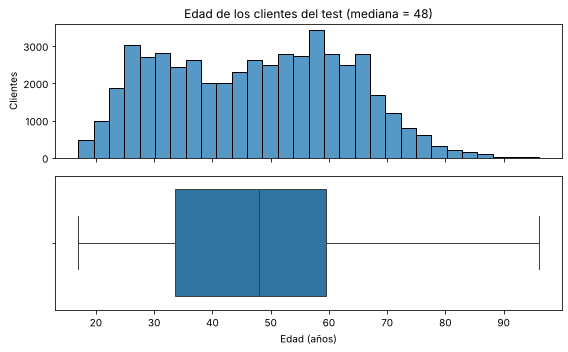

tramo_edad
<30     16.9
30-44   27.5
45-59   30.8
60+     24.9
Name: proportion, dtype: float64
Menores de 18 años: 62


In [16]:
eda.histograma_y_caja(clientes["edad"], "Edad de los clientes del test", "Edad (años)")
orden_edad = config.NOMBRES_EDAD
clientes["tramo_edad"] = clientes["edad"].apply(lambda edad: eda.tramo(edad, config.LIMITES_EDAD, config.NOMBRES_EDAD))
print((clientes["tramo_edad"].value_counts(normalize=True).loc[orden_edad] * 100).round(1))
print("Menores de 18 años:", (clientes["edad"] < 18).sum())

**➜ Qué nos llevamos para el proyecto:** respuesta a P1: clientes de mediana edad (mediana 48 años), con todas las edades representadas; el 25 % tiene 60 o más. Los tramos de edad servirán para la hipótesis propia (H3).

> **➜ O que tiramos para o projecto:** resposta à P1: clientes de meia-idade (mediana 48 anos), com todas as idades representadas; 25 % têm 60 ou mais. As faixas etárias servem para a hipótese própria (H3).

Mediana de **48 años**; la mitad central tiene entre 33 y 60. El 17 % tiene menos de 30 y el 25 %, 60 o más: hay clientes de todas las edades, con más peso de la mediana edad.

### Antigüedad como cliente

**Cómo funciona**

1. Misma función de gráfico para la antigüedad.
2. Misma función `tramo`, ahora con los límites de antigüedad (5, 10, 20 años).

**Por qué así:** reutilizar la misma función para varias variables evita repetir código y hace que todos los gráficos tengan el mismo estilo.

**Herramientas:** las mismas funciones de `src/eda.py`.

> **Como funciona (português)**
>
> 1. A mesma função de gráfico, agora para a antiguidade.
> 2. A mesma função `tramo`, agora com os limites de antiguidade (5, 10 e 20 anos).
>
> **Porquê assim:** reutilizar a mesma função evita repetir código e dá o mesmo estilo a todos os gráficos.

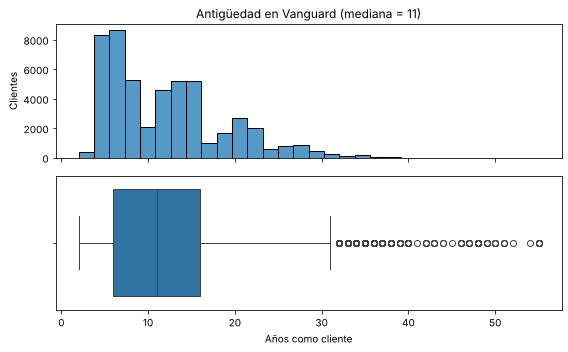

tramo_antiguedad
<5 años       7.5
5-9 años     37.4
10-19 años   39.1
20+ años     16.0
Name: proportion, dtype: float64

In [17]:
eda.histograma_y_caja(clientes["antiguedad_anos"], "Antigüedad en Vanguard", "Años como cliente")
orden_antiguedad = config.NOMBRES_ANTIGUEDAD
clientes["tramo_antiguedad"] = clientes["antiguedad_anos"].apply(
    lambda anos: eda.tramo(anos, config.LIMITES_ANTIGUEDAD, config.NOMBRES_ANTIGUEDAD))
(clientes["tramo_antiguedad"].value_counts(normalize=True).loc[orden_antiguedad] * 100).round(1)

**➜ Qué nos llevamos para el proyecto:** respuesta a P2: son clientes antiguos (mediana 11 años; solo el 7,5 % lleva menos de 5). El nuevo diseño se prueba sobre todo con clientes que ya conocen el proceso antiguo.

> **➜ O que tiramos para o projecto:** resposta à P2: são clientes antigos (mediana 11 anos; só 7,5 % estão há menos de 5). O novo design testa-se sobretudo com clientes que já conhecem o processo antigo.

Mediana de **11 años**. Solo el 7,5 % lleva menos de 5: son sobre todo **clientes antiguos**.

### Género

**Cómo funciona**

1. `barras_categoria` (en `src/eda.py`) calcula el % de cada categoría con `value_counts(normalize=True)` y lo dibuja con `sns.barplot`.
2. Debajo, `value_counts()` da los números absolutos.

**Por qué así:** el género es categórico: no tiene media ni histograma, se describe con frecuencias y barras. El % se lee mejor que el número de clientes, y el número exacto está en la tabla de debajo del gráfico.

**Herramientas:** `value_counts`, seaborn (`barplot`), matplotlib (`title`, `xlabel`, `ylabel`, `show`).

**Dónde se vio en clase:** `value_counts` → Semana 2 · 2.1 Pandas; `barplot` → Semana 2 · EDA básico (self-guided); `title`, `xlabel`, `ylabel`, `show` → Gráficos de las clases (semanas 2 y 5).

> **Como funciona (português)**
>
> 1. O `barras_categoria` (em `src/eda.py`) calcula a % de cada categoria com `value_counts(normalize=True)` e desenha-a com `sns.barplot`.
> 2. Em baixo, o `value_counts()` dá os números absolutos.
>
> **Porquê assim:** o género é categórico: não tem média nem histograma, descreve-se com frequências e barras. O número exacto está na tabela por baixo do gráfico.
>
> **Onde se deu nas aulas:** `value_counts` → Semana 2 · 2.1 Pandas; `barplot` → Semana 2 · EDA básico (self-guided); `title`, `xlabel`, `ylabel`, `show` → Gráficos de las clases (semanas 2 y 5).

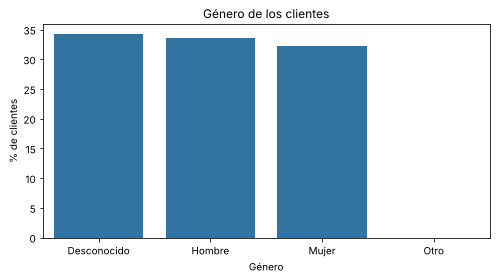

genero
Desconocido    17280
Hombre         16947
Mujer          16259
Otro               2
Name: count, dtype: int64

In [18]:
eda.barras_categoria(clientes["genero"], "Género de los clientes", "Género")
clientes["genero"].value_counts()

**➜ Qué nos llevamos para el proyecto:** hombres y mujeres casi a partes iguales, pero un 34 % sin género: cualquier análisis por género (posible hipótesis) tendrá ese límite y hay que decirlo.

> **➜ O que tiramos para o projecto:** homens e mulheres quase em partes iguais, mas 34 % sem género: qualquer análise por género terá esse limite e é preciso dizê-lo.

Hombres y mujeres casi a partes iguales, pero un **34 % tiene el género sin registrar**: cualquier conclusión por género tendrá ese límite. Los 2 clientes «Otro» son demasiado pocos para analizarlos aparte.

### Saldo

Muy asimétrico: unos pocos clientes tienen millones. Por eso se usa la **mediana** y no la media. El histograma se dibuja hasta el percentil 99 para que se vea la forma; el 1 % mayor sigue en los datos, solo queda fuera del dibujo.

**Cómo funciona**

1. `quantile(0.99)` calcula el percentil 99: el saldo por debajo del cual está el 99 % de los clientes.
2. Se dibuja el histograma solo con los clientes por debajo de ese valor (filtro con `loc`).
3. Se imprimen la media, la mediana y el máximo con todos los clientes, redondeados sin decimales (`round`).

**Por qué así:** con unos pocos saldos de millones, el histograma completo sería una sola barra pegada al cero. Quitar el 1 % mayor **solo del dibujo** deja ver la forma, sin borrar a nadie de los datos.

**Herramientas:** `quantile`, `loc`, `round`, f-strings.

**Dónde se vio en clase:** `quantile` → Semana 5 · 5.1 EDA univariante; `loc` → Semana 2 · 2.1 Pandas; `round` → Semana 2 · 2.2 Limpieza.

> **Como funciona (português)**
>
> 1. O `quantile(0.99)` calcula o percentil 99: o saldo abaixo do qual estão 99 % dos clientes.
> 2. Desenha-se o histograma só com os clientes abaixo desse valor (filtro com `loc`).
> 3. Mostram-se a média, a mediana e o máximo com todos os clientes, arredondados sem casas decimais (`round`).
>
> **Porquê assim:** com alguns saldos de milhões, o histograma completo seria uma só barra junto ao zero. Tirar o 1 % maior **só do desenho** deixa ver a forma, sem apagar ninguém dos dados.
>
> **Onde se deu nas aulas:** `quantile` → Semana 5 · 5.1 EDA univariante; `loc` → Semana 2 · 2.1 Pandas; `round` → Semana 2 · 2.2 Limpieza.

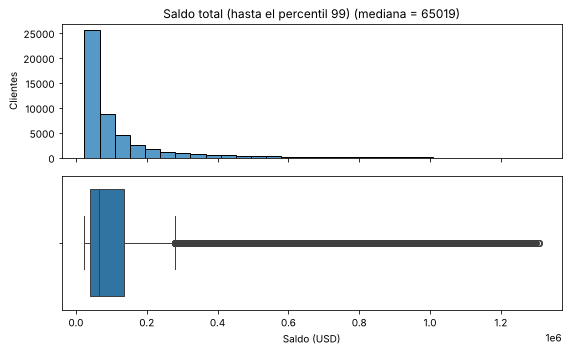

Media: 149515   Mediana: 65734   Máximo: 16320040


In [19]:
p99 = clientes["saldo"].quantile(0.99)
eda.histograma_y_caja(clientes.loc[clientes["saldo"] <= p99, "saldo"], "Saldo total (hasta el percentil 99)", "Saldo (USD)")
print(f"Media: {round(clientes['saldo'].mean())}   Mediana: {round(clientes['saldo'].median())}   Máximo: {round(clientes['saldo'].max())}")

**➜ Qué nos llevamos para el proyecto:** saldo típico de unos 66.000 USD, con unos pocos clientes millonarios. En las comparaciones usaremos cuartiles de saldo, no tramos fijos (Parte 2).

> **➜ O que tiramos para o projecto:** saldo típico de cerca de 66.000 USD, com alguns clientes milionários. Nas comparações usam-se quartis de saldo, não faixas fixas (Parte 2).

Media de 149.515 USD frente a una mediana de **65.734 USD**: la media la suben unos pocos saldos muy altos. (La mediana del gráfico es algo menor porque se calcula sin el 1 % mayor.)

### Cuentas y accesos

**Cómo funciona**

1. Barras para el número de cuentas y para los accesos a la web.

**Por qué así:** son numéricas, pero con pocos valores enteros (de 1 a 7 cuentas, de 3 a 9 accesos): con barras se ve el % de cada valor exacto, cosa que un histograma mezclaría.

**Herramientas:** la función `barras_categoria`.

**Dónde se vio en clase:** `barras_categoria` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. Barras para o número de contas e para os acessos à web.
>
> **Porquê assim:** são numéricas, mas com poucos valores inteiros: em barras vê-se a % de cada valor exacto, que um histograma misturaria.
>
> **Onde se deu nas aulas:** `barras_categoria` → funções nossas (tabela do guia, no início).

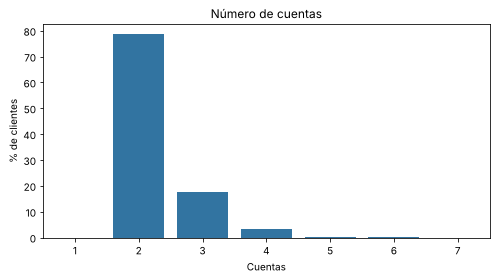

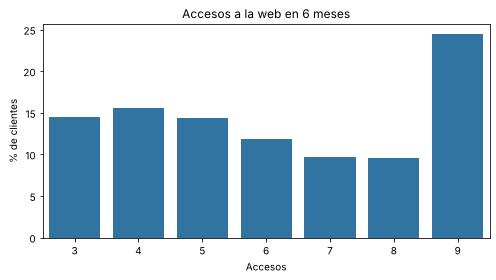

In [20]:
eda.barras_categoria(clientes["num_cuentas"], "Número de cuentas", "Cuentas")
eda.barras_categoria(clientes["accesos_6m"], "Accesos a la web en 6 meses", "Accesos")

**➜ Qué nos llevamos para el proyecto:** casi todos tienen 2 cuentas (poca variación: no sirve para separar clientes). Los accesos sí varían y sirven para medir el uso digital.

> **➜ O que tiramos para o projecto:** quase todos têm 2 contas (pouca variação: não serve para separar clientes). Os acessos variam e servem para medir o uso digital.

- **Cuentas:** el 79 % tiene 2.
- **Accesos:** mediana de 6 en seis meses, es decir, uno al mes.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** seguimos la lección de EDA univariante: cada tipo de variable se describe de una forma. Las categóricas con frecuencias y barras; las numéricas con media, mediana, dispersión, histograma y caja. Los tramos de edad (<30, 30-44, 45-59, 60+) los elegimos redondos, fáciles de explicar y con bastantes clientes en cada uno, porque luego se comparan Test y Control dentro de cada tramo.

> **Porque o fizemos assim:** seguimos a lição de EDA univariada: cada tipo de variável descreve-se de uma forma. As categóricas com frequências e barras; as numéricas com média, mediana, dispersão, histograma e caixa. Os escalões de idade (<30, 30-44, 45-59, 60+) escolhemo-los redondos, fáceis de explicar e com bastantes clientes em cada um, porque depois se comparam Test e Control dentro de cada escalão.

**Pregunta posible 1.** ¿Por qué cuentas y accesos van en barras si son números?
<br>*Pergunta possível 1. Porque é que contas e acessos vão em barras se são números?*

<details><summary>Respuesta / Resposta</summary>

Porque tienen muy pocos valores enteros (1 a 7 cuentas, 3 a 9 accesos). Con barras se ve el % de cada valor exacto; un histograma los juntaría en intervalos y se perdería ese detalle.

> Porque têm muito poucos valores inteiros (1 a 7 contas, 3 a 9 acessos). Com barras vê-se a % de cada valor exacto; um histograma juntá-los-ia em intervalos e perdia-se esse detalhe.

</details>

**Pregunta posible 2.** ¿Por qué el histograma del saldo se corta en el percentil 99?
<br>*Pergunta possível 2. Porque é que o histograma do saldo se corta no percentil 99?*

<details><summary>Respuesta / Resposta</summary>

Porque unos pocos saldos de millones aplastan el gráfico y todo saldría en una barra pegada al cero. Se quita el 1 % mayor **solo del dibujo**; las cifras (media, mediana) se calculan con todos.

> Porque uns poucos saldos de milhões esmagam o gráfico e tudo sairia numa barra colada ao zero. Tira-se o 1 % maior **só do desenho**; os números (média, mediana) calculam-se com todos.

</details>

## 1.7 Respuestas a las preguntas demográficas

**¿Quiénes son los clientes principales de este proceso?** Clientes de mediana edad (mediana de 48 años), con más de diez años en Vanguard, dos cuentas, un saldo típico de unos 66.000 USD y un acceso al mes a la web. Hombres y mujeres en proporción parecida, con un tercio sin género registrado.

**¿Jóvenes o mayores, nuevos o antiguos?** Más bien **de mediana edad y mayores** (el 56 % tiene 45 años o más) y **antiguos** (el 92 % lleva 5 años o más).

**¿Los dos grupos se parecen?** Es una condición para que la comparación sea justa:

**Cómo funciona**

1. `groupby("grupo")` separa los clientes en Test y Control.
2. `median()` calcula la mediana de cada variable en cada grupo.

**Por qué así:** para que la comparación sea justa, los dos grupos tienen que parecerse antes del test. Se usa la mediana porque el saldo es muy asimétrico.

**Herramientas:** `groupby`, `median`.

**Dónde se vio en clase:** `groupby` → Semana 2 · 2.4 Agregar; `median` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. O `groupby("grupo")` separa os clientes em Test e Control.
> 2. O `median()` calcula a mediana de cada variável em cada grupo.
>
> **Porquê assim:** para a comparação ser justa, os dois grupos têm de ser parecidos antes do teste. Usa-se a mediana porque o saldo é muito assimétrico.
>
> **Onde se deu nas aulas:** `groupby` → Semana 2 · 2.4 Agregar; `median` → Semana 2 · 2.1 Pandas.

In [21]:
clientes.groupby("grupo")[["edad", "antiguedad_anos", "saldo", "num_cuentas", "accesos_6m"]].median()

,edad,antiguedad_anos,saldo,num_cuentas,accesos_6m
grupo,,,,,
Control,48.5,11.0,66024.2,2.0,6.0
Test,47.5,11.0,65468.4,2.0,6.0


**➜ Qué nos llevamos para el proyecto:** las medianas de Test y Control son casi iguales: los grupos son comparables. Lo confirmaremos con un contraste (pregunta E3).

> **➜ O que tiramos para o projecto:** as medianas de Test e Control são quase iguais: os grupos são comparáveis. Confirma-se com um teste (pergunta E3).

**Cómo funciona**

1. `pd.crosstab` cruza dos columnas categóricas: género en las filas y grupo en las columnas.
2. `normalize="columns"` hace que cada columna sume 100 %: se lee «de los clientes del Test, qué % son mujeres».

**Por qué así:** compara el reparto por género dentro de cada grupo; si fuera muy distinto, el grupo con más mujeres podría completar menos por ese motivo y no por el diseño.

**Herramientas:** `pd.crosstab` (lección de EDA bivariante), `round`.

**Dónde se vio en clase:** `pd.crosstab` → Semana 5 · 5.2 EDA bivariante; `round` → Semana 2 · 2.2 Limpieza.

> **Como funciona (português)**
>
> 1. O `pd.crosstab` cruza duas colunas categóricas: género nas linhas e grupo nas colunas.
> 2. O `normalize="columns"` faz cada coluna somar 100 %: lê-se «dos clientes do Test, que % são mulheres».
>
> **Porquê assim:** compara a distribuição por género dentro de cada grupo; se fosse muito diferente, a diferença de resultados podia vir daí e não do design.
>
> **Onde se deu nas aulas:** `pd.crosstab` → Semana 5 · 5.2 EDA bivariante; `round` → Semana 2 · 2.2 Limpieza.

In [22]:
(pd.crosstab(clientes["genero"], clientes["grupo"], normalize="columns") * 100).round(1)

grupo,Control,Test
genero,,
Desconocido,34.1,34.4
Hombre,33.9,33.3
Mujer,32.1,32.3
Otro,0.0,0.0


**➜ Qué nos llevamos para el proyecto:** el reparto por género es el mismo en los dos grupos: el género no puede explicar diferencias entre Test y Control.

> **➜ O que tiramos para o projecto:** a distribuição por género é a mesma nos dois grupos: o género não pode explicar diferenças entre Test e Control.

Las medianas y el reparto por género son casi iguales en Test y Control: buena señal de que el reparto fue aleatorio. Se comprobará con un contraste en la Parte 4.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** el enunciado pide decir quiénes son los clientes principales. Además comprobamos que los dos grupos se parecen **antes** de compararlos, porque es la condición para que un test A/B sea justo: si un grupo fuera más mayor, la diferencia podría venir de la edad y no del diseño.

> **Porque o fizemos assim:** o enunciado pede para dizer quem são os clientes principais. Além disso verificamos que os dois grupos se parecem **antes** de os comparar, porque é a condição para um teste A/B ser justo: se um grupo fosse mais velho, a diferença podia vir da idade e não do design.

**Pregunta posible 1.** ¿Por qué comparamos los grupos con medianas y no con medias?
<br>*Pergunta possível 1. Porque comparamos os grupos com medianas e não com médias?*

<details><summary>Respuesta / Resposta</summary>

Porque el saldo es muy asimétrico: unos pocos millonarios moverían la media de un grupo. La mediana describe al cliente típico de cada grupo. El contraste formal (E3) está en la Parte 4.

> Porque o saldo é muito assimétrico: uns poucos milionários mexeriam a média de um grupo. A mediana descreve o cliente típico de cada grupo. O contraste formal (E3) está na Parte 4.

</details>

**Pregunta posible 2.** ¿Para qué sirve `normalize="columns"` en el `crosstab` de género?
<br>*Pergunta possível 2. Para que serve o `normalize="columns"` no `crosstab` do género?*

<details><summary>Respuesta / Resposta</summary>

Para que cada columna (Test y Control) sume 100 %. Así se compara el % de mujeres dentro de cada grupo aunque los grupos tengan tamaños distintos.

> Para cada coluna (Test e Control) somar 100 %. Assim compara-se a % de mulheres dentro de cada grupo mesmo que os grupos tenham tamanhos diferentes.

</details>

## 1.8 Comportamiento de los clientes en el proceso online

`comportamiento_por_cliente` resume los clics de cada cliente: visitas, clics, dispositivos, el paso más avanzado al que llegó y si completó el proceso.

*Es una primera mirada descriptiva. Los KPI (tiempo por paso, errores) y los contrastes llegan en los días 3 a 5.*

**Cómo funciona**

1. `comportamiento_por_cliente` (en `src/eda.py`) agrupa los clics por cliente con `groupby("client_id")` y calcula cuatro cosas por separado: visitas distintas (`nunique` de `visit_id`), clics (`count`), dispositivos (`nunique` de `visitor_id`) y el paso más avanzado (`max` de `paso_num`). Las junta en una tabla con `pd.DataFrame` y un diccionario: cada clave es una columna.
2. Con `unique()` saca la lista de pasos que hizo cada cliente y, con `apply` y `lambda`, marca si empezó (`start` en la lista), si completó (`confirm` en la lista) y si llegó a `confirm` sin `step_3`.
3. Se une con la tabla de clientes (`merge`) para tener grupo, edad y género.
4. `completo_pct` = `completo` × 100: como `True` vale 1 y `False` 0, la media de esta columna es directamente el % que completa.

**Por qué así:** pasa de 317.135 clics a 50.488 filas, una por cliente, que es la unidad del test (el grupo se asigna a cada cliente). El truco de la media de `True`/`False` evita tener que contar y dividir a mano.

**Herramientas:** `groupby`, `nunique`, `count`, `max`, `pd.DataFrame` con un diccionario, `unique`, `apply`, `lambda`, `merge`, `describe`.

**Dónde se vio en clase:** `groupby` → Semana 2 · 2.4 Agregar; `nunique`, `count`, `max`, `pd.DataFrame`, `unique`, `describe` → Semana 2 · 2.1 Pandas; `apply` → Semana 2 · 2.2 Limpieza; `lambda` → Semana 1 · 1.5 Lambda; `merge` → Semana 2 · 2.3 Combinar.

> **Como funciona (português)**
>
> 1. O `comportamiento_por_cliente` (em `src/eda.py`) agrupa os cliques por cliente com `groupby("client_id")` e calcula quatro coisas em separado: visitas distintas (`nunique` de `visit_id`), cliques (`count`), aparelhos (`nunique` de `visitor_id`) e o passo mais avançado (`max` de `paso_num`). Junta-as numa tabela com `pd.DataFrame` e um dicionário: cada chave é uma coluna.
> 2. Com `unique()` tira a lista de passos de cada cliente e, com `apply` e `lambda`, marca se começou (`start` na lista), se completou (`confirm` na lista) e se chegou a `confirm` sem `step_3`.
> 3. Junta-se à tabela de clientes (`merge`) para ter grupo, idade e género.
> 4. `completo_pct` = `completo` × 100: como `True` vale 1 e `False` vale 0, a média desta coluna é directamente a % que completa.
>
> **Porquê assim:** passa de 317.135 cliques para 50.488 linhas, uma por cliente, que é a unidade do teste. O truque da média de `True`/`False` evita contar e dividir à mão.
>
> **Onde se deu nas aulas:** `groupby` → Semana 2 · 2.4 Agregar; `nunique`, `count`, `max`, `pd.DataFrame`, `unique`, `describe` → Semana 2 · 2.1 Pandas; `apply` → Semana 2 · 2.2 Limpieza; `lambda` → Semana 1 · 1.5 Lambda; `merge` → Semana 2 · 2.3 Combinar.

In [23]:
por_cliente = eda.comportamiento_por_cliente(web_limpio).merge(
    clientes[["client_id", "grupo", "tramo_edad", "tramo_antiguedad", "genero"]], on="client_id")
por_cliente["completo_pct"] = por_cliente["completo"] * 100  # en %, para leerlo mejor
por_cliente[["visitas", "clics", "dispositivos"]].describe()

,visitas,clics,dispositivos
count,50488.0,50488.0,50488.0
mean,1.4,6.3,1.1
std,0.8,4.0,0.4
min,1.0,1.0,1.0
25%,1.0,5.0,1.0
50%,1.0,5.0,1.0
75%,2.0,7.0,1.0
max,18.0,72.0,14.0


**➜ Qué nos llevamos para el proyecto:** ya tenemos una fila por cliente con visitas, clics y si completó. La mediana es 1 visita y 5 clics: el recorrido típico es una visita sin vueltas.

> **➜ O que tiramos para o projecto:** já temos uma linha por cliente com visitas, cliques e se completou. A mediana é 1 visita e 5 cliques: o percurso típico é uma visita sem voltas.

**Cómo funciona**

1. `apply` con `lambda v: 5 if v > 5 else v` convierte todo valor mayor que 5 en 5, para agrupar «5 o más» en una sola barra. La columna original no cambia: el resultado se guarda en `visitas_hasta_5`.
2. Se dibuja con la misma función de barras.

**Por qué así:** hay clientes con hasta 18 visitas; sin agruparlas, el gráfico tendría muchas barras casi vacías.

**Herramientas:** `apply`, `lambda`, `if ... else` en una línea.

**Dónde se vio en clase:** `apply` → Semana 2 · 2.2 Limpieza; `lambda` → Semana 1 · 1.5 Lambda; `if ... else` → Semana 1 · 1.2 Control de flujo.

> **Como funciona (português)**
>
> 1. O `apply` com `lambda v: 5 if v > 5 else v` transforma qualquer valor acima de 5 em 5, para juntar «5 ou mais» numa só barra. A coluna original não muda: o resultado fica em `visitas_hasta_5`.
> 2. Desenha-se com a mesma função de barras.
>
> **Porquê assim:** há clientes com até 18 visitas; sem as juntar, o gráfico teria muitas barras quase vazias.
>
> **Onde se deu nas aulas:** `apply` → Semana 2 · 2.2 Limpieza; `lambda` → Semana 1 · 1.5 Lambda; `if ... else` → Semana 1 · 1.2 Control de flujo.

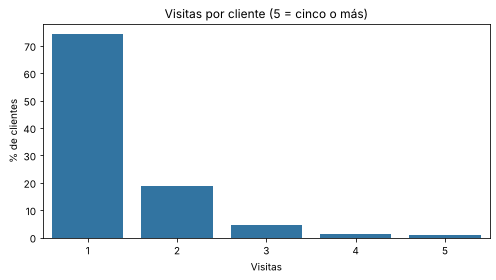

In [24]:
visitas_hasta_5 = por_cliente["visitas"].apply(lambda v: 5 if v > 5 else v)  # 5 = cinco o más
eda.barras_categoria(visitas_hasta_5, "Visitas por cliente (5 = cinco o más)", "Visitas")

**➜ Qué nos llevamos para el proyecto:** tres de cada cuatro clientes hacen una sola visita. Pregunta abierta para la Parte 2: ¿los que vuelven terminan o abandonan? (B7).

> **➜ O que tiramos para o projecto:** três em cada quatro clientes fazem uma só visita. Pergunta para a Parte 2: os que voltam terminam ou desistem? (B7).

### ¿Hasta dónde llegan?

El paso más avanzado de cada cliente muestra dónde se quedan los que no terminan.

**Cómo funciona**

1. Crea un diccionario al revés del de `config.py` (de número a nombre de paso) con una comprensión de diccionario.
2. Traduce el paso más avanzado de cada cliente a su nombre con `map`.
3. `crosstab` con `normalize="columns"` da, en cada grupo, la proporción de clientes cuyo paso más avanzado fue cada uno; `* 100` la pasa a %.
4. `.loc[list(config.PASOS)]` pone los pasos en el orden del proceso (`list` de un diccionario da sus claves).

**Por qué así:** es un embudo sencillo: dice dónde se quedan los que no terminan. Así se ve que la gran diferencia entre grupos está en `start`.

**Herramientas:** comprensión de diccionario, `map`, `crosstab`, `loc`.

**Dónde se vio en clase:** `map` → Semana 2 · 2.2 Limpieza; `crosstab` → Semana 5 · 5.2 EDA bivariante; `loc` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. Cria um dicionário ao contrário do do `config.py` (de número para nome do passo) com uma compreensão de dicionário.
> 2. Traduz o passo mais avançado de cada cliente para o nome com `map`.
> 3. O `crosstab` com `normalize="columns"` dá, em cada grupo, a proporção de clientes cujo passo mais avançado foi cada um; o `* 100` passa-a a %.
> 4. O `.loc[list(config.PASOS)]` põe os passos pela ordem do processo (`list` de um dicionário dá as chaves).
>
> **Porquê assim:** é um funil simples: diz onde ficam os que não terminam. Vê-se que a grande diferença entre grupos está no `start`.
>
> **Onde se deu nas aulas:** `map` → Semana 2 · 2.2 Limpieza; `crosstab` → Semana 5 · 5.2 EDA bivariante; `loc` → Semana 2 · 2.1 Pandas.

In [25]:
nombres_pasos = {numero: paso for paso, numero in config.PASOS.items()}
ultimo_paso = por_cliente["paso_max"].map(nombres_pasos)
(pd.crosstab(ultimo_paso, por_cliente["grupo"], normalize="columns") * 100).round(1).loc[list(config.PASOS)]

grupo,Control,Test
paso_max,,
start,14.0,9.1
step_1,6.2,7.3
step_2,5.4,5.2
step_3,8.9,9.0
confirm,65.6,69.3


**➜ Qué nos llevamos para el proyecto:** el 14 % del Control se queda en `start`, frente al 9 % del Test: el nuevo diseño gana sobre todo en la primera pantalla. Para el día 3: medir el tiempo y los errores en ese paso.

> **➜ O que tiramos para o projecto:** 14 % do Control fica no `start`, contra 9 % do Test: o novo design ganha sobretudo no primeiro ecrã. Para o dia 3: medir o tempo e os erros nesse passo.

El 14 % del Control se queda en `start` sin pasar a `step_1`, frente al 9 % del Test: el primer paso es donde más se nota el nuevo diseño. En los demás pasos los dos grupos se parecen.

### ¿Quién completa?

**Cómo funciona**

1. Agrupa por grupo y calcula la media de visitas, de clics y de `completo_pct` (que es el % que completa).

**Por qué así:** es el primer número del resultado del test (D1). Es descriptivo: si la diferencia es significativa se verá en la Parte 4.

**Herramientas:** `groupby`, `mean`.

**Dónde se vio en clase:** `groupby` → Semana 2 · 2.4 Agregar; `mean` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. Agrupa por grupo e calcula a média de visitas, de cliques e de `completo_pct` (que é a % que completa).
>
> **Porquê assim:** é o primeiro número do resultado do teste. É descritivo: se a diferença é significativa vê-se na Parte 4.
>
> **Onde se deu nas aulas:** `groupby` → Semana 2 · 2.4 Agregar; `mean` → Semana 2 · 2.1 Pandas.

In [26]:
por_cliente.groupby("grupo")[["visitas", "clics", "completo_pct"]].mean()

,visitas,clics,completo_pct
grupo,,,
Control,1.4,6.0,65.6
Test,1.4,6.6,69.3


**➜ Qué nos llevamos para el proyecto:** **el número central del proyecto:** completa el 69,3 % del Test y el 65,6 % del Control (+3,7 puntos). El Test hace más clics por cliente (6,6 frente a 6,0): ¿más vueltas atrás? Lo veremos con la tasa de errores.

> **➜ O que tiramos para o projecto:** **o número central do projecto:** completa 69,3 % do Test e 65,6 % do Control (+3,7 pontos). O Test faz mais cliques por cliente (6,6 contra 6,0): mais voltas atrás? Vê-se com a taxa de erros.

**Cómo funciona**

1. Lo mismo, pero agrupando por tramo de edad y en el orden de los tramos (`.loc[...]`).

**Por qué así:** comprueba si la edad cambia el comportamiento: es la pista para la hipótesis propia (H3).

**Herramientas:** `groupby`, `mean`, `loc`.

**Dónde se vio en clase:** `groupby` → Semana 2 · 2.4 Agregar; `mean`, `loc` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. O mesmo, mas agrupando por faixa etária e pela ordem das faixas (`.loc[...]`).
>
> **Porquê assim:** verifica se a idade muda o comportamento: é a pista para a hipótese própria (H3).
>
> **Onde se deu nas aulas:** `groupby` → Semana 2 · 2.4 Agregar; `mean`, `loc` → Semana 2 · 2.1 Pandas.

In [27]:
por_cliente.groupby("tramo_edad")[["visitas", "completo_pct"]].mean().loc[orden_edad]

,visitas,completo_pct
tramo_edad,,
<30,1.3,71.3
30-44,1.3,69.0
45-59,1.4,68.0
60+,1.5,62.9


**➜ Qué nos llevamos para el proyecto:** cuanto mayor el cliente, menos completa: del 71 % (<30) al 63 % (60+). Los mayores son el grupo que más ayuda necesita: base de la hipótesis H3.

> **➜ O que tiramos para o projecto:** quanto mais velho o cliente, menos completa: de 71 % (<30) a 63 % (60+). Os mais velhos são o grupo que mais ajuda precisa: base da hipótese H3.

**Cómo funciona**

1. Lo mismo por tramo de antigüedad.

**Por qué así:** comprueba si los clientes nuevos se pierden más en el proceso que los antiguos.

**Herramientas:** `groupby`, `mean`, `loc`.

**Dónde se vio en clase:** `groupby` → Semana 2 · 2.4 Agregar; `mean`, `loc` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. O mesmo por faixa de antiguidade.
>
> **Porquê assim:** verifica se os clientes novos se perdem mais no processo do que os antigos.
>
> **Onde se deu nas aulas:** `groupby` → Semana 2 · 2.4 Agregar; `mean`, `loc` → Semana 2 · 2.1 Pandas.

In [28]:
por_cliente.groupby("tramo_antiguedad")[["visitas", "completo_pct"]].mean().loc[orden_antiguedad]

,visitas,completo_pct
tramo_antiguedad,,
<5 años,1.3,67.5
5-9 años,1.3,68.6
10-19 años,1.4,66.5
20+ años,1.5,67.8


**➜ Qué nos llevamos para el proyecto:** la antigüedad casi no cambia la tasa (66,5 % a 68,6 %): no merece una hipótesis propia.

> **➜ O que tiramos para o projecto:** a antiguidade quase não muda a taxa (66,5 % a 68,6 %): não merece uma hipótese própria.

**Cómo funciona**

1. Lo mismo por género.

**Por qué así:** es una de las hipótesis de ejemplo del enunciado; antes de contrastarla conviene ver si hay alguna diferencia.

**Herramientas:** `groupby`, `mean`.

**Dónde se vio en clase:** `groupby` → Semana 2 · 2.4 Agregar; `mean` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. O mesmo por género.
>
> **Porquê assim:** é uma das hipóteses de exemplo do enunciado; antes de a testar convém ver se há alguma diferença.
>
> **Onde se deu nas aulas:** `groupby` → Semana 2 · 2.4 Agregar; `mean` → Semana 2 · 2.1 Pandas.

In [29]:
por_cliente.groupby("genero")[["visitas", "completo_pct"]].mean()

,visitas,completo_pct
genero,,
Desconocido,1.3,68.6
Hombre,1.4,68.7
Mujer,1.4,65.2
Otro,1.0,0.0


**➜ Qué nos llevamos para el proyecto:** las mujeres completan algo menos (65 % frente a 69 %). Se mira dentro de cada grupo en la Parte 2.

> **➜ O que tiramos para o projecto:** as mulheres completam um pouco menos (65 % contra 69 %). Vê-se dentro de cada grupo na Parte 2.

### Registros incompletos (problema 13)

**Cómo funciona**

1. Cuenta los clientes sin `start` (`~` invierte `True`/`False`: «los que **no** empezaron») y los que llegan a `confirm` sin `step_3`.
2. Filtra los clientes «normales» (empezaron y no tienen el salto) con `&` (y).
3. Recalcula la tasa por grupo solo con ellos.

**Por qué así:** es una prueba de robustez: si quitar los registros raros cambiara mucho el resultado, la conclusión dependería de ellos. No cambia (69,0 % frente a 65,4 %), así que se pueden mantener.

**Herramientas:** filtros con `~` y `&`, `groupby`, `mean`.

**Dónde se vio en clase:** `~`, `&`, `mean` → Semana 2 · 2.1 Pandas; `groupby` → Semana 2 · 2.4 Agregar.

> **Como funciona (português)**
>
> 1. Conta os clientes sem `start` (o `~` inverte `True`/`False`: «os que **não** começaram») e os que chegam a `confirm` sem `step_3`.
> 2. Filtra os clientes «normais» (começaram e não têm o salto) com `&` (e).
> 3. Recalcula a taxa por grupo só com eles.
>
> **Porquê assim:** é uma prova de robustez: se tirar os registos estranhos mudasse muito o resultado, a conclusão dependeria deles. Não muda, por isso podem ficar.
>
> **Onde se deu nas aulas:** `~`, `&`, `mean` → Semana 2 · 2.1 Pandas; `groupby` → Semana 2 · 2.4 Agregar.

In [30]:
print("Clientes sin 'start':                 ", (~por_cliente["empezo"]).sum())
print("Clientes con 'confirm' sin 'step_3':  ", por_cliente["confirm_sin_step_3"].sum())
print("Tasa de finalización sin estos casos:")
normales = por_cliente[por_cliente["empezo"] & ~por_cliente["confirm_sin_step_3"]]
normales.groupby("grupo")["completo_pct"].mean()

Clientes sin 'start':                  424
Clientes con 'confirm' sin 'step_3':   347
Tasa de finalización sin estos casos:


grupo
Control   65.4
Test      69.0
Name: completo_pct, dtype: float64

**➜ Qué nos llevamos para el proyecto:** sin los registros incompletos, el resultado casi no cambia (69,0 % frente a 65,4 %). Decisión: se mantienen y se citan como limitación.

> **➜ O que tiramos para o projecto:** sem os registos incompletos, o resultado quase não muda (69,0 % contra 65,4 %). Decisão: ficam e citam-se como limitação.

Quitando los registros incompletos, la diferencia entre grupos se mantiene parecida: no cambian la conclusión. Se mantienen en los datos y se citan como limitación.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** es la primera mirada al resultado del test (completar el proceso) y sirve para **buscar hipótesis**: de aquí salió la hipótesis propia sobre la edad (H3). La prueba de los registros incompletos la hicimos para saber si unos pocos datos raros podían cambiar la conclusión.

> **Porque o fizemos assim:** é o primeiro olhar ao resultado do teste (concluir o processo) e serve para **procurar hipóteses**: daqui saiu a hipótese própria sobre a idade (H3). A prova dos registos incompletos fizemo-la para saber se uns poucos dados estranhos podiam mudar a conclusão.

**Pregunta posible 1.** ¿Qué significa exactamente «completa el proceso»?
<br>*Pergunta possível 1. O que quer dizer exactamente «conclui o processo»?*

<details><summary>Respuesta / Resposta</summary>

Que el cliente llegó a `confirm` al menos una vez (definición D1 de `preguntas.md`). Si confirma dos veces, cuenta una: medimos personas que terminan, no confirmaciones.

> Que o cliente chegou ao `confirm` pelo menos uma vez (definição D1 do `preguntas.md`). Se confirmar duas vezes, conta uma: medimos pessoas que terminam, não confirmações.

</details>

**Pregunta posible 2.** ¿Por qué la antigüedad no se convirtió en una hipótesis?
<br>*Pergunta possível 2. Porque é que a antiguidade não se tornou uma hipótese?*

<details><summary>Respuesta / Resposta</summary>

Porque casi no cambia la tasa (de 66,5 % a 68,6 % entre tramos). La edad sí cambia mucho más (del 71 % al 63 %), así que la hipótesis propia se hizo con la edad.

> Porque quase não muda a taxa (de 66,5 % a 68,6 % entre escalões). A idade muda muito mais (de 71 % para 63 %), por isso a hipótese própria fez-se com a idade.

</details>

## 1.9 Resumen

**Datos:** 50.488 clientes del test (Test 26.961, Control 23.527) y 317.135 clics limpios, guardados en `data/clean`.

**Clientes:** de mediana edad (48 años de mediana) y antiguos (11 años de mediana); saldo muy desigual (mediana de 66.000 USD); un tercio sin género registrado.

**Comportamiento (descriptivo, sin contraste):**
- La mayoría hace una sola visita, desde un solo dispositivo.
- Completa el proceso el **69,3 %** del grupo Test y el **65,6 %** del Control.
- Los clientes de **60 o más** hacen más visitas y completan menos: candidatos a la hipótesis propia (H3).
- Los dos grupos se parecen en edad, antigüedad, saldo y género.

**Limitaciones:** género desconocido en un 34 %; accesos y llamadas no son independientes; unos pocos registros incompletos y dispositivos compartidos.

**Siguiente (día 3):** KPI por grupo: tasa de finalización, tiempo en cada paso y tasa de errores (volver a un paso anterior).

<a id="parte-2"></a>

# Parte 2 · Comportamiento de los clientes (semana 5, días 1 y 2)

La Parte 1 limpió los datos y describió a los clientes. Esta parte responde a las preguntas de comportamiento de [`preguntas.md`](preguntas.md):

| Pregunta | Sección |
|---|---|
| B5 · ¿Los clientes con más saldo completan más? | 2.2 |
| ¿Quién entra más a la web completa más? | 2.3 |
| P · ¿Influyen la edad y el género? | 2.4 |
| B7 · ¿Los que vuelven otro día terminan o abandonan? | 2.5 |
| B6 · ¿Cuándo se usa el proceso? | 2.6 |
| E2 · ¿El reparto entre grupos fue igual en el tiempo? | 2.7 |
| ¿La ventaja se mantiene en el tiempo? (E4, E7) | 2.7b |
| ¿Hay clientes con un comportamiento extremo? | 2.8 |

**Definición (D1):** un cliente completa el proceso si llega a `confirm` al menos una vez.

*Todo es descriptivo: comparamos porcentajes. Si una diferencia es significativa o no se comprobará con contrastes de hipótesis en la Parte 4.*

#### Para entenderlo · Comparar subgrupos no es lo mismo que probar causas

En esta parte se comparan porcentajes entre subgrupos (por saldo, edad, accesos...). Son comparaciones **descriptivas** y **observacionales**: nadie eligió al azar quién tiene más saldo o más edad. Si los mayores completan menos, puede ser por la edad o por algo que va con ella (usar menos la web, por ejemplo). La única comparación en la que el azar decide el grupo es Test frente a Control, y por eso es la única de la que se puede sacar una causa.

Al leer una tabla de esta parte conviene mirar **cuántos clientes hay en cada casilla**: un porcentaje de 30 clientes cambia mucho con dos o tres casos; uno de 10.000, casi nada.

> **Para perceber (português).** Nesta parte comparam-se percentagens entre subgrupos (por saldo, idade, acessos...). São comparações **descritivas** e **observacionais**: ninguém escolheu ao acaso quem tem mais saldo ou mais idade. Se os mais velhos concluem menos, pode ser pela idade ou por algo que vem com ela (usar menos a web, por exemplo). A única comparação em que o acaso decide o grupo é Test contra Control, e por isso só dela se pode tirar uma causa. Ao ler uma tabela desta parte convém ver **quantos clientes há em cada casa**: uma percentagem de 30 clientes muda muito com dois ou três casos; uma de 10.000, quase nada.

## 2.1 Datos limpios y una fila por cliente

Se parte de las tablas que guardó la Parte 1. `parse_dates` convierte `date_time` en fecha al leer el CSV (el CSV guarda las fechas como texto).

**Cómo funciona**

1. Lee las dos tablas limpias que guardó la Parte 1. `parse_dates=["date_time"]` convierte la columna en fecha al leer (el CSV guarda las fechas como texto).
2. Crea la tabla de una fila por cliente con `comportamiento_por_cliente` (explicada en la Parte 1) y la une con el perfil.

**Por qué así:** esta parte no repite la limpieza: parte de sus resultados. Si se cambia la limpieza, basta con volver a ejecutar el 01.

**Herramientas:** `pd.read_csv` con `parse_dates`, `merge`.

**Dónde se vio en clase:** `pd.read_csv` → Semana 2 · 2.1 Pandas; `parse_dates` → Semana 2 · fechas (self-guided); `merge` → Semana 2 · 2.3 Combinar.

> **Como funciona (português)**
>
> 1. Lê as duas tabelas limpas guardadas pela Parte 1. O `parse_dates=["date_time"]` converte a coluna em data ao ler (o CSV guarda as datas como texto).
> 2. Cria a tabela de uma linha por cliente com o `comportamiento_por_cliente` (explicado na Parte 1) e junta-a ao perfil.
>
> **Porquê assim:** esta parte não repete a limpeza: parte dos resultados dela. Se a limpeza mudar, basta correr outra vez o 01.
>
> **Onde se deu nas aulas:** `pd.read_csv` → Semana 2 · 2.1 Pandas; `parse_dates` → Semana 2 · fechas (self-guided); `merge` → Semana 2 · 2.3 Combinar.

In [31]:
clientes = pd.read_csv(f"{config.RUTA_CLEAN}/clientes.csv")
web = pd.read_csv(f"{config.RUTA_CLEAN}/web.csv", parse_dates=["date_time"])

por_cliente = eda.comportamiento_por_cliente(web).merge(clientes, on="client_id")
print(por_cliente.shape)
por_cliente.head()

(50488, 15)


,client_id,visitas,clics,dispositivos,paso_max,empezo,completo,confirm_sin_step_3,grupo,antiguedad_anos,edad,genero,num_cuentas,saldo,accesos_6m
0,555,1,5,1,4,True,True,False,Test,3,29.5,Desconocido,2,25454.7,6
1,647,1,5,1,4,True,True,False,Test,12,57.5,Hombre,2,30525.8,4
2,934,1,4,1,0,True,False,False,Test,9,51.0,Mujer,2,32522.9,3
3,1028,1,9,1,3,True,False,False,Control,12,36.0,Hombre,3,103520.2,4
4,1104,2,2,1,0,True,False,False,Control,5,48.0,Desconocido,3,154643.9,9


**➜ Qué nos llevamos para el proyecto:** partimos de los 50.488 clientes limpios, con una fila por cliente que junta comportamiento y perfil.

> **➜ O que tiramos para o projecto:** partimos dos 50.488 clientes limpos, com uma linha por cliente que junta comportamento e perfil.

**Cómo funciona**

1. `tasa_por_categoria` (en `src/eda.py`) agrupa por una columna y por grupo y calcula la media de `completo` (× 100 = % que completa).
2. `unstack()` pasa los grupos de las filas a las columnas, para tener Control y Test lado a lado.
3. Añade la diferencia (Test − Control, en puntos) y el número de clientes de cada categoría. Si se le da una lista de categorías, las ordena con `.loc`.
4. Aquí se usa con una copia de la tabla (`copy`) a la que se añade una columna que vale «Todos» para todos, para tener la tasa general con el mismo formato.

**Por qué así:** la misma función sirve para saldo, accesos, edad, género y visitas: todas las tablas del notebook tienen la misma forma y se comparan fácilmente. Se enseña el número de clientes porque un % de 20 personas no vale lo mismo que uno de 20.000.

**Herramientas:** `groupby` con dos columnas, `mean`, `unstack`, `copy`, `loc`.

**Dónde se vio en clase:** `groupby` → Semana 2 · 2.4 Agregar; `mean`, `loc` → Semana 2 · 2.1 Pandas; `unstack` → Semana 2 · 2.3 Combinar; `copy` → Semana 2 · 2.2 Limpieza.

> **Como funciona (português)**
>
> 1. O `tasa_por_categoria` (em `src/eda.py`) agrupa por uma coluna e pelo grupo e calcula a média de `completo` (× 100 = % que completa).
> 2. O `unstack()` passa os grupos das linhas para as colunas, para ter Control e Test lado a lado.
> 3. Acrescenta a diferença (Test − Control, em pontos) e o número de clientes de cada categoria. Se receber uma lista de categorias, ordena-as com `.loc`.
> 4. Aqui usa-se com uma cópia da tabela (`copy`) à qual se junta uma coluna que vale «Todos» para todos, para ter a taxa geral no mesmo formato.
>
> **Porquê assim:** a mesma função serve para saldo, acessos, idade, género e visitas: todas as tabelas têm a mesma forma e comparam-se facilmente. Mostra-se o número de clientes porque uma % de 20 pessoas não vale o mesmo que uma de 20.000.
>
> **Onde se deu nas aulas:** `groupby` → Semana 2 · 2.4 Agregar; `mean`, `loc` → Semana 2 · 2.1 Pandas; `unstack` → Semana 2 · 2.3 Combinar; `copy` → Semana 2 · 2.2 Limpieza.

In [32]:
por_cliente_todos = por_cliente.copy()
por_cliente_todos["todos"] = "Todos"  # una sola categoría: la tasa general con el mismo formato que las demás tablas
tasa_general = eda.tasa_por_categoria(por_cliente_todos, "todos")
tasa_general

grupo,Control,Test,diferencia,clientes
todos,,,,
Todos,65.6,69.3,3.7,50488


**➜ Qué nos llevamos para el proyecto:** la referencia de todo el notebook: +3,7 puntos a favor del Test. En cada sección miramos si esta ventaja se mantiene en cada tipo de cliente.

> **➜ O que tiramos para o projecto:** a referência de todo o notebook: +3,7 pontos a favor do Test. Em cada secção vê-se se esta vantagem se mantém em cada tipo de cliente.

Es la referencia para todo el notebook: **Test 69,3 %, Control 65,6 %**, una diferencia de 3,7 puntos. La pregunta en cada sección es si esa ventaja cambia según el tipo de cliente.

`tasa_por_categoria` (en `src/eda.py`) calcula, para cada categoría, el % que completa en cada grupo, la diferencia en puntos y el número de clientes. **Por qué el número de clientes:** un porcentaje de un grupo de 20 personas no vale lo mismo que uno de 20.000.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** partimos de `data/clean` (no se repite la limpieza) y de **una fila por cliente**, porque el cliente es la unidad del test. La tasa general (+3,7 puntos) es la referencia: en cada sección miramos si esa ventaja se mantiene en cada tipo de cliente.

> **Porque o fizemos assim:** partimos de `data/clean` (não se repete a limpeza) e de **uma linha por cliente**, porque o cliente é a unidade do teste. A taxa geral (+3,7 pontos) é a referência: em cada secção vemos se essa vantagem se mantém em cada tipo de cliente.

**Pregunta posible 1.** ¿Para qué la columna «todos» con el mismo valor en todas las filas?
<br>*Pergunta possível 1. Para que serve a coluna «todos» com o mesmo valor em todas as linhas?*

<details><summary>Respuesta / Resposta</summary>

Es un truco para usar la misma función `tasa_por_categoria` con una sola categoría: así la tasa general sale con el mismo formato (Control, Test, diferencia, clientes) que todas las demás tablas del notebook.

> É um truque para usar a mesma função `tasa_por_categoria` com uma só categoria: assim a taxa geral sai com o mesmo formato que as outras tabelas do notebook.

</details>

## 2.2 Saldo (B5)

El saldo se divide en **cuartiles**: cuatro tramos con el mismo número de clientes cada uno. **Por qué cuartiles y no tramos fijos:** el saldo es muy asimétrico; con tramos fijos (0-50.000, 50.000-100.000...) casi todos los clientes caerían en el primero.

Los límites se calculan con `quantile` y los tramos con la misma función `tramo` de la Parte 1.

**Cómo funciona**

1. `quantile([0.25, 0.5, 0.75])` da los tres cortes que dividen a los clientes en cuatro grupos iguales; `round(-3)` redondea a miles.
2. Se construye la lista de límites: 0, los tres cortes y un valor por encima del máximo.
3. Se aplica la misma función `tramo` (con condiciones `if`) para poner a cada cliente su cuartil.
4. Se calcula la tasa por cuartil y grupo con `tasa_por_categoria`.

**Por qué así:** con cuartiles, cada tramo tiene unos 12.600 clientes, y los porcentajes son comparables. Con tramos fijos, casi todos caerían en el primero.

**Herramientas:** `quantile`, listas, `apply`, `lambda`, la función `tramo`.

**Dónde se vio en clase:** `quantile` → Semana 5 · 5.1 EDA univariante; `apply` → Semana 2 · 2.2 Limpieza; `lambda` → Semana 1 · 1.5 Lambda; `tramo` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. O `quantile([0.25, 0.5, 0.75])` dá os três cortes que dividem os clientes em quatro grupos iguais; o `round(-3)` arredonda aos milhares.
> 2. Constrói-se a lista de limites: 0, os três cortes e um valor acima do máximo.
> 3. Aplica-se a mesma função `tramo` (com condições `if`) para dar a cada cliente o seu quartil.
> 4. Calcula-se a taxa por quartil e grupo com `tasa_por_categoria`.
>
> **Porquê assim:** com quartis, cada faixa tem cerca de 12.600 clientes e as percentagens são comparáveis. Com faixas fixas, quase todos cairiam na primeira.
>
> **Onde se deu nas aulas:** `quantile` → Semana 5 · 5.1 EDA univariante; `apply` → Semana 2 · 2.2 Limpieza; `lambda` → Semana 1 · 1.5 Lambda; `tramo` → funções nossas (tabela do guia, no início).

In [33]:
cuartiles = clientes["saldo"].quantile([0.25, 0.5, 0.75]).round(-3)
print(cuartiles)

limites_saldo = [0] + list(cuartiles) + [clientes["saldo"].max() + 1]
nombres_saldo = ["Q1 · hasta 40 mil", "Q2 · 40-66 mil", "Q3 · 66-140 mil", "Q4 · más de 140 mil"]
por_cliente["tramo_saldo"] = por_cliente["saldo"].apply(lambda saldo: eda.tramo(saldo, limites_saldo, nombres_saldo))

tabla_saldo = eda.tasa_por_categoria(por_cliente, "tramo_saldo", nombres_saldo)
tabla_saldo

0.2    40000.0
0.5    66000.0
0.8   140000.0
Name: saldo, dtype: float64


grupo,Control,Test,diferencia,clientes
tramo_saldo,,,,
Q1 · hasta 40 mil,65.7,69.5,3.8,12712
Q2 · 40-66 mil,65.1,68.8,3.7,12612
Q3 · 66-140 mil,64.9,68.6,3.8,12547
Q4 · más de 140 mil,66.6,70.2,3.6,12617


**➜ Qué nos llevamos para el proyecto:** respuesta a B5: el saldo casi no influye (65-70 % en todos los cuartiles) y el Test gana en todos por unos 3,7 puntos.

> **➜ O que tiramos para o projecto:** resposta à B5: o saldo quase não influencia (65-70 % em todos os quartis) e o Test ganha em todos por cerca de 3,7 pontos.

**Cómo funciona**

1. `barras_por_grupo` (en `src/eda.py`) pasa la tabla de formato ancho (Control y Test en columnas) a formato largo (una fila por categoría y grupo) con `melt`, porque `sns.barplot` lo necesita así para dibujar barras agrupadas con `hue`.
2. Dibuja las barras gris (Control) y azul (Test) con `palette`. El eje Y empieza en 0.

**Por qué así:** las barras una al lado de la otra comparan los dos grupos en cada categoría de un vistazo. Con el eje desde 0, la altura de cada barra es proporcional a su valor y no exagera las diferencias; los puntos exactos están en la tabla de encima.

**Herramientas:** `melt`, seaborn (`barplot` con `hue` y `palette`), matplotlib (`title`, `xlabel`, `ylabel`, `show`).

**Dónde se vio en clase:** `melt`, `hue` → Semana 2 · 2.3 Combinar; `barplot`, `palette` → Semana 2 · EDA básico (self-guided); `title`, `xlabel`, `ylabel`, `show` → Gráficos de las clases (semanas 2 y 5).

> **Como funciona (português)**
>
> 1. O `barras_por_grupo` (em `src/eda.py`) passa a tabela de formato largo (Control e Test em colunas) para formato comprido (uma linha por categoria e grupo) com `melt`, porque o `sns.barplot` precisa dela assim para desenhar barras agrupadas com `hue`.
> 2. Desenha as barras a cinzento (Control) e azul (Test) com `palette`. O eixo Y começa no 0.
>
> **Porquê assim:** as barras lado a lado comparam os dois grupos em cada categoria num relance. Com o eixo a partir do 0, a altura de cada barra é proporcional ao valor e não exagera as diferenças; os pontos exactos estão na tabela de cima.
>
> **Onde se deu nas aulas:** `melt`, `hue` → Semana 2 · 2.3 Combinar; `barplot`, `palette` → Semana 2 · EDA básico (self-guided); `title`, `xlabel`, `ylabel`, `show` → Gráficos de las clases (semanas 2 y 5).

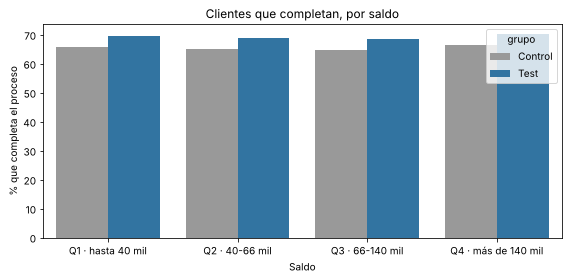

In [34]:
eda.barras_por_grupo(tabla_saldo, "Clientes que completan, por saldo", "Saldo")

**➜ Qué nos llevamos para el proyecto:** gráfico candidato para la presentación: enseña de un vistazo que la ventaja del Test no depende del dinero del cliente.

> **➜ O que tiramos para o projecto:** gráfico candidato para a apresentação: mostra num relance que a vantagem do Test não depende do dinheiro do cliente.

**Lo que se ve:** el saldo casi no cambia la tasa (entre 65 % y 70 % en todos los cuartiles). En **todos** los cuartiles el Test supera al Control por 3,5 a 4 puntos: la ventaja del nuevo diseño no depende del saldo.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** responde a B5 (¿los que tienen más dinero completan más?). Elegimos **cuartiles** porque el saldo es muy asimétrico: con tramos fijos casi todos caerían en el primero; con cuartiles cada tramo tiene unos 12.600 clientes y los % se pueden comparar.

> **Porque o fizemos assim:** responde à B5 (os que têm mais dinheiro concluem mais?). Escolhemos **quartis** porque o saldo é muito assimétrico: com escalões fixos quase todos cairiam no primeiro; com quartis cada escalão tem uns 12.600 clientes e as % podem comparar-se.

**Pregunta posible 1.** ¿Qué contestaríais si os preguntan si los clientes ricos completan más?
<br>*Pergunta possível 1. O que responderiam se vos perguntassem se os clientes ricos concluem mais?*

<details><summary>Respuesta / Resposta</summary>

Que casi no hay diferencia: entre el 65 % y el 70 % en todos los cuartiles, y el nuevo diseño gana en todos por unos 3,5-4 puntos. El dinero no explica el resultado.

> Que quase não há diferença: entre 65 % e 70 % em todos os quartis, e o novo design ganha em todos por uns 3,5-4 pontos. O dinheiro não explica o resultado.

</details>

**Pregunta posible 2.** ¿Para qué sirve `round(-3)` en los cortes de los cuartiles?
<br>*Pergunta possível 2. Para que serve o `round(-3)` nos cortes dos quartis?*

<details><summary>Respuesta / Resposta</summary>

Redondea a miles (un corte como 39.874 pasaría a 40.000) para que las etiquetas de los tramos se lean fácil. El tramo de cada cliente casi no cambia.

> Arredonda aos milhares (um corte como 39.874 passaria a 40.000) para as etiquetas dos escalões se lerem facilmente.

</details>

## 2.3 Uso de la web (accesos en 6 meses)

Si los clientes que entran poco a la web completaran mucho menos, sería una señal de que el proceso es difícil para los menos digitales.

**Cómo funciona**

1. Tasa por número de accesos a la web y por grupo.

**Por qué así:** los accesos son una medida de cuánto usa el cliente lo digital. No hace falta hacer tramos: hay solo 7 valores (de 3 a 9).

**Herramientas:** la función `tasa_por_categoria`.

**Dónde se vio en clase:** `tasa_por_categoria` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. Taxa por número de acessos à web e por grupo.
>
> **Porquê assim:** os acessos medem quanto o cliente usa o digital. Não é preciso criar faixas: só há 7 valores (de 3 a 9).
>
> **Onde se deu nas aulas:** `tasa_por_categoria` → funções nossas (tabela do guia, no início).

In [35]:
tabla_accesos = eda.tasa_por_categoria(por_cliente, "accesos_6m")
tabla_accesos

grupo,Control,Test,diferencia,clientes
accesos_6m,,,,
3,62.8,65.9,3.2,7311
4,65.2,68.3,3.1,7855
5,64.3,69.3,5.1,7283
6,67.9,69.6,1.7,5965
7,65.1,69.0,3.9,4914
8,65.6,70.2,4.6,4810
9,67.3,71.6,4.3,12350


**➜ Qué nos llevamos para el proyecto:** quien usa más la web completa un poco más, y el Test gana en todos los niveles de uso: el nuevo diseño no solo ayuda a los más digitales.

> **➜ O que tiramos para o projecto:** quem usa mais a web completa um pouco mais, e o Test ganha em todos os níveis de uso: o novo design não ajuda só os mais digitais.

**Cómo funciona**

1. Mismo gráfico de barras agrupadas, ahora por accesos.

**Por qué así:** la misma forma de gráfico en todo el notebook hace que se comparen fácilmente.

**Herramientas:** la función `barras_por_grupo`.

**Dónde se vio en clase:** `barras_por_grupo` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. O mesmo gráfico de barras agrupadas, agora por acessos.
>
> **Porquê assim:** a mesma forma de gráfico em todo o notebook facilita a comparação.
>
> **Onde se deu nas aulas:** `barras_por_grupo` → funções nossas (tabela do guia, no início).

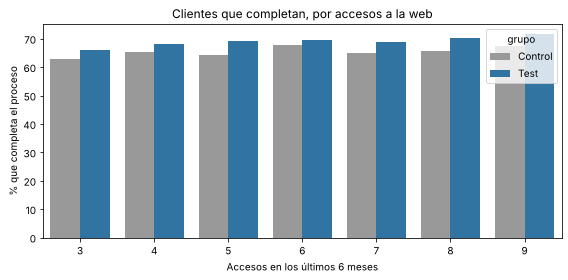

In [36]:
eda.barras_por_grupo(tabla_accesos, "Clientes que completan, por accesos a la web", "Accesos en los últimos 6 meses")

**➜ Qué nos llevamos para el proyecto:** ojo: 12.350 clientes tienen exactamente 9 accesos; es probable que 9 sea un tope del registro. Lo apuntamos como limitación de los datos.

> **➜ O que tiramos para o projecto:** atenção: 12.350 clientes têm exactamente 9 acessos; é provável que 9 seja um limite do registo. Fica como limitação dos dados.

**Lo que se ve:** quien entra más completa un poco más (de 63-66 % con 3 accesos a 67-72 % con 9). El Test gana al Control en **todos** los niveles. Los clientes con 9 accesos son el grupo más numeroso (12.350): probablemente 9 es el valor máximo que se registra, no el real.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** queríamos saber si el nuevo diseño solo ayuda a los clientes muy digitales. Los accesos en 6 meses son la mejor medida de uso digital que tenemos; no hacen falta tramos porque solo hay 7 valores.

> **Porque o fizemos assim:** queríamos saber se o novo design só ajuda os clientes muito digitais. Os acessos em 6 meses são a melhor medida de uso digital que temos; não são precisos escalões porque só há 7 valores.

**Pregunta posible 1.** ¿Por qué decís que 9 accesos puede ser un tope?
<br>*Pergunta possível 1. Porque dizem que 9 acessos pode ser um tecto?*

<details><summary>Respuesta / Resposta</summary>

Porque 12.350 clientes tienen exactamente 9, muchos más que cualquier otro valor, y no hay ninguno con más. Lo más probable es que el registro no cuente más allá de 9. Lo decimos como limitación, no como hecho.

> Porque 12.350 clientes têm exactamente 9, muitos mais do que qualquer outro valor, e não há nenhum com mais. O mais provável é o registo não contar além de 9. Dizemo-lo como limitação, não como facto.

</details>

## 2.4 Edad y género

En la Parte 1 vimos que los mayores de 60 y las mujeres completan menos. Ahora se mira **dentro de cada grupo**, para ver si el nuevo diseño les ayuda más o menos que al resto.

**Cómo funciona**

1. Pone a cada cliente su tramo de edad con la función `tramo` (como en la Parte 1).
2. Calcula la tasa por tramo y grupo, en el orden de los tramos.

**Por qué así:** permite ver si el nuevo diseño ayuda igual a todas las edades o más a unas que a otras.

**Herramientas:** `apply`, `lambda`, `tasa_por_categoria`.

**Dónde se vio en clase:** `apply` → Semana 2 · 2.2 Limpieza; `lambda` → Semana 1 · 1.5 Lambda; `tasa_por_categoria` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. Dá a cada cliente a sua faixa etária com a função `tramo` (como na Parte 1).
> 2. Calcula a taxa por faixa e grupo, pela ordem das faixas.
>
> **Porquê assim:** permite ver se o novo design ajuda igual todas as idades ou mais umas do que outras.
>
> **Onde se deu nas aulas:** `apply` → Semana 2 · 2.2 Limpieza; `lambda` → Semana 1 · 1.5 Lambda; `tasa_por_categoria` → funções nossas (tabela do guia, no início).

In [37]:
orden_edad = config.NOMBRES_EDAD
por_cliente["tramo_edad"] = por_cliente["edad"].apply(lambda edad: eda.tramo(edad, config.LIMITES_EDAD, config.NOMBRES_EDAD))
tabla_edad = eda.tasa_por_categoria(por_cliente, "tramo_edad", orden_edad)
tabla_edad

grupo,Control,Test,diferencia,clientes
tramo_edad,,,,
<30,67.6,74.4,6.8,8531
30-44,67.5,70.2,2.8,13864
45-59,67.1,68.9,1.8,15534
60+,60.4,65.2,4.8,12558


**➜ Qué nos llevamos para el proyecto:** el nuevo diseño ayuda más a los menores de 30 (+6,8) y a los de 60+ (+4,8) que a los de 45-59 (+1,8). Es la hipótesis propia (H3) que contrastaremos.

> **➜ O que tiramos para o projecto:** o novo design ajuda mais os menores de 30 (+6,8) e os de 60+ (+4,8) do que os de 45-59 (+1,8). É a hipótese própria (H3) a testar.

**Cómo funciona**

1. Gráfico de barras agrupadas por tramo de edad.

**Por qué así:** es el gráfico que mejor cuenta la hipótesis propia (H3): se ve que los de 60+ completan menos y cuánto les ayuda el nuevo diseño.

**Herramientas:** la función `barras_por_grupo`.

**Dónde se vio en clase:** `barras_por_grupo` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. Gráfico de barras agrupadas por faixa etária.
>
> **Porquê assim:** é o gráfico que melhor conta a hipótese própria (H3).
>
> **Onde se deu nas aulas:** `barras_por_grupo` → funções nossas (tabela do guia, no início).

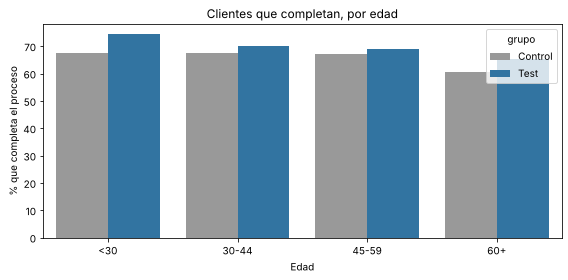

In [38]:
eda.barras_por_grupo(tabla_edad, "Clientes que completan, por edad", "Edad")

**➜ Qué nos llevamos para el proyecto:** es el gráfico más potente para la presentación: los mayores completan menos, pero el nuevo diseño los acerca al resto.

> **➜ O que tiramos para o projecto:** é o gráfico mais forte para a apresentação: os mais velhos completam menos, mas o novo design aproxima-os dos outros.

**Lo que se ve:**
- Los **mayores de 60** completan menos en los dos grupos (60,4 % y 65,2 %), pero el nuevo diseño les ayuda **casi 5 puntos**, más que la media (3,7).
- Los **menores de 30** son los que más ganan: casi **7 puntos** (74,4 % frente a 67,6 %).
- Entre 45 y 59 años, la ventaja es la más pequeña (1,8 puntos).

Esto apoya la **hipótesis propia H3**: ¿el nuevo diseño ayuda más a unos tramos de edad que a otros? Se contrastará en la Parte 4.

**Cómo funciona**

1. Filtra los clientes con género distinto de «Otro» (`!=`) y calcula la tasa por género y grupo.

**Por qué así:** con solo 2 clientes, el % de «Otro» no significa nada y estropearía la tabla.

**Herramientas:** filtro con `!=`, `tasa_por_categoria`.

**Dónde se vio en clase:** `!=` → Semana 2 · 2.1 Pandas; `tasa_por_categoria` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. Filtra os clientes com género diferente de «Otro» (`!=`) e calcula a taxa por género e grupo.
>
> **Porquê assim:** com só 2 clientes, a % de «Otro» não significa nada e estragava a tabela.
>
> **Onde se deu nas aulas:** `!=` → Semana 2 · 2.1 Pandas; `tasa_por_categoria` → funções nossas (tabela do guia, no início).

In [39]:
tabla_genero = eda.tasa_por_categoria(por_cliente[por_cliente["genero"] != "Otro"], "genero")
tabla_genero

grupo,Control,Test,diferencia,clientes
genero,,,,
Desconocido,66.8,70.2,3.4,17280
Hombre,66.5,70.7,4.3,16947
Mujer,63.4,66.9,3.5,16259


**➜ Qué nos llevamos para el proyecto:** la diferencia por género ya existía con el diseño antiguo y el nuevo no la cambia: el género no es una buena hipótesis para el diseño.

> **➜ O que tiramos para o projecto:** a diferença por género já existia com o design antigo e o novo não a muda: o género não é uma boa hipótese para o design.

Se quitan los 2 clientes «Otro»: con 2 personas un porcentaje no significa nada.

**Lo que se ve:** las mujeres completan unos 3 puntos menos en los dos grupos, y el nuevo diseño les ayuda lo mismo que a los hombres (3,5 puntos). La diferencia por género existía antes del nuevo diseño y no cambia con él. No sabemos por qué: los datos no lo explican.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** en el 01 vimos que los mayores y las mujeres completan menos. Aquí miramos **dentro de cada tipo de cliente** si el nuevo diseño les ayuda más o menos que al resto. La edad dio la hipótesis propia (H3); el género no, porque su diferencia ya existía con el diseño antiguo.

> **Porque o fizemos assim:** no 01 vimos que os mais velhos e as mulheres concluem menos. Aqui vemos **dentro de cada tipo de cliente** se o novo design os ajuda mais ou menos do que aos outros. A idade deu a hipótese própria (H3); o género não, porque a diferença já existia com o design antigo.

**Pregunta posible 1.** ¿Por qué quitamos a los clientes de género «Otro»?
<br>*Pergunta possível 1. Porque tirámos os clientes de género «Outro»?*

<details><summary>Respuesta / Resposta</summary>

Porque son 2. Con 2 personas, un % sale 0, 50 o 100 por pura casualidad y estropearía la tabla.

> Porque são 2. Com 2 pessoas, uma % sai 0, 50 ou 100 por puro acaso e estragaria a tabela.

</details>

**Pregunta posible 2.** Si las mujeres completan menos, ¿por qué el género no es una buena hipótesis para el diseño?
<br>*Pergunta possível 2. Se as mulheres concluem menos, porque é que o género não é uma boa hipótese para o design?*

<details><summary>Respuesta / Resposta</summary>

Porque la diferencia es igual en los dos grupos (unos 3 puntos) y el nuevo diseño ayuda a mujeres y hombres lo mismo (+3,5). No es algo que el diseño cambie.

> Porque a diferença é igual nos dois grupos (uns 3 pontos) e o novo design ajuda mulheres e homens o mesmo (+3,5). Não é algo que o design mude.

</details>

## 2.5 Visitas y días (B7)

¿Volver otro día es señal de dificultad (abandono) o de que el cliente termina más tarde?

**Cómo funciona**

1. Con `apply` y un `if` dentro de `lambda` (`a if condición else b`) agrupa las visitas en «1 visita», «2 visitas» y «3 o más».
2. Calcula la tasa en cada tramo.

**Por qué así:** responde a si volver es mala señal (abandono) o buena (terminar más tarde).

**Herramientas:** `apply`, `lambda`, `if ... else` en una línea.

**Dónde se vio en clase:** `apply` → Semana 2 · 2.2 Limpieza; `lambda` → Semana 1 · 1.5 Lambda; `if ... else` → Semana 1 · 1.2 Control de flujo.

> **Como funciona (português)**
>
> 1. Com `apply` e um `if` dentro do `lambda` (`a if condição else b`) junta as visitas em «1 visita», «2 visitas» e «3 o más».
> 2. Calcula a taxa em cada faixa.
>
> **Porquê assim:** responde se voltar é mau sinal (desistência) ou bom (terminar mais tarde).
>
> **Onde se deu nas aulas:** `apply` → Semana 2 · 2.2 Limpieza; `lambda` → Semana 1 · 1.5 Lambda; `if ... else` → Semana 1 · 1.2 Control de flujo.

In [40]:
por_cliente["visitas_tramo"] = por_cliente["visitas"].apply(lambda v: "1 visita" if v == 1 else ("2 visitas" if v == 2 else "3 o más"))
tabla_visitas = eda.tasa_por_categoria(por_cliente, "visitas_tramo", ["1 visita", "2 visitas", "3 o más"])
tabla_visitas

grupo,Control,Test,diferencia,clientes
visitas_tramo,,,,
1 visita,63.5,67.5,4.1,37498
2 visitas,72.1,72.9,0.7,9446
3 o más,71.4,77.7,6.4,3544


**➜ Qué nos llevamos para el proyecto:** respuesta a B7: volver no es abandonar. Quien hace 2 o más visitas completa más (72-78 %) que quien hace una (63-68 %).

> **➜ O que tiramos para o projecto:** resposta à B7: voltar não é desistir. Quem faz 2 ou mais visitas completa mais (72-78 %) do que quem faz uma (63-68 %).

**Cómo funciona**

1. Para cada cliente, `fechas.dt.date` quita la hora y se queda con el día; `nunique()` cuenta los días distintos con actividad.
2. `map` pone ese número en la tabla de clientes.
3. Se clasifica en «Un día» o «Varios días» y se calcula la tasa.

**Por qué así:** una visita nueva el mismo día puede ser solo una pestaña recargada; un día distinto es una vuelta de verdad.

**Herramientas:** `groupby`, `apply`, `.dt.date`, `nunique`, `map`.

**Dónde se vio en clase:** `groupby` → Semana 2 · 2.4 Agregar; `apply`, `map` → Semana 2 · 2.2 Limpieza; `.dt.date` → Semana 2 · fechas (self-guided); `nunique` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. Para cada cliente, o `fechas.dt.date` tira a hora e fica com o dia; o `nunique()` conta os dias distintos com actividade.
> 2. O `map` põe esse número na tabela de clientes.
> 3. Classifica-se em «Un día» ou «Varios días» e calcula-se a taxa.
>
> **Porquê assim:** uma visita nova no mesmo dia pode ser só uma página recarregada; um dia diferente é um regresso a sério.
>
> **Onde se deu nas aulas:** `groupby` → Semana 2 · 2.4 Agregar; `apply`, `map` → Semana 2 · 2.2 Limpieza; `.dt.date` → Semana 2 · fechas (self-guided); `nunique` → Semana 2 · 2.1 Pandas.

In [41]:
dias_activos = web.groupby("client_id")["date_time"].apply(lambda fechas: fechas.dt.date.nunique())
por_cliente["dias_activos"] = por_cliente["client_id"].map(dias_activos)
por_cliente["varios_dias"] = por_cliente["dias_activos"].apply(lambda d: "Varios días" if d > 1 else "Un día")
eda.tasa_por_categoria(por_cliente, "varios_dias", ["Un día", "Varios días"])

grupo,Control,Test,diferencia,clientes
varios_dias,,,,
Un día,63.8,67.8,4.0,39118
Varios días,71.8,74.3,2.5,11370


**➜ Qué nos llevamos para el proyecto:** quien vuelve otro día completa el 73 %. Idea para las recomendaciones: recordar el proceso a medias a quien no termina en la primera visita (es una propuesta, no un resultado).

> **➜ O que tiramos para o projecto:** quem volta noutro dia completa 73 %. Ideia para as recomendações: lembrar o processo a meio a quem não termina na primeira visita (é uma proposta, não um resultado).

**Lo que se ve:** el 74 % hace una sola visita, y es justo ese grupo el que menos completa (63,5 % y 67,5 %). Quien vuelve otro día completa **más** (73 %): volver no es abandonar, es terminar más tarde.

Para Vanguard, esto sugiere que recordar a los clientes que tienen el proceso a medias (un email, un aviso) podría subir la tasa. Es una idea, no un resultado: los datos no prueban que el recordatorio funcione.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** responde a B7: volver otra vez ¿es mala señal (el cliente se atasca) o buena (termina más tarde)? Separamos visitas de días porque una visita nueva el mismo día puede ser solo una pestaña recargada; un día distinto es una vuelta de verdad.

> **Porque o fizemos assim:** responde à B7: voltar outra vez é mau sinal (o cliente fica preso) ou bom (termina mais tarde)? Separamos visitas de dias porque uma visita nova no mesmo dia pode ser só um separador recarregado; um dia diferente é uma volta a sério.

**Pregunta posible 1.** ¿Qué recomendación sale de esta sección?
<br>*Pergunta possível 1. Que recomendação sai desta secção?*

<details><summary>Respuesta / Resposta</summary>

Que recordar el proceso a medias a quien no termina en la primera visita podría subir la tasa, porque quien vuelve completa más (73 %). Es una **propuesta**, no un resultado contrastado.

> Que lembrar o processo a meio a quem não termina na primeira visita podia subir a taxa, porque quem volta conclui mais (73 %). É uma **proposta**, não um resultado contrastado.

</details>

## 2.6 Cuándo se usa el proceso (B6)

`date_time` ya es fecha, así que con `.dt` se sacan el mes, el día de la semana y la hora.

**Cómo funciona**

1. `.dt.month` saca el mes de cada clic (3 a 6).
2. `value_counts().sort_index()` cuenta los clics por mes, en orden de mes.
3. Se cambian los números por nombres y se dibuja con `barras_simples`.

**Por qué así:** contar por mes muestra si el uso fue constante durante el test o se concentró en algún momento.

**Herramientas:** `.dt.month`, `value_counts`, `sort_index`.

**Dónde se vio en clase:** `.dt.month` → Semana 2 · fechas (self-guided); `value_counts`, `sort_index` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. O `.dt.month` tira o mês de cada clique (3 a 6).
> 2. O `value_counts().sort_index()` conta os cliques por mês, pela ordem dos meses.
> 3. Trocam-se os números pelos nomes e desenha-se com `barras_simples`.
>
> **Porquê assim:** contar por mês mostra se o uso foi constante ou se se concentrou num momento.
>
> **Onde se deu nas aulas:** `.dt.month` → Semana 2 · fechas (self-guided); `value_counts`, `sort_index` → Semana 2 · 2.1 Pandas.

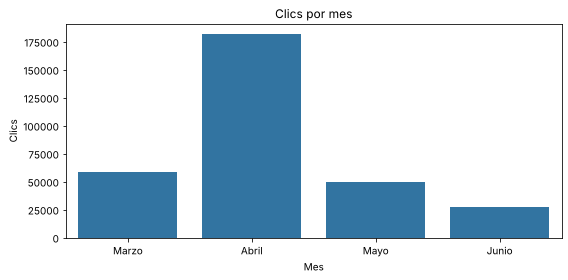

Marzo     58223
Abril    181700
Mayo      49817
Junio     27395
Name: count, dtype: int64

In [42]:
clics_mes = web["date_time"].dt.month.value_counts().sort_index()
clics_mes.index = ["Marzo", "Abril", "Mayo", "Junio"]
eda.barras_simples(clics_mes, "Clics por mes", "Mes", "Clics")
clics_mes

**➜ Qué nos llevamos para el proyecto:** abril concentra el 57 % de los clics: el test no tuvo un tráfico constante. Importa para la pregunta de la duración (E4).

> **➜ O que tiramos para o projecto:** Abril concentra 57 % dos cliques: o teste não teve tráfego constante. Importa para a pergunta da duração (E4).

**Cómo funciona**

1. `.dt.day_name()` da el nombre del día en inglés (Monday, Tuesday...).
2. `.loc[dias_semana]` pone los días en orden de lunes a domingo y luego se traducen.

**Por qué así:** sin ordenarlos con `.loc`, los días saldrían ordenados por número de clics, y el gráfico no se leería como una semana.

**Herramientas:** `.dt.day_name`, `value_counts`, `loc`, `barras_simples`.

**Dónde se vio en clase:** `.dt.day_name` → Semana 2 · fechas (self-guided); `value_counts`, `loc` → Semana 2 · 2.1 Pandas; `barras_simples` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. O `.dt.day_name()` dá o nome do dia em inglês (Monday, Tuesday...).
> 2. O `.loc[dias_semana]` põe os dias por ordem de segunda a domingo e depois traduzem-se.
>
> **Porquê assim:** sem os ordenar com `.loc`, os dias sairiam por número de cliques e o gráfico não se leria como uma semana.
>
> **Onde se deu nas aulas:** `.dt.day_name` → Semana 2 · fechas (self-guided); `value_counts`, `loc` → Semana 2 · 2.1 Pandas; `barras_simples` → funções nossas (tabela do guia, no início).

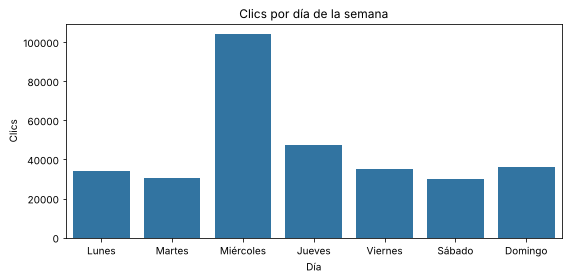

In [43]:
dias_semana = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
clics_dia = web["date_time"].dt.day_name().value_counts().loc[dias_semana]
clics_dia.index = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
eda.barras_simples(clics_dia, "Clics por día de la semana", "Día", "Clics")

**➜ Qué nos llevamos para el proyecto:** los miércoles triplican al resto de días: algo hacía entrar a los clientes ese día.

> **➜ O que tiramos para o projecto:** as quartas-feiras triplicam os outros dias: algo fazia os clientes entrar nesse dia.

**Cómo funciona**

1. `.dt.hour` saca la hora (0 a 23) y se cuentan los clics de cada hora.

**Por qué así:** completa la foto de cuándo se usa el proceso: el pico de las 11 refuerza la idea de un envío programado.

**Herramientas:** `.dt.hour`, `value_counts`.

**Dónde se vio en clase:** `.dt.hour` → Semana 2 · fechas (self-guided); `value_counts` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. O `.dt.hour` tira a hora (0 a 23) e contam-se os cliques de cada hora.
>
> **Porquê assim:** completa a fotografia de quando se usa o processo: o pico das 11h reforça a ideia de um envio programado.
>
> **Onde se deu nas aulas:** `.dt.hour` → Semana 2 · fechas (self-guided); `value_counts` → Semana 2 · 2.1 Pandas.

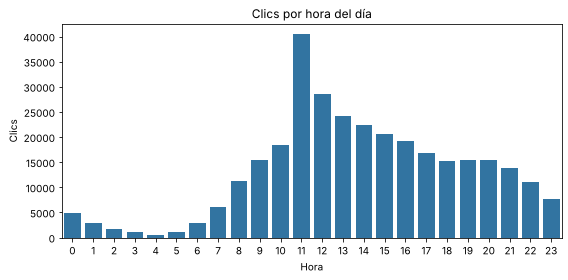

In [44]:
clics_hora = web["date_time"].dt.hour.value_counts().sort_index()
eda.barras_simples(clics_hora, "Clics por hora del día", "Hora", "Clics")

**➜ Qué nos llevamos para el proyecto:** pico a las 11 de la mañana, el doble que cualquier otra hora. Junto con los miércoles, apunta a un envío programado (hipótesis).

> **➜ O que tiramos para o projecto:** pico às 11h, o dobro de qualquer outra hora. Junto com as quartas-feiras, aponta para um envio programado (hipótese).

**Cómo funciona**

1. Cuenta los clics de cada día y enseña los 5 días con más.

**Por qué así:** comprueba si el pico de los miércoles viene de unos pocos días concretos. Así es: son miércoles seguidos.

**Herramientas:** `.dt.date`, `value_counts`, `head`.

**Dónde se vio en clase:** `.dt.date` → Semana 2 · fechas (self-guided); `value_counts`, `head` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. Conta os cliques de cada dia e mostra os 5 dias com mais.
>
> **Porquê assim:** verifica se o pico das quartas vem de poucos dias concretos. Vem: são quartas-feiras seguidas.
>
> **Onde se deu nas aulas:** `.dt.date` → Semana 2 · fechas (self-guided); `value_counts`, `head` → Semana 2 · 2.1 Pandas.

In [45]:
web["date_time"].dt.date.value_counts().head(5)

date_time
2017-03-29    32595
2017-04-05    25031
2017-04-12    18397
2017-04-19    11945
2017-03-30    11050
Name: count, dtype: int64

**➜ Qué nos llevamos para el proyecto:** los días con más clics son miércoles seguidos (29/3, 5/4, 12/4, 19/4). Para la evaluación del experimento: comprobar si esa campaña llegaba igual a los dos grupos.

> **➜ O que tiramos para o projecto:** os dias com mais cliques são quartas-feiras seguidas (29/3, 5/4, 12/4, 19/4). Para a avaliação: verificar se essa campanha chegava igual aos dois grupos.

**Lo que se ve:**
- **Abril** concentra el 57 % de los clics.
- Los **miércoles** tienen más del doble de clics que cualquier otro día (unos 104.000 frente a 47.000 del jueves y 30.000-36.000 del resto), con un pico a las **11 de la mañana**.
- Los cuatro días con más clics son **miércoles seguidos**: 29/3, 5/4, 12/4 y 19/4. El quinto es el jueves 30/3, el día después del primero.

Parece que algo empujaba a los clientes a entrar cada miércoles, por ejemplo un email o un aviso enviado ese día. Es una hipótesis: los datos no dicen qué pasó. Pero importa para la evaluación del experimento: si los clientes llegaban por una campaña, hay que comprobar que llegaba igual a los dos grupos.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** la lección de A/B testing avisa de los **factores externos** (campañas, fechas) que pueden sesgar un test. Por eso miramos mes, día de la semana y hora: si hubiera una campaña que llegara más a un grupo, la comparación no sería justa.

> **Porque o fizemos assim:** a lição de A/B testing avisa dos **factores externos** (campanhas, datas) que podem enviesar um teste. Por isso vemos mês, dia da semana e hora: se houvesse uma campanha que chegasse mais a um grupo, a comparação não seria justa.

**Pregunta posible 1.** ¿Por qué los días de la semana se ordenan con `.loc`?
<br>*Pergunta possível 1. Porque é que os dias da semana se ordenam com `.loc`?*

<details><summary>Respuesta / Resposta</summary>

Porque `value_counts()` ordena de más a menos clics y el gráfico no se leería como una semana. Con `.loc[lista de días]` salen de lunes a domingo.

> Porque o `value_counts()` ordena do maior para o menor número de cliques e o gráfico não se leria como uma semana. Com `.loc[lista de dias]` saem de segunda a domingo.

</details>

**Pregunta posible 2.** ¿Probáis que hubo una campaña los miércoles?
<br>*Pergunta possível 2. Provam que houve uma campanha às quartas?*

<details><summary>Respuesta / Resposta</summary>

No. Los datos enseñan picos los miércoles a las 11 en semanas seguidas, que es lo que haría un envío programado, pero no tenemos el calendario de campañas. Es una hipótesis y la pedimos en «datos que faltan».

> Não. Os dados mostram picos às quartas às 11 em semanas seguidas, que é o que faria um envio programado, mas não temos o calendário de campanhas. É uma hipótese.

</details>

## 2.7 Reparto entre grupos en el tiempo (E2)

En un buen test A/B, la proporción de clientes de cada grupo debería ser parecida todas las semanas.

**Cómo funciona**

1. Une los clics con el grupo de cada cliente.
2. Para cada fecha, `.dt.weekday` da el día de la semana como número (lunes = 0 ... domingo = 6). `pd.to_timedelta(..., unit="D")` convierte ese número en días y, al restarlo de la fecha, se llega al lunes de esa semana. `.dt.date` se queda solo con el día, sin la hora.
3. Cuenta los clientes distintos de cada grupo por semana (`groupby` + `nunique`) y pone los grupos en columnas (`unstack`).
4. Calcula el % de Test de cada semana.

**Por qué así:** en un buen test A/B, el reparto debería ser parecido todas las semanas. Se cuentan clientes y no clics para que un cliente con muchos clics no pese más.

**Herramientas:** `merge`, `.dt.weekday`, `pd.to_timedelta`, `.dt.date`, `groupby`, `nunique`, `unstack`.

**Dónde se vio en clase:** `merge`, `unstack` → Semana 2 · 2.3 Combinar; `.dt.weekday`, `pd.to_timedelta`, `.dt.date` → Semana 2 · fechas (self-guided); `groupby` → Semana 2 · 2.4 Agregar; `nunique` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. Junta os cliques ao grupo de cada cliente.
> 2. Para cada data, o `.dt.weekday` dá o dia da semana como número (segunda = 0 ... domingo = 6). O `pd.to_timedelta(..., unit="D")` transforma esse número em dias e, ao subtraí-lo da data, chega-se à segunda-feira dessa semana. O `.dt.date` fica só com o dia, sem a hora.
> 3. Conta os clientes distintos de cada grupo por semana (`groupby` + `nunique`) e põe os grupos em colunas (`unstack`).
> 4. Calcula a % de Test de cada semana.
>
> **Porquê assim:** num bom teste A/B, a repartição devia ser parecida todas as semanas. Contam-se clientes e não cliques para um cliente com muitos cliques não pesar mais.
>
> **Onde se deu nas aulas:** `merge`, `unstack` → Semana 2 · 2.3 Combinar; `.dt.weekday`, `pd.to_timedelta`, `.dt.date` → Semana 2 · fechas (self-guided); `groupby` → Semana 2 · 2.4 Agregar; `nunique` → Semana 2 · 2.1 Pandas.

In [46]:
web_grupo = web.merge(clientes[["client_id", "grupo"]], on="client_id")
# Lunes de cada semana: a cada fecha se le restan tantos días como su weekday (lunes = 0)
dias_desde_lunes = pd.to_timedelta(web_grupo["date_time"].dt.weekday, unit="D")
web_grupo["semana"] = (web_grupo["date_time"] - dias_desde_lunes).dt.date
semanas = web_grupo.groupby(["semana", "grupo"])["client_id"].nunique().unstack()
semanas["% Test"] = semanas["Test"] / (semanas["Test"] + semanas["Control"]) * 100
semanas

grupo,Control,Test,% Test
semana,,,
2017-03-13,223,266,54.4
2017-03-20,310,376,54.8
2017-03-27,5211,6504,55.5
2017-04-03,6590,7445,53.0
2017-04-10,4445,5775,56.5
2017-04-17,2856,3708,56.5
2017-04-24,1023,1320,56.3
2017-05-01,1037,1424,57.9
2017-05-08,1309,1273,49.3


**➜ Qué nos llevamos para el proyecto:** respuesta a E2: el reparto cambió a mitad del test. Hasta el 1 de mayo el Test es el 53-58 % de los clientes activos; desde el 8 de mayo, el 44-49 %.

> **➜ O que tiramos para o projecto:** resposta à E2: a repartição mudou a meio do teste. Até 1 de Maio o Test é 53-58 % dos clientes activos; a partir de 8 de Maio, 44-49 %.

**Cómo funciona**

1. Las etiquetas del eje X se escriben como día/mes (`strftime("%d/%m")`, lección de fechas) con una list comprehension: así son cortas y caben sin girarlas.
2. `plt.plot` dibuja una línea con el % de Test de cada semana.
3. Un segundo `plt.plot` con una lista de cincuentas (`[50] * len(semanas)`, la misma lista repetida tantas veces como semanas) dibuja una línea discontinua (`linestyle="--"`) de referencia en el 50 %.
4. El título explica que la línea discontinua es el 50 %.

**Por qué así:** una línea es la forma natural de enseñar cómo cambia algo en el tiempo. La referencia del 50 % hace evidente el salto de mayo.

**Herramientas:** list comprehension, `strftime`, listas, matplotlib (`figure`, `plot`, `title`, `xlabel`, `ylabel`, `show`).

**Dónde se vio en clase:** `strftime` → Semana 2 · fechas (self-guided); `figure`, `plot`, `title`, `xlabel`, `ylabel`, `show` → Gráficos de las clases (semanas 2 y 5).

> **Como funciona (português)**
>
> 1. As etiquetas do eixo X escrevem-se como dia/mês (`strftime("%d/%m")`, lição de datas) com uma list comprehension: assim são curtas e cabem sem as rodar.
> 2. O `plt.plot` desenha uma linha com a % de Test de cada semana.
> 3. Um segundo `plt.plot` com uma lista de cinquentas (`[50] * len(semanas)`, a mesma lista repetida tantas vezes como semanas) desenha uma linha tracejada (`linestyle="--"`) de referência nos 50 %.
> 4. O título explica que a linha tracejada é o 50 %.
>
> **Porquê assim:** uma linha é a forma natural de mostrar como algo muda no tempo. A referência dos 50 % torna evidente o salto de Maio.
>
> **Onde se deu nas aulas:** `strftime` → Semana 2 · fechas (self-guided); `figure`, `plot`, `title`, `xlabel`, `ylabel`, `show` → Gráficos de las clases (semanas 2 y 5).

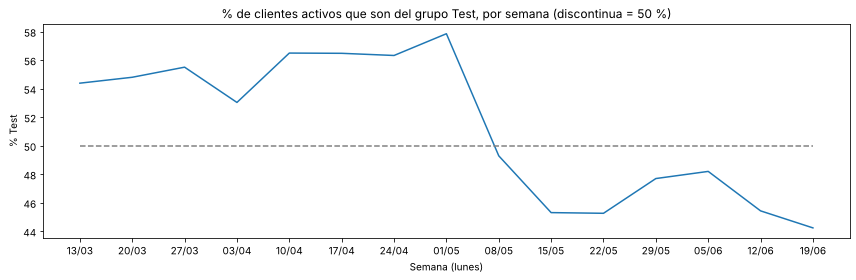

In [47]:
etiquetas = [fecha.strftime("%d/%m") for fecha in semanas.index]  # lunes de cada semana, como día/mes

plt.figure(figsize=(12, 4))
plt.plot(etiquetas, semanas["% Test"], color=eda.COLOR)
plt.plot(etiquetas, [50] * len(semanas), color="grey", linestyle="--")  # referencia: reparto igual
plt.title("% de clientes activos que son del grupo Test, por semana (discontinua = 50 %)")
plt.xlabel("Semana (lunes)")
plt.ylabel("% Test")
plt.tight_layout()
plt.show()

**➜ Qué nos llevamos para el proyecto:** gráfico clave para la diapositiva de evaluación del experimento: el salto de mayo es un posible sesgo que hay que explicar con honestidad.

> **➜ O que tiramos para o projecto:** gráfico-chave para o slide da avaliação da experiência: o salto de Maio é um possível enviesamento que é preciso explicar com honestidade.

**Lo que se ve:** hasta principios de mayo, el Test es el **53-58 %** de los clientes activos cada semana. Desde el 8 de mayo baja al **44-49 %**. El reparto **cambió a mitad del test**.

Hay que tenerlo en cuenta: los clientes de marzo y abril (los de los picos de los miércoles) pesan más en el Test. Si esos clientes eran distintos, la comparación podría estar algo sesgada. Lo discutiremos en la evaluación del experimento (Parte 4).

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** en un test A/B bien hecho, cada semana debería entrar más o menos la misma proporción de clientes en cada grupo. Lo comprobamos porque, si no, el grupo con más clientes en las «buenas semanas» saldría favorecido. Fue el hallazgo más importante para la evaluación del experimento (E2).

> **Porque o fizemos assim:** num teste A/B bem feito, todas as semanas devia entrar mais ou menos a mesma proporção de clientes em cada grupo. Verificámo-lo porque, se não, o grupo com mais clientes nas «boas semanas» sairia favorecido. Foi a descoberta mais importante para a avaliação do experimento (E2).

**Pregunta posible 1.** ¿Cómo agrupamos los clics por semanas?
<br>*Pergunta possível 1. Como agrupámos os cliques por semanas?*

<details><summary>Respuesta / Resposta</summary>

A cada fecha le restamos tantos días como su día de la semana (`.dt.weekday`, lunes = 0) con `pd.to_timedelta`, y así llegamos al lunes de esa semana. Todas las fechas de la misma semana quedan con el mismo lunes.

> A cada data subtraímos tantos dias como o dia da semana (`.dt.weekday`, segunda = 0) com `pd.to_timedelta`, e assim chegamos à segunda-feira dessa semana.

</details>

**Pregunta posible 2.** ¿Por qué contamos clientes distintos por semana y no clics?
<br>*Pergunta possível 2. Porque contamos clientes distintos por semana e não cliques?*

<details><summary>Respuesta / Resposta</summary>

Porque el reparto se hace por cliente. Un cliente con muchos clics no debe pesar más que uno con pocos.

> Porque a repartição faz-se por cliente. Um cliente com muitos cliques não deve pesar mais do que um com poucos.

</details>

## 2.7b ¿La ventaja del nuevo diseño se mantiene en el tiempo? (E4, E7)

Dos preguntas nuevas que salieron de las secciones 2.6 y 7:
- Si el Test pesa más en marzo y abril, ¿eso infla su ventaja? (E7)
- ¿La ventaja es igual al principio y al final del test? (E4)

Cada cliente se clasifica por el mes de su **primer clic**.

**Cómo funciona**

1. `groupby("client_id")["date_time"].min()` da la fecha del primer clic de cada cliente.
2. `map` la lleva a la tabla de clientes y `.dt.month` se queda con el mes.
3. `tasa_por_categoria` calcula la tasa de cada grupo por mes de inicio.

**Por qué así:** se usa el primer clic porque es cuando el cliente entra en el test; así cada cliente cuenta en un solo mes.

**Herramientas:** `groupby`, `min`, `map`, `.dt.month`.

**Dónde se vio en clase:** `groupby` → Semana 2 · 2.4 Agregar; `min` → Semana 2 · 2.1 Pandas; `map` → Semana 2 · 2.2 Limpieza; `.dt.month` → Semana 2 · fechas (self-guided).

> **Como funciona (português)**
>
> 1. O `groupby("client_id")["date_time"].min()` dá a data do primeiro clique de cada cliente.
> 2. O `map` leva-a para a tabela de clientes e o `.dt.month` fica com o mês.
> 3. O `tasa_por_categoria` calcula a taxa de cada grupo por mês de início.
>
> **Porquê assim:** usa-se o primeiro clique porque é quando o cliente entra no teste; assim cada cliente conta num só mês.
>
> **Onde se deu nas aulas:** `groupby` → Semana 2 · 2.4 Agregar; `min` → Semana 2 · 2.1 Pandas; `map` → Semana 2 · 2.2 Limpieza; `.dt.month` → Semana 2 · fechas (self-guided).

In [48]:
primer_clic = web.groupby("client_id")["date_time"].min()
por_cliente["mes_inicio"] = por_cliente["client_id"].map(primer_clic).dt.month
tabla_mes = eda.tasa_por_categoria(por_cliente, "mes_inicio")
tabla_mes.index = ["Marzo", "Abril", "Mayo", "Junio"]
tabla_mes

grupo,Control,Test,diferencia,clientes
Marzo,73.6,78.8,5.2,10577
Abril,66.4,69.1,2.7,29442
Mayo,57.8,60.5,2.8,6762
Junio,54.9,55.4,0.5,3707


**➜ Qué nos llevamos para el proyecto:** la ventaja del Test baja con el tiempo (+5,2 en marzo, +0,5 en junio). Respuesta parcial a E4: puede ser efecto novedad o falta de tiempo para terminar; hay que decir las dos posibilidades.

> **➜ O que tiramos para o projecto:** a vantagem do Test desce com o tempo (+5,2 em Março, +0,5 em Junho). Resposta parcial à E4: pode ser efeito novidade ou falta de tempo para terminar; é preciso dizer as duas hipóteses.

**Lo que se ve:** la ventaja del Test baja mes a mes (+5,2, +2,7, +2,8 y +0,5 puntos) y los dos grupos completan cada vez menos. Hay dos explicaciones posibles, y los datos no permiten elegir entre ellas:
- **Efecto novedad:** el nuevo diseño atrae al principio y luego pierde fuerza.
- **Menos tiempo para terminar:** quien empieza en junio solo tuvo unos días antes del 20/6 para completar; por eso todos completan menos ese mes.

**Cómo funciona**

1. `pd.Timestamp("2017-05-08")` crea la fecha en la que cambia el reparto entre grupos (vista en la sección 2.7).
2. Con `apply` y un `if` en una línea, cada cliente queda «Hasta el 7 de mayo» o «Desde el 8 de mayo» según su primer clic.
3. Se calcula la tasa por periodo y grupo.

**Por qué así:** si la ventaja dentro de cada periodo es menor que la total, parte de la ventaja viene de cuándo entró cada grupo y no del diseño. Es la comprobación más importante de esta parte para la evaluación del experimento.

**Herramientas:** `pd.Timestamp`, `apply`, `lambda`, comparación de fechas, `tasa_por_categoria`.

**Dónde se vio en clase:** `pd.Timestamp` → Semana 2 · fechas (self-guided); `apply` → Semana 2 · 2.2 Limpieza; `lambda` → Semana 1 · 1.5 Lambda; `tasa_por_categoria` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. O `pd.Timestamp("2017-05-08")` cria a data em que muda a repartição entre grupos (vista na secção 2.7).
> 2. Com `apply` e um `if` numa linha, cada cliente fica «Hasta el 7 de mayo» ou «Desde el 8 de mayo» conforme o primeiro clique.
> 3. Calcula-se a taxa por período e grupo.
>
> **Porquê assim:** se a vantagem dentro de cada período for menor do que a total, parte da vantagem vem de quando entrou cada grupo e não do design.
>
> **Onde se deu nas aulas:** `pd.Timestamp` → Semana 2 · fechas (self-guided); `apply` → Semana 2 · 2.2 Limpieza; `lambda` → Semana 1 · 1.5 Lambda; `tasa_por_categoria` → funções nossas (tabela do guia, no início).

In [49]:
fecha_cambio = pd.Timestamp("2017-05-08")  # semana en la que cambia el reparto entre grupos (sección 7)
por_cliente["periodo"] = por_cliente["client_id"].map(primer_clic).apply(
    lambda fecha: "Hasta el 7 de mayo" if fecha < fecha_cambio else "Desde el 8 de mayo")
tabla_periodo = eda.tasa_por_categoria(por_cliente, "periodo", ["Hasta el 7 de mayo", "Desde el 8 de mayo"])
tabla_periodo

grupo,Control,Test,diferencia,clientes
periodo,,,,
Hasta el 7 de mayo,67.9,71.2,3.3,41605
Desde el 8 de mayo,56.5,58.2,1.7,8883


**➜ Qué nos llevamos para el proyecto:** **importante para los contrastes:** dentro de cada periodo la ventaja es +3,3 y +1,7, menos que la total (+3,7). Parte de la ventaja puede venir del reparto desigual (E7). En la Parte 4 conviene contrastar también por periodo.

> **➜ O que tiramos para o projecto:** **importante para os testes:** dentro de cada período a vantagem é +3,3 e +1,7, menos do que a total (+3,7). Parte da vantagem pode vir da repartição desigual (E7). Na Parte 4 convém testar também por período.

**Lo que se ve:** dentro de cada periodo la ventaja es menor que la total (+3,3 y +1,7 frente a +3,7). Como el Test tiene más clientes en el primer periodo, cuando todos completan más, una parte de la ventaja total puede venir de **cuándo** entró cada grupo y no del diseño. Hay que tenerlo en cuenta en los contrastes (H1 y H2) y en la evaluación del experimento.

**Cómo funciona**

1. `.dt.day_name()` da el día de la semana del primer clic.
2. Con `apply` se clasifica en «Empieza en miércoles» u «Otro día» y se calcula la tasa.

**Por qué así:** comprueba si el pico de los miércoles (posible campaña) favorece a un grupo: si la ventaja del Test fuera muy distinta según el día, la campaña sesgaría el resultado.

**Herramientas:** `.dt.day_name`, `apply`, `lambda`, `tasa_por_categoria`.

**Dónde se vio en clase:** `.dt.day_name` → Semana 2 · fechas (self-guided); `apply` → Semana 2 · 2.2 Limpieza; `lambda` → Semana 1 · 1.5 Lambda; `tasa_por_categoria` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. O `.dt.day_name()` dá o dia da semana do primeiro clique.
> 2. Com `apply` classifica-se em «Empieza en miércoles» ou «Otro día» e calcula-se a taxa.
>
> **Porquê assim:** verifica se o pico das quartas (possível campanha) favorece um grupo: se a vantagem do Test fosse muito diferente conforme o dia, a campanha enviesaria o resultado.
>
> **Onde se deu nas aulas:** `.dt.day_name` → Semana 2 · fechas (self-guided); `apply` → Semana 2 · 2.2 Limpieza; `lambda` → Semana 1 · 1.5 Lambda; `tasa_por_categoria` → funções nossas (tabela do guia, no início).

In [50]:
por_cliente["dia_inicio"] = por_cliente["client_id"].map(primer_clic).dt.day_name().apply(
    lambda dia: "Empieza en miércoles" if dia == "Wednesday" else "Otro día")
eda.tasa_por_categoria(por_cliente, "dia_inicio", ["Empieza en miércoles", "Otro día"])

grupo,Control,Test,diferencia,clientes
dia_inicio,,,,
Empieza en miércoles,71.1,75.0,3.9,17453
Otro día,62.7,66.3,3.6,33035


**➜ Qué nos llevamos para el proyecto:** quien empieza en miércoles completa más, pero la ventaja del Test es la misma: el pico de los miércoles no sesga la comparación (B6b).

> **➜ O que tiramos para o projecto:** quem começa à quarta completa mais, mas a vantagem do Test é a mesma: o pico das quartas não enviesa a comparação (B6b).

**Lo que se ve:** quien empieza un miércoles completa más (71-75 % frente a 63-66 %), pero la ventaja del Test es casi la misma (+3,9 y +3,6). Si hubo una campaña los miércoles, no favoreció a un grupo sobre el otro.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** de las secciones 2.6 y 7 salieron dos preguntas nuevas: si el reparto desigual infla la ventaja (E7) y si la ventaja dura (E4). Cada cliente se clasifica por el mes de su **primer clic** para que cuente una sola vez.

> **Porque o fizemos assim:** das secções 2.6 e 7 saíram duas perguntas novas: se a repartição desigual inflaciona a vantagem (E7) e se a vantagem dura (E4). Cada cliente classifica-se pelo mês do **primeiro clique** para contar uma só vez.

**Pregunta posible 1.** ¿Por qué el corte es el 8 de mayo?
<br>*Pergunta possível 1. Porque é que o corte é a 8 de Maio?*

<details><summary>Respuesta / Resposta</summary>

Porque es la semana en la que el % de clientes del Test cae por debajo del 50 % (gráfico de la sección 2.7). Antes, el Test es el 53-58 %; desde esa semana, el 44-49 %.

> Porque é a semana em que a % de clientes do Test cai abaixo de 50 % (gráfico da secção 2.7).

</details>

**Pregunta posible 2.** ¿Qué es el «efecto novedad»?
<br>*Pergunta possível 2. O que é o «efeito novidade»?*

<details><summary>Respuesta / Resposta</summary>

Que un diseño nuevo funcione mejor al principio solo por ser nuevo (llama la atención) y luego pierda fuerza. Puede explicar que la ventaja baje de +5,2 a +0,5, pero también lo explica que en junio haya pocos clientes y poco tiempo para terminar. No podemos distinguir las dos.

> Um design novo funcionar melhor no início só por ser novo e depois perder força. Pode explicar a descida de +5,2 para +0,5, mas também a explica haver em Junho poucos clientes e pouco tempo para terminar. Não conseguimos distinguir as duas.

</details>

## 2.8 Comportamientos extremos

El percentil 99 de los clics por cliente es 21. ¿Quiénes hacen más de 20?

**Cómo funciona**

1. Filtra los clientes con más de 20 clics (el percentil 99 es 21).
2. Calcula qué % completa y cómo se reparten por grupo.
3. Cuenta también los clientes con más de 3 dispositivos.

**Por qué así:** antes de calcular los KPI hay que saber si los valores extremos son errores (que se quitarían) o clientes reales (que se mantienen). Que el 76 % complete indica que son reales.

**Herramientas:** filtros, `mean`, `value_counts`.

**Dónde se vio en clase:** `mean`, `value_counts` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. Filtra os clientes com mais de 20 cliques (o percentil 99 é 21).
> 2. Calcula que % completa e como se distribuem pelos grupos.
> 3. Conta também os clientes com mais de 3 aparelhos.
>
> **Porquê assim:** antes dos KPI é preciso saber se os valores extremos são erros (que se tiravam) ou clientes reais (que ficam). Como 76 % completam, são reais.
>
> **Onde se deu nas aulas:** `mean`, `value_counts` → Semana 2 · 2.1 Pandas.

In [51]:
extremos = por_cliente[por_cliente["clics"] > 20]
print("Clientes con más de 20 clics:", len(extremos))
print("Completan:", round(extremos["completo"].mean() * 100, 1), "%")
print(extremos["grupo"].value_counts())
print("\nClientes con más de 3 dispositivos:", (por_cliente["dispositivos"] > 3).sum())

Clientes con más de 20 clics: 571
Completan: 76.0 %
grupo
Test       349
Control    222
Name: count, dtype: int64

Clientes con más de 3 dispositivos: 192


**➜ Qué nos llevamos para el proyecto:** 571 clientes con recorridos muy largos; el 76 % completa, así que son reales y se mantienen. Hay más en el Test: lo revisaremos con la tasa de errores del día 3.

> **➜ O que tiramos para o projecto:** 571 clientes com percursos muito longos; 76 % completam, por isso são reais e ficam. Há mais no Test: revê-se com a taxa de erros do dia 3.

**Lo que se ve:** 571 clientes hacen más de 20 clics; el 76 % completa, así que no son abandonos sino recorridos largos con idas y vueltas. Hay más en el Test (349) que en el Control (222): el nuevo diseño podría provocar más vueltas atrás en algunos clientes. Lo mediremos con la **tasa de errores** el día 3.

**Decisión:** se mantienen. Son clientes reales con un recorrido largo, no errores de los datos.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** antes de calcular los KPI había que decidir si los clientes con muchísimos clics son errores (se quitarían) o clientes reales (se quedan). Usamos el percentil 99 como corte porque marca el 1 % más extremo sin inventar un número.

> **Porque o fizemos assim:** antes de calcular os KPI era preciso decidir se os clientes com muitíssimos cliques são erros (tirar-se-iam) ou clientes reais (ficam). Usámos o percentil 99 como corte porque marca o 1 % mais extremo sem inventar um número.

**Pregunta posible 1.** ¿Por qué no quitamos a los 571 clientes con más de 20 clics?
<br>*Pergunta possível 1. Porque não tirámos os 571 clientes com mais de 20 cliques?*

<details><summary>Respuesta / Resposta</summary>

Porque el 76 % completa el proceso: son clientes reales que dan muchas vueltas, no errores de registro. Quitarlos escondería justo el problema que luego mide la tasa de errores.

> Porque 76 % concluem o processo: são clientes reais que dão muitas voltas, não erros de registo. Tirá-los esconderia justamente o problema que a taxa de erros mede depois.

</details>

## 2.9 Resumen

| Pregunta | Respuesta (descriptiva) |
|---|---|
| ¿El saldo influye? | Apenas. El Test gana en todos los cuartiles (+3,5 a +4 puntos) |
| ¿El uso de la web influye? | Un poco: quien entra más completa más. El Test gana en todos los niveles |
| ¿La edad influye? | Sí: los de 60+ completan menos. El nuevo diseño ayuda más a los menores de 30 (+7) y a los de 60+ (+5) |
| ¿El género influye? | Las mujeres completan 3 puntos menos en los dos grupos; el nuevo diseño no cambia esa diferencia |
| ¿Volver es abandonar? | No: quien vuelve otro día completa más (73 %) |
| ¿Cuándo se usa? | Sobre todo en abril, los miércoles a las 11, con picos en miércoles seguidos |
| ¿El reparto fue igual en el tiempo? | No: 55 % Test hasta mayo, 46 % después |
| ¿La ventaja se mantiene en el tiempo? | Baja de +5,2 (marzo) a +0,5 (junio); dentro de cada periodo es menor que la total (+3,3 y +1,7) |
| ¿Hay extremos? | 571 clientes con más de 20 clics; más en el Test |

**Idea principal:** la ventaja del nuevo diseño aparece **en todos los tipos de cliente**: por saldo, por uso de la web, por edad y por género. Eso hace el resultado más sólido. Pero la ventaja baja con el tiempo y parte puede venir del reparto desigual entre grupos: falta comprobar con contrastes (Parte 4) que no es casualidad y cuánto queda al separar por periodo.

**Para el día 3 (KPI):** el tiempo por paso y la tasa de errores; ver si los 571 clientes con muchos clics son errores (pasos hacia atrás).

<a id="parte-3"></a>

# Parte 3 · KPI del test A/B (semana 5, día 3)

**Pregunta del día:** ¿qué indicadores dicen si el nuevo diseño funciona mejor, y cómo se comparan Test y Control?

El enunciado pide al menos tres KPI. Añadimos dos más que salen de [`preguntas.md`](preguntas.md):

| KPI | Definición | Pregunta |
|---|---|---|
| **Tasa de finalización** | % de clientes que llegan a `confirm` al menos una vez (D1) | K1, K2 |
| **Tiempo en cada paso** | Segundos entre el clic en un paso y el clic siguiente de la misma visita (D4) | K3 |
| **Tasa de errores** | Pasos hacia atrás / total de pasos (D3, fórmula del enunciado) | K4, K8 |
| Tiempo total (extra) | Minutos desde el primer `start` hasta el primer `confirm` | K5 |
| Clientes con algún error (extra) | % de clientes que vuelven atrás al menos una vez | K4 |

*Todo es descriptivo: si las diferencias son significativas se comprueba con los contrastes de la Parte 4.*

#### Para entenderlo · ¿Qué es un KPI y por qué no basta con uno?

Un KPI (indicador clave) es un número que resume si se cumple el objetivo. Con uno solo no basta: el nuevo diseño puede hacer que completen más clientes y, a la vez, que se equivoquen más o tarden más. Por eso se miran tres (y dos extra) y se dice en cuál gana cada grupo.

Dos detalles cambian los números:

- **El denominador.** La tasa de finalización se calcula sobre todos los clientes del grupo (D1), no solo sobre los que empezaron. Con otro denominador sale otra tasa, así que hay que decir siempre cuál se usa.
- **Media o mediana.** Los tiempos tienen colas muy largas (alguien deja la página abierta media hora). La media se va hacia esos casos; la mediana dice cuánto tarda el cliente típico. Por eso en los tiempos se usa la mediana.

> **Para perceber (português).** Um KPI (indicador-chave) é um número que resume se o objectivo se cumpre. Um só não chega: o novo design pode fazer com que mais clientes concluam e, ao mesmo tempo, que se enganem mais ou demorem mais. Por isso olha-se para três (mais dois extra) e diz-se em qual ganha cada grupo. Dois pormenores mudam os números: o **denominador** (a taxa de conclusão calcula-se sobre todos os clientes do grupo, não só sobre os que começaram) e **média ou mediana** (os tempos têm caudas muito longas; a média vai atrás desses casos e a mediana diz quanto demora o cliente típico, por isso nos tempos usa-se a mediana).

## 3.1 Preparar los clics para los KPI

**Cómo funciona**

1. Lee las tablas limpias de la Parte 1 (`parse_dates` convierte `date_time` en fecha al leer).
2. `preparar_pasos` (en `src/kpis.py`) une a cada clic el grupo del cliente con `merge` y ordena por cliente, visita, hora y número de paso.
3. Pasa las columnas a listas y las recorre con un bucle `for` y un índice `i`. Para cada clic mira el siguiente (`i + 1`): si es del mismo cliente y de la misma visita, la resta de las dos horas es el tiempo que el cliente pasó en este paso, y `.total_seconds()` la pasa a segundos. Si no, el tiempo queda vacío (`None`): es el último clic de la visita.
4. Hace lo mismo con el clic anterior (`i - 1`) y guarda su número de paso en `paso_anterior`. Si el paso actual es menor que el anterior, el cliente ha ido hacia atrás: `es_error = True`. Si es igual, ha repetido el paso: `es_repeticion = True`.
5. Se enseñan las 8 primeras filas para ver un recorrido real.

**Por qué así:** los tres KPI salen de la misma tabla, así que se prepara una vez y se reutiliza. Se compara con la misma visita porque el tiempo entre dos visitas distintas (días después) no es tiempo en el paso. Se ordena también por número de paso porque hay 528 clics con la misma hora exacta (problema visto en la Parte 1). Se recorren listas y no la tabla con `.iloc` porque es mucho más rápido: unos segundos para los 317.135 clics.

**Herramientas:** `pd.read_csv`, `merge`, `sort_values`, `list`, bucle `for` con `range` y `len`, `if` con `and`, `append`, `.total_seconds()`, comparaciones que dan `True`/`False`.

**Dónde se vio en clase:** `pd.read_csv`, `sort_values` → Semana 2 · 2.1 Pandas; `merge` → Semana 2 · 2.3 Combinar; `list`, `len`, `and`, `append`, `True`, `False` → Semana 1 · 1.1 Estructuras de datos; `for`, `range`, `if` → Semana 1 · 1.2 Control de flujo; `.total_seconds()` → Semana 2 · fechas (self-guided).

> **Como funciona (português)**
>
> 1. Lê as tabelas limpas da Parte 1 (o `parse_dates` converte o `date_time` em data ao ler).
> 2. O `preparar_pasos` (em `src/kpis.py`) junta a cada clique o grupo do cliente com `merge` e ordena por cliente, visita, hora e número do passo.
> 3. Passa as colunas a listas e percorre-as com um ciclo `for` e um índice `i`. Para cada clique olha para o seguinte (`i + 1`): se for do mesmo cliente e da mesma visita, a subtracção das duas horas é o tempo que o cliente passou neste passo, e o `.total_seconds()` passa-a a segundos. Se não, o tempo fica vazio (`None`): é o último clique da visita.
> 4. Faz o mesmo com o clique anterior (`i - 1`) e guarda o número do passo em `paso_anterior`. Se o passo actual for menor do que o anterior, o cliente voltou atrás: `es_error = True`. Se for igual, repetiu o passo: `es_repeticion = True`.
> 5. Mostram-se as 8 primeiras linhas para ver um percurso real.
>
> **Porquê assim:** os três KPI saem da mesma tabela, por isso prepara-se uma vez e reutiliza-se. Compara-se com a mesma visita porque o tempo entre duas visitas diferentes (dias depois) não é tempo no passo. Ordena-se também pelo número do passo porque há 528 cliques com a mesma hora exacta (problema visto na Parte 1). Percorrem-se listas e não a tabela com `.iloc` porque é muito mais rápido: uns segundos para os 317.135 cliques.
>
> **Onde se deu nas aulas:** `pd.read_csv`, `sort_values` → Semana 2 · 2.1 Pandas; `merge` → Semana 2 · 2.3 Combinar; `list`, `len`, `and`, `append`, `True`, `False` → Semana 1 · 1.1 Estructuras de datos; `for`, `range`, `if` → Semana 1 · 1.2 Control de flujo; `.total_seconds()` → Semana 2 · fechas (self-guided).

In [52]:
clientes = pd.read_csv(f"{config.RUTA_CLEAN}/clientes.csv")
web = pd.read_csv(f"{config.RUTA_CLEAN}/web.csv", parse_dates=["date_time"])

pasos = kpis.preparar_pasos(web, clientes)
pasos[["client_id", "visit_id", "process_step", "date_time", "tiempo_seg", "paso_anterior", "es_error", "es_repeticion"]].head(8)

,client_id,visit_id,process_step,date_time,tiempo_seg,paso_anterior,es_error,es_repeticion
0,555,637149525_38041617439_716659,start,2017-04-15 12:57:56,7.0,NaN,False,False
1,555,637149525_38041617439_716659,step_1,2017-04-15 12:58:03,32.0,0.0,False,False
2,555,637149525_38041617439_716659,step_2,2017-04-15 12:58:35,99.0,1.0,False,False
3,555,637149525_38041617439_716659,step_3,2017-04-15 13:00:14,20.0,2.0,False,False
4,555,637149525_38041617439_716659,confirm,2017-04-15 13:00:34,NaN,3.0,False,False
5,647,40369564_40101682850_311847,start,2017-04-12 15:41:28,7.0,NaN,False,False
6,647,40369564_40101682850_311847,step_1,2017-04-12 15:41:35,18.0,0.0,False,False
7,647,40369564_40101682850_311847,step_2,2017-04-12 15:41:53,189.0,1.0,False,False


**➜ Qué nos llevamos para el proyecto:** una sola tabla con los 317.135 clics limpios, su grupo, el tiempo en cada paso y si es un paso atrás. De aquí salen los tres KPI y el CSV para Tableau.

> **➜ O que tiramos para o projecto:** uma só tabela com os 317.135 cliques limpos, o grupo, o tempo em cada passo e se é um passo atrás. Daqui saem os três KPI e o CSV para o Tableau.

En la tabla se ve el recorrido de un cliente: en cada fila, cuánto tardó en ese paso (`tiempo_seg`), de qué paso venía y si fue un paso hacia atrás (`es_error`) o el mismo paso repetido (`es_repeticion`).

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** los tres KPI salen de la misma tabla de clics con su grupo, su tiempo y si es un paso atrás. Se prepara **una vez** (`preparar_pasos`) y se reutiliza en el 03, el 04 y el 05, para que todos digan lo mismo. Usamos un bucle `for` que mira el clic anterior y el siguiente porque es lo que se vio en clase; `shift`, que lo haría en una línea, no se vio.

> **Porque o fizemos assim:** os três KPI saem da mesma tabela de cliques com o grupo, o tempo e se é um passo atrás. Prepara-se **uma vez** (`preparar_pasos`) e reutiliza-se no 03, no 04 e no 05, para todos dizerem o mesmo. Usamos um ciclo `for` que olha para o clique anterior e o seguinte porque foi o que se deu nas aulas; o `shift`, que o faria numa linha, não foi dado.

**Pregunta posible 1.** ¿Por qué el tiempo solo cuenta si el clic siguiente es de la misma visita?
<br>*Pergunta possível 1. Porque é que o tempo só conta se o clique seguinte for da mesma visita?*

<details><summary>Respuesta / Resposta</summary>

Porque entre dos visitas el cliente se fue: la diferencia de horas incluiría minutos, horas o días fuera del proceso. Dentro de la misma visita, el tiempo hasta el clic siguiente es el tiempo en la pantalla.

> Porque entre duas visitas o cliente saiu: a diferença de horas incluiria minutos, horas ou dias fora do processo.

</details>

**Pregunta posible 2.** ¿Por qué las columnas se pasan a listas antes del bucle?
<br>*Pergunta possível 2. Porque é que as colunas passam a listas antes do ciclo?*

<details><summary>Respuesta / Resposta</summary>

Porque recorrer una lista es mucho más rápido que pedir cada fila a la tabla con `.iloc`. Con 317.135 clics, la diferencia es de segundos a minutos.

> Porque percorrer uma lista é muito mais rápido do que pedir cada linha à tabela com `.iloc`.

</details>

## 3.2 KPI 1 · Tasa de finalización y embudo

**Cómo funciona**

1. `embudo` cuenta, para cada paso y cada grupo, cuántos clientes distintos llegan a él (`nunique`), y `unstack` pone los grupos en columnas: una fila por paso, una columna por grupo.
2. `value_counts` da el total de clientes de cada grupo (una Serie con Control y Test). Al dividir la tabla entre esa Serie, pandas divide cada columna entre el total de su grupo, porque empareja los nombres de las columnas con los de la Serie. Después multiplica por 100.
3. `.loc[orden_pasos, ["Control", "Test"]]` ordena los pasos como en `config.py` y los grupos.
4. En el notebook se añade la diferencia Test − Control en puntos.

**Por qué así:** el KPI 1 (tasa de finalización) es la última fila del embudo: el % que llega a `confirm` (definición D1). Las filas anteriores dicen en qué paso empieza la ventaja. Se divide entre todos los clientes del grupo, también los que no hicieron ningún clic, para no inflar la tasa.

**Herramientas:** `groupby`, `nunique`, `unstack`, `value_counts`, división entre una tabla y una Serie, `loc`.

**Dónde se vio en clase:** `groupby` → Semana 2 · 2.4 Agregar; `nunique`, `value_counts`, `loc` → Semana 2 · 2.1 Pandas; `unstack` → Semana 2 · 2.3 Combinar.

> **Como funciona (português)**
>
> 1. O `embudo` conta, para cada passo e cada grupo, quantos clientes diferentes lá chegam (`nunique`), e o `unstack` põe os grupos em colunas: uma linha por passo, uma coluna por grupo.
> 2. O `value_counts` dá o total de clientes de cada grupo (uma Série com Control e Test). Ao dividir a tabela por essa Série, o pandas divide cada coluna pelo total do seu grupo, porque emparelha os nomes das colunas com os da Série. Depois multiplica por 100.
> 3. O `.loc[orden_pasos, ["Control", "Test"]]` ordena os passos como no `config.py` e os grupos.
> 4. No notebook acrescenta-se a diferença Test − Control em pontos.
>
> **Porquê assim:** o KPI 1 (taxa de conclusão) é a última linha do funil: a % que chega ao `confirm` (definição D1). As linhas anteriores dizem em que passo começa a vantagem. Divide-se por todos os clientes do grupo, também os que não fizeram nenhum clique, para não inflacionar a taxa.
>
> **Onde se deu nas aulas:** `groupby` → Semana 2 · 2.4 Agregar; `nunique`, `value_counts`, `loc` → Semana 2 · 2.1 Pandas; `unstack` → Semana 2 · 2.3 Combinar.

In [53]:
tabla_embudo = kpis.embudo(pasos, clientes, ORDEN_PASOS)
tabla_embudo["diferencia"] = tabla_embudo["Test"] - tabla_embudo["Control"]
tabla_embudo

grupo,Control,Test,diferencia
process_step,,,
start,99.4,98.9,-0.5
step_1,85.6,90.0,4.4
step_2,79.2,82.5,3.3
step_3,74.0,77.4,3.4
confirm,65.6,69.3,3.7


**➜ Qué nos llevamos para el proyecto:** **KPI 1:** completa el 69,3 % del Test frente al 65,6 % del Control (+3,7 puntos). La ventaja aparece en `step_1` (+4,4) y se mantiene hasta el final. Responde a K1 y K2; si es significativa, se contrasta el día 4 (H1).

> **➜ O que tiramos para o projecto:** **KPI 1:** conclui 69,3 % do Test contra 65,6 % do Control (+3,7 pontos). A vantagem aparece no `step_1` (+4,4) e mantém-se até ao fim. Responde à K1 e à K2; se é significativa, testa-se no dia 4 (H1).

**Cómo funciona**

1. `barras_por_grupo` (en `src/eda.py`) dibuja una barra por grupo en cada paso. El parámetro `etiqueta_y` cambia el texto del eje Y (aquí «% de clientes»).

**Por qué así:** es la misma función de los gráficos de la Parte 2, así todos los gráficos del proyecto tienen el mismo estilo. `etiqueta_y` tiene un valor por defecto, así que los gráficos de la Parte 2 no cambian.

**Herramientas:** funciones con parámetros por defecto, seaborn `barplot`.

**Dónde se vio en clase:** `barplot` → Semana 2 · EDA básico (self-guided).

> **Como funciona (português)**
>
> 1. O `barras_por_grupo` (em `src/eda.py`) desenha uma barra por grupo em cada passo. O parâmetro `etiqueta_y` muda o texto do eixo Y (aqui «% de clientes»).
>
> **Porquê assim:** é a mesma função dos gráficos da Parte 2, assim todos os gráficos do projecto têm o mesmo estilo. O `etiqueta_y` tem um valor por omissão, por isso os gráficos da Parte 2 não mudam.
>
> **Onde se deu nas aulas:** `barplot` → Semana 2 · EDA básico (self-guided).

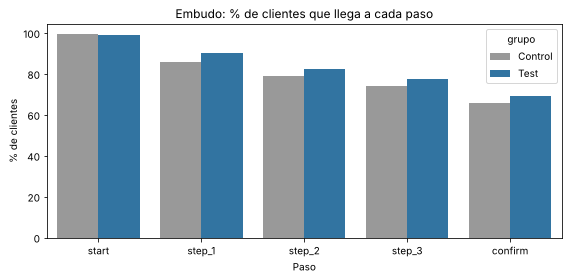

In [54]:
eda.barras_por_grupo(tabla_embudo, "Embudo: % de clientes que llega a cada paso", "Paso", etiqueta_y="% de clientes")

**➜ Qué nos llevamos para el proyecto:** gráfico del embudo para la diapositiva del KPI 1.

> **➜ O que tiramos para o projecto:** gráfico do funil para o slide do KPI 1.

**Lo que se ve:** casi todos empiezan (99 %). Desde `step_1` el Test va siempre por delante, entre 3,3 y 4,4 puntos, y la ventaja se mantiene hasta el final: **69,3 % frente a 65,6 %** completan el proceso.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** es el KPI principal del enunciado. Lo calculamos como **embudo** (qué % llega a cada paso) porque, además de la tasa final, dice **en qué paso** aparece la ventaja del nuevo diseño.

> **Porque o fizemos assim:** é o KPI principal do enunciado. Calculamo-lo como **funil** (que % chega a cada passo) porque, além da taxa final, diz **em que passo** aparece a vantagem do novo design.

**Pregunta posible 1.** ¿Por qué dividimos entre el total del grupo y no entre los que llegaron al paso anterior?
<br>*Pergunta possível 1. Porque dividimos pelo total do grupo e não pelos que chegaram ao passo anterior?*

<details><summary>Respuesta / Resposta</summary>

Porque así la última barra del embudo es directamente la tasa de finalización (69,3 % y 65,6 %) y todas las barras se comparan con la misma base. La conversión paso a paso sería otra lectura, útil pero distinta.

> Porque assim a última barra do funil é directamente a taxa de conclusão e todas as barras se comparam com a mesma base.

</details>

**Pregunta posible 2.** ¿Por qué `start` no llega al 100 %?
<br>*Pergunta possível 2. Porque é que o `start` não chega a 100 %?*

<details><summary>Respuesta / Resposta</summary>

Porque unos pocos clientes no tienen `start` registrado (registros incompletos del problema 13 de la Parte 1). Son alrededor del 1 % (0,6 % en el Control y 1,1 % en el Test) y no cambian la conclusión.

> Porque uns poucos clientes não têm `start` registado (registos incompletos do problema 13). São cerca de 1 % e não mudam a conclusão.

</details>

## 3.3 KPI 2 · Tiempo en cada paso

El tiempo de un paso es lo que pasa hasta el clic siguiente de la misma visita. Se quitan los tiempos de más de 30 minutos (`config.py`): son pausas, no tiempo en el paso.

**Cómo funciona**

1. Lee el límite de 1.800 segundos (30 minutos) de `config.py` (`config.LIMITE_TIEMPO_SEG`).
2. Calcula qué % de los clics supera ese límite: la media de una columna de `True`/`False` es la proporción de `True`.
3. `describe()` resume todos los tiempos: mínimo, cuartiles, media y máximo.

**Por qué así:** antes de quitar valores hay que ver cuántos son. Si fueran muchos, el límite estaría mal elegido. El límite va en `config.py` para poder cambiarlo sin tocar el código.

**Herramientas:** `describe`, `mean` sobre booleanos, variables de un módulo.

**Dónde se vio en clase:** `describe`, `mean` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. Lê o limite de 1.800 segundos (30 minutos) do `config.py` (`config.LIMITE_TIEMPO_SEG`).
> 2. Calcula que % dos cliques passa esse limite: a média de uma coluna de `True`/`False` é a proporção de `True`.
> 3. O `describe()` resume todos os tempos: mínimo, quartis, média e máximo.
>
> **Porquê assim:** antes de tirar valores é preciso ver quantos são. Se fossem muitos, o limite estaria mal escolhido. O limite está no `config.py` para se poder mudar sem mexer no código.
>
> **Onde se deu nas aulas:** `describe`, `mean` → Semana 2 · 2.1 Pandas.

In [55]:
limite = config.LIMITE_TIEMPO_SEG
print("Tiempos de más de 30 minutos:", round((pasos["tiempo_seg"] > limite).mean() * 100, 2), "% de los clics")
print(pasos["tiempo_seg"].describe())

Tiempos de más de 30 minutos: 0.11 % de los clics
count   247708.0
mean        83.9
std        214.1
min          0.0
25%         13.0
50%         36.0
75%         82.0
max      40235.0
Name: tiempo_seg, dtype: float64


**➜ Qué nos llevamos para el proyecto:** solo el 0,11 % de los clics pasa de 30 minutos: quitarlos no cambia nada importante. La mediana (36 s) es mucho menor que la media (84 s), así que usaremos la mediana.

> **➜ O que tiramos para o projecto:** só 0,11 % dos cliques passam de 30 minutos: tirá-los não muda nada de importante. A mediana (36 s) é muito menor do que a média (84 s), por isso usa-se a mediana.

**Cómo funciona**

1. `tiempo_por_paso` quita los clics de `confirm` (es el final, no hay paso siguiente) y los tiempos de más de 30 minutos.
2. Calcula los segundos por paso y grupo con `groupby` y `agg(medida)`: con `"median"` da la mediana y con `"mean"`, la media. `unstack` pone los grupos en columnas.
3. Se llama dos veces, una para cada medida, y `.loc[ORDEN_PASOS[:-1]]` ordena los pasos de `start` a `step_3` (todos menos el último).
4. `display` enseña la tabla de medianas; la de medias sale al final de la celda.

**Por qué así:** la mediana es la medida principal porque no la mueven los pocos tiempos muy largos; la media se enseña al lado para ver si cuentan lo mismo.

**Herramientas:** filtros con `&`, `groupby`, `agg`, `unstack`, `loc`, slicing de listas, `display`.

**Dónde se vio en clase:** `&`, `loc` → Semana 2 · 2.1 Pandas; `groupby`, `agg` → Semana 2 · 2.4 Agregar; `unstack` → Semana 2 · 2.3 Combinar.

> **Como funciona (português)**
>
> 1. O `tiempo_por_paso` tira os cliques de `confirm` (é o fim, não há passo seguinte) e os tempos de mais de 30 minutos.
> 2. Calcula os segundos por passo e grupo com `groupby` e `agg(medida)`: com `"median"` dá a mediana e com `"mean"`, a média. O `unstack` põe os grupos em colunas.
> 3. Chama-se duas vezes, uma para cada medida, e o `.loc[ORDEN_PASOS[:-1]]` ordena os passos de `start` a `step_3` (todos menos o último).
> 4. O `display` mostra a tabela das medianas; a das médias aparece no fim da célula.
>
> **Porquê assim:** a mediana é a medida principal porque não a mexem os poucos tempos muito longos; a média mostra-se ao lado para ver se contam o mesmo.
>
> **Onde se deu nas aulas:** `&`, `loc` → Semana 2 · 2.1 Pandas; `groupby`, `agg` → Semana 2 · 2.4 Agregar; `unstack` → Semana 2 · 2.3 Combinar.

In [56]:
medianas = kpis.tiempo_por_paso(pasos, limite, "median").loc[ORDEN_PASOS[:-1]]
medias = kpis.tiempo_por_paso(pasos, limite, "mean").loc[ORDEN_PASOS[:-1]]
print("Mediana de segundos en cada paso:")
display(medianas)
print("Media de segundos en cada paso:")
medias

Mediana de segundos en cada paso:


grupo,Control,Test
process_step,,
start,20.0,14.0
step_1,20.0,27.0
step_2,64.0,61.0
step_3,72.0,57.0


Media de segundos en cada paso:


grupo,Control,Test
process_step,,
start,60.9,56.3
step_1,47.5,58.4
step_2,90.0,88.1
step_3,132.9,124.8


**➜ Qué nos llevamos para el proyecto:** **KPI 2:** el Test es más rápido en `start` (14 s frente a 20) y en `step_3` (57 frente a 72), pero **más lento en `step_1`** (27 frente a 20). La media cuenta lo mismo. Responde a K3: `step_1` es el paso a vigilar.

> **➜ O que tiramos para o projecto:** **KPI 2:** o Test é mais rápido no `start` (14 s contra 20) e no `step_3` (57 contra 72), mas **mais lento no `step_1`** (27 contra 20). A média conta o mesmo. Responde à K3: o `step_1` é o passo a vigiar.

**Cómo funciona**

1. Dibuja las medianas por paso y grupo con `barras_por_grupo`, con «Segundos (mediana)» en el eje Y.

**Por qué así:** un gráfico de barras agrupadas compara los dos grupos paso a paso de un vistazo; es el gráfico para la diapositiva del KPI 2.

**Herramientas:** `barras_por_grupo`.

**Dónde se vio en clase:** `barras_por_grupo` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. Desenha as medianas por passo e grupo com o `barras_por_grupo`, com «Segundos (mediana)» no eixo Y.
>
> **Porquê assim:** um gráfico de barras agrupadas compara os dois grupos passo a passo de relance; é o gráfico para o slide do KPI 2.
>
> **Onde se deu nas aulas:** `barras_por_grupo` → funções nossas (tabela do guia, no início).

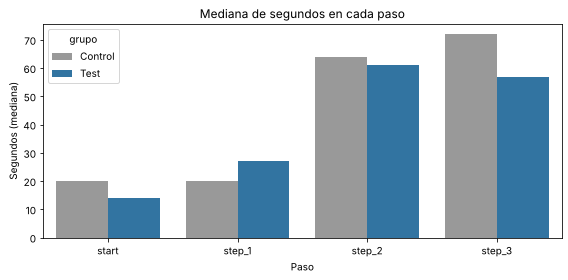

In [57]:
eda.barras_por_grupo(medianas, "Mediana de segundos en cada paso", "Paso", etiqueta_y="Segundos (mediana)")

**➜ Qué nos llevamos para el proyecto:** gráfico del KPI 2 para la presentación.

> **➜ O que tiramos para o projecto:** gráfico do KPI 2 para a apresentação.

**Lo que se ve (medianas):**
- El Test es más rápido en `start` (14 s frente a 20) y en `step_3` (57 frente a 72).
- Es **más lento en `step_1`** (27 s frente a 20): es el único paso donde el nuevo diseño hace tardar más.
- En `step_2` son casi iguales.

Se usa la mediana porque unos pocos tiempos largos suben mucho la media.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** el tiempo dice si el nuevo diseño es más fácil (menos tiempo) o más confuso (más tiempo) en cada pantalla. Usamos la **mediana** porque unos pocos tiempos larguísimos disparan la media, y quitamos las pausas de más de 30 minutos (solo el 0,11 % de los clics).

> **Porque o fizemos assim:** o tempo diz se o novo design é mais fácil (menos tempo) ou mais confuso (mais tempo) em cada ecrã. Usamos a **mediana** porque uns poucos tempos enormes disparam a média, e tiramos as pausas de mais de 30 minutos (só 0,11 % dos cliques).

**Pregunta posible 1.** ¿Por qué 30 minutos y no otro límite?
<br>*Pergunta possível 1. Porquê 30 minutos e não outro limite?*

<details><summary>Respuesta / Resposta</summary>

Es un límite razonable para una sesión web y afecta a muy pocos clics (0,11 %), así que la conclusión no depende de él. Está en `config.py` para poder cambiarlo y comprobarlo.

> É um limite razoável para uma sessão web e afecta muito poucos cliques (0,11 %), por isso a conclusão não depende dele. Está no `config.py` para se poder mudar.

</details>

**Pregunta posible 2.** ¿Por qué no hay tiempo para `confirm`?
<br>*Pergunta possível 2. Porque não há tempo para o `confirm`?*

<details><summary>Respuesta / Resposta</summary>

Porque es el último paso: no hay un clic siguiente con el que medir cuánto tiempo pasó el cliente en esa pantalla.

> Porque é o último passo: não há clique seguinte com que medir quanto tempo o cliente passou nesse ecrã.

</details>

## 3.4 KPI 3 · Tasa de errores

**Cómo funciona**

1. `tasa_errores` agrupa por grupo y cuenta por separado: todos los clics (`size`), los errores (`sum` de `es_error`, porque `True` vale 1) y las repeticiones. Junta los tres resultados con `pd.DataFrame` y un diccionario.
2. Tasa de errores = errores / pasos × 100 (fórmula del enunciado).
3. Para el % de clientes con algún error: `groupby(["grupo", "client_id"])["es_error"].any()` da `True` si el cliente tiene al menos un error; `reset_index` lo vuelve a convertir en tabla y la media por grupo es el %.

**Por qué así:** la tasa por clics dice cuántos pasos son errores; el % por cliente dice a cuánta gente afecta. Se dan las dos porque un pequeño grupo de clientes con muchos errores podría subir la primera sin que el problema sea general.

**Herramientas:** `groupby`, `size`, `sum`, `any`, `mean`, `pd.DataFrame` con un diccionario, `reset_index`.

**Dónde se vio en clase:** `groupby`, `size` → Semana 2 · 2.4 Agregar; `sum`, `mean`, `pd.DataFrame` → Semana 2 · 2.1 Pandas; `any`, `reset_index` → Semana 2 · 2.2 Limpieza.

> **Como funciona (português)**
>
> 1. O `tasa_errores` agrupa por grupo e conta em separado: todos os cliques (`size`), os erros (`sum` de `es_error`, porque `True` vale 1) e as repetições. Junta os três resultados com `pd.DataFrame` e um dicionário.
> 2. Taxa de erros = erros / passos × 100 (fórmula do enunciado).
> 3. Para a % de clientes com algum erro: o `groupby(["grupo", "client_id"])["es_error"].any()` dá `True` se o cliente tiver pelo menos um erro; o `reset_index` volta a pô-lo em tabela e a média por grupo é a %.
>
> **Porquê assim:** a taxa por cliques diz quantos passos são erros; a % por cliente diz a quanta gente afecta. Dão-se as duas porque um pequeno grupo de clientes com muitos erros podia subir a primeira sem o problema ser geral.
>
> **Onde se deu nas aulas:** `groupby`, `size` → Semana 2 · 2.4 Agregar; `sum`, `mean`, `pd.DataFrame` → Semana 2 · 2.1 Pandas; `any`, `reset_index` → Semana 2 · 2.2 Limpieza.

In [58]:
tabla_errores = kpis.tasa_errores(pasos)
tabla_errores

,pasos,errores,repeticiones,tasa_errores_pct,tasa_repeticiones_pct,clientes_con_error_pct
grupo,,,,,,
Control,140494,9480,13730,6.7,9.8,25.8
Test,176641,16174,19009,9.2,10.8,33.4


**➜ Qué nos llevamos para el proyecto:** **KPI 3:** el Test tiene **más errores**: 9,2 % de los pasos frente a 6,7 %, y el 33 % de sus clientes vuelve atrás alguna vez frente al 26 %. Es el único KPI en el que gana el Control. Responde a K4 y será H5 el día 4.

> **➜ O que tiramos para o projecto:** **KPI 3:** o Test tem **mais erros**: 9,2 % dos passos contra 6,7 %, e 33 % dos clientes volta atrás alguma vez contra 26 %. É o único KPI em que ganha o Control. Responde à K4 e será a H5 no dia 4.

**Cómo funciona**

1. Filtra solo los clics que son error.
2. `pd.crosstab` cuenta cuántos hay por paso de destino (el paso al que vuelven) y grupo.
3. Una list comprehension con `if` se queda con los pasos que tienen algún error, en el orden del proceso, y `.loc` ordena la tabla. A `confirm` no vuelve nadie, así que no sale.

**Por qué así:** saber a qué paso vuelven dice dónde se pierden los clientes, que es lo que el equipo de diseño puede arreglar.

**Herramientas:** filtros, `pd.crosstab`, list comprehension con `if`, `loc`.

**Dónde se vio en clase:** `pd.crosstab` → Semana 5 · 5.2 EDA bivariante; `if` → Semana 1 · 1.2 Control de flujo; `loc` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. Filtra só os cliques que são erro.
> 2. O `pd.crosstab` conta quantos há por passo de destino (o passo para onde voltam) e grupo.
> 3. Uma list comprehension com `if` fica com os passos que têm algum erro, pela ordem do processo, e o `.loc` ordena a tabela. Para o `confirm` ninguém volta, por isso não aparece.
>
> **Porquê assim:** saber para que passo voltam diz onde os clientes se perdem, que é o que a equipa de design pode corrigir.
>
> **Onde se deu nas aulas:** `pd.crosstab` → Semana 5 · 5.2 EDA bivariante; `if` → Semana 1 · 1.2 Control de flujo; `loc` → Semana 2 · 2.1 Pandas.

In [59]:
destino = kpis.errores_por_destino(pasos, ORDEN_PASOS)
destino

grupo,Control,Test
process_step,,
start,4809,10511
step_1,2303,3400
step_2,2367,2258
step_3,1,5


**➜ Qué nos llevamos para el proyecto:** en el Test, 10.511 vueltas a `start` frente a 4.809: más del doble. Las vueltas a `step_2` son iguales en los dos grupos.

> **➜ O que tiramos para o projecto:** no Test, 10.511 voltas ao `start` contra 4.809: mais do dobro. As voltas ao `step_2` são iguais nos dois grupos.

**Cómo funciona**

1. `destino.sum()` da el total de errores de cada grupo. Al dividir `destino` entre esa Serie, cada columna se divide entre su propio total (como en el embudo), y cada grupo suma 100 %.
2. Dibuja solo los tres pasos a los que se vuelve (a `step_3` casi nadie vuelve y a `confirm` nadie).

**Por qué así:** el Test tiene más errores en total, así que comparar números absolutos confundiría; en % se ve si el reparto de los errores es distinto.

**Herramientas:** `sum`, división entre una tabla y una Serie, `loc`, `barras_por_grupo`.

**Dónde se vio en clase:** `sum`, `loc` → Semana 2 · 2.1 Pandas; `barras_por_grupo` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. O `destino.sum()` dá o total de erros de cada grupo. Ao dividir `destino` por essa Série, cada coluna divide-se pelo seu próprio total (como no funil), e cada grupo soma 100 %.
> 2. Desenha só os três passos para onde se volta (para `step_3` quase ninguém volta e para `confirm` ninguém).
>
> **Porquê assim:** o Test tem mais erros no total, por isso comparar números absolutos confundia; em % vê-se se a repartição dos erros é diferente.
>
> **Onde se deu nas aulas:** `sum`, `loc` → Semana 2 · 2.1 Pandas; `barras_por_grupo` → funções nossas (tabela do guia, no início).

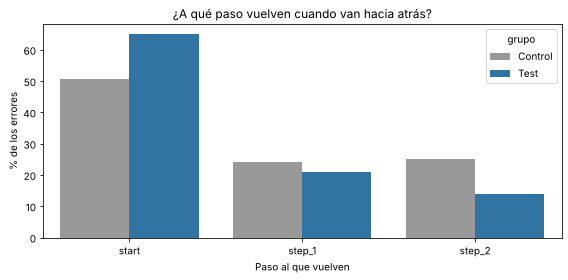

In [60]:
destino_pct = destino / destino.sum() * 100  # % de los errores de cada grupo que vuelven a cada paso
destino_pct.index.name = "paso al que vuelven"
eda.barras_por_grupo(destino_pct.loc[["start", "step_1", "step_2"]], "¿A qué paso vuelven cuando van hacia atrás?",
                     "Paso al que vuelven", etiqueta_y="% de los errores")

**➜ Qué nos llevamos para el proyecto:** en el Test, el 65 % de los errores son volver a `start` (51 % en el Control). El problema del nuevo diseño está al principio del proceso.

> **➜ O que tiramos para o projecto:** no Test, 65 % dos erros são voltar ao `start` (51 % no Control). O problema do novo design está no início do processo.

**Lo que se ve, y es importante:** el nuevo diseño tiene **más errores**, no menos.
- Tasa de errores: **9,2 % en el Test frente a 6,7 % en el Control**.
- Clientes con al menos un error: **33 % frente a 26 %**.
- La mayoría de los errores del Test son **volver a `start`** (10.511 frente a 4.809).

Esto explica por qué el Test hace más clics por cliente (pregunta K8): no son pasos de más, son vueltas atrás.

### ¿Desde qué paso vuelven atrás?

Cruzamos el paso en el que estaban (`paso_anterior`) con el paso al que vuelven. Así se ve qué pantalla del nuevo diseño confunde.

**Cómo funciona**

1. Da la vuelta al diccionario de pasos de `config.py` para pasar de número a nombre (`1` → `step_1`).
2. Se queda con los errores y añade la columna `desde` (el paso en el que estaba el cliente) con `map`, y la columna `vuelve_a` (el paso al que vuelve), que es una copia de `process_step` con un nombre más claro.
3. `pd.crosstab` con una lista de dos columnas en las filas cuenta cada combinación «desde → vuelve a» por grupo. Los nombres de las columnas pasan a ser los títulos del índice.

**Por qué así:** la tabla anterior dice a dónde vuelven, pero no desde dónde. Volver a `start` desde `step_1` o desde `step_3` son problemas distintos de diseño.

**Herramientas:** comprensión de diccionarios, `map`, `copy`, `pd.crosstab`.

**Dónde se vio en clase:** `map`, `copy` → Semana 2 · 2.2 Limpieza; `pd.crosstab` → Semana 5 · 5.2 EDA bivariante.

> **Como funciona (português)**
>
> 1. Inverte o dicionário de passos do `config.py` para passar de número a nome (`1` → `step_1`).
> 2. Fica com os erros e acrescenta a coluna `desde` (o passo em que o cliente estava) com `map`, e a coluna `vuelve_a` (o passo para onde volta), que é uma cópia de `process_step` com um nome mais claro.
> 3. O `pd.crosstab` com uma lista de duas colunas nas linhas conta cada combinação «de → volta a» por grupo. Os nomes das colunas passam a ser os títulos do índice.
>
> **Porquê assim:** a tabela anterior diz para onde voltam, mas não de onde. Voltar ao `start` a partir do `step_1` ou do `step_3` são problemas de design diferentes.
>
> **Onde se deu nas aulas:** `map`, `copy` → Semana 2 · 2.2 Limpieza; `pd.crosstab` → Semana 5 · 5.2 EDA bivariante.

In [61]:
nombres_pasos = {numero: paso for paso, numero in config.PASOS.items()}
errores = pasos[pasos["es_error"]].copy()
errores["desde"] = errores["paso_anterior"].map(nombres_pasos)
errores["vuelve_a"] = errores["process_step"]
pd.crosstab([errores["desde"], errores["vuelve_a"]], errores["grupo"])

grupo             Control  Test
desde   vuelve_a               
confirm start         488   242
        step_1         98    45
        step_2          0     1
        step_3          1     5
step_1  start        2483  6372
step_2  start         776  1663
        step_1       1384  3100
step_3  start        1062  2234
        step_1        821   255
        step_2       2367  2257

**➜ Qué nos llevamos para el proyecto:** el error que más crece es `step_1` → `start` (6.372 frente a 2.483). Junto con el KPI 2, señala a `step_1` como la pantalla confusa del nuevo diseño: recomendación concreta para la presentación.

> **➜ O que tiramos para o projecto:** o erro que mais cresce é `step_1` → `start` (6.372 contra 2.483). Junto com o KPI 2, aponta o `step_1` como o ecrã confuso do novo design: recomendação concreta para a apresentação.

**Cómo funciona**

1. Quita los clics cuyo paso anterior es `confirm` (número 4 en `config.py`: `config.PASOS["confirm"]`).
2. Recalcula la tasa de errores por grupo con la media de `es_error`.

**Por qué así:** volver a `start` después de confirmar puede ser empezar otro proceso, no un error. Si al quitarlos la conclusión cambiara, la definición de error sería frágil. Es la misma idea de robustez que en la Parte 1.

**Herramientas:** filtros con `!=`, `groupby`, `mean`, `round`.

**Dónde se vio en clase:** `!=`, `mean` → Semana 2 · 2.1 Pandas; `groupby` → Semana 2 · 2.4 Agregar; `round` → Semana 2 · 2.2 Limpieza.

> **Como funciona (português)**
>
> 1. Tira os cliques cujo passo anterior é `confirm` (número 4 no `config.py`: `config.PASOS["confirm"]`).
> 2. Recalcula a taxa de erros por grupo com a média de `es_error`.
>
> **Porquê assim:** voltar ao `start` depois de confirmar pode ser começar outro processo, não um erro. Se ao tirá-los a conclusão mudasse, a definição de erro seria frágil. É a mesma ideia de robustez da Parte 1.
>
> **Onde se deu nas aulas:** `!=`, `mean` → Semana 2 · 2.1 Pandas; `groupby` → Semana 2 · 2.4 Agregar; `round` → Semana 2 · 2.2 Limpieza.

In [62]:
# Comprobación: volver a empezar después de confirm puede ser un proceso nuevo y no un error.
sin_confirm = pasos[pasos["paso_anterior"] != config.PASOS["confirm"]]
(sin_confirm.groupby("grupo")["es_error"].mean() * 100).round(2)

grupo
Control   6.4
Test      9.2
Name: es_error, dtype: float64

**➜ Qué nos llevamos para el proyecto:** sin contar volver a empezar tras `confirm`, la tasa es 9,2 % frente a 6,4 %. La conclusión del KPI 3 no depende de esa decisión.

> **➜ O que tiramos para o projecto:** sem contar recomeçar depois do `confirm`, a taxa é 9,2 % contra 6,4 %. A conclusão do KPI 3 não depende dessa decisão.

**Lo que se ve:**
- El error que más crece es **de `step_1` a `start`**: 6.372 veces en el Test frente a 2.483 en el Control (2,6 veces más). Es el mismo paso en el que el Test tarda más (KPI 2).
- También crece **de `step_2` a `step_1`** (3.100 frente a 1.384).
- Si no contamos como error volver a empezar después de `confirm`, la tasa queda en 9,2 % frente a 6,4 %: la conclusión no cambia.

**Cómo funciona**

1. Para cada cliente, `any()` dice si tuvo al menos un error; `rename` le pone el nombre `tuvo_error`.
2. Se une con el grupo y la edad de la tabla de clientes.
3. Se pone el tramo de edad con `eda.tramo` (el `if` sencillo de la Parte 1) y `apply` con `lambda`, que le pasa los límites y los nombres de `config.py` (`config.LIMITES_EDAD` y `config.NOMBRES_EDAD`).
4. Se calcula el % con error por tramo y grupo y se ordenan los tramos con `.loc`.

**Por qué así:** la edad es la variable demográfica que más cambia el comportamiento (Parte 2). Si el nuevo diseño confunde más a un tipo de cliente, la recomendación puede ser más concreta.

**Herramientas:** `groupby`, `any`, `rename`, `merge`, `apply`, `lambda`, `unstack`, `loc`.

**Dónde se vio en clase:** `groupby` → Semana 2 · 2.4 Agregar; `any`, `rename`, `apply` → Semana 2 · 2.2 Limpieza; `merge`, `unstack` → Semana 2 · 2.3 Combinar; `lambda` → Semana 1 · 1.5 Lambda; `loc` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. Para cada cliente, o `any()` diz se teve pelo menos um erro; o `rename` dá-lhe o nome `tuvo_error`.
> 2. Junta-se com o grupo e a idade da tabela de clientes.
> 3. Põe-se o escalão de idade com o `eda.tramo` (o `if` simples da Parte 1) e o `apply` com `lambda`, que lhe passa os limites e os nomes do `config.py` (`config.LIMITES_EDAD` e `config.NOMBRES_EDAD`).
> 4. Calcula-se a % com erro por escalão e grupo e ordenam-se os escalões com `.loc`.
>
> **Porquê assim:** a idade é a variável demográfica que mais muda o comportamento (Parte 2). Se o novo design confundir mais um tipo de cliente, a recomendação pode ser mais concreta.
>
> **Onde se deu nas aulas:** `groupby` → Semana 2 · 2.4 Agregar; `any`, `rename`, `apply` → Semana 2 · 2.2 Limpieza; `merge`, `unstack` → Semana 2 · 2.3 Combinar; `lambda` → Semana 1 · 1.5 Lambda; `loc` → Semana 2 · 2.1 Pandas.

In [63]:
errores_cliente = pasos.groupby("client_id")["es_error"].any().rename("tuvo_error").reset_index()
errores_cliente = errores_cliente.merge(clientes[["client_id", "grupo", "edad"]], on="client_id")
errores_cliente["tramo_edad"] = errores_cliente["edad"].apply(lambda edad: eda.tramo(edad, config.LIMITES_EDAD, config.NOMBRES_EDAD))
(errores_cliente.groupby(["tramo_edad", "grupo"])["tuvo_error"].mean().unstack() * 100).loc[config.NOMBRES_EDAD]

grupo,Control,Test
tramo_edad,,
<30,26.3,29.3
30-44,23.3,28.1
45-59,25.9,36.0
60+,28.0,39.1


**➜ Qué nos llevamos para el proyecto:** en el Test los errores suben con la edad (29 % en menores de 30, 39 % en mayores de 60); en el Control casi no cambian. La diferencia es de 10-11 puntos desde los 45 años. Nueva pregunta para el día 4: ¿el nuevo diseño confunde más a los mayores?

> **➜ O que tiramos para o projecto:** no Test os erros sobem com a idade (29 % abaixo dos 30, 39 % acima dos 60); no Control quase não mudam. A diferença é de 10-11 pontos a partir dos 45 anos. Nova pergunta para o dia 4: o novo design confunde mais os mais velhos?

**Lo que se ve:** en el Control, el % de clientes con algún error es parecido en todas las edades (23-28 %). En el Test sube con la edad: 29 % en menores de 30 y **39 % en mayores de 60**. La diferencia entre grupos pasa de 3 puntos en los jóvenes a 10-11 puntos desde los 45 años. El nuevo diseño confunde más a los clientes mayores; aun así, en los mayores de 60 el Test también completa más (+4,8 puntos, Parte 2).

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** usamos la fórmula del enunciado (pasos hacia atrás / total de pasos) y añadimos el **% de clientes con algún error**, porque la unidad del test es el cliente y es lo que se contrasta en H5. Después miramos **a qué paso** vuelven y **desde cuál**, porque eso dice qué pantalla hay que arreglar.

> **Porque o fizemos assim:** usamos a fórmula do enunciado (passos para trás / total de passos) e juntámos a **% de clientes com algum erro**, porque a unidade do teste é o cliente e é o que se contrasta na H5. Depois vemos **para que passo** voltam e **de qual**, porque isso diz que ecrã é preciso corrigir.

**Pregunta posible 1.** ¿Por qué repetir el mismo paso no cuenta como error?
<br>*Pergunta possível 1. Porque é que repetir o mesmo passo não conta como erro?*

<details><summary>Respuesta / Resposta</summary>

Porque puede ser solo recargar la página. Un error es volver a un paso **anterior** (por ejemplo, de `step_1` a `start`). Las repeticiones se cuentan aparte para que no se pierdan.

> Porque pode ser só recarregar a página. Um erro é voltar a um passo **anterior**. As repetições contam-se à parte.

</details>

**Pregunta posible 2.** ¿Qué aporta cruzar el paso de origen con el de destino?
<br>*Pergunta possível 2. O que acrescenta cruzar o passo de origem com o de destino?*

<details><summary>Respuesta / Resposta</summary>

Dice exactamente dónde está el problema: el error que más crece en el Test es `step_1` → `start` (6.372 veces frente a 2.483). Es la recomendación más concreta del proyecto.

> Diz exactamente onde está o problema: o erro que mais cresce no Test é `step_1` → `start` (6.372 vezes contra 2.483).

</details>

## 3.5 KPI extra · Tiempo total para completar

**Cómo funciona**

1. `tiempo_total` busca, para cada cliente, la hora de su primer `start` y la de su primer `confirm` (`min` por cliente).
2. Las junta en una tabla y quita a quien no tiene las dos (`dropna`): solo cuenta quien completa.
3. La resta da el tiempo, que se pasa a minutos. Se quitan los negativos (confirm antes de start: registros incompletos vistos en la Parte 1).
4. `describe()` por grupo resume los minutos.

**Por qué así:** es el KPI que más le importa al cliente: cuánto tarda en terminar. Se usa el primer `confirm` para no contar las veces que vuelve a confirmar.

**Herramientas:** filtros, `groupby`, `min`, `pd.DataFrame` con un diccionario, `dropna`, `.dt.total_seconds()`, `describe`.

**Dónde se vio en clase:** `groupby` → Semana 2 · 2.4 Agregar; `min`, `pd.DataFrame`, `describe` → Semana 2 · 2.1 Pandas; `dropna` → Semana 2 · 2.2 Limpieza; `.dt.total_seconds()` → Semana 2 · fechas (self-guided).

> **Como funciona (português)**
>
> 1. O `tiempo_total` procura, para cada cliente, a hora do primeiro `start` e a do primeiro `confirm` (`min` por cliente).
> 2. Junta-as numa tabela e tira quem não tem as duas (`dropna`): só conta quem conclui.
> 3. A subtracção dá o tempo, que passa a minutos. Tiram-se os negativos (confirm antes do start: registos incompletos vistos na Parte 1).
> 4. O `describe()` por grupo resume os minutos.
>
> **Porquê assim:** é o KPI que mais importa ao cliente: quanto tempo demora a acabar. Usa-se o primeiro `confirm` para não contar as vezes que volta a confirmar.
>
> **Onde se deu nas aulas:** `groupby` → Semana 2 · 2.4 Agregar; `min`, `pd.DataFrame`, `describe` → Semana 2 · 2.1 Pandas; `dropna` → Semana 2 · 2.2 Limpieza; `.dt.total_seconds()` → Semana 2 · fechas (self-guided).

In [64]:
total = kpis.tiempo_total(pasos)
total.groupby("grupo")["minutos"].describe()

,count,mean,std,min,25%,50%,75%,max
grupo,,,,,,,,
Control,15296.0,5323.4,17175.8,0.6,3.2,5.4,12.6,139564.9
Test,18372.0,3851.0,14122.3,0.5,2.7,4.7,11.1,130172.8


**➜ Qué nos llevamos para el proyecto:** completan 15.296 clientes del Control y 18.372 del Test. La mediana es menor en el Test (4,7 frente a 5,4 minutos); la media no sirve porque llega a días.

> **➜ O que tiramos para o projecto:** concluem 15.296 clientes do Control e 18.372 do Test. A mediana é menor no Test (4,7 contra 5,4 minutos); a média não serve porque chega a dias.

**Cómo funciona**

1. Marca con `True` a quien completa en 30 minutos o menos.
2. Agrupa por grupo y junta en una tabla, con `pd.DataFrame` y un diccionario: número de clientes (`size`), mediana de minutos (`median`) y % que termina en 30 minutos (la media de `True`/`False`, × 100).

**Por qué así:** la media de la celda anterior sale de días porque hay clientes que empiezan y terminan semanas después. La mediana y el % que termina en la misma sesión cuentan mejor la experiencia normal.

**Herramientas:** comparaciones, `groupby`, `size`, `median`, `mean`, `pd.DataFrame` con un diccionario.

**Dónde se vio en clase:** `groupby`, `size` → Semana 2 · 2.4 Agregar; `median`, `mean`, `pd.DataFrame` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. Marca com `True` quem conclui em 30 minutos ou menos.
> 2. Agrupa por grupo e junta numa tabela, com `pd.DataFrame` e um dicionário: número de clientes (`size`), mediana dos minutos (`median`) e % que acaba em 30 minutos (a média de `True`/`False`, × 100).
>
> **Porquê assim:** a média da célula anterior sai em dias porque há clientes que começam e acabam semanas depois. A mediana e a % que acaba na mesma sessão contam melhor a experiência normal.
>
> **Onde se deu nas aulas:** `groupby`, `size` → Semana 2 · 2.4 Agregar; `median`, `mean`, `pd.DataFrame` → Semana 2 · 2.1 Pandas.

In [65]:
total["en_30_min"] = total["minutos"] <= 30
agrupado = total.groupby("grupo")
resumen_total = pd.DataFrame({
    "clientes": agrupado["minutos"].size(),
    "mediana_min": agrupado["minutos"].median(),
    "pct_en_30_min": agrupado["en_30_min"].mean() * 100,
})
resumen_total

,clientes,mediana_min,pct_en_30_min
grupo,,,
Control,15296,5.4,82.4
Test,18372,4.7,83.7


**➜ Qué nos llevamos para el proyecto:** el 83,7 % del Test y el 82,4 % del Control terminan en menos de media hora. El Test es algo más rápido, pero la diferencia es pequeña.

> **➜ O que tiramos para o projecto:** 83,7 % do Test e 82,4 % do Control acabam em menos de meia hora. O Test é um pouco mais rápido, mas a diferença é pequena.

**Lo que se ve:** quien completa tarda una mediana de **4,7 minutos en el Test y 5,4 en el Control**. La media no sirve aquí: algunos clientes empiezan un día y terminan semanas después.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** el tiempo total dice si el nuevo diseño hace terminar **antes**, no solo más. Se mide desde el primer `start` hasta el primer `confirm`, con la mediana, porque hay clientes que terminan días después.

> **Porque o fizemos assim:** o tempo total diz se o novo design faz terminar **mais depressa**, não só mais. Mede-se desde o primeiro `start` até ao primeiro `confirm`, com a mediana, porque há clientes que terminam dias depois.

**Pregunta posible 1.** ¿Por qué se quitan los clientes con minutos negativos?
<br>*Pergunta possível 1. Porque se tiram os clientes com minutos negativos?*

<details><summary>Respuesta / Resposta</summary>

Porque un `confirm` anterior al primer `start` es un registro incompleto (problema 13): no se puede medir un tiempo que empieza después de terminar.

> Porque um `confirm` anterior ao primeiro `start` é um registo incompleto: não se pode medir um tempo que começa depois de acabar.

</details>

## 3.5b Bonus · Recorridos: ¿los dos grupos siguen los mismos pasos? (B8)

El enunciado propone, como tarea extra, ver cómo navegan los clientes por el proceso antiguo y el nuevo: si siguen los mismos pasos o se separan en algún punto.

> **5b. Bónus · Percursos: os dois grupos seguem os mesmos passos? (B8)** O enunciado propõe, como tarefa extra, ver como os clientes navegam no processo antigo e no novo: se seguem os mesmos passos ou se separam em algum ponto.

**Cómo funciona**

1. Ordena los clics de cada visita por hora y número de paso (`sort_values`), igual que para los errores.
2. Para cada visita (`groupby` por grupo y `visit_id`) une los pasos en un texto con `" > ".join` dentro de `apply` con `lambda`: `reset_index` y `rename` lo pasan a una tabla con la columna `recorrido`. Así cada visita queda como un recorrido, por ejemplo `start > step_1 > step_2 > step_3 > confirm`.
3. `value_counts(normalize=True) * 100` da el % de visitas de cada recorrido; se enseñan los 6 más frecuentes de cada grupo.
4. Calcula el % de visitas que hacen el recorrido «perfecto», los cinco pasos en orden y sin volver atrás.

**Por qué así:** el recorrido es la forma más directa de ver dónde se separan los dos diseños. La unidad es la visita, porque un cliente puede hacer el proceso en varias visitas.

**Herramientas:** `sort_values`, `groupby`, `apply`, `lambda`, `join` (método de texto de la lección 1.1), `reset_index`, `rename`, `value_counts(normalize=True)`, `head`.

**Dónde se vio en clase:** `sort_values`, `head` → Semana 2 · 2.1 Pandas; `groupby` → Semana 2 · 2.4 Agregar; `apply`, `reset_index`, `rename` → Semana 2 · 2.2 Limpieza; `lambda` → Semana 1 · 1.5 Lambda; `join` → Semana 1 · 1.1 Estructuras de datos; `value_counts(normalize=True)` → Semana 5 · 5.1 EDA univariante.

> **Como funciona (português)**
>
> 1. Ordena os cliques de cada visita por hora e número de passo (`sort_values`), tal como para os erros.
> 2. Para cada visita (`groupby` por grupo e `visit_id`) junta os passos num texto com `" > ".join` dentro de um `apply` com `lambda`; o `reset_index` e o `rename` passam-no a uma tabela com a coluna `recorrido`: cada visita fica como um percurso.
> 3. O `value_counts(normalize=True) * 100` dá a % de visitas de cada percurso; mostram-se os 6 mais frequentes de cada grupo.
> 4. Calcula a % de visitas que fazem o percurso «perfeito», os cinco passos por ordem e sem voltar atrás.
>
> **Porquê assim:** o percurso é a forma mais directa de ver onde os dois designs se separam. A unidade é a visita, porque um cliente pode fazer o processo em várias visitas.
>
> **Onde se deu nas aulas:** `sort_values`, `head` → Semana 2 · 2.1 Pandas; `groupby` → Semana 2 · 2.4 Agregar; `apply`, `reset_index`, `rename` → Semana 2 · 2.2 Limpieza; `lambda` → Semana 1 · 1.5 Lambda; `join` → Semana 1 · 1.1 Estructuras de datos; `value_counts(normalize=True)` → Semana 5 · 5.1 EDA univariante.

In [66]:
ordenados = pasos.sort_values(["visit_id", "date_time", "paso_num"])
recorridos = ordenados.groupby(["grupo", "visit_id"])["process_step"].apply(
    lambda pasos_visita: " > ".join(pasos_visita)).reset_index()
recorridos = recorridos.rename(columns={"process_step": "recorrido"})

for grupo in ["Control", "Test"]:
    del_grupo = recorridos[recorridos["grupo"] == grupo]
    print(f"===== {grupo}: {len(del_grupo)} visitas =====")
    print((del_grupo["recorrido"].value_counts(normalize=True) * 100).round(1).head(6))
    print()

perfecto = " > ".join(ORDEN_PASOS)
recorridos["perfecto_pct"] = (recorridos["recorrido"] == perfecto) * 100
print("Visitas con el recorrido perfecto (%):")
recorridos.groupby("grupo")["perfecto_pct"].mean().round(1)

===== Control: 32183 visitas =====
recorrido
start > step_1 > step_2 > step_3 > confirm   29.2
start                                        15.6
start > step_1                                7.1
start > start                                 5.4
start > step_1 > step_2 > step_3              4.1
start > step_1 > step_2                       3.3
Name: proportion, dtype: float64

===== Test: 37122 visitas =====
recorrido
start > step_1 > step_2 > step_3 > confirm                    28.4
start                                                          8.3
confirm                                                        6.9
start > step_1                                                 5.3
start > step_1 > start > step_1 > step_2 > step_3 > confirm    2.7
start > start                                                  2.6
Name: proportion, dtype: float64

Visitas con el recorrido perfecto (%):


grupo
Control   29.2
Test      28.4
Name: perfecto_pct, dtype: float64

**➜ Qué nos llevamos:** **los dos diseños se separan al principio.** El recorrido perfecto pesa lo mismo en los dos grupos (29 % de las visitas en el Control y 28 % en el Test). La diferencia está en el arranque: en el Control, el 15,6 % de las visitas se queda en `start` sin seguir; en el Test, solo el 8,3 %. A cambio, en el Test aparece entre los recorridos más frecuentes `start > step_1 > start > step_1 > ...`, la vuelta atrás desde `step_1` que ya marcaba la tasa de errores. El Test también tiene un 6,9 % de visitas que solo son `confirm`: clientes que vuelven a la página final en otra visita, lo que reparte el proceso en más visitas.

> **➜ O que tiramos:** **os dois designs separam-se no início.** O percurso perfeito pesa o mesmo nos dois grupos (29 % das visitas no Control e 28 % no Test). A diferença está no arranque: no Control, 15,6 % das visitas ficam no `start` sem avançar; no Test, só 8,3 %. Em troca, no Test aparece entre os percursos mais frequentes `start > step_1 > start > step_1 > ...`, a volta atrás a partir do `step_1` que a taxa de erros já mostrava. O Test tem ainda 6,9 % de visitas que são só `confirm`: clientes que voltam à página final noutra visita.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** es una tarea extra del enunciado. La unidad aquí es la **visita**, porque un recorrido es lo que hace el cliente en una visita. Convertimos los pasos de cada visita en un texto (`" > ".join`) para poder contar recorridos iguales con `value_counts`.

> **Porque o fizemos assim:** é uma tarefa extra do enunciado. A unidade aqui é a **visita**, porque um percurso é o que o cliente faz numa visita. Convertemos os passos de cada visita num texto (`" > ".join`) para contar percursos iguais com `value_counts`.

**Pregunta posible 1.** ¿Qué enseñan los recorridos que no enseñaban los KPI?
<br>*Pergunta possível 1. O que mostram os percursos que os KPI não mostravam?*

<details><summary>Respuesta / Resposta</summary>

Que el recorrido perfecto pesa lo mismo en los dos grupos y que la diferencia está en el arranque: en el Control muchas más visitas se quedan en `start` (15,6 % frente a 8,3 %), y en el Test aparece la ida y vuelta `start` ↔ `step_1`.

> Que o percurso perfeito pesa o mesmo nos dois grupos e que a diferença está no arranque: no Control muitas mais visitas ficam no `start` (15,6 % contra 8,3 %), e no Test aparece o vaivém `start` ↔ `step_1`.

</details>

## 3.6 Resumen de los KPI

**Cómo funciona**

1. Construye una tabla a mano con un diccionario: una columna por grupo y una fila por KPI, cogiendo cada número de las tablas anteriores con `loc`.
2. Añade la columna «Mejor»: en finalización y tiempo gana quien tiene el valor más alto o más bajo según el caso; en errores, quien tiene menos.

**Por qué así:** es la tabla que irá a la presentación y a Tableau. Tomando los valores de las tablas calculadas (y no escribiéndolos a mano) se actualiza sola si cambia la limpieza.

**Herramientas:** `pd.DataFrame` con un diccionario, `loc`, listas.

**Dónde se vio en clase:** `pd.DataFrame`, `loc` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. Constrói uma tabela à mão com um dicionário: uma coluna por grupo e uma linha por KPI, indo buscar cada número às tabelas anteriores com `loc`.
> 2. Acrescenta a coluna «Mejor»: na conclusão e no tempo ganha quem tem o valor mais alto ou mais baixo conforme o caso; nos erros, quem tem menos.
>
> **Porquê assim:** é a tabela que vai para a apresentação e para o Tableau. Indo buscar os valores às tabelas calculadas (e não escrevendo-os à mão) actualiza-se sozinha se a limpeza mudar.
>
> **Onde se deu nas aulas:** `pd.DataFrame`, `loc` → Semana 2 · 2.1 Pandas.

In [67]:
resumen = pd.DataFrame({
    "Control": [tabla_embudo.loc["confirm", "Control"], medianas.sum()["Control"], tabla_errores.loc["Control", "tasa_errores_pct"],
                tabla_errores.loc["Control", "clientes_con_error_pct"], resumen_total.loc["Control", "mediana_min"]],
    "Test": [tabla_embudo.loc["confirm", "Test"], medianas.sum()["Test"], tabla_errores.loc["Test", "tasa_errores_pct"],
             tabla_errores.loc["Test", "clientes_con_error_pct"], resumen_total.loc["Test", "mediana_min"]],
}, index=["Tasa de finalización (%)", "Suma de medianas por paso (s)", "Tasa de errores (%)",
          "Clientes con algún error (%)", "Tiempo total mediano (min)"])
resumen["Mejor"] = ["Test", "Test", "Control", "Control", "Test"]
resumen

,Control,Test,Mejor
Tasa de finalización (%),65.6,69.3,Test
Suma de medianas por paso (s),176.0,159.0,Test
Tasa de errores (%),6.7,9.2,Control
Clientes con algún error (%),25.8,33.4,Control
Tiempo total mediano (min),5.4,4.7,Test


**➜ Qué nos llevamos para el proyecto:** tabla resumen para la diapositiva de los KPI: el Test gana en finalización y tiempo; el Control gana en errores.

> **➜ O que tiramos para o projecto:** tabela-resumo para o slide dos KPI: o Test ganha na conclusão e no tempo; o Control ganha nos erros.

**Cómo funciona**

1. Guarda la tabla de resumen y la tabla de clics con las columnas de los KPI en `data/clean/`.

**Por qué así:** Tableau (semana 6) leerá estos CSV para el dashboard: así los números del dashboard son los mismos que los del notebook. `data/clean/` está en `.gitignore`, así que se regenera ejecutando los notebooks.

**Herramientas:** `to_csv`.

**Dónde se vio en clase:** `to_csv` → Semana 4 · A3 Datos relacionales.

> **Como funciona (português)**
>
> 1. Guarda a tabela de resumo e a tabela de cliques com as colunas dos KPI em `data/clean/`.
>
> **Porquê assim:** O Tableau (semana 6) vai ler estes CSV para o dashboard: assim os números do dashboard são os mesmos do notebook. A pasta `data/clean/` está no `.gitignore`, por isso volta a gerar-se correndo os notebooks.
>
> **Onde se deu nas aulas:** `to_csv` → Semana 4 · A3 Datos relacionales.

In [68]:
resumen.to_csv(f"{config.RUTA_CLEAN}/kpis_resumen.csv")
pasos.to_csv(f"{config.RUTA_CLEAN}/pasos_kpis.csv", index=False)
print("Guardado: kpis_resumen.csv y pasos_kpis.csv (para Tableau)")

Guardado: kpis_resumen.csv y pasos_kpis.csv (para Tableau)


**➜ Qué nos llevamos para el proyecto:** los datos para el dashboard de Tableau ya están listos en `data/clean/`.

> **➜ O que tiramos para o projecto:** os dados para o dashboard do Tableau já estão prontos em `data/clean/`.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** una sola tabla para la diapositiva de los KPI, y los CSV que necesita el resto del proyecto. Así no hay que copiar números a mano.

> **Porque o fizemos assim:** uma só tabela para o diapositivo dos KPI, e os CSV de que o resto do projecto precisa. Assim não é preciso copiar números à mão.

**Pregunta posible 1.** ¿Quién gana en cada KPI?
<br>*Pergunta possível 1. Quem ganha em cada KPI?*

<details><summary>Respuesta / Resposta</summary>

El Test gana en finalización (69,3 % frente a 65,6 %) y en tiempo (4,7 frente a 5,4 minutos). El Control gana en errores (6,7 % frente a 9,2 % de los pasos). Es la frase que resume el día 3.

> O Test ganha na conclusão e no tempo; o Control ganha nos erros. É a frase que resume o dia 3.

</details>

## 3.7 Conclusión del día 3

| KPI | Control | Test | Mejor |
|---|---|---|---|
| Tasa de finalización | 65,6 % | 69,3 % | **Test** (+3,7 puntos) |
| Tiempo en los pasos (medianas) | más lento en `start` y `step_3` | más lento en `step_1` | **Test** en conjunto |
| Tasa de errores | 6,7 % | 9,2 % | **Control** |
| Clientes con algún error | 26 % | 33 % | **Control** |
| Tiempo total mediano | 5,4 min | 4,7 min | **Test** |

**Idea principal:** el nuevo diseño hace que **más clientes terminen y más rápido**, pero con **más vueltas atrás**, sobre todo de `step_1` a `start` y en los clientes de 45 años o más. Es un diseño que funciona mejor, pero tiene un punto confuso al principio del proceso.

**Recorridos (bonus, sección 3.5b):** el nuevo diseño hace que menos visitas se queden paradas en `start` (8 % frente a 16 %), pero añade un recorrido nuevo de ida y vuelta entre `start` y `step_1`.

**Para los días siguientes:**
- Contrastar si la diferencia en la tasa de finalización es significativa y si supera el 5 % (H1, H2), también por periodo (E7).
- Contrastar la diferencia en errores (H5).
- Contrastar si los errores del Test suben con la edad (H3 ampliada).
- Recomendación posible: revisar `step_1` del nuevo diseño, que es donde los clientes tardan más y vuelven atrás.

<a id="parte-4"></a>

# Parte 4 · Prueba de hipótesis y evaluación del experimento (días 4 y 5)

Esta parte une dos trabajos:

- **Parte 4A · La base de Emanuel** (`Prueba-de-hipotesis.ipynb`): el enunciado, H1 (¿el Test completa más?), H2 (¿la mejora supera el 5 %?), una hipótesis sobre la edad y una primera evaluación del experimento. Se deja **su texto y su código tal cual** y, al lado, el mismo cálculo con lo visto en clase, porque su código no se podía ejecutar (no cargaba los datos y usaba `statsmodels`, que no vimos).
- **Parte 4B · Lo que añadimos y por qué:** H1 y H2 con la t de Welch y el chi-cuadrado de la lección, los requisitos, el análisis por periodo, los otros contrastes (errores, edad, tiempo, clics) y la evaluación del experimento con contrastes (E1, E2, E3). Cada sección dice **por qué** se añadió.

| Pregunta del enunciado | Dónde está |
|---|---|
| ¿La diferencia en la tasa de finalización es significativa? | 4A.2 (Emanuel) y sección 4.3 (H1) |
| ¿La mejora supera el umbral del 5 %? | 4A.3 (Emanuel) y sección 4.4 (H2) |
| Otra hipótesis a elección | Sección 4.5 (H3, H5 a H9) |
| ¿Estaba bien diseñado el experimento? ¿Hubo sesgo? | 4A.4 (edad, Emanuel) y sección 4.6 (E1, E2, E3) |
| ¿Duró lo suficiente? ¿Qué datos faltan? | Sección 4.6, «Evaluación: respuestas» |

Los códigos (H1, E2...) son los de `preguntas.md`. Todos los contrastes siguen el esquema de la lección: hipótesis nula (H0) y alternativa (H1), α = 0,05, estadístico, p-valor y decisión.

> **Em português.** Esta parte junta dois trabalhos. **Parte 4A:** a base do Emanuel (`Prueba-de-hipotesis.ipynb`), com o texto e o código dele tal como estavam e, ao lado, o mesmo cálculo com o que demos nas aulas, porque o código dele não corria (não carregava os dados e usava o `statsmodels`, que não demos). **Parte 4B:** o que acrescentámos e porquê (H1 e H2 com o t de Welch e o qui-quadrado da lição, requisitos, análise por período, outros contrastes e a avaliação do experimento com contrastes).

#### Para entenderlo · Cómo funciona un contraste de hipótesis, en cinco pasos

Se parece a un juicio: se parte de que el acusado es inocente y solo se le condena si las pruebas hacen muy difícil creerlo.

1. **H0 (hipótesis nula):** la «inocencia». Aquí, casi siempre: los dos diseños funcionan igual.
2. **H1 (alternativa):** lo que queremos comprobar (el Test completa distinto, o más).
3. **α = 0,05:** el riesgo que aceptamos de equivocarnos al rechazar H0. Se fija **antes** de mirar el resultado.
4. **Estadístico y p-valor:** el estadístico mide cuántos errores típicos separan lo observado de lo que diría H0. El p-valor es la probabilidad de ver una diferencia así de grande, o más, **si H0 fuera cierta**.
5. **Decisión:** si p < α, se rechaza H0 (la diferencia es difícil de explicar por azar). Si no, no se rechaza: no hay pruebas suficientes.

El p-valor **no** da la probabilidad de que H0 sea cierta, ni dice si la diferencia es grande o importante. Para eso se mira el tamaño de la diferencia (puntos, V de Cramér) y el umbral del negocio (H2).

**Una cola o dos.** Con dos colas se pregunta «¿son distintos?», en cualquier sentido. Con una cola, «¿es mayor?». H1 se hace con dos colas en la Parte 4B y con una en la base de Emanuel; H2 es de una cola porque solo interesa saber si se supera el umbral.

> **Para perceber (português).** Parece-se com um julgamento: parte-se de que o acusado é inocente e só se condena se as provas tornarem isso muito difícil de acreditar. (1) **H0:** a «inocência»; aqui, quase sempre, os dois designs funcionam igual. (2) **H1:** o que queremos verificar. (3) **α = 0,05:** o risco que aceitamos de nos enganarmos ao rejeitar a H0, fixado **antes** de ver o resultado. (4) **Estatística e p-valor:** a estatística mede quantos erros padrão separam o observado do que diria a H0; o p-valor é a probabilidade de ver uma diferença assim tão grande, ou maior, **se a H0 fosse verdadeira**. (5) **Decisão:** se p < α, rejeita-se a H0; se não, não se rejeita (não há provas suficientes). O p-valor **não** dá a probabilidade de a H0 ser verdadeira, nem diz se a diferença é grande ou importante: para isso olha-se para o tamanho da diferença e para o limiar do negócio (H2). Com duas caudas pergunta-se «são diferentes?»; com uma, «é maior?». A H1 faz-se com duas caudas na Parte 4B e com uma na base do Emanuel; a H2 é de uma cauda.

**Cómo funciona**

1. `pd.set_option` cambia cómo enseña pandas los números: desde aquí, con dos decimales (`"{:.2f}".format`, el `format()` con `'.2f'` de la lección de limpieza).

**Por qué así:** en la Parte 4 hay estadísticos y medias que se comparan al segundo decimal (por ejemplo, t = 8,88).

**Herramientas:** `pd.set_option`.

> **Como funciona (português)**
>
> 1. O `pd.set_option` muda a forma como o pandas mostra os números: daqui em diante, com duas casas decimais.
>
> **Porquê assim:** na Parte 4 há estatísticas e médias que se comparam à segunda casa decimal (por exemplo, t = 8,88).

In [69]:
pd.set_option("display.float_format", "{:.2f}".format)  # la Parte 4 enseña dos decimales

## 4.1 Datos para los contrastes

Se parte de las tablas limpias de la Parte 1 y de las funciones de las Partes 2 y 3. Cada variable de resultado se guarda como **0 o 100** por cliente: así la media de la columna es directamente el % de clientes y la diferencia entre grupos sale en puntos.

**Cómo funciona**

1. Lee las tablas limpias (`parse_dates` convierte `date_time` en fecha al leer).
2. `comportamiento_por_cliente` (Parte 1) da una fila por cliente; se une con el perfil (`merge`).
3. `completo_pct` = `completo` × 100: 100 si el cliente llegó a `confirm`, 0 si no.
4. Se añaden el tramo de edad (`eda.tramo` con `apply`), el mes del primer clic (`.dt.month` y un diccionario con `map`) y el periodo: antes o después del 8 de mayo, la semana en la que cambia el reparto entre grupos (sección 2.7).
5. `preparar_pasos` (Parte 3) marca los pasos hacia atrás. `groupby("client_id")["es_error"].any()` dice si cada cliente tuvo al menos un error, y `map` lo lleva a la tabla de clientes como 0 o 100 (`error_pct`).

**Por qué así:** la unidad del test es el cliente (a cada cliente se le asigna un grupo), así que los contrastes comparan clientes, no clics. Con 0 y 100 en vez de `True`/`False`, el contraste de medias compara directamente porcentajes.

**Herramientas:** `pd.read_csv`, `merge`, `apply`, `lambda`, `.dt.month`, `map`, `pd.Timestamp`, `groupby`, `any`.

**Dónde se vio en clase:** `pd.read_csv` → Semana 2 · 2.1 Pandas; `merge` → Semana 2 · 2.3 Combinar; `apply`, `map`, `any` → Semana 2 · 2.2 Limpieza; `lambda` → Semana 1 · 1.5 Lambda; `.dt.month`, `pd.Timestamp` → Semana 2 · fechas (self-guided); `groupby` → Semana 2 · 2.4 Agregar.

> **Como funciona (português)**
>
> 1. Lê as tabelas limpas (o `parse_dates` converte o `date_time` em data ao ler).
> 2. O `comportamiento_por_cliente` (Parte 1) dá uma linha por cliente; junta-se ao perfil (`merge`).
> 3. `completo_pct` = `completo` × 100: 100 se o cliente chegou ao `confirm`, 0 se não.
> 4. Acrescentam-se o escalão de idade (`eda.tramo` com `apply`), o mês do primeiro clique (`.dt.month` e um dicionário com `map`) e o período: antes ou depois de 8 de Maio, a semana em que muda a repartição entre grupos (secção 2.7).
> 5. O `preparar_pasos` (Parte 3) marca os passos para trás. O `groupby("client_id")["es_error"].any()` diz se cada cliente teve pelo menos um erro, e o `map` leva-o para a tabela de clientes como 0 ou 100 (`error_pct`).
>
> **Porquê assim:** a unidade do teste é o cliente (a cada cliente atribui-se um grupo), por isso os contrastes comparam clientes, não cliques. Com 0 e 100 em vez de `True`/`False`, o contraste de médias compara directamente percentagens.
>
> **Onde se deu nas aulas:** `pd.read_csv` → Semana 2 · 2.1 Pandas; `merge` → Semana 2 · 2.3 Combinar; `apply`, `map`, `any` → Semana 2 · 2.2 Limpieza; `lambda` → Semana 1 · 1.5 Lambda; `.dt.month`, `pd.Timestamp` → Semana 2 · fechas (self-guided); `groupby` → Semana 2 · 2.4 Agregar.

In [70]:
clientes = pd.read_csv(f"{config.RUTA_CLEAN}/clientes.csv")
web = pd.read_csv(f"{config.RUTA_CLEAN}/web.csv", parse_dates=["date_time"])

# Una fila por cliente: grupo, perfil y si completó el proceso (100) o no (0)
por_cliente = eda.comportamiento_por_cliente(web).merge(clientes, on="client_id")
por_cliente["completo_pct"] = por_cliente["completo"] * 100
por_cliente["tramo_edad"] = por_cliente["edad"].apply(lambda edad: eda.tramo(edad, config.LIMITES_EDAD, config.NOMBRES_EDAD))

# Cuándo empezó cada cliente: mes y periodo (el reparto entre grupos cambia el 8 de mayo)
primer_clic = web.groupby("client_id")["date_time"].min()
por_cliente["primer_clic"] = por_cliente["client_id"].map(primer_clic)
meses = {3: "Marzo", 4: "Abril", 5: "Mayo", 6: "Junio"}
por_cliente["mes_inicio"] = por_cliente["primer_clic"].dt.month.map(meses)
fecha_cambio = pd.Timestamp("2017-05-08")
por_cliente["periodo"] = por_cliente["primer_clic"].apply(
    lambda fecha: "Hasta el 7 de mayo" if fecha < fecha_cambio else "Desde el 8 de mayo")

# Errores (notebook 03): 100 si el cliente volvió atrás al menos una vez, 0 si no
pasos = kpis.preparar_pasos(web, clientes)
tuvo_error = pasos.groupby("client_id")["es_error"].any()
por_cliente["error_pct"] = por_cliente["client_id"].map(tuvo_error) * 100

print(por_cliente.shape)
por_cliente[["client_id", "grupo", "completo_pct", "error_pct", "tramo_edad", "mes_inicio", "periodo"]].head()

(50488, 21)


,client_id,grupo,completo_pct,error_pct,tramo_edad,mes_inicio,periodo
0,555,Test,100,0,<30,Abril,Hasta el 7 de mayo
1,647,Test,100,0,45-59,Abril,Hasta el 7 de mayo
2,934,Test,0,0,45-59,Abril,Hasta el 7 de mayo
3,1028,Control,0,100,30-44,Abril,Hasta el 7 de mayo
4,1104,Control,0,0,45-59,Junio,Desde el 8 de mayo


**➜ Qué nos llevamos para el proyecto:** una fila por cliente (50.488) con todo lo que necesitan los contrastes. Los números de partida son los de la Parte 3.

> **➜ O que tiramos para o projecto:** uma linha por cliente (50.488) com tudo o que os contrastes precisam. Os números de partida são os da Parte 3.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** cada variable de resultado se guarda como **0 o 100 por cliente**: así la media es el % y la diferencia sale en puntos, que es como se lee en la presentación. Aquí se crean también el periodo (antes y después del 8 de mayo) y el mes de inicio, que salieron de la Parte 2.

> **Porque o fizemos assim:** cada variável de resultado guarda-se como **0 ou 100 por cliente**: assim a média é a % e a diferença sai em pontos, que é como se lê na apresentação. Aqui criam-se também o período (antes e depois de 8 de Maio) e o mês de início, que saíram da Parte 2.

**Pregunta posible 1.** ¿Por qué no se reutilizan las tablas de las Partes 2 y 3?
<br>*Pergunta possível 1. Porque não se reutilizam as tabelas das Partes 2 e 3?*

<details><summary>Respuesta / Resposta</summary>

Porque cada notebook tiene que poder ejecutarse solo, a partir de `data/clean` y de las funciones de `src/`. Así nadie depende de haber ejecutado otro notebook en la misma sesión.

> Porque cada notebook tem de poder correr sozinho, a partir de `data/clean` e das funções do `src/`.

</details>

## 4.2 Antes de contrastar: requisitos

La lección pide revisar los requisitos del contraste antes de usarlo. Para comparar la media de dos grupos con `st.ttest_ind`:

- **Muestras independientes:** cada cliente está en un solo grupo y su resultado no depende del de otro cliente.
- **Muestras grandes o datos normales:** una columna de 0 y 100 no es normal, pero con muestras tan grandes la media de cada grupo sí sigue una distribución normal (es lo que enseña la distribución muestral de la lección: las medias de muchas muestras forman una campana aunque los datos no la formen).
- **Varianzas:** no hace falta que sean iguales si se usa `equal_var=False` (t de Welch, como en el ejemplo del Titanic de la lección).
- Para el chi-cuadrado (lección de EDA bivariante), cada casilla de la tabla debe tener suficientes casos; aquí tienen miles.

> A lição pede para rever os requisitos do contraste antes de o usar. Para comparar a média de dois grupos com `st.ttest_ind`: amostras independentes (cada cliente está num só grupo), amostras grandes ou dados normais (uma coluna de 0 e 100 não é normal, mas com amostras tão grandes a média de cada grupo segue uma distribuição normal, como mostra a distribuição amostral da lição) e, com `equal_var=False` (t de Welch), não é preciso que as variâncias sejam iguais. Para o qui-quadrado, cada casa da tabela deve ter casos suficientes; aqui tem milhares.

**Por qué lo añadimos:** la base de Emanuel no comprobaba los requisitos y la lección pide hacerlo antes de elegir el contraste.

> **Porque o acrescentámos:** a base do Emanuel não verificava os requisitos e a lição pede para o fazer antes de escolher o contraste.

#### Para entenderlo · La tasa de una muestra también varía: el error típico

Si repitiéramos el test con otros 27.000 clientes, la tasa del Test no saldría exactamente 69,3 %: cambiaría un poco por azar. El **error típico** mide cuánto: es la desviación típica dividida entre la raíz del número de clientes. (La tasa es la media de una columna de 0 y 100, así que todo lo que vale para medias vale para la tasa.)

- Test: 46 / √26.961 ≈ **0,28 puntos**. Control: 48 / √23.527 ≈ **0,31 puntos**.
- La diferencia entre los dos grupos tiene su propio error típico: √(0,28² + 0,31²) ≈ **0,42 puntos**.
- La diferencia observada es de 3,7 puntos: 3,7 / 0,42 ≈ **9 errores típicos**. Es el estadístico de H1 (8,9).

El **teorema del límite central** (lección de distribución muestral) dice que, con muestras grandes, esas tasas forman una campana normal aunque los datos sean solo 0 y 100. Por eso se pueden usar la t y la z. También explica por qué con tantos clientes casi todo sale significativo: con un error típico de 0,42 puntos, una diferencia de menos de un punto ya es difícil de explicar por azar.

> **Para perceber (português).** Se repetíssemos o teste com outros 27.000 clientes, a taxa do Test não sairia exactamente 69,3 %: mudaria um pouco por acaso. O **erro padrão** mede quanto: é o desvio padrão dividido pela raiz do número de clientes (a taxa é a média de uma coluna de 0 e 100). Test: 46 / √26.961 ≈ 0,28 pontos; Control: 48 / √23.527 ≈ 0,31 pontos; a diferença tem um erro padrão de √(0,28² + 0,31²) ≈ 0,42 pontos. A diferença observada, 3,7 pontos, equivale a uns 9 erros padrão: é a estatística da H1 (8,9). O **teorema do limite central** diz que, com amostras grandes, essas taxas formam uma campânula normal mesmo que os dados sejam só 0 e 100, por isso podem usar-se o t e o z. Também explica porque é que com tantos clientes quase tudo sai significativo: com um erro padrão de 0,42 pontos, uma diferença de menos de um ponto já é difícil de explicar por acaso.

**Cómo funciona**

1. `duplicated().any()` comprueba que ningún cliente aparece dos veces (y, por tanto, en los dos grupos).
2. Por grupo calcula el número de clientes (`count`), el % que completa (`mean`) y la desviación típica (`std`), y los junta con `pd.DataFrame` y un diccionario.

**Por qué así:** son los datos que necesita el contraste (n, media y dispersión de cada grupo) y permiten comprobar los requisitos: muestras de más de 20.000 clientes y dispersiones parecidas.

**Herramientas:** `duplicated`, `any`, `groupby`, `count`, `mean`, `std`, `pd.DataFrame`.

**Dónde se vio en clase:** `duplicated`, `any` → Semana 2 · 2.2 Limpieza; `groupby` → Semana 2 · 2.4 Agregar; `count`, `mean`, `std`, `pd.DataFrame` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. O `duplicated().any()` verifica que nenhum cliente aparece duas vezes (e, portanto, nos dois grupos).
> 2. Por grupo calcula o número de clientes (`count`), a % que conclui (`mean`) e o desvio padrão (`std`), e junta-os com `pd.DataFrame` e um dicionário.
>
> **Porquê assim:** são os dados de que o contraste precisa (n, média e dispersão de cada grupo) e permitem verificar os requisitos: amostras de mais de 20.000 clientes e dispersões parecidas.
>
> **Onde se deu nas aulas:** `duplicated`, `any` → Semana 2 · 2.2 Limpieza; `groupby` → Semana 2 · 2.4 Agregar; `count`, `mean`, `std`, `pd.DataFrame` → Semana 2 · 2.1 Pandas.

In [71]:
print("¿Algún cliente aparece dos veces?", por_cliente["client_id"].duplicated().any())

agrupado = por_cliente.groupby("grupo")
pd.DataFrame({
    "clientes": agrupado["client_id"].count(),
    "completan_pct": agrupado["completo_pct"].mean(),
    "desviacion_tipica": agrupado["completo_pct"].std(),
})

¿Algún cliente aparece dos veces? False


,clientes,completan_pct,desviacion_tipica
grupo,,,
Control,23527,65.58,47.51
Test,26961,69.29,46.13


**➜ Qué nos llevamos para el proyecto:** los requisitos se cumplen: grupos independientes, de más de 23.000 clientes cada uno y con dispersiones parecidas (46 y 48). Se puede usar el contraste t de dos muestras.

> **➜ O que tiramos para o projecto:** os requisitos cumprem-se: grupos independentes, com mais de 23.000 clientes cada um e dispersões parecidas (46 e 48). Pode usar-se o contraste t de duas amostras.

### Resultados de partida (Parte 3)

Antes de contrastar, conviene tener delante lo que dijeron los KPI. Son resultados descriptivos: esta parte comprueba si las diferencias son reales.

| KPI | Control | Test | Mejor |
|---|---|---|---|
| Tasa de finalización | 65,6 % | 69,3 % | **Test** (+3,7 puntos) |
| Tiempo en cada paso (medianas) | más lento en `start`, `step_2` y `step_3` | más lento en `step_1` | **Test** en conjunto |
| Tasa de errores | 6,7 % | 9,2 % | **Control** |
| Clientes con algún error | 25,8 % | 33,4 % | **Control** |
| Tiempo total mediano | 5,4 min | 4,7 min | **Test** |

> O Test termina mais vezes e mais depressa, mas volta atrás mais vezes, sobretudo a partir do `step_1`. São resultados descritivos da Parte 3; aqui verifica-se se as diferenças são reais.

### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** la lección de contrastes pide revisar los requisitos antes de elegir el contraste. Lo añadimos porque la base de Emanuel no lo hacía y porque es lo primero que se pregunta en una defensa: ¿se podía usar ese contraste?

> **Porque o fizemos assim:** a lição de contrastes pede para rever os requisitos antes de escolher o contraste. Juntámo-lo porque a base do Emanuel não o fazia e porque é a primeira coisa que se pergunta numa defesa: podia usar-se esse contraste?

**Pregunta posible 1.** ¿Qué pasaría si los dos grupos tuvieran dispersiones muy distintas?
<br>*Pergunta possível 1. O que aconteceria se os dois grupos tivessem dispersões muito diferentes?*

<details><summary>Respuesta / Resposta</summary>

Nada grave: la t de Welch (`equal_var=False`) no exige que las varianzas sean iguales. Por eso la elegimos y no la t clásica.

> Nada grave: o t de Welch (`equal_var=False`) não exige variâncias iguais. Por isso o escolhemos e não o t clássico.

</details>

**Pregunta posible 2.** ¿Qué significa que las muestras sean independientes?
<br>*Pergunta possível 2. O que significa as amostras serem independentes?*

<details><summary>Respuesta / Resposta</summary>

Que cada cliente está en un solo grupo y que lo que hace uno no cambia lo que hace otro. Por eso trabajamos con una fila por cliente y no con clics.

> Que cada cliente está num só grupo e que o que um faz não muda o que outro faz. Por isso trabalhamos com uma linha por cliente e não com cliques.

</details>

## 4A · La base de Emanuel

Emanuel empezó la prueba de hipótesis en `Prueba-de-hipotesis.ipynb`. Aquí se usa **su última versión** (20 de octubre), que añade los `import` del proyecto y una hipótesis nueva sobre la edad (4A.4). Aquí está **su trabajo tal cual**: su texto en celdas de texto y su código en bloques grises (sin ejecutar). Debajo de cada bloque va el mismo cálculo con herramientas de clase, ya ejecutado.

**Por qué no se ejecuta su código directamente:**

1. **No cargaba los datos.** Su notebook usaba `por_cliente` sin crearlo antes; al ejecutarlo daba `NameError: name 'por_cliente' is not defined` (es el error que quedó guardado en su archivo). Aquí `por_cliente` ya existe: lo crea la sección 1.
2. **Usaba `statsmodels`** (`proportions_ztest` y `test_proportions_2indep`), que no se vio en clase. Por eso cada cálculo suyo se repite con lo de clase: la fórmula del estadístico de la lección (diferencia / error típico) y la distribución normal de la lección de probabilidad (`norm` y `cdf`). Así se ve qué hace `statsmodels` por dentro.

> **Em português.** O Emanuel começou a prova de hipóteses no `Prueba-de-hipotesis.ipynb`. Usa-se aqui **a última versão dele** (20 de Outubro), que junta os `import` do projecto e uma hipótese nova sobre a idade (4A.4). Aqui está o trabalho dele tal como estava: o texto em células de texto e o código em blocos cinzentos (sem correr). Por baixo de cada bloco vem o mesmo cálculo com ferramentas das aulas, já executado. O código dele não corre directamente por duas razões: **não carregava os dados** (usava `por_cliente` sem o criar; dava `NameError`) e **usava o `statsmodels`**, que não demos. Por isso cada cálculo dele repete-se com o que demos: a fórmula da estatística da lição (diferença / erro padrão) e a distribuição normal da lição de probabilidade (`norm` e `cdf`).

### 4A.1 Enunciado (copiado por Emanuel)

Como parte de tu análisis, realizarás pruebas de hipótesis para sacar conclusiones basadas en datos sobre la efectividad del rediseño. Consulta los detalles completos a continuación:

Tasa de finalización

Dadas las datos y KPIs que has explorado, una hipótesis interesante a probar está relacionada con la tasa de finalización entre los grupos Test y Control. Dado que el nuevo diseño (grupo de pruebas) tenía una tasa de completación más alta en comparación con el diseño anterior (grupo de control), es necesario confirmar si esta diferencia es estadísticamente significativa.

Asegúrate de definir el nulo adecuado y una hipótesis alternativa para comprobarlo. 

Utiliza los datos proporcionados para probar estas hipótesis y determina si puedes rechazar la hipótesis nula en favor de la alternativa. 

Asegúrate de tener en cuenta el nivel de significación, el valor p, los requisitos previos para el examen estadístico y otras medidas estadísticas relevantes en tu análisis.

Tasa de finalización con un umbral de coste-efectividad
La introducción de un nuevo diseño de interfaz de usuario conlleva sus costes asociados: diseño, desarrollo, pruebas, posible formación para el personal y posibles interrupciones o ajustes a corto plazo para los usuarios. Para justificar estos costes, Vanguard ha determinado que cualquier nuevo diseño debería suponer un aumento mínimo en la tasa de finalización para considerarse rentable.

Umbral: Vanguard ha fijado este aumento mínimo en la tasa de finalización en el 5%. Esta es la tasa a la que se estima que los beneficios proyectados, en términos de mayor participación del usuario y potencial de ingresos, superarán los costes del nuevo diseño.

Se requiere realizar otro análisis, asegurándose de que el aumento observado en la tasa de completación de la prueba A/B cumpla o supere este umbral del 5%. Si el nuevo diseño no conduce al menos a este nivel de mejora, puede que no sea justificable desde la perspectiva del coste, independientemente de su significación estadística.

Otros ejemplos de hipótesis
Evaluación del experimento

También se requiere que realices una evaluación del experimento respondiendo preguntas sobre la efectividad del diseño, la duración y cualquier necesidad adicional de datos. Consulta los detalles completos a continuación:

Eficacia del diseño
¿Estaba bien estructurado el experimento?

¿Se dividían los clientes de forma aleatoria e equitativa entre los diseños antiguo y el nuevo?

¿Había algún sesgo?

Evaluación de duración

¿Fue suficiente el plazo del experimento (del 15/3/2017 al 20/6/2017) para recopilar datos e ideas significativas?

Necesidades adicionales de datos

¿Qué otros datos, si están disponibles, podrían mejorar el análisis?

### 4A.2 H1 · Hipótesis sobre la tasa de finalización (Emanuel)

#### Resultados observados

Según el notebook `03_kpis` (ahora, la Parte 3)

| KPI | Control | Test | Mejor |
|---|---|---|---|
| Tasa de finalización | 65,6 % | 69,3 % | **Test** (+3,7 puntos) |
| Tiempo en los pasos (medianas) | más lento en `start` y `step_3` | más lento en `step_1` | **Test** en conjunto |
| Tasa de errores | 6,8 % | 9,2 % | **Control** |
| Clientes con algún error | 26 % | 33 % | **Control** |
| Tiempo total mediano | 5,4 min | 4,7 min | **Test** |

**Idea principal:** el nuevo diseño hace que **más clientes terminen y más rápido**, pero con **más vueltas atrás**, sobre todo de `step_1` a `start` y en los clientes de 45 años o más. Es un diseño que funciona mejor, pero tiene un punto confuso al principio del proceso.

**Para hoy:**
- Contrastar si la diferencia en la tasa de finalización es significativa y si supera el 5 % (H1, H2), también por periodo (E7).
- Contrastar la diferencia en errores (H5).
- Contrastar si los errores del Test suben con la edad (H3 ampliada).
- Recomendación posible: revisar `step_1` del nuevo diseño, que es donde los clientes tardan más y vuelven atrás.

*Nota: 26 % y 33 % son el 25,8 % y el 33,4 % de la Parte 3, redondeados. La tasa de errores del Control es 6,748 %: el 6,8 % de esta tabla salía de redondear dos veces (6,75 y después 6,8); bien redondeada es 6,7 %, como ya dice la Parte 3. La lista «Para hoy» se hace en la Parte 4B (secciones 4.3 y 5).*

#### Definición de las hipótesis (Emanuel)


Queremos comprobar si el nuevo diseño aumenta la tasa de finalización.
- Hipótesis nula (\(H_0\)): la tasa de finalización del grupo Test es igual o inferior a la del grupo Control.
- Hipótesis alternativa (\(H_1\)): la tasa de finalización del grupo Test es superior a la del grupo Control.

Utilizaremos un nivel de significación del 5 % (\(\alpha=0{,}05\)). Esto significa que rechazaremos la hipótesis nula si el valor p es inferior a 0,05.

**Código original de Emanuel (no se ejecuta aquí):**

```python
import scipy.stats as st
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import config
from src import limpieza, eda


from statsmodels.stats.proportion import proportions_ztest

# Este bloque de código sirve para contar cuántos clientes hay en cada grupo (Test y Control) y cuántos de ellos han completado el proceso.
resumen = por_cliente.groupby("grupo").agg(
    clientes=("client_id", "nunique"),
    completan=("completo", "sum")
)

print(resumen)

# Extraer los datos de cada grupo
completan = [
    resumen.loc["Test", "completan"],
    resumen.loc["Control", "completan"]
]

clientes = [
    resumen.loc["Test", "clientes"],
    resumen.loc["Control", "clientes"]
]

# Este código realiza un contraste de hipótesis estadístico para comprobar si el grupo Test tiene una tasa de finalización superior al grupo Control en el experimento de Vanguard.
z_stat, p_value = proportions_ztest(
    count=completan,
    nobs=clientes,
    alternative="larger"
)

print("Estadístico Z:", z_stat)
print("Valor p:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Rechazamos H0: la mejora es estadísticamente significativa.")
else:
    print("No rechazamos H0: no hay evidencia suficiente de mejora.")
```

*En su última versión añadió al principio los `import` del proyecto (`config`, `src`), pero la tabla `por_cliente` sigue sin crearse antes de usarla: por eso daba `NameError`. Aquí `por_cliente` sale de la sección 4.1.*

> *Na última versão juntou no início os `import` do projecto, mas a tabela `por_cliente` continua sem ser criada antes de ser usada: por isso dava `NameError`. Aqui o `por_cliente` sai da secção 4.1.*

**Cómo funciona**

1. Cuenta, en cada grupo, los clientes (`nunique` de `client_id`) y los que completan (`sum` de `completo`, que vale 1 o 0), y los junta con `pd.DataFrame` y un diccionario. Es la tabla `resumen` de Emanuel; él la hizo con `agg(clientes=(...), completan=(...))` (agregación con nombre, que no vimos en clase) y aquí sale igual con `groupby` y un diccionario, como en la Parte 3.
2. Tasa de cada grupo = completan / clientes.
3. **El estadístico z** es el mismo esquema de la lección: diferencia entre las dos tasas dividida entre su error típico. Como H0 dice que las dos tasas son iguales, el error típico se calcula con la **tasa conjunta** de los dos grupos (todos los que completan / todos los clientes). Es lo que hace `proportions_ztest` por dentro.
4. **El p-valor:** Emanuel usó `alternative="larger"` (una cola: H1 dice que el Test es mayor). Es la probabilidad de un z igual o mayor que el observado si H0 fuera cierta: `1 - norm(0, 1).cdf(z)`, como en la lección de probabilidad («probabilidad de que la altura sea mayor que 182»).
5. Decide con el mismo `if` que escribió Emanuel.

**Por qué así:** es exactamente el contraste que eligió Emanuel (z de dos proporciones, una cola), pero escrito con herramientas de clase: se puede explicar cada número y no depende de una librería que no vimos.

**Herramientas:** `groupby`, `nunique`, `sum`, `pd.DataFrame`, `loc`, `np.sqrt`, `norm`, `cdf`, `if`.

**Dónde se vio en clase:** `groupby` → Semana 2 · 2.4 Agregar; `nunique`, `sum`, `pd.DataFrame`, `loc` → Semana 2 · 2.1 Pandas; `np.sqrt` → Semana 5 · 5.12 Contrastes de hipótesis; `norm`, `cdf` → Semana 5 · 5.3 Probabilidad; `if` → Semana 1 · 1.2 Control de flujo.

> **Como funciona (português)**
>
> 1. Conta, em cada grupo, os clientes (`nunique` do `client_id`) e os que concluem (`sum` do `completo`), e junta-os com `pd.DataFrame` e um dicionário. É a tabela `resumen` do Emanuel; ele fê-la com `agg(clientes=(...), completan=(...))` (agregação com nome, que não demos) e aqui sai igual com `groupby` e um dicionário.
> 2. Taxa de cada grupo = concluem / clientes.
> 3. **A estatística z** é o mesmo esquema da lição: diferença entre as duas taxas a dividir pelo erro padrão. Como a H0 diz que as duas taxas são iguais, o erro padrão calcula-se com a **taxa conjunta** dos dois grupos. É o que o `proportions_ztest` faz por dentro.
> 4. **O p-valor:** o Emanuel usou `alternative="larger"` (uma cauda: a H1 diz que o Test é maior). É a probabilidade de um z igual ou maior do que o observado se a H0 fosse verdadeira: `1 - norm(0, 1).cdf(z)`, como na lição de probabilidade.
> 5. Decide com o mesmo `if` que o Emanuel escreveu.
>
> **Porquê assim:** é exactamente o contraste que o Emanuel escolheu (z de duas proporções, uma cauda), mas escrito com ferramentas das aulas: dá para explicar cada número e não depende de uma biblioteca que não demos.
>
> **Onde se deu nas aulas:** `groupby` → Semana 2 · 2.4 Agregar; `nunique`, `sum`, `pd.DataFrame`, `loc` → Semana 2 · 2.1 Pandas; `np.sqrt` → Semana 5 · 5.12 Contrastes de hipótesis; `norm`, `cdf` → Semana 5 · 5.3 Probabilidad; `if` → Semana 1 · 1.2 Control de flujo.

In [72]:
from scipy.stats import norm

# Tabla de Emanuel: clientes y cuántos completan en cada grupo
agrupado = por_cliente.groupby("grupo")
resumen = pd.DataFrame({
    "clientes": agrupado["client_id"].nunique(),
    "completan": agrupado["completo"].sum(),
})
print(resumen)

x_test = resumen.loc["Test", "completan"]
n_test = resumen.loc["Test", "clientes"]
x_control = resumen.loc["Control", "completan"]
n_control = resumen.loc["Control", "clientes"]
tasa_test = x_test / n_test
tasa_control = x_control / n_control

# H0 dice que las dos tasas son iguales: el error típico se calcula con la tasa conjunta
tasa_conjunta = (x_test + x_control) / (n_test + n_control)
error_z = np.sqrt(tasa_conjunta * (1 - tasa_conjunta) * (1 / n_test + 1 / n_control))
z_stat = (tasa_test - tasa_control) / error_z

# Una cola, como Emanuel (H1: Test > Control): probabilidad de un z igual o mayor
normal = norm(0, 1)
p_value = 1 - normal.cdf(z_stat)

print("\nEstadístico Z:", round(z_stat, 2))
print("Valor p:", contrastes.formato_p(p_value))
alpha = 0.05
if p_value < alpha:
    print("Rechazamos H0: la mejora es estadísticamente significativa.")
else:
    print("No rechazamos H0: no hay evidencia suficiente de mejora.")

         clientes  completan
grupo                       
Control     23527      15429
Test        26961      18682

Estadístico Z: 8.89
Valor p: < 0.0001
Rechazamos H0: la mejora es estadísticamente significativa.


**➜ Qué nos llevamos:** con el contraste de Emanuel, **z = 8,89 y p < 0,0001: se rechaza H0**. El Test completa más (69,3 % frente a 65,6 %) y no es casualidad. Es la misma conclusión que la t de Welch de la Parte 4B (t = 8,88): la tabla siguiente lo compara.

> **➜ O que tiramos:** com o contraste do Emanuel, **z = 8,89 e p < 0,0001: rejeita-se a H0**. O Test conclui mais (69,3 % contra 65,6 %) e não é por acaso. É a mesma conclusão do t de Welch da Parte 4B (t = 8,88): a tabela seguinte compara-os.

#### 4A.2b Comparación: el contraste de Emanuel y el de la Parte 4B

Emanuel usó **z de proporciones con una cola**; en la Parte 4B usamos la **t de Welch** (`st.ttest_ind`, de la lección) **con dos colas**. ¿Cambia algo? Se ponen los tres lado a lado.

> O Emanuel usou **z de proporções com uma cauda**; na Parte 4B usámos o **t de Welch** (`st.ttest_ind`, da lição) **com duas caudas**. Muda alguma coisa? Põem-se os três lado a lado.

#### Para entenderlo · z o t: ¿por qué dan lo mismo?

- La **z de dos proporciones** (Emanuel) compara dos tasas. Como H0 dice que son iguales, calcula el error típico con la tasa **conjunta** de los dos grupos.
- La **t de Welch** (`st.ttest_ind`, lección) compara dos medias. La tasa es la media de una columna de 0 y 100, así que sirve igual. Calcula el error típico con la dispersión de **cada** grupo.
- La distribución t se parece más a la normal cuanto más grande es la muestra. Con 50.000 clientes son prácticamente iguales y los dos errores típicos casi coinciden: por eso los dos contrastes dan 8,9.

Lo que sí cambia es **una cola o dos**: con una cola el p-valor es la mitad. Aquí no cambia la decisión, porque el p-valor es diminuto en los dos casos.

> **Para perceber (português).** O **z de duas proporções** (Emanuel) compara duas taxas e, como a H0 diz que são iguais, calcula o erro padrão com a taxa **conjunta** dos dois grupos. O **t de Welch** (`st.ttest_ind`, da lição) compara duas médias; a taxa é a média de uma coluna de 0 e 100, por isso serve igual, e calcula o erro padrão com a dispersão de **cada** grupo. A distribuição t parece-se mais com a normal quanto maior é a amostra: com 50.000 clientes são praticamente iguais, por isso os dois dão 8,9. O que muda é **uma cauda ou duas**: com uma cauda o p-valor é metade. Aqui não muda a decisão, porque o p-valor é minúsculo nos dois casos.

**Cómo funciona**

1. Prepara las columnas de 0 y 100 de cada grupo (`completo_pct`).
2. `st.ttest_ind(..., equal_var=False)` da la t de Welch con dos colas; con `alternative="greater"` da la de una cola, igual que `st.ttest_1samp(..., alternative="greater")` en la lección.
3. Junta en una tabla el estadístico y el p-valor de los tres.

**Por qué así:** con más de 23.000 clientes por grupo, la distribución t es prácticamente la normal y el error típico de las dos fórmulas casi coincide: los tres contrastes tienen que dar lo mismo. Si no fuera así, habría un error en alguno.

**Herramientas:** `loc`, `st.ttest_ind` con `equal_var` y `alternative`, `pd.DataFrame`, `round`, `str`, `formato_p`.

**Dónde se vio en clase:** `loc`, `pd.DataFrame` → Semana 2 · 2.1 Pandas; `st.ttest_ind`, `equal_var`, `alternative` → Semana 5 · 5.12 Contrastes de hipótesis; `round` → Semana 2 · 2.2 Limpieza; `str` → Semana 1 · 1.1 Estructuras de datos; `formato_p` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. Prepara as colunas de 0 e 100 de cada grupo (`completo_pct`).
> 2. O `st.ttest_ind(..., equal_var=False)` dá o t de Welch com duas caudas; com `alternative="greater"` dá o de uma cauda, como o `st.ttest_1samp(..., alternative="greater")` da lição.
> 3. Junta numa tabela a estatística e o p-valor dos três.
>
> **Porquê assim:** com mais de 23.000 clientes por grupo, a distribuição t é praticamente a normal e o erro padrão das duas fórmulas quase coincide: os três contrastes têm de dar o mesmo. Se não desse, haveria um erro nalgum.
>
> **Onde se deu nas aulas:** `loc`, `pd.DataFrame` → Semana 2 · 2.1 Pandas; `st.ttest_ind`, `equal_var`, `alternative` → Semana 5 · 5.12 Contrastes de hipótesis; `round` → Semana 2 · 2.2 Limpieza; `str` → Semana 1 · 1.1 Estructuras de datos; `formato_p` → funções nossas (tabela do guia, no início).

In [73]:
completo_test = por_cliente.loc[por_cliente["grupo"] == "Test", "completo_pct"]
completo_control = por_cliente.loc[por_cliente["grupo"] == "Control", "completo_pct"]

t_dos, p_dos = st.ttest_ind(completo_test, completo_control, equal_var=False)
t_una, p_una = st.ttest_ind(completo_test, completo_control, equal_var=False, alternative="greater")

pd.DataFrame({
    "estadístico": [round(z_stat, 2), round(t_una, 2), round(t_dos, 2)],
    "p_valor": [contrastes.formato_p(p) for p in [p_value, p_una, p_dos]],
    "p_valor_exacto": [str(p) for p in [p_value, p_una, p_dos]],
    "decisión": [contrastes.decision(p, alfa) for p in [p_value, p_una, p_dos]],
}, index=["Emanuel: z de proporciones, una cola",
          "t de Welch, una cola",
          "t de Welch, dos colas (Parte B, H1)"])

,estadístico,p_valor,p_valor_exacto,decisión
"Emanuel: z de proporciones, una cola",8.89,< 0.0001,0.0,Se rechaza H0
"t de Welch, una cola",8.88,< 0.0001,3.505261201771307e-19,Se rechaza H0
"t de Welch, dos colas (Parte B, H1)",8.88,< 0.0001,7.010522403542614e-19,Se rechaza H0


**➜ Qué nos llevamos:** **los tres dan lo mismo:** estadístico de 8,9 y p-valores del orden de 10⁻¹⁹ (columna `p_valor_exacto`; el de z sale 0.0 porque `1 - cdf` ya no distingue un número tan pequeño de 0). El p-valor de una cola es exactamente la mitad del de dos colas. Elegir uno u otro no cambia la conclusión; en la Parte 4B dejamos la t de Welch de dos colas porque es la de la lección y porque, antes de ver los datos, el nuevo diseño también podía ser peor.

> **➜ O que tiramos:** **os três dão o mesmo:** estatística de 8,9 e p-valores da ordem de 10⁻¹⁹ (coluna `p_valor_exacto`; o do z sai 0.0 porque o `1 - cdf` já não distingue um número tão pequeno de 0). O p-valor de uma cauda é exactamente metade do de duas caudas. Escolher um ou outro não muda a conclusão; na Parte 4B ficámos com o t de Welch de duas caudas porque é o da lição e porque, antes de ver os dados, o novo design também podia ser pior.

#### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** es la parte de Emanuel. Su elección (z de dos proporciones, una cola) es la habitual para comparar tasas y sus hipótesis y su α estaban bien planteados. Lo que añadimos es la versión que se puede ejecutar con lo visto en clase y la comparación con la t de Welch.

> **Porque o fizemos assim:** é a parte do Emanuel. A escolha dele (z de duas proporções, uma cauda) é a habitual para comparar taxas e as hipóteses e o α estavam bem formulados. O que acrescentámos é a versão que se pode correr com o que demos e a comparação com o t de Welch.

**Pregunta posible 1.** ¿Qué hizo bien Emanuel en su H1?
<br>*Pergunta possível 1. O que fez bem o Emanuel na H1?*

<details><summary>Respuesta / Resposta</summary>

Planteó bien H0 y H1, fijó α = 0,05 y eligió un contraste adecuado para tasas. El resultado de su método, una vez ejecutado, es el mismo que el nuestro (z = 8,89). Solo le faltó cargar los datos.

> Formulou bem H0 e H1, fixou α = 0,05 e escolheu um contraste adequado para taxas. O resultado do método dele, depois de executado, é o mesmo que o nosso (z = 8,89). Só lhe faltou carregar os dados.

</details>

**Pregunta posible 2.** ¿Por qué no dejamos su código con `statsmodels` ejecutable?
<br>*Pergunta possível 2. Porque não deixámos o código dele com `statsmodels` executável?*

<details><summary>Respuesta / Resposta</summary>

Porque `statsmodels` no se vio en clase y no está en `requirements.txt`. Su código queda visible y, debajo, el mismo cálculo con la normal de la lección de probabilidad, que da exactamente su z.

> Porque o `statsmodels` não foi dado e não está no `requirements.txt`. O código dele fica visível e, por baixo, o mesmo cálculo com a normal da lição de probabilidade, que dá exactamente o z dele.

</details>

### 4A.3 H2 · Hipótesis con el umbral de coste-efectividad del 5 % (Emanuel)

"el umbral del 5% lo fija el ejercicio como criterio de relevancia, y cualquier resultado debería contrastarse con ese criterio"

Esta segunda prueba responde a una pregunta diferente: no basta con que el nuevo diseño sea mejor; la mejora debe ser suficientemente grande para justificar sus costes.

Hay una distinción importante: un aumento del 5 % relativo no equivale a cinco puntos porcentuales. Para este análisis interpretaremos el umbral como cinco puntos porcentuales, una definición que conviene confirmar con el enunciado original de Vanguard.

2.1. Hipótesis

Definimos la diferencia entre las tasas de finalización como:

**Ojo, una incoherencia en la base:** el texto dice que el umbral se interpreta como **cinco puntos porcentuales**, pero el código de debajo calcula `umbral = tasa_control * 0.05`, es decir, un **5 % relativo** (unos 3,3 puntos). Son dos preguntas distintas y dan resultados distintos; por eso en la Parte 4B (sección 4.4) se contrastan **las dos lecturas**.

> **Atenção, uma incoerência na base:** o texto diz que o limiar se interpreta como **cinco pontos percentuais**, mas o código calcula `umbral = tasa_control * 0.05`, ou seja, **5 % relativos** (uns 3,3 pontos). São duas perguntas diferentes, com resultados diferentes; por isso na Parte 4B (secção 4.4) contrastam-se **as duas leituras**.

**Código original de Emanuel (no se ejecuta aquí):**

```python
from statsmodels.stats.proportion import test_proportions_2indep

# Hipótesis
# H0: la mejora de la tasa de finalización NO supera el 5% relativo
# H1: la mejora de la tasa de finalización SÍ supera el 5% relativo

# Muestras: obtenemos el número de clientes y de finalizaciones de cada grupo.
n_test = resumen.loc["Test", "clientes"]
x_test = resumen.loc["Test", "completan"]

n_control = resumen.loc["Control", "clientes"]
x_control = resumen.loc["Control", "completan"]

# Calcular las tasas de finalización
tasa_test = x_test / n_test
tasa_control = x_control / n_control

# Calcular el umbral relativo del 5%
umbral = tasa_control * 0.05

# Realizar el contraste de hipótesis
resultado = test_proportions_2indep(
    count1=x_test,
    nobs1=n_test,
    count2=x_control,
    nobs2=n_control,
    value=umbral,
    method="score",
    compare="diff",
    alternative="larger"
)

# Mostrar resultados
print(f"Tasa de finalización Test: {tasa_test:.2%}")
print(f"Tasa de finalización Control: {tasa_control:.2%}")
print(f"Mejora relativa observada: {(tasa_test - tasa_control) / tasa_control:.2%}")
print(f"p-value: {resultado.pvalue:.4f}")

# Interpretación
if resultado.pvalue < 0.05:
    print("Rechazamos H0: hay evidencia de que la mejora supera el umbral del 5%.")
else:
    print("No rechazamos H0: no hay evidencia suficiente de que la mejora supere el umbral del 5%.")
```

**Cómo funciona**

1. El umbral de Emanuel es el 5 % de la tasa del Control: `tasa_control * 0.05` (en proporción; × 100 son puntos).
2. **H0:** la diferencia Test − Control es menor o igual que el umbral. **H1:** es mayor. Una cola.
3. Estadístico: (diferencia − umbral) / error típico. Ahora H0 ya no dice que las dos tasas sean iguales, así que el error típico se calcula con **la tasa de cada grupo** (no con la conjunta).
4. p-valor de una cola con `1 - norm(0, 1).cdf(z)`.
5. `test_proportions_2indep` con `method="score"` calcula el error típico de una forma algo más fina; con 50.000 clientes la diferencia es mínima. Lo comprobamos fuera del notebook reproduciendo ese método: da p = 0,1498, igual que esta versión.

**Por qué así:** es la H2 de Emanuel (5 % relativo) con herramientas de clase. Coincide con la lectura b) de la Parte 4B, que usa la t de Welch.

**Herramientas:** operaciones con números, `np.sqrt`, `norm`, `cdf`, `round`, f-strings, `if`.

**Dónde se vio en clase:** `np.sqrt` → Semana 5 · 5.12 Contrastes de hipótesis; `norm`, `cdf` → Semana 5 · 5.3 Probabilidad; `round` → Semana 2 · 2.2 Limpieza; `if` → Semana 1 · 1.2 Control de flujo.

> **Como funciona (português)**
>
> 1. O limiar do Emanuel é 5 % da taxa do Control: `tasa_control * 0.05`.
> 2. **H0:** a diferença Test − Control é menor ou igual ao limiar. **H1:** é maior. Uma cauda.
> 3. Estatística: (diferença − limiar) / erro padrão. Agora a H0 já não diz que as duas taxas são iguais, por isso o erro padrão calcula-se com **a taxa de cada grupo**.
> 4. p-valor de uma cauda com `1 - norm(0, 1).cdf(z)`.
> 5. O `test_proportions_2indep` com `method="score"` calcula o erro padrão de uma forma um pouco mais fina; com 50.000 clientes a diferença é mínima. Verificámo-lo fora do notebook reproduzindo esse método: dá p = 0,1498, tal como esta versão.
>
> **Porquê assim:** é a H2 do Emanuel (5 % relativos) com ferramentas das aulas. Coincide com a leitura b) da Parte 4B, que usa o t de Welch.
>
> **Onde se deu nas aulas:** `np.sqrt` → Semana 5 · 5.12 Contrastes de hipótesis; `norm`, `cdf` → Semana 5 · 5.3 Probabilidad; `round` → Semana 2 · 2.2 Limpieza; `if` → Semana 1 · 1.2 Control de flujo.

In [74]:
# Umbral de Emanuel: 5 % relativo de la tasa del Control (en proporción)
umbral_relativo = tasa_control * 0.05
diferencia_tasas = tasa_test - tasa_control

# H0: diferencia <= umbral   H1: diferencia > umbral. Cada grupo con su propia tasa
error_umbral = np.sqrt(tasa_test * (1 - tasa_test) / n_test + tasa_control * (1 - tasa_control) / n_control)
z_umbral = (diferencia_tasas - umbral_relativo) / error_umbral
p_umbral = 1 - normal.cdf(z_umbral)

print(f"Tasa de finalización Test: {round(tasa_test * 100, 2)} %")
print(f"Tasa de finalización Control: {round(tasa_control * 100, 2)} %")
print(f"Mejora relativa observada: {round(diferencia_tasas / tasa_control * 100, 2)} %")
print(f"Umbral (5 % del Control): {round(umbral_relativo * 100, 2)} puntos; mejora observada: {round(diferencia_tasas * 100, 2)} puntos")
print(f"z = {round(z_umbral, 2)}   p-value: {round(p_umbral, 4)}")

if p_umbral < 0.05:
    print("Rechazamos H0: hay evidencia de que la mejora supera el umbral del 5%.")
else:
    print("No rechazamos H0: no hay evidencia suficiente de que la mejora supere el umbral del 5%.")

Tasa de finalización Test: 69.29 %
Tasa de finalización Control: 65.58 %
Mejora relativa observada: 5.66 %
Umbral (5 % del Control): 3.28 puntos; mejora observada: 3.71 puntos
z = 1.04   p-value: 0.1498
No rechazamos H0: no hay evidencia suficiente de que la mejora supere el umbral del 5%.


**➜ Qué nos llevamos:** la mejora relativa observada es del **5,7 %** (3,7 puntos frente a un umbral de 3,3), pero **p = 0,15: no se rechaza H0**. Superar el umbral en la muestra no basta: la diferencia de 0,4 puntos por encima del umbral cabe dentro del margen de error. Es lo mismo que la lectura b) de la Parte 4B (p = 0,16 con la t de Welch).

> **➜ O que tiramos:** a melhoria relativa observada é de **5,7 %** (3,7 pontos contra um limiar de 3,3), mas **p = 0,15: não se rejeita a H0**. Ultrapassar o limiar na amostra não chega: os 0,4 pontos acima do limiar cabem dentro da margem de erro. É o mesmo que a leitura b) da Parte 4B (p = 0,16 com o t de Welch).

#### Conclusión de Emanuel sobre H2

Si el valor p es menor que 0,05, rechazamos H0; si no, no la rechazamos. No rechazar H0 no significa que el nuevo diseño no funcione, sino que no hemos demostrado estadísticamente que su mejora supere el mínimo exigido. En resumen, comparamos las tasas, calculamos la mejora relativa y comprobamos si esa mejora es suficientemente grande, desde el punto de vista estadístico, como para justificar los costes del rediseño.

*(Se corrigió una errata: «hamos» por «hemos».)*

#### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** también es de Emanuel. Su idea es la correcta (no basta con que la mejora sea real, tiene que superar el umbral), pero texto y código decían cosas distintas (5 puntos frente a 5 % relativo). Por eso en la Parte 4B se contrastan las dos lecturas.

> **Porque o fizemos assim:** também é do Emanuel. A ideia dele é a correcta (não basta a melhoria ser real, tem de ultrapassar o limiar), mas o texto e o código diziam coisas diferentes (5 pontos contra 5 % relativos). Por isso na Parte 4B contrastam-se as duas leituras.

**Pregunta posible 1.** ¿En qué se parece su H2 a nuestra H2b?
<br>*Pergunta possível 1. Em que se parece a H2 dele à nossa H2b?*

<details><summary>Respuesta / Resposta</summary>

En todo lo importante: las dos usan el umbral relativo (5 % de la tasa del Control, unos 3,3 puntos) y una cola. Él usa proporciones y la normal; nosotros, la t de Welch con el Control × 1,05. Dan p = 0,15 y p = 0,16: no se puede afirmar que se supere.

> Em tudo o que importa: as duas usam o limiar relativo e uma cauda. Ele usa proporções e a normal; nós, o t de Welch com o Control × 1,05. Dão p = 0,15 e p = 0,16.

</details>

### 4A.4 Hipótesis · ¿La edad media es la misma en Test y Control? (Emanuel)

La edad promedio de los clientes que participan en el nuevo proceso es la misma que la de los que participan en el proceso antiguo

Planteamos estas hipótesis:

- H₀ (hipótesis nula): la edad media de Test es igual a la de Control.

- H₁ (hipótesis alternativa): las edades medias son diferentes.

> **4A.4 (português).** Hipótese nova do Emanuel: a idade média dos clientes do novo processo (Test) é a mesma que a do processo antigo (Control). H0: as idades médias são iguais; H1: são diferentes.

**Código y texto originales de Emanuel (no se ejecutan aquí):**

```python
#Primero, necesitamos reunir la edad de cada cliente y su grupo experimental.

df_age = df_final_experiment_clients.merge(df_final_demo[["client_id", "clnt_age"]],on="client_id",how="inner")
```

df_final_experiment_clients contiene el grupo al que pertenece cada cliente.

df_final_demo contiene sus datos demográficos, incluida la edad.

merge() relaciona ambas tablas mediante client_id.

Antes de hacer el contraste, vamos a observar los datos. Este paso es importante porque primero debemos entender qué estamos comparando.

```python
df_age.groupby("variation")["clnt_age"].agg(
    ["count", "mean", "std"]
)
```

```python
#Ahora conservamos únicamente Test y Control y eliminamos las edades ausentes:

df_age = df_age[
    df_age["variation"].isin(["Test", "Control"])
]

df_age = df_age.dropna(subset=["clnt_age"])
```

**Lo que faltaba en su versión y cómo lo resolvemos:**

1. **Las tablas no existían en su notebook.** Usa `df_final_experiment_clients` y `df_final_demo` (los archivos originales) sin leerlos antes: daba `NameError`. Aquí se usa la tabla limpia `clientes` de la Parte 1, que ya junta el grupo y la edad de cada cliente (es su mismo `merge`, hecho en `unir_clientes`).
2. **El nombre de la columna.** En el archivo original la columna se llama `Variation`, con mayúscula; con `variation` habría dado `KeyError`. En la tabla limpia se llama `grupo`.
3. **El orden de los pasos.** Calculaba la tabla de medias antes de quedarse con Test y Control y quitar las edades vacías. El resultado sería el mismo (el `groupby` deja fuera a los clientes sin grupo), pero se lee mejor filtrando primero.
4. **Faltaba el contraste.** Planteó H0 y H1 y miró las medias, pero no calculó el estadístico ni el p-valor. Lo terminamos con la t de Welch (`st.ttest_ind`, lección 5.12), como el resto de contrastes de medias.

> **O que faltava e como se resolve (português).** (1) Usava as tabelas originais sem as ler: aqui usa-se a tabela limpa `clientes` da Parte 1, que já junta grupo e idade. (2) No ficheiro original a coluna chama-se `Variation`, com maiúscula: `variation` dava `KeyError`. (3) A tabela de médias vinha antes do filtro; o resultado seria o mesmo, mas lê-se melhor filtrando primeiro. (4) Faltava o contraste: plantou H0 e H1 mas não calculou a estatística nem o p-valor. Terminamo-lo com o t de Welch.

**Cómo funciona**

1. Su tabla de medias, con la tabla limpia: `groupby("grupo")["edad"].agg(["count", "mean", "std"])` da, en cada grupo, cuántos clientes tienen edad, la edad media y la desviación típica.
2. Separa la edad del Test y la del Control con `loc` y quita el único cliente sin edad (`dropna`).
3. `contraste_medias` hace la t de Welch (`st.ttest_ind` con `equal_var=False`) y devuelve la diferencia, t, el p-valor y la decisión.

**Por qué así:** es exactamente la hipótesis de Emanuel, terminada con el contraste de la lección para comparar la media de dos grupos independientes. Con más de 23.000 clientes por grupo, la media de la edad es casi normal (teorema del límite central).

**Herramientas:** `groupby`, `agg`, `loc`, `dropna`, `contraste_medias` (`st.ttest_ind`).

> **Como funciona (português)**
>
> 1. A tabela de médias dele, com a tabela limpa: em cada grupo, quantos clientes têm idade, a idade média e o desvio padrão.
> 2. Separa a idade do Test e a do Control com `loc` e tira o único cliente sem idade (`dropna`).
> 3. O `contraste_medias` faz o t de Welch e devolve a diferença, t, o p-valor e a decisão.
>
> **Porquê assim:** é exactamente a hipótese do Emanuel, terminada com o contraste da lição para comparar a média de dois grupos independentes.

In [75]:
# La tabla de medias de Emanuel, con la tabla limpia de clientes (Parte 1)
edad_por_grupo = clientes.groupby("grupo")["edad"].agg(["count", "mean", "std"])
display(edad_por_grupo)

# El contraste que faltaba: t de Welch, dos colas (H1: las edades medias son distintas)
edad_test = clientes.loc[clientes["grupo"] == "Test", "edad"].dropna()
edad_control = clientes.loc[clientes["grupo"] == "Control", "edad"].dropna()
h_edad = contrastes.contraste_medias(edad_test, edad_control, alfa)
pd.DataFrame([h_edad], index=["Edad media: Test frente a Control"])

,count,mean,std
grupo,,,
Control,23526,47.50,15.52
Test,26961,47.16,15.51


,clientes_test,clientes_referencia,media_test,media_referencia,diferencia,t,p_valor,decision
Edad media: Test frente a Control,26961,23526,47.16,47.50,-0.33,-2.42,0.0157,Se rechaza H0


**➜ Qué nos llevamos:** la edad media es **47,2 años en el Test y 47,5 en el Control**: 0,33 años de diferencia (unos 4 meses), con la misma dispersión (15,5 años en los dos). El contraste sale **significativo** (t = −2,42, p = 0,016), así que se rechaza H0. Pero la diferencia es **diminuta**: con 50.000 clientes, el contraste detecta hasta 4 meses de edad. A efectos prácticos los dos grupos tienen la misma edad, y la edad no puede explicar la diferencia en la tasa de finalización. Es el mismo resultado que E3 en la sección 4.6, donde se comprueban también antigüedad, saldo, cuentas, accesos y género.

> **➜ O que tiramos:** a idade média é **47,2 anos no Test e 47,5 no Control**: 0,33 anos de diferença (uns 4 meses), com a mesma dispersão. O contraste sai **significativo** (t = −2,42, p = 0,016), por isso rejeita-se a H0. Mas a diferença é **minúscula**: com 50.000 clientes, o contraste detecta até 4 meses de idade. Na prática os dois grupos têm a mesma idade, e a idade não pode explicar a diferença na taxa de conclusão. É o mesmo resultado da E3 na secção 4.6.

#### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** es la hipótesis nueva de Emanuel, y es buena: comprobar que los dos grupos se parecen es la forma de saber si el reparto fue aleatorio. Lo que añadimos es el contraste que faltaba y la lectura del resultado: significativo, pero sin importancia práctica. En la sección 4.6 (E3) se hace lo mismo con todo el perfil.

> **Porque o fizemos assim:** é a hipótese nova do Emanuel, e é boa: verificar que os dois grupos se parecem é a forma de saber se a repartição foi aleatória. O que acrescentámos é o contraste que faltava e a leitura do resultado: significativo, mas sem importância prática. Na secção 4.6 (E3) faz-se o mesmo com todo o perfil.

**Pregunta posible 1.** Si sale «significativo», ¿quiere decir que el reparto estuvo mal hecho?
<br>*Pergunta possível 1. Se sai «significativo», quer dizer que a repartição foi mal feita?*

<details><summary>Respuesta / Resposta</summary>

No. Quiere decir que una diferencia de 0,33 años no es pura casualidad, pero 4 meses de edad no cambian nada en cómo se usa una web. Con muestras tan grandes hay que mirar siempre el **tamaño** de la diferencia, no solo el p-valor.

> Não. Quer dizer que uma diferença de 0,33 anos não é puro acaso, mas 4 meses de idade não mudam nada na forma de usar uma web. Com amostras tão grandes é preciso olhar sempre para o **tamanho** da diferença.

</details>

**Pregunta posible 2.** ¿Por qué comprobar la edad si lo que importa es la tasa de finalización?
<br>*Pergunta possível 2. Porquê verificar a idade se o que importa é a taxa de conclusão?*

<details><summary>Respuesta / Resposta</summary>

Porque en la Parte 1 vimos que los mayores completan menos. Si el Control fuera bastante más mayor que el Test, parte de la ventaja del Test vendría de la edad y no del diseño. Al ser iguales, la comparación es justa.

> Porque na Parte 1 vimos que os mais velhos concluem menos. Se o Control fosse bastante mais velho, parte da vantagem do Test viria da idade e não do design. Sendo iguais, a comparação é justa.

</details>

**Pregunta posible 3.** ¿Por qué usamos la tabla limpia y no los archivos originales, como Emanuel?
<br>*Pergunta possível 3. Porque usamos a tabela limpa e não os ficheiros originais, como o Emanuel?*

<details><summary>Respuesta / Resposta</summary>

Porque la tabla limpia ya tiene solo los clientes del test, con su grupo y su edad, y es la misma que usa todo el análisis. Con los originales habría que repetir la limpieza de la Parte 1.

> Porque a tabela limpa já tem só os clientes do teste, com grupo e idade, e é a mesma de toda a análise. Com os originais seria preciso repetir a limpeza da Parte 1.

</details>

### 4A.5 Evaluación del experimento (Emanuel)

#### ¿Estaba bien estructurado el experimento?

El experimento tiene elementos adecuados: dos grupos de comparación, una métrica definida de antemano —la finalización del proceso— y datos de comportamiento que permiten analizar el recorrido de los clientes.

Sin embargo, tus resultados muestran aspectos que limitan la solidez de las conclusiones.

- El grupo Test presenta una tasa de finalización del 69,3 %, frente al 65,6 % del grupo Control.
- La ventaja del Test disminuye según el mes de entrada: pasa de 5,2 puntos en marzo a 0,5 en junio.
- La tasa de errores es superior en el Test: 9,2 %, frente al 6,7 % del Control.*
- El porcentaje de clientes que experimentan al menos un error también es mayor en el Test: 33,4 %, frente al 25,8 % del Control.


Por tanto, el nuevo diseño parece favorecer la finalización, pero también genera más retrocesos. Es especialmente importante revisar el paso step_1.

*\* Su texto decía 6,8 %: salía de redondear dos veces 6,748 (primero a 6,75 y luego a 6,8). El valor correcto con un decimal es 6,7 %, como en la Parte 3.*

*Esta evaluación es descriptiva (sale de las Partes 2 y 3). En la sección 4.6 de la Parte 4B se contrasta: reparto 50/50 (E1), reparto en el tiempo (E2) y perfil de los grupos (E3).*

#### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** es la evaluación de Emanuel, con datos descriptivos de las Partes 2 y 3. Es correcta; lo que añadimos en la sección 4.6 es contrastarla y sumar dos cosas que no tenía: el reparto 53/47 y el cambio de reparto del 8 de mayo.

> **Porque o fizemos assim:** é a avaliação do Emanuel, com dados descritivos das Partes 2 e 3. Está correcta; o que acrescentámos na secção 4.6 é contrastá-la e juntar duas coisas que não tinha: a repartição 53/47 e a mudança de repartição de 8 de Maio.

**Pregunta posible 1.** ¿Su evaluación está mal?
<br>*Pergunta possível 1. A avaliação dele está errada?*

<details><summary>Respuesta / Resposta</summary>

No. Sus cuatro puntos (más finalización, ventaja que baja, más errores, más clientes con error) son ciertos y se confirman en la Parte 4B. Le faltaba contestar con contrastes si el reparto fue aleatorio y equitativo.

> Não. Os quatro pontos dele são verdadeiros e confirmam-se na Parte 4B. Faltava responder com contrastes se a repartição foi aleatória e equitativa.

</details>

### 4A.6 De la base de Emanuel a la versión final: qué añadimos y por qué

| # | En la base de Emanuel | Qué añadimos | Por qué |
|---|---|---|---|
| 1 | Usaba `por_cliente` sin crearlo: el notebook no se ejecutaba | Sección 4.1: carga `data/clean` y crea una fila por cliente | El notebook tiene que correr de principio a fin (rúbrica: código que funciona) |
| 2 | z de proporciones con `statsmodels` | El mismo z a mano (4A.2) y la t de Welch y el chi-cuadrado de la lección (sección 4.3) | `statsmodels` no se vio en clase. Dan lo mismo (4A.2b) y el chi-cuadrado añade la V de Cramér: cuánto pesa la diferencia |
| 3 | H1 de una cola (Test > Control) | H1 de dos colas | Antes de ver los datos, el nuevo diseño también podía ser peor. El p-valor de una cola es la mitad: la conclusión no cambia |
| 4 | Umbral: el texto dice 5 puntos y el código, 5 % relativo | Las dos lecturas, H2a y H2b (sección 4.4) | El enunciado no lo aclara (D5 en `preguntas.md`) y las dos lecturas no dan lo mismo |
| 5 | Sin comprobar requisitos | Sección 4.2: independencia, tamaño y dispersión | La lección pide revisar los requisitos antes de contrastar |
| 6 | Sin separar por fechas | H1 y H2 por periodo (antes y después del 8 de mayo) | La Parte 2 vio que el reparto entre grupos cambia el 8 de mayo; podía inflar la ventaja |
| 7 | Evaluación con datos descriptivos | E1 (binomial), E2 (chi-cuadrado por semana), E3 (perfil) | El enunciado pregunta si el reparto fue aleatorio y equitativo y si hubo sesgo: se contesta con contrastes |
| 8 | Solo H1, H2 y la edad | H3, H5, H6, H7, H8 y H9 (sección 4.5) | El enunciado pide otra hipótesis a elección; estas explican el porqué del resultado (errores, edad, tiempo, clics) |
| 9 | Hipótesis de la edad (4A.4): planteó H0 y H1 y miró las medias, sin calcular el contraste; usaba tablas que no se cargaban | El contraste terminado con la t de Welch y la lectura del resultado (significativo, pero 0,33 años), y lo mismo para todo el perfil en E3 | Sin estadístico y p-valor no se puede decidir; y con 50.000 clientes hay que mirar el tamaño de la diferencia |

> **Em português.** O que acrescentámos à base do Emanuel e porquê: (1) carregar os dados, porque o notebook não corria; (2) o mesmo z à mão e o t de Welch e o qui-quadrado da lição, porque o `statsmodels` não foi dado (dão o mesmo, e o qui-quadrado junta o V de Cramér); (3) H1 de duas caudas, porque o novo design também podia ser pior (a conclusão não muda); (4) as duas leituras do limiar, porque o texto dizia 5 pontos e o código 5 % relativos; (5) requisitos, porque a lição o pede; (6) H1 e H2 por período, por causa da mudança de repartição a 8 de Maio; (7) a avaliação com contrastes (E1, E2, E3); (8) outras hipóteses (H3, H5 a H9), que o enunciado pede e que explicam o porquê do resultado. Na hipótese da idade (9), o Emanuel não chegou a calcular o contraste: terminámo-lo e lemos o resultado (significativo, mas só 0,33 anos).

## 4B · Lo que añadimos y por qué

Desde aquí, los contrastes que se añadieron a la base de Emanuel. Cada sección termina con **Por qué lo añadimos**. Las secciones 4.0 a 2 (preparación, datos y requisitos) están arriba, antes de la Parte 4A, porque las dos partes las necesitan.

> **Parte 4B · O que acrescentámos e porquê.** Daqui para baixo, os contrastes acrescentados à base do Emanuel. Cada secção termina com **Porque o acrescentámos**. As secções 4.0 a 2 (preparação, dados e requisitos) estão lá em cima, antes da Parte 4A, porque as duas partes precisam delas.

### 4.3 H1 · ¿La diferencia en la tasa de finalización es significativa?

- **H0:** la tasa de finalización del Test es igual a la del Control.
- **H1:** la tasa de finalización del Test es distinta de la del Control (dos colas).
- **α = 0,05.**

Se hace primero paso a paso, como en la lección, y después con `scipy`.

> **H0:** a taxa de conclusão do Test é igual à do Control. **H1:** é diferente (duas caudas). **α = 0,05.** Faz-se primeiro passo a passo, como na lição, e depois com o `scipy`.

**Por qué lo añadimos:** es la misma pregunta que la 4A.2 de Emanuel, hecha con lo visto en clase: primero a mano (como en la lección) y después con `st.ttest_ind`. Se añade el chi-cuadrado porque da la V de Cramér: dice si la diferencia, además de real, es grande.

> **Porque o acrescentámos:** é a mesma pergunta da 4A.2 do Emanuel, feita com o que demos: primeiro à mão (como na lição) e depois com o `st.ttest_ind`. Junta-se o qui-quadrado porque dá o V de Cramér: diz se a diferença, além de real, é grande.

**Cómo funciona**

1. Separa los resultados (0 o 100) de cada grupo con `loc` y una condición.
2. Calcula la diferencia de medias (puntos) y su **error típico**: la raíz de la varianza de cada grupo dividida entre su tamaño, sumadas (`np.sqrt`; la varianza es la desviación típica al cuadrado, `std(ddof=1) ** 2`). Es la fórmula del caso de dos muestras con varianzas distintas.
3. El estadístico es la diferencia dividida entre el error típico: cuántos errores típicos separan a los dos grupos.
4. El p-valor de dos colas es `st.t.sf(abs(estadistico), gl) * 2`, igual que en la lección. `sf` da la probabilidad de la cola de la derecha y se multiplica por 2 para contar también la de la izquierda.
5. Decide con un `if`: si el p-valor es menor que α, se rechaza H0. El p-valor sale en notación científica porque es muy pequeño: `7.01e-19` significa 0,000…0701 con 18 ceros después de la coma.

**Por qué así:** hacerlo a mano enseña de dónde sale el resultado de `scipy`; en la celda siguiente debe salir lo mismo.

**Herramientas:** `loc`, `mean`, `std`, `len`, `np.sqrt`, `st.t.sf`, `if ... else`, f-strings.

**Dónde se vio en clase:** `loc`, `mean`, `std` → Semana 2 · 2.1 Pandas; `len` → Semana 1 · 1.1 Estructuras de datos; `np.sqrt`, `st.t.sf` → Semana 5 · 5.12 Contrastes de hipótesis; `if ... else` → Semana 1 · 1.2 Control de flujo.

> **Como funciona (português)**
>
> 1. Separa os resultados (0 ou 100) de cada grupo com `loc` e uma condição.
> 2. Calcula a diferença de médias (pontos) e o seu **erro padrão**: a raiz da variância de cada grupo dividida pelo seu tamanho, somadas (`np.sqrt`; a variância é o desvio padrão ao quadrado). É a fórmula do caso de duas amostras com variâncias diferentes.
> 3. A estatística é a diferença dividida pelo erro padrão: quantos erros padrão separam os dois grupos.
> 4. O p-valor de duas caudas é `st.t.sf(abs(estadistico), gl) * 2`, como na lição. O `sf` dá a probabilidade da cauda da direita e multiplica-se por 2 para contar também a da esquerda.
> 5. Decide com um `if`: se o p-valor for menor do que α, rejeita-se H0. O p-valor sai em notação científica porque é muito pequeno.
>
> **Porquê assim:** fazê-lo à mão mostra de onde sai o resultado do `scipy`; na célula seguinte tem de sair o mesmo.
>
> **Onde se deu nas aulas:** `loc`, `mean`, `std` → Semana 2 · 2.1 Pandas; `len` → Semana 1 · 1.1 Estructuras de datos; `np.sqrt`, `st.t.sf` → Semana 5 · 5.12 Contrastes de hipótesis; `if ... else` → Semana 1 · 1.2 Control de flujo.

In [76]:
# Datos: 100 si el cliente completó, 0 si no
test = por_cliente.loc[por_cliente["grupo"] == "Test", "completo_pct"]
control = por_cliente.loc[por_cliente["grupo"] == "Control", "completo_pct"]

# Estadístico: diferencia de medias dividida entre su error típico
n_test = len(test)
n_control = len(control)
diferencia = test.mean() - control.mean()
error_tipico = np.sqrt(test.std(ddof=1) ** 2 / n_test + control.std(ddof=1) ** 2 / n_control)
estadistico = diferencia / error_tipico

# p-valor de dos colas con la distribución t (grados de libertad: n_test + n_control - 2)
p_valor = st.t.sf(abs(estadistico), n_test + n_control - 2) * 2

print(f"Test: {round(test.mean(), 2)} %   Control: {round(control.mean(), 2)} %   Diferencia: {round(diferencia, 2)} puntos")
print(f"Error típico: {round(error_tipico, 2)} puntos   t = {round(estadistico, 2)}   p-valor = {p_valor}")
if p_valor > alfa:
    print("No se puede rechazar la hipótesis nula")
else:
    print("Se rechaza la hipótesis nula: la diferencia es estadísticamente significativa")

Test: 69.29 %   Control: 65.58 %   Diferencia: 3.71 puntos
Error típico: 0.42 puntos   t = 8.88   p-valor = 7.004462259921025e-19
Se rechaza la hipótesis nula: la diferencia es estadísticamente significativa


**➜ Qué nos llevamos para el proyecto:** el Test completa 3,7 puntos más y esa diferencia equivale a casi 9 errores típicos: es prácticamente imposible que salga por azar si los dos diseños funcionaran igual.

> **➜ O que tiramos para o projecto:** o Test conclui mais 3,7 pontos e essa diferença equivale a quase 9 erros padrão: é praticamente impossível que saia por acaso se os dois designs funcionassem igual.

**Cómo funciona**

1. `contraste_medias` (en `src/contrastes.py`) llama a `st.ttest_ind(test, referencia, equal_var=False)`, la t de Welch de la lección, y devuelve un diccionario con las medias, la diferencia, el estadístico, el p-valor y la decisión. Aquí la referencia es el Control.
2. La función `decision` es el mismo `if` de la celda anterior. `formato_p` escribe «< 0.0001» cuando el p-valor es más pequeño que eso.
3. `pd.DataFrame([h1], index=[...])` convierte el diccionario en una tabla de una fila.

**Por qué así:** la función se reutiliza en todos los contrastes del notebook, así todas las tablas tienen las mismas columnas y se leen igual.

**Herramientas:** funciones, diccionarios, `st.ttest_ind`, `pd.DataFrame`.

**Dónde se vio en clase:** `st.ttest_ind` → Semana 5 · 5.12 Contrastes de hipótesis; `pd.DataFrame` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. O `contraste_medias` (em `src/contrastes.py`) chama o `st.ttest_ind(test, referencia, equal_var=False)`, o t de Welch da lição, e devolve um dicionário com as médias, a diferença, a estatística, o p-valor e a decisão. Aqui a referência é o Control.
> 2. A função `decision` é o mesmo `if` da célula anterior. O `formato_p` escreve «< 0.0001» quando o p-valor é mais pequeno do que isso.
> 3. O `pd.DataFrame([h1], index=[...])` transforma o dicionário numa tabela de uma linha.
>
> **Porquê assim:** a função reutiliza-se em todos os contrastes do notebook, por isso todas as tabelas têm as mesmas colunas e lêem-se da mesma forma.
>
> **Onde se deu nas aulas:** `st.ttest_ind` → Semana 5 · 5.12 Contrastes de hipótesis; `pd.DataFrame` → Semana 2 · 2.1 Pandas.

In [77]:
h1 = contrastes.contraste_medias(test, control, alfa)
pd.DataFrame([h1], index=["H1: completan (Test frente a Control)"])

,clientes_test,clientes_referencia,media_test,media_referencia,diferencia,t,p_valor,decision
H1: completan (Test frente a Control),26961,23527,69.29,65.58,3.71,8.88,< 0.0001,Se rechaza H0


**➜ Qué nos llevamos para el proyecto:** `scipy` da el mismo estadístico (t = 8,88) que el cálculo a mano. **H1 confirmada: el nuevo diseño completa más y la diferencia es significativa.**

> **➜ O que tiramos para o projecto:** o `scipy` dá a mesma estatística (t = 8,88) que o cálculo à mão. **H1 confirmada: o novo design conclui mais e a diferença é significativa.**

**Cómo funciona**

1. `contraste_chi2` (en `src/contrastes.py`) cruza grupo y `completo` con `pd.crosstab` (cuántos clientes de cada grupo completan y cuántos no).
2. `chi2_contingency` contrasta si las dos variables son independientes (H0: el grupo no cambia la probabilidad de completar).
3. `association(tabla, method="cramer")` da la V de Cramér: la fuerza de la relación, de 0 (ninguna) a 1 (total).
4. `display` enseña la tabla cruzada y la última línea, el resultado.

**Por qué así:** es otra forma de contrastar lo mismo, vista en la lección de EDA bivariante. Si las dos llegan a la misma conclusión, el resultado es más sólido. La V de Cramér recuerda que «significativo» no quiere decir «grande».

**Herramientas:** `pd.crosstab`, `chi2_contingency`, `association`, `display`.

**Dónde se vio en clase:** `pd.crosstab`, `chi2_contingency`, `association` → Semana 5 · 5.2 EDA bivariante.

> **Como funciona (português)**
>
> 1. O `contraste_chi2` (em `src/contrastes.py`) cruza grupo e `completo` com `pd.crosstab` (quantos clientes de cada grupo concluem e quantos não).
> 2. O `chi2_contingency` contrasta se as duas variáveis são independentes (H0: o grupo não muda a probabilidade de concluir).
> 3. O `association(tabla, method="cramer")` dá o V de Cramér: a força da relação, de 0 (nenhuma) a 1 (total).
> 4. O `display` mostra a tabela cruzada e a última linha, o resultado.
>
> **Porquê assim:** é outra forma de contrastar o mesmo, vista na lição de EDA bivariada. Se as duas chegarem à mesma conclusão, o resultado é mais sólido. O V de Cramér lembra que «significativo» não quer dizer «grande».
>
> **Onde se deu nas aulas:** `pd.crosstab`, `chi2_contingency`, `association` → Semana 5 · 5.2 EDA bivariante.

In [78]:
tabla_completo, h1_chi2 = contrastes.contraste_chi2(por_cliente, "grupo", "completo", alfa)
display(tabla_completo)
pd.DataFrame([h1_chi2], index=["grupo x completo"])

completo,False,True
grupo,,
Control,8098,15429
Test,8279,18682


,chi2,p_valor,decision,v_cramer
grupo x completo,78.85,< 0.0001,Se rechaza H0,0.04


**➜ Qué nos llevamos para el proyecto:** el chi-cuadrado confirma H1 (p < 0,0001). La V de Cramér es 0,04: la relación es real pero pequeña. El diseño cambia el resultado de unos 4 clientes de cada 100.

> **➜ O que tiramos para o projecto:** o qui-quadrado confirma H1 (p < 0,0001). O V de Cramér é 0,04: a relação é real mas pequena. O design muda o resultado de uns 4 clientes em cada 100.

#### Para entenderlo · Significativo no quiere decir importante

«Significativo» solo dice que la diferencia es difícil de explicar por azar; de su tamaño no dice nada. El p-valor depende del número de clientes: con 50.000, el error típico es tan pequeño que diferencias minúsculas salen significativas (en 4A.4, cuatro meses de edad).

Por eso cada resultado se lee con tres preguntas:

1. **¿Es real?** El p-valor.
2. **¿Es grande?** El tamaño: la diferencia en puntos y la V de Cramér (de 0 a 1).
3. **¿Compensa?** El umbral del negocio: es la pregunta de H2 (sección 4.4).

Para H1: es real (p < 0,0001), su tamaño es modesto (3,7 puntos, V de Cramér 0,04: unos 4 clientes más de cada 100) y si compensa lo responde H2.

> **Para perceber (português).** «Significativo» só diz que a diferença é difícil de explicar por acaso; sobre o tamanho não diz nada. O p-valor depende do número de clientes: com 50.000, o erro padrão é tão pequeno que diferenças minúsculas saem significativas (na 4A.4, quatro meses de idade). Por isso cada resultado lê-se com três perguntas: **é real?** (o p-valor), **é grande?** (a diferença em pontos e o V de Cramér, de 0 a 1) e **compensa?** (o limiar do negócio, a pergunta da H2). Para a H1: é real (p < 0,0001), o tamanho é modesto (3,7 pontos, V de Cramér 0,04: uns 4 clientes a mais em cada 100) e se compensa responde-o a H2.

**Cómo funciona**

1. `groupby("grupo")` + `mean` calcula el % que completa en cada grupo.
2. `sns.barplot` dibuja ese valor, una barra por grupo, como en `barras_simples` (Parte 2). Al darle ya calculado un solo valor por barra, seaborn no añade nada más encima.

**Por qué así:** el gráfico enseña a la vez la diferencia y su incertidumbre. Las rayas son tan cortas que no se tocan: con 50.000 clientes, la tasa de cada grupo se conoce con mucha precisión.

**Herramientas:** `groupby`, `mean`, seaborn (`barplot`), matplotlib (`figure`, `title`, `xlabel`, `ylabel`, `show`).

**Dónde se vio en clase:** `groupby` → Semana 2 · 2.4 Agregar; `mean` → Semana 2 · 2.1 Pandas; `barplot` → Semana 2 · EDA básico (self-guided); `figure`, `title`, `xlabel`, `ylabel`, `show` → Gráficos de las clases (semanas 2 y 5).

> **Como funciona (português)**
>
> 1. O `groupby("grupo")` + `mean` calcula a % que conclui em cada grupo.
> 2. O `sns.barplot` desenha esse valor, uma barra por grupo, como no `barras_simples` (Parte 2). Ao receber um só valor já calculado por barra, o seaborn não acrescenta mais nada por cima.
>
> **Porquê assim:** o gráfico mostra ao mesmo tempo a diferença e a sua incerteza. Os riscos são tão curtos que não se tocam: com 50.000 clientes, a taxa de cada grupo conhece-se com muita precisão.
>
> **Onde se deu nas aulas:** `groupby` → Semana 2 · 2.4 Agregar; `mean` → Semana 2 · 2.1 Pandas; `barplot` → Semana 2 · EDA básico (self-guided); `figure`, `title`, `xlabel`, `ylabel`, `show` → Gráficos de las clases (semanas 2 y 5).

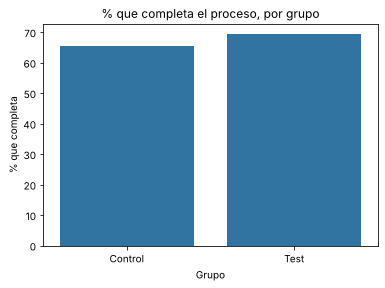

In [79]:
plt.figure(figsize=(6, 4))
tasa_grupo = por_cliente.groupby("grupo")["completo_pct"].mean()
sns.barplot(x=tasa_grupo.index, y=tasa_grupo.values, color=eda.COLOR)
plt.title("% que completa el proceso, por grupo")
plt.xlabel("Grupo")
plt.ylabel("% que completa")
plt.show()

**➜ Qué nos llevamos para el proyecto:** gráfico para la diapositiva de H1: la diferencia es clara y la incertidumbre, muy pequeña.

> **➜ O que tiramos para o projecto:** gráfico para o slide de H1: a diferença é clara e a incerteza, muito pequena.

#### H1 por periodo (relacionado con E7)

En la Parte 2 se vio que el reparto entre grupos cambia el 8 de mayo: hasta esa semana el Test tiene más clientes, y en esas semanas todos completan más. Si la ventaja del Test se debe en parte a eso, debería ser menor dentro de cada periodo.

> Na Parte 2 viu-se que a repartição entre grupos muda a 8 de Maio. Se a vantagem do Test vier em parte disso, deve ser menor dentro de cada período.

**Por qué lo añadimos:** si la ventaja viniera del cambio de reparto del 8 de mayo y no del diseño, la conclusión de H1 sería engañosa. Hay que comprobarlo antes de recomendar nada.

> **Porque o acrescentámos:** se a vantagem viesse da mudança de repartição de 8 de Maio e não do design, a conclusão da H1 seria enganadora. É preciso verificá-lo antes de recomendar alguma coisa.

**Cómo funciona**

1. `contraste_por_categoria` (en `src/contrastes.py`) recorre con un bucle `for` la lista de periodos.
2. En cada uno se queda con los clientes de ese periodo y llama a `contraste_medias` (Test frente a Control).
3. Guarda cada resultado en una lista y la convierte en tabla con `pd.DataFrame(lista, index=orden)`: una fila por periodo.

**Por qué así:** comparar dentro de cada periodo quita el efecto de cuándo entró cada grupo. La misma función sirve después para edades y meses.

**Herramientas:** bucle `for`, filtros, `append`, `pd.DataFrame` con una lista de diccionarios.

**Dónde se vio en clase:** `for` → Semana 1 · 1.2 Control de flujo; `append` → Semana 1 · 1.1 Estructuras de datos; `pd.DataFrame` → Semana 2 · 2.1 Pandas.

> **Como funciona (português)**
>
> 1. O `contraste_por_categoria` (em `src/contrastes.py`) percorre com um ciclo `for` a lista de períodos.
> 2. Em cada um fica com os clientes desse período e chama o `contraste_medias` (Test contra Control).
> 3. Guarda cada resultado numa lista e transforma-a numa tabela com `pd.DataFrame(lista, index=orden)`: uma linha por período.
>
> **Porquê assim:** comparar dentro de cada período tira o efeito de quando entrou cada grupo. A mesma função serve depois para idades e meses.
>
> **Onde se deu nas aulas:** `for` → Semana 1 · 1.2 Control de flujo; `append` → Semana 1 · 1.1 Estructuras de datos; `pd.DataFrame` → Semana 2 · 2.1 Pandas.

In [80]:
orden_periodos = ["Hasta el 7 de mayo", "Desde el 8 de mayo"]
contrastes.contraste_por_categoria(por_cliente, "periodo", "completo_pct", alfa, orden_periodos)

,clientes_test,clientes_referencia,media_test,media_referencia,diferencia,t,p_valor,decision
Hasta el 7 de mayo,22931,18674,71.25,67.94,3.31,7.29,< 0.0001,Se rechaza H0
Desde el 8 de mayo,4030,4853,58.16,56.50,1.66,1.58,0.1147,No se puede rechazar H0


**➜ Qué nos llevamos para el proyecto:** hasta el 7 de mayo (82 % de los clientes) la ventaja es de +3,3 puntos y significativa. Desde el 8 de mayo baja a +1,7 y **no es significativa** (p = 0,11). La conclusión de H1 se mantiene, pero la ventaja real puede ser algo menor que los 3,7 puntos totales.

> **➜ O que tiramos para o projecto:** até 7 de Maio (82 % dos clientes) a vantagem é de +3,3 pontos e significativa. A partir de 8 de Maio desce para +1,7 e **não é significativa** (p = 0,11). A conclusão de H1 mantém-se, mas a vantagem real pode ser um pouco menor do que os 3,7 pontos totais.

#### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** lo hacemos primero **a mano** (diferencia / error típico, como en la lección) y después con `scipy`, para entender de dónde sale el número y comprobar que coinciden. El chi-cuadrado se añade porque da la V de Cramér, el tamaño del efecto.

> **Porque o fizemos assim:** fazemo-lo primeiro **à mão** (diferença / erro padrão, como na lição) e depois com o `scipy`, para perceber de onde sai o número e confirmar que coincidem. O qui-quadrado junta-se porque dá o V de Cramér, o tamanho do efeito.

**Pregunta posible 1.** A mano usamos n1 + n2 − 2 grados de libertad, pero la t de Welch usa otros. ¿No está mal?
<br>*Pergunta possível 1. À mão usámos n1 + n2 − 2 graus de liberdade, mas o t de Welch usa outros. Não está mal?*

<details><summary>Respuesta / Resposta</summary>

Con más de 49.000 clientes, la distribución t es prácticamente la normal y los grados de libertad casi no cambian nada: a mano y con `scipy` sale t = 8,88 y un p-valor del orden de 10⁻¹⁹.

> Com mais de 49.000 clientes, a distribuição t é praticamente a normal e os graus de liberdade quase não mudam nada: à mão e com `scipy` sai t = 8,88.

</details>

**Pregunta posible 2.** Si el p-valor es tan pequeño, ¿el efecto es grande?
<br>*Pergunta possível 2. Se o p-valor é tão pequeno, o efeito é grande?*

<details><summary>Respuesta / Resposta</summary>

No necesariamente. El p-valor dice que la diferencia no es casualidad; el tamaño lo dice la V de Cramér (0,04, pequeño). Con muestras grandes, diferencias pequeñas salen muy significativas.

> Não necessariamente. O p-valor diz que a diferença não é acaso; o tamanho di-lo o V de Cramér (0,04, pequeno).

</details>

### 4.4 H2 · ¿La mejora llega al umbral del 5 %?

Vanguard solo considera rentable el nuevo diseño si la tasa de finalización sube al menos un **5 %**. El enunciado no dice si son 5 puntos o un 5 % relativo (D5 en `preguntas.md`), así que se contrastan las dos lecturas:

| Lectura | El Test debería llegar a | H0 | H1 |
|---|---|---|---|
| **a) 5 puntos** | 65,6 + 5 = 70,6 % | Test − Control ≤ 5 puntos | Test − Control > 5 puntos |
| **b) 5 % relativo** | 65,6 × 1,05 = 68,9 % | Test ≤ 1,05 × Control | Test > 1,05 × Control |

Son contrastes de **una cola** (solo interesa saber si se supera el umbral), con α = 0,05.

> A Vanguard só considera rentável o novo design se a taxa de conclusão subir pelo menos **5 %**. O enunciado não diz se são 5 pontos ou 5 % relativos (D5), por isso contrastam-se as duas leituras: a) 5 pontos (o Test devia chegar a 70,6 %) e b) 5 % relativo (68,9 %). São contrastes de **uma cauda**, com α = 0,05.

**Por qué lo añadimos:** la base de Emanuel decía «5 puntos» en el texto y calculaba «5 % relativo» en el código. Como el enunciado no aclara cuál es, se contrastan las dos y se dice cuál cambia la conclusión.

> **Porque o acrescentámos:** a base do Emanuel dizia «5 pontos» no texto e calculava «5 % relativos» no código. Como o enunciado não esclarece qual é, contrastam-se as duas e diz-se qual muda a conclusão.

#### Para entenderlo · No rechazar H0 no demuestra H0

En la lectura b) de H2 la mejora observada (5,7 %) **supera** el 5 % y aun así no se rechaza H0. No hay contradicción. H0 dice «la mejora real es del 5 % o menos». La muestra queda 0,4 puntos por encima del umbral, apenas un error típico (z = 1,04): una mejora real del 5 % justo también podría dar 5,7 % por azar, así que no hay pruebas para descartarla.

Volviendo al juicio: «no culpable» significa que las pruebas no bastan para condenar; la inocencia no queda demostrada. Por eso la conclusión de H2 se escribe «no se puede afirmar que la mejora llegue al 5 %», y no «la mejora no llega al 5 %».

> **Para perceber (português).** Na leitura b) da H2 a melhoria observada (5,7 %) **ultrapassa** os 5 % e mesmo assim não se rejeita a H0. Não há contradição. A H0 diz «a melhoria real é de 5 % ou menos». A amostra fica 0,4 pontos acima do limiar, apenas um erro padrão (z = 1,04): uma melhoria real de 5 % certos também poderia dar 5,7 % por acaso, por isso não há provas para a descartar. Voltando ao julgamento: «não culpado» significa que as provas não chegam para condenar; a inocência não fica demonstrada. Por isso a conclusão da H2 escreve-se «não se pode afirmar que a melhoria chegue aos 5 %», e não «a melhoria não chega aos 5 %».

**Cómo funciona**

1. **Paso a paso (lectura a):** el estadístico es la diferencia menos el umbral, dividida entre el mismo error típico de H1: cuántos errores típicos está la mejora por encima (o por debajo) de los 5 puntos.
2. Como el contraste es de una cola (derecha), el p-valor es `st.t.sf(estadistico, gl)` sin multiplicar por 2: en la lección, el de dos colas es `st.t.sf(abs(estadistico), gl) * 2` porque cuenta las dos colas.
3. **Con scipy:** sumar 5 a cada valor del Control sube su media 5 puntos sin cambiar su dispersión. Así `contraste_medias(test, control + 5, alfa, una_cola=True)` contrasta si el Test supera al «Control + 5 puntos» (lectura a). Por dentro llama a `st.ttest_ind`, que da el p-valor de dos colas, y lo pasa a una cola con la misma idea: la mitad si t es positivo (1 menos la mitad si es negativo).
4. Multiplicar el Control por 1,05 hace lo mismo para la lectura b: el contraste compara el Test con «Control × 1,05».

**Por qué así:** el contraste no puede ser «la diferencia es 3,7 y 3,7 es menor que 5», porque 3,7 es una estimación con margen de error. El contraste dice si, teniendo en cuenta ese margen, se puede afirmar que el umbral se supera.

**Herramientas:** operaciones con Series, `st.t.sf`, `st.ttest_ind`, `contraste_medias` con `una_cola=True`.

**Dónde se vio en clase:** `st.t.sf`, `st.ttest_ind` → Semana 5 · 5.12 Contrastes de hipótesis; `contraste_medias` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. **Passo a passo (leitura a):** a estatística é a diferença menos o limiar, dividida pelo mesmo erro padrão de H1: quantos erros padrão está a melhoria acima (ou abaixo) dos 5 pontos.
> 2. Como o contraste é de uma cauda (direita), o p-valor é `st.t.sf(estadistico, gl)` sem multiplicar por 2: na lição, o de duas caudas é `st.t.sf(abs(estadistico), gl) * 2` porque conta as duas caudas.
> 3. **Com scipy:** somar 5 a cada valor do Control sobe a sua média 5 pontos sem mudar a dispersão. Assim o `contraste_medias(test, control + 5, alfa, una_cola=True)` contrasta se o Test supera o «Control + 5 pontos» (leitura a). Por dentro chama o `st.ttest_ind`, que dá o p-valor de duas caudas, e passa-o a uma cauda com a mesma ideia: metade se t for positivo (1 menos metade se for negativo).
> 4. Multiplicar o Control por 1,05 faz o mesmo para a leitura b: o contraste compara o Test com «Control × 1,05».
>
> **Porquê assim:** o contraste não pode ser «a diferença é 3,7 e 3,7 é menor do que 5», porque 3,7 é uma estimativa com margem de erro. O contraste diz se, tendo em conta essa margem, se pode afirmar que o limiar é ultrapassado.
>
> **Onde se deu nas aulas:** `st.t.sf`, `st.ttest_ind` → Semana 5 · 5.12 Contrastes de hipótesis; `contraste_medias` → funções nossas (tabela do guia, no início).

In [81]:
umbral = config.UMBRAL_MEJORA  # 5 puntos

# Lectura a), paso a paso. H0: Test - Control <= 5 puntos   H1: Test - Control > 5 puntos
estadistico_umbral = (diferencia - umbral) / error_tipico
p_valor_umbral = st.t.sf(estadistico_umbral, n_test + n_control - 2)  # una cola (derecha)
print(f"Mejora: {round(diferencia, 2)} puntos   t = {round(estadistico_umbral, 2)}   p-valor = {round(p_valor_umbral, 4)}")
if p_valor_umbral > alfa:
    print("No se puede rechazar H0: no hay pruebas de que la mejora supere los 5 puntos")
else:
    print("Se rechaza H0: la mejora supera los 5 puntos")

# Las dos lecturas con scipy
h2_puntos = contrastes.contraste_medias(test, control + umbral, alfa, una_cola=True)
h2_relativo = contrastes.contraste_medias(test, control * (1 + umbral / 100), alfa, una_cola=True)
pd.DataFrame([h2_puntos, h2_relativo], index=["H2a: mejora > 5 puntos", "H2b: mejora > 5 % relativo"])

Mejora: 3.71 puntos   t = -3.08   p-valor = 0.999
No se puede rechazar H0: no hay pruebas de que la mejora supere los 5 puntos


,clientes_test,clientes_referencia,media_test,media_referencia,diferencia,t,p_valor,decision
H2a: mejora > 5 puntos,26961,23527,69.29,70.58,-1.29,-3.08,0.999,No se puede rechazar H0
H2b: mejora > 5 % relativo,26961,23527,69.29,68.86,0.43,1.01,0.1565,No se puede rechazar H0


**➜ Qué nos llevamos para el proyecto:** **ninguna de las dos lecturas se puede afirmar.** a) 5 puntos: la mejora (3,7) está claramente por debajo (p = 0,999). b) 5 % relativo: la mejora observada es de un 5,7 %, por encima del 5 %, pero la diferencia es tan pequeña que no es significativa (p = 0,16).

> **➜ O que tiramos para o projecto:** **nenhuma das duas leituras se pode afirmar.** a) 5 pontos: a melhoria (3,7) está claramente abaixo (p = 0,999). b) 5 % relativo: a melhoria observada é de 5,7 %, acima dos 5 %, mas a diferença é tão pequena que não é significativa (p = 0,16).

**Cómo funciona**

1. Repite H2 dentro de cada periodo con `contraste_por_categoria`, primero con `sumar=5` (lectura a) y después con `multiplicar=1.05` (lectura b), las dos con `una_cola=True`.
2. `display` enseña la primera tabla; la segunda sale al final de la celda.

**Por qué así:** si el reparto desigual en el tiempo infla la ventaja (E7), el umbral sería aún más difícil de alcanzar dentro de cada periodo.

**Herramientas:** `contraste_por_categoria` con parámetros, `display`.

**Dónde se vio en clase:** `contraste_por_categoria` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. Repete H2 dentro de cada período com o `contraste_por_categoria`, primeiro com `sumar=5` (leitura a) e depois com `multiplicar=1.05` (leitura b), as duas com `una_cola=True`.
> 2. O `display` mostra a primeira tabela; a segunda aparece no fim da célula.
>
> **Porquê assim:** se a repartição desigual no tempo inflaciona a vantagem (E7), o limiar seria ainda mais difícil de alcançar dentro de cada período.
>
> **Onde se deu nas aulas:** `contraste_por_categoria` → funções nossas (tabela do guia, no início).

In [82]:
print("Lectura a) mejora de más de 5 puntos")
display(contrastes.contraste_por_categoria(por_cliente, "periodo", "completo_pct", alfa, orden_periodos,
                                           sumar=umbral, una_cola=True))
print("Lectura b) mejora de más de un 5 % relativo")
contrastes.contraste_por_categoria(por_cliente, "periodo", "completo_pct", alfa, orden_periodos,
                                   multiplicar=1 + umbral / 100, una_cola=True)

Lectura a) mejora de más de 5 puntos


,clientes_test,clientes_referencia,media_test,media_referencia,diferencia,t,p_valor,decision
Hasta el 7 de mayo,22931,18674,71.25,72.94,-1.69,-3.73,0.9999,No se puede rechazar H0
Desde el 8 de mayo,4030,4853,58.16,61.50,-3.34,-3.17,0.9992,No se puede rechazar H0


Lectura b) mejora de más de un 5 % relativo


,clientes_test,clientes_referencia,media_test,media_referencia,diferencia,t,p_valor,decision
Hasta el 7 de mayo,22931,18674,71.25,71.34,-0.09,-0.19,0.5746,No se puede rechazar H0
Desde el 8 de mayo,4030,4853,58.16,59.33,-1.16,-1.08,0.8595,No se puede rechazar H0


**➜ Qué nos llevamos para el proyecto:** dentro de cada periodo tampoco se supera ninguno de los dos umbrales. **H2: con estos datos no se puede afirmar que el nuevo diseño alcance el 5 % que Vanguard pide**, se lea como se lea. Para la presentación: la mejora es real (H1) pero, con la lectura de 5 puntos, no compensa el coste; con la lectura relativa, queda en el límite. Ojo: no rechazar H0 no demuestra que el diseño no funcione; quiere decir que no se ha demostrado que la mejora supere el mínimo exigido.

> **➜ O que tiramos para o projecto:** dentro de cada período também não se supera nenhum dos dois limiares. **H2: com estes dados não se pode afirmar que o novo design alcance os 5 % que a Vanguard pede**, seja qual for a leitura. Para a apresentação: a melhoria é real (H1) mas, com a leitura de 5 pontos, não compensa o custo; com a leitura relativa, fica no limite. Atenção: não rejeitar H0 não demonstra que o design não funciona; quer dizer que não se demonstrou que a melhoria supera o mínimo exigido.

#### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** contrastamos las dos lecturas del 5 % porque el enunciado no aclara cuál es y dan conclusiones distintas en la muestra (con 5 puntos, el Test no llega; con 5 % relativo, sí llega en la muestra). Lo hacemos también por periodo, por el cambio de reparto del 8 de mayo.

> **Porque o fizemos assim:** contrastamos as duas leituras dos 5 % porque o enunciado não esclarece qual é e dão conclusões diferentes na amostra. Fazemo-lo também por período, por causa da mudança de repartição de 8 de Maio.

**Pregunta posible 1.** ¿Por qué se suma 5 al Control y no se resta al Test?
<br>*Pergunta possível 1. Porque se soma 5 ao Control e não se subtrai ao Test?*

<details><summary>Respuesta / Resposta</summary>

Da lo mismo: comparar Test con «Control + 5» es comparar si Test − Control supera 5. Sumar 5 a todos los valores del Control sube su media 5 puntos sin cambiar su dispersión.

> Dá o mesmo: comparar Test com «Control + 5» é ver se Test − Control ultrapassa 5. Somar 5 a todos os valores do Control sobe a média 5 pontos sem mudar a dispersão.

</details>

**Pregunta posible 2.** Si Vanguard os dice cuál es el umbral, ¿cambia la conclusión?
<br>*Pergunta possível 2. Se a Vanguard vos disser qual é o limiar, muda a conclusão?*

<details><summary>Respuesta / Resposta</summary>

Si son 5 puntos, la conclusión es clara: no se alcanza (p = 0,999). Si es un 5 % relativo, la mejora observada (5,7 %) lo supera, pero no se puede afirmar estadísticamente (p = 0,16): haría falta más datos.

> Se forem 5 pontos, a conclusão é clara: não se alcança. Se forem 5 % relativos, a melhoria observada ultrapassa-o, mas não se pode afirmar estatisticamente (p = 0,16).

</details>

### 4.5 Otros contrastes elegidos

El enunciado pide al menos otro contraste a elección. Se hacen los que salieron de las preguntas de los días 1 a 3 (`preguntas.md`).

> O enunciado pede pelo menos outro contraste à escolha. Fazem-se os que saíram das perguntas dos dias 1 a 3 (`preguntas.md`).

**Por qué lo añadimos:** el enunciado pide al menos otra hipótesis a elección. Estas salen de lo que vimos en las Partes 2 y 3 y explican por qué el Test completa más pero no tanto como se esperaba: más errores, sobre todo en `step_1` y en los mayores, y una ventaja que baja con el tiempo.

> **Porque o acrescentámos:** o enunciado pede pelo menos outra hipótese à escolha. Estas saem do que vimos nas Partes 2 e 3 e explicam porque é que o Test conclui mais mas não tanto como se esperava: mais erros, sobretudo no `step_1` e nos mais velhos, e uma vantagem que baixa com o tempo.

#### Para entenderlo · Cuidado al hacer muchos contrastes

Con α = 0,05, cada contraste en el que H0 es cierta tiene un 5 % de probabilidad de salir «significativo» por pura casualidad (un falso positivo). En esta sección hay 18 contrastes (4 tramos de edad dos veces, 4 meses, 4 pasos, H5 y H9). Aunque no hubiera ningún efecto real, lo esperable sería que alguno saliera significativo.

Cómo lo tenemos en cuenta:

- Se mira el **patrón** y no un contraste suelto: ¿la ventaja baja mes a mes? ¿Los errores del Test crecen con la edad?
- Un p-valor de 0,016 (45-59 años en H3) se lee con más cautela que uno menor de 0,0001.
- Cada contraste sale de una pregunta planteada antes (Partes 2 y 3, `preguntas.md`), no de probar combinaciones hasta encontrar algo.

Existen métodos para ajustar α cuando se hacen muchos contrastes; no se vieron en clase y no se usan aquí.

> **Para perceber (português).** Com α = 0,05, cada teste em que a H0 é verdadeira tem 5 % de probabilidade de sair «significativo» por puro acaso (um falso positivo). Nesta secção há 18 testes (4 escalões de idade duas vezes, 4 meses, 4 passos, H5 e H9): mesmo sem nenhum efeito real, o esperável seria que algum saísse significativo. Como o temos em conta: olha-se para o **padrão** e não para um teste solto (a vantagem baixa mês a mês? os erros do Test crescem com a idade?); um p-valor de 0,016 lê-se com mais cautela do que um menor que 0,0001; cada teste sai de uma pergunta feita antes, não de experimentar combinações até encontrar alguma coisa. Há métodos para ajustar o α quando se fazem muitos testes; não foram dados nas aulas e não se usam aqui.

#### H5 · ¿El nuevo diseño tiene más clientes con errores?

- **H0:** el % de clientes con algún paso hacia atrás es igual en los dos grupos.
- **H1:** es distinto (dos colas). α = 0,05.

> **H0:** a % de clientes com algum passo para trás é igual nos dois grupos. **H1:** é diferente (duas caudas).

**Por qué lo añadimos:** el KPI 3 (Parte 3) es el único en el que gana el Control. Si fuera casualidad, no habría nada que arreglar.

> **Porque o acrescentámos:** o KPI 3 (Parte 3) é o único em que ganha o Control. Se fosse acaso, não haveria nada a corrigir.

**Cómo funciona**

1. Igual que H1, pero con `error_pct` (100 si el cliente volvió atrás al menos una vez, 0 si no).
2. Se hace con la t de Welch (`contraste_medias`) y con el chi-cuadrado (`contraste_chi2`).

**Por qué así:** en la Parte 3 el Test tenía más errores (33 % de los clientes frente a 26 %). Este contraste dice si esa diferencia puede ser casualidad.

**Herramientas:** `loc`, `contraste_medias`, `contraste_chi2`, `display`.

**Dónde se vio en clase:** `loc` → Semana 2 · 2.1 Pandas; `contraste_medias`, `contraste_chi2` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. Igual a H1, mas com `error_pct` (100 se o cliente voltou atrás pelo menos uma vez, 0 se não).
> 2. Faz-se com o t de Welch (`contraste_medias`) e com o qui-quadrado (`contraste_chi2`).
>
> **Porquê assim:** na Parte 3 o Test tinha mais erros (33 % dos clientes contra 26 %). Este contraste diz se essa diferença pode ser acaso.
>
> **Onde se deu nas aulas:** `loc` → Semana 2 · 2.1 Pandas; `contraste_medias`, `contraste_chi2` → funções nossas (tabela do guia, no início).

In [83]:
error_test = por_cliente.loc[por_cliente["grupo"] == "Test", "error_pct"]
error_control = por_cliente.loc[por_cliente["grupo"] == "Control", "error_pct"]
h5 = contrastes.contraste_medias(error_test, error_control, alfa)
display(pd.DataFrame([h5], index=["H5: clientes con algún error"]))

tabla_error, h5_chi2 = contrastes.contraste_chi2(por_cliente, "grupo", "error_pct", alfa)
pd.DataFrame([h5_chi2], index=["grupo x error"])

,clientes_test,clientes_referencia,media_test,media_referencia,diferencia,t,p_valor,decision
H5: clientes con algún error,26961,23527,33.39,25.80,7.59,18.74,< 0.0001,Se rechaza H0


,chi2,p_valor,decision,v_cramer
grupo x error,345.08,< 0.0001,Se rechaza H0,0.08


**➜ Qué nos llevamos para el proyecto:** **H5 confirmada:** el nuevo diseño tiene 7,6 puntos más de clientes con algún error (33,4 % frente a 25,8 %), y es la diferencia más clara de todo el test (t = 18,7). Más clientes terminan, pero más se pierden por el camino.

> **➜ O que tiramos para o projecto:** **H5 confirmada:** o novo design tem mais 7,6 pontos de clientes com algum erro (33,4 % contra 25,8 %), e é a diferença mais clara de todo o teste (t = 18,7). Mais clientes terminam, mas mais se perdem pelo caminho.

#### H3 · ¿La ventaja del nuevo diseño cambia con la edad?

Para cada tramo de edad: **H0:** Test y Control completan igual; **H1:** completan distinto. α = 0,05.

> Para cada escalão de idade: **H0:** Test e Control concluem igual; **H1:** concluem de forma diferente.

**Por qué lo añadimos:** en la Parte 2 la ventaja del Test cambiaba con la edad (+6,8 en menores de 30, +1,8 en 45-59). Hay que saber si eso es real para recomendar a quién dirigir el diseño.

> **Porque o acrescentámos:** na Parte 2 a vantagem do Test mudava com a idade. É preciso saber se é real para recomendar a quem dirigir o design.

**Cómo funciona**

1. `contraste_por_categoria` repite el contraste de H1 dentro de cada tramo de edad, en el orden de `config.NOMBRES_EDAD`.

**Por qué así:** si el nuevo diseño ayuda más a unos clientes que a otros, la recomendación puede ser más concreta. Hay que tener cuidado: cuantos más contrastes se hacen, más fácil es que alguno salga significativo por azar, así que un p-valor cercano a 0,05 es un resultado débil.

**Herramientas:** `contraste_por_categoria`.

**Dónde se vio en clase:** `contraste_por_categoria` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. O `contraste_por_categoria` repete o contraste de H1 dentro de cada escalão de idade, pela ordem de `config.NOMBRES_EDAD`.
>
> **Porquê assim:** se o novo design ajudar mais uns clientes do que outros, a recomendação pode ser mais concreta. É preciso cuidado: quantos mais contrastes se fazem, mais fácil é que algum saia significativo por acaso, por isso um p-valor perto de 0,05 é um resultado fraco.
>
> **Onde se deu nas aulas:** `contraste_por_categoria` → funções nossas (tabela do guia, no início).

In [84]:
contrastes.contraste_por_categoria(por_cliente, "tramo_edad", "completo_pct", alfa, config.NOMBRES_EDAD)

,clientes_test,clientes_referencia,media_test,media_referencia,diferencia,t,p_valor,decision
<30,4596,3935,74.41,67.62,6.79,6.89,< 0.0001,Se rechaza H0
30-44,7488,6376,70.25,67.47,2.77,3.51,0.0004,Se rechaza H0
45-59,8260,7274,68.86,67.06,1.80,2.40,0.0164,Se rechaza H0
60+,6617,5941,65.20,60.38,4.82,5.58,< 0.0001,Se rechaza H0


**➜ Qué nos llevamos para el proyecto:** el nuevo diseño completa más en **todos** los tramos de edad. La ventaja es mayor en los menores de 30 (+6,8) y en los de 60 o más (+4,8); en 45-59 es pequeña (+1,8) y su p-valor (0,016) es el más débil.

> **➜ O que tiramos para o projecto:** o novo design conclui mais em **todos** os escalões de idade. A vantagem é maior nos menores de 30 (+6,8) e nos de 60 ou mais (+4,8); em 45-59 é pequena (+1,8) e o seu p-valor (0,016) é o mais fraco.

#### H7 · ¿El nuevo diseño provoca más errores en los clientes mayores?

Para cada tramo de edad: **H0:** el % de clientes con algún error es igual en Test y Control; **H1:** es distinto.

> Para cada escalão de idade: **H0:** a % de clientes com algum erro é igual no Test e no Control; **H1:** é diferente.

**Por qué lo añadimos:** en la Parte 3 los errores del Test subían con la edad. Si se confirma, la recomendación es concreta: revisar el diseño pensando en los clientes mayores.

> **Porque o acrescentámos:** na Parte 3 os erros do Test subiam com a idade. Se se confirmar, a recomendação é concreta: rever o design a pensar nos clientes mais velhos.

**Cómo funciona**

1. La misma función, ahora con `error_pct`.

**Por qué así:** en la Parte 3 (K9) los errores del Test subían con la edad. Aquí se comprueba tramo a tramo.

**Herramientas:** `contraste_por_categoria`.

**Dónde se vio en clase:** `contraste_por_categoria` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. A mesma função, agora com `error_pct`.
>
> **Porquê assim:** na Parte 3 (K9) os erros do Test subiam com a idade. Aqui verifica-se escalão a escalão.
>
> **Onde se deu nas aulas:** `contraste_por_categoria` → funções nossas (tabela do guia, no início).

In [85]:
contrastes.contraste_por_categoria(por_cliente, "tramo_edad", "error_pct", alfa, config.NOMBRES_EDAD)

,clientes_test,clientes_referencia,media_test,media_referencia,diferencia,t,p_valor,decision
<30,4596,3935,29.26,26.33,2.94,3.02,0.0025,Se rechaza H0
30-44,7488,6376,28.06,23.32,4.74,6.39,< 0.0001,Se rechaza H0
45-59,8260,7274,35.98,25.86,10.12,13.74,< 0.0001,Se rechaza H0
60+,6617,5941,39.07,28.04,11.02,13.18,< 0.0001,Se rechaza H0


**➜ Qué nos llevamos para el proyecto:** el Test tiene más errores en todos los tramos, pero la diferencia crece con la edad: +2,9 puntos en menores de 30 y **+10 a +11 puntos desde los 45 años**. El nuevo diseño confunde sobre todo a los clientes mayores.

> **➜ O que tiramos para o projecto:** o Test tem mais erros em todos os escalões, mas a diferença cresce com a idade: +2,9 pontos nos menores de 30 e **+10 a +11 pontos a partir dos 45 anos**. O novo design confunde sobretudo os clientes mais velhos.

#### H6 · ¿La ventaja del nuevo diseño se mantiene en el tiempo?

Para cada mes de inicio: **H0:** Test y Control completan igual; **H1:** completan distinto.

> Para cada mês de início: **H0:** Test e Control concluem igual; **H1:** concluem de forma diferente.

**Por qué lo añadimos:** el enunciado pregunta si la duración fue suficiente. Si la ventaja baja mes a mes, no se puede asegurar que dure.

> **Porque o acrescentámos:** o enunciado pergunta se a duração foi suficiente. Se a vantagem baixa mês a mês, não se pode garantir que dure.

**Cómo funciona**

1. La misma función, por mes del primer clic de cada cliente (`mes_inicio`).

**Por qué así:** en la Parte 2 (E4) la ventaja bajaba mes a mes. Si en los últimos meses no es significativa, puede haber un efecto novedad: el diseño nuevo llama la atención al principio y la ventaja se diluye.

**Herramientas:** `contraste_por_categoria`.

**Dónde se vio en clase:** `contraste_por_categoria` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. A mesma função, por mês do primeiro clique de cada cliente (`mes_inicio`).
>
> **Porquê assim:** na Parte 2 (E4) a vantagem descia mês a mês. Se nos últimos meses não for significativa, pode haver um efeito novidade: o design novo chama a atenção ao princípio e a vantagem dilui-se.
>
> **Onde se deu nas aulas:** `contraste_por_categoria` → funções nossas (tabela do guia, no início).

In [86]:
contrastes.contraste_por_categoria(por_cliente, "mes_inicio", "completo_pct", alfa, ["Marzo", "Abril", "Mayo", "Junio"])

,clientes_test,clientes_referencia,media_test,media_referencia,diferencia,t,p_valor,decision
Marzo,5834,4743,78.81,73.58,5.23,6.27,< 0.0001,Se rechaza H0
Abril,16173,13269,69.07,66.40,2.68,4.88,< 0.0001,Se rechaza H0
Mayo,3269,3493,60.54,57.77,2.77,2.31,0.0207,Se rechaza H0
Junio,1685,2022,55.43,54.95,0.48,0.30,0.7677,No se puede rechazar H0


**➜ Qué nos llevamos para el proyecto:** la ventaja es significativa en marzo (+5,2), abril (+2,7) y mayo (+2,8), pero **no en junio** (+0,5, p = 0,77). Junio tiene pocos clientes (3.707) y menos días para terminar, así que no prueba un efecto novedad, pero sí pide prudencia: la ventaja no es estable en el tiempo.

> **➜ O que tiramos para o projecto:** a vantagem é significativa em Março (+5,2), Abril (+2,7) e Maio (+2,8), mas **não em Junho** (+0,5, p = 0,77). Junho tem poucos clientes (3.707) e menos dias para terminar, por isso não prova um efeito novidade, mas pede prudência: a vantagem não é estável no tempo.

#### H8 · ¿El tiempo en cada paso es distinto entre grupos?

Para cada paso: **H0:** el tiempo medio es igual en Test y Control; **H1:** es distinto. En la Parte 3 el Test era más rápido en todos los pasos salvo `step_1`.

> Para cada passo: **H0:** o tempo médio é igual no Test e no Control; **H1:** é diferente. Na Parte 3 o Test era mais rápido em todos os passos menos no `step_1`.

**Por qué lo añadimos:** el KPI 2 dice que el Test es más lento solo en `step_1`. El contraste confirma que esa pantalla es la que hay que revisar.

> **Porque o acrescentámos:** o KPI 2 diz que o Test é mais lento só no `step_1`. O contraste confirma que é esse ecrã que é preciso rever.

**Cómo funciona**

1. Se queda con los tiempos válidos de la Parte 3: sin `confirm` y sin pausas de más de 30 minutos (`config.LIMITE_TIEMPO_SEG`).
2. Los tiempos están muy sesgados a la derecha (muchos pasos cortos y algunos muy largos). Como en la lección de normalidad, se transforman con `np.log1p` (logaritmo de 1 + x), que acerca la distribución a una campana.
3. Dibuja los dos histogramas, antes y después, con `plt.subplots(1, 2)` y `sns.histplot`.
4. Enseña las medianas en segundos (`kpis.tiempo_por_paso`) y contrasta el logaritmo del tiempo paso a paso con `contraste_por_categoria`.

**Por qué así:** con datos tan sesgados, unos pocos tiempos muy largos pesarían demasiado en la media. El logaritmo reduce ese peso. Aviso: aquí la unidad es el clic, y un mismo cliente puede tener varios clics en el mismo paso, así que las observaciones no son del todo independientes. El resultado es orientativo.

**Herramientas:** filtros, `copy`, `np.log1p`, `plt.subplots`, `sns.histplot`, `kpis.tiempo_por_paso`, `contraste_por_categoria`.

**Dónde se vio en clase:** `copy` → Semana 2 · 2.2 Limpieza; `np.log1p` → Semana 5 · 5.7 Normalidad y correlación; `plt.subplots` → Gráficos de las clases (semanas 2 y 5); `sns.histplot` → Semana 2 · EDA básico (self-guided); `tiempo_por_paso`, `contraste_por_categoria` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. Fica com os tempos válidos da Parte 3: sem `confirm` e sem pausas de mais de 30 minutos.
> 2. Os tempos estão muito enviesados à direita. Como na lição de normalidade, transformam-se com `np.log1p` (logaritmo de 1 + x), que aproxima a distribuição de um sino.
> 3. Desenha os dois histogramas, antes e depois, com `plt.subplots(1, 2)` e `sns.histplot`.
> 4. Mostra as medianas em segundos (`kpis.tiempo_por_paso`) e contrasta o logaritmo do tempo passo a passo com o `contraste_por_categoria`.
>
> **Porquê assim:** com dados tão enviesados, uns poucos tempos muito longos pesariam demasiado na média. O logaritmo reduz esse peso. Aviso: aqui a unidade é o clique, e um mesmo cliente pode ter vários cliques no mesmo passo, por isso as observações não são totalmente independentes. O resultado é orientativo.
>
> **Onde se deu nas aulas:** `copy` → Semana 2 · 2.2 Limpieza; `np.log1p` → Semana 5 · 5.7 Normalidad y correlación; `plt.subplots` → Gráficos de las clases (semanas 2 y 5); `sns.histplot` → Semana 2 · EDA básico (self-guided); `tiempo_por_paso`, `contraste_por_categoria` → funções nossas (tabela do guia, no início).

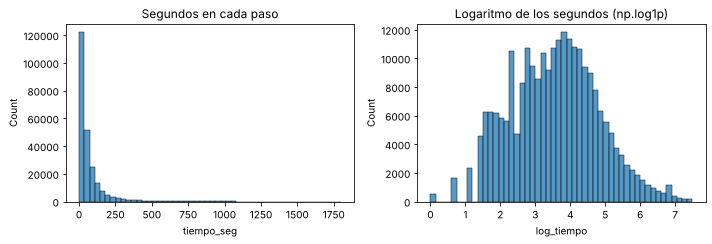

Mediana de segundos en cada paso:


grupo,Control,Test
process_step,,
start,20.00,14.00
step_1,20.00,27.00
step_2,64.00,61.00
step_3,72.00,57.00


,clientes_test,clientes_referencia,media_test,media_referencia,diferencia,t,p_valor,decision
start,46220,35658,3.02,3.20,-0.18,-20.43,< 0.0001,Se rechaza H0
step_1,35487,26010,3.39,3.15,0.24,27.09,< 0.0001,Se rechaza H0
step_2,29559,24299,3.98,4.03,-0.05,-5.43,< 0.0001,Se rechaza H0
step_3,23943,20332,4.20,4.31,-0.11,-10.83,< 0.0001,Se rechaza H0


In [87]:
validos = pasos[(pasos["process_step"] != "confirm") & (pasos["tiempo_seg"] <= config.LIMITE_TIEMPO_SEG)].copy()
validos["log_tiempo"] = np.log1p(validos["tiempo_seg"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(validos["tiempo_seg"], bins=50, ax=ax1, color=eda.COLOR)
ax1.set_title("Segundos en cada paso")
sns.histplot(validos["log_tiempo"], bins=50, ax=ax2, color=eda.COLOR)
ax2.set_title("Logaritmo de los segundos (np.log1p)")
plt.tight_layout()
plt.show()

print("Mediana de segundos en cada paso:")
display(kpis.tiempo_por_paso(pasos, config.LIMITE_TIEMPO_SEG, "median").loc[ORDEN_PASOS[:-1]])
contrastes.contraste_por_categoria(validos, "process_step", "log_tiempo", alfa, ORDEN_PASOS[:-1])

**➜ Qué nos llevamos para el proyecto:** las diferencias de tiempo son significativas en los cuatro pasos. El Test es más rápido en `start`, `step_2` y `step_3`, y **más lento en `step_1`** (t positivo): es el paso que hay que revisar, el mismo desde el que más vuelven atrás (Parte 3).

> **➜ O que tiramos para o projecto:** as diferenças de tempo são significativas nos quatro passos. O Test é mais rápido no `start`, `step_2` e `step_3`, e **mais lento no `step_1`** (t positivo): é o passo a rever, o mesmo de onde mais voltam atrás (Parte 3).

#### H9 · Bonus · ¿El número de acciones (clics) por cliente es distinto entre grupos?

El enunciado propone, como tarea extra, contrastar si el número de acciones es distinto entre Test y Control.

- **H0:** el número medio de clics por cliente es igual en los dos grupos.
- **H1:** es distinto (dos colas). α = 0,05.

> **H9 · Bónus.** **H0:** o número médio de cliques por cliente é igual nos dois grupos. **H1:** é diferente (duas caudas).

**Por qué lo añadimos:** es la tarea extra del enunciado y confirma con otro dato (clics) que el nuevo diseño provoca vueltas atrás.

> **Porque o acrescentámos:** é a tarefa extra do enunciado e confirma com outro dado (cliques) que o novo design provoca voltas atrás.

**Cómo funciona**

1. `pasos.groupby("client_id").size()` cuenta los clics de cada cliente y `map` lo lleva a la tabla de clientes (`clics`).
2. Enseña la media y la mediana de clics por grupo (`groupby` + `agg`).
3. Compara las medias con la t de Welch (`contraste_medias`), como H1.

**Por qué así:** la unidad es el cliente, como en los demás contrastes. Con más de 23.000 clientes por grupo, la media de clics sigue una distribución casi normal aunque los clics de cada cliente no la sigan (teorema del límite central, lección de contrastes).

**Herramientas:** `groupby`, `size`, `map`, `agg`, `loc`, `contraste_medias`.

**Dónde se vio en clase:** `groupby`, `size`, `agg` → Semana 2 · 2.4 Agregar; `map` → Semana 2 · 2.2 Limpieza; `loc` → Semana 2 · 2.1 Pandas; `contraste_medias` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. O `pasos.groupby("client_id").size()` conta os cliques de cada cliente e o `map` leva-os para a tabela de clientes (`clics`).
> 2. Mostra a média e a mediana de cliques por grupo (`groupby` + `agg`).
> 3. Compara as médias com o t de Welch (`contraste_medias`), como no H1.
>
> **Porquê assim:** a unidade é o cliente, como nos outros testes. Com mais de 23.000 clientes por grupo, a média de cliques segue uma distribuição quase normal mesmo que os cliques de cada cliente não a sigam (teorema do limite central).
>
> **Onde se deu nas aulas:** `groupby`, `size`, `agg` → Semana 2 · 2.4 Agregar; `map` → Semana 2 · 2.2 Limpieza; `loc` → Semana 2 · 2.1 Pandas; `contraste_medias` → funções nossas (tabela do guia, no início).

In [88]:
clics_por_cliente = pasos.groupby("client_id").size()
por_cliente["clics"] = por_cliente["client_id"].map(clics_por_cliente)
display(por_cliente.groupby("grupo")["clics"].agg(["mean", "median"]))

clics_test = por_cliente.loc[por_cliente["grupo"] == "Test", "clics"]
clics_control = por_cliente.loc[por_cliente["grupo"] == "Control", "clics"]
h9 = contrastes.contraste_medias(clics_test, clics_control, alfa)
pd.DataFrame([h9], index=["H9: clics por cliente"])

,mean,median
grupo,,
Control,5.97,5.00
Test,6.55,5.00


,clientes_test,clientes_referencia,media_test,media_referencia,diferencia,t,p_valor,decision
H9: clics por cliente,26961,23527,6.55,5.97,0.58,16.25,< 0.0001,Se rechaza H0


**➜ Qué nos llevamos:** **H9 confirmada:** el Test hace de media 0,58 clics más por cliente (6,55 frente a 5,97; t = 16,3, p < 0,0001). La mediana es la misma (5 clics): la diferencia la ponen los clientes que vuelven atrás. Encaja con H5 y con los recorridos de la Parte 3: el nuevo diseño no añade pasos, añade vueltas.

> **➜ O que tiramos:** **H9 confirmada:** o Test faz em média mais 0,58 cliques por cliente (6,55 contra 5,97; t = 16,3, p < 0,0001). A mediana é a mesma (5 cliques): a diferença vem dos clientes que voltam atrás. Bate certo com o H5 e com os percursos da Parte 3: o novo design não acrescenta passos, acrescenta voltas.

#### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** el enunciado pide al menos otra hipótesis. Elegimos las que explican el resultado y llevan a recomendaciones: errores (H5), edad (H3 y H7), tiempo (H6), tiempo por paso (H8) y clics (H9). Todas salen de preguntas que nos hicimos en las Partes 2 y 3.

> **Porque o fizemos assim:** o enunciado pede pelo menos outra hipótese. Escolhemos as que explicam o resultado e levam a recomendações: erros, idade, tempo, tempo por passo e cliques. Todas saem de perguntas que fizemos nas Partes 2 e 3.

**Pregunta posible 1.** ¿Por qué en H8 se usa el logaritmo del tiempo?
<br>*Pergunta possível 1. Porque é que na H8 se usa o logaritmo do tempo?*

<details><summary>Respuesta / Resposta</summary>

Porque los tiempos son muy asimétricos (muchos cortos y unos pocos larguísimos). `np.log1p` (lección de normalidad) los hace más simétricos y el contraste de medias es más fiable. La mediana de la Parte 3 cuenta lo mismo.

> Porque os tempos são muito assimétricos. O `np.log1p` (lição de normalidade) torna-os mais simétricos e o contraste de médias fica mais fiável.

</details>

**Pregunta posible 2.** ¿Por qué contrastar tramo a tramo y no una ANOVA?
<br>*Pergunta possível 2. Porquê contrastar escalão a escalão e não uma ANOVA?*

<details><summary>Respuesta / Resposta</summary>

Porque la pregunta es «¿Test y Control son distintos **dentro** de cada tramo?», que son cuatro comparaciones de dos grupos. La ANOVA compara las medias de tres o más grupos entre sí: contestaría otra pregunta.

> Porque a pergunta é «Test e Control são diferentes **dentro** de cada escalão?», que são quatro comparações de dois grupos. A ANOVA responderia a outra pergunta.

</details>

### 4.6 Evaluación del experimento

El enunciado pide responder tres preguntas: si el experimento estaba bien diseñado, si duró lo suficiente y qué datos faltan. Las dos primeras se apoyan en contrastes.

> O enunciado pede para responder a três perguntas: se o experimento estava bem desenhado, se durou o suficiente e que dados faltam. As duas primeiras apoiam-se em contrastes.

**Por qué lo añadimos:** Emanuel respondió la evaluación con los datos descriptivos. Las preguntas «¿el reparto fue aleatorio y equitativo?» y «¿hubo sesgo?» se pueden contestar con contrastes, y así se hace aquí.

> **Porque o acrescentámos:** o Emanuel respondeu à avaliação com dados descritivos. As perguntas «a repartição foi aleatória e equitativa?» e «houve enviesamento?» podem responder-se com contrastes, e é o que se faz aqui.

#### Para entenderlo · Las herramientas de la evaluación

- **Binomial (E1).** Si cada cliente fuera al Test con probabilidad 0,5, como al lanzar una moneda, el número de clientes del Test seguiría una binomial con n = 50.488 y p = 0,5. Lo esperable serían unos 25.244, con una desviación típica de unos 112 (√(n · 0,5 · 0,5)). Salen 26.961: unas 15 desviaciones típicas por encima, y por eso el p-valor es prácticamente 0.
- **Chi-cuadrado (E2 y el género en E3).** Compara lo que se observa en cada casilla de una tabla cruzada con lo que se esperaría si las dos variables no tuvieran relación. Cuanto mayor es la distancia total, menor es el p-valor.
- **t de Welch (E3).** La misma de H1, aplicada a cada variable del perfil.

Un reparto desigual (53/47) no estropea la comparación si los dos grupos tienen el mismo perfil. Lo que sí puede sesgarla es que el reparto cambie con el tiempo (E2): entonces un grupo tiene más clientes de unas semanas que de otras, y si en esas semanas todos completan más, parte de la diferencia viene del calendario y no del diseño.

> **Para perceber (português).** **Binomial (E1):** se cada cliente fosse para o Test com probabilidade 0,5, como ao lançar uma moeda, o número de clientes do Test seguiria uma binomial com n = 50.488 e p = 0,5. O esperável seriam uns 25.244, com um desvio padrão de uns 112; saem 26.961, umas 15 vezes o desvio padrão acima, e por isso o p-valor é praticamente 0. **Qui-quadrado (E2 e o género na E3):** compara o que se observa em cada casa de uma tabela cruzada com o que se esperaria se as duas variáveis não tivessem relação. **t de Welch (E3):** o mesmo da H1, para cada variável do perfil. Uma repartição desigual (53/47) não estraga a comparação se os dois grupos têm o mesmo perfil. O que pode enviesá-la é a repartição mudar com o tempo (E2): um grupo fica com mais clientes de umas semanas do que de outras, e se nessas semanas todos concluem mais, parte da diferença vem do calendário e não do design.

#### E1 · ¿Los clientes se repartieron por igual entre los dos grupos?

- **H0:** cada cliente tenía un 50 % de probabilidad de ir al Test (reparto 50/50).
- **H1:** la probabilidad no era del 50 %.

> **H0:** cada cliente tinha 50 % de probabilidade de ir para o Test. **H1:** a probabilidade não era de 50 %.

**Cómo funciona**

1. Cuenta los clientes del Test y el total.
2. Si H0 fuera cierta, el número de clientes del Test seguiría una distribución **binomial** con n = 50.488 y p = 0,5 (lección de probabilidad).
3. Como en la lección, «más de» se calcula con `1 - cdf`: `binom_dist = binom(n_total, 0.5)` crea la distribución como en la lección y `1 - binom_dist.cdf(n_en_test - 1)` es la probabilidad de tener `n_en_test` clientes o más en el Test, y se multiplica por 2 porque el contraste es de dos colas. El resultado es tan pequeño que el ordenador lo redondea a 0; `formato_p` lo escribe como «< 0.0001».

**Por qué así:** es la forma más directa de comprobar un reparto 50/50 con lo visto en clase: la binomial cuenta «éxitos» (clientes que van al Test) en muchos intentos.

**Herramientas:** `sum` sobre una condición, `from scipy.stats import binom`, `binom(n, p)`, `.cdf`, `decision`, `formato_p`.

**Dónde se vio en clase:** `sum` → Semana 2 · 2.1 Pandas; `from scipy.stats import binom`, `binom(n, p)`, `.cdf` → Semana 5 · 5.3 Probabilidad; `decision`, `formato_p` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. Conta os clientes do Test e o total.
> 2. Se H0 fosse verdadeira, o número de clientes do Test seguiria uma distribuição **binomial** com n = 50.488 e p = 0,5 (lição de probabilidade).
> 3. Como na lição, «mais do que» calcula-se com `1 - cdf`: `binom_dist = binom(n_total, 0.5)` cria a distribuição como na lição e `1 - binom_dist.cdf(n_en_test - 1)` é a probabilidade de ter `n_en_test` clientes ou mais no Test, e multiplica-se por 2 porque o contraste é de duas caudas. O resultado é tão pequeno que o computador o arredonda a 0; o `formato_p` escreve-o como «< 0.0001».
>
> **Porquê assim:** é a forma mais directa de verificar uma repartição 50/50 com o que foi dado nas aulas: a binomial conta «sucessos» (clientes que vão para o Test) em muitas tentativas.
>
> **Onde se deu nas aulas:** `sum` → Semana 2 · 2.1 Pandas; `from scipy.stats import binom`, `binom(n, p)`, `.cdf` → Semana 5 · 5.3 Probabilidad; `decision`, `formato_p` → funções nossas (tabela do guia, no início).

In [89]:
n_total = len(por_cliente)
n_en_test = (por_cliente["grupo"] == "Test").sum()
from scipy.stats import binom

binom_dist = binom(n_total, 0.5)  # si el reparto fuera 50/50
p_valor_reparto = (1 - binom_dist.cdf(n_en_test - 1)) * 2

print(f"Clientes en el Test: {n_en_test} de {n_total} ({round(n_en_test / n_total * 100, 1)} %)")
print("p-valor:", contrastes.formato_p(p_valor_reparto), "->", contrastes.decision(p_valor_reparto, alfa))

Clientes en el Test: 26961 de 50488 (53.4 %)
p-valor: < 0.0001 -> Se rechaza H0


**➜ Qué nos llevamos para el proyecto:** el reparto **no fue 50/50**: el 53,4 % de los clientes acabó en el Test, y con 50.000 clientes eso no puede ser casualidad. No invalida el test (cada grupo tiene más de 23.000 clientes), pero hay que mencionarlo.

> **➜ O que tiramos para o projecto:** a repartição **não foi 50/50**: 53,4 % dos clientes ficaram no Test, e com 50.000 clientes isso não pode ser acaso. Não invalida o teste (cada grupo tem mais de 23.000 clientes), mas é preciso mencioná-lo.

#### E3 / H4 · ¿Los dos grupos tienen el mismo perfil?

Si el reparto fue aleatorio, los dos grupos deberían parecerse en edad, antigüedad, saldo, cuentas, accesos y género. Para cada variable: **H0:** la media es igual en los dos grupos; **H1:** es distinta. Para el género, chi-cuadrado (**H0:** el género no depende del grupo).

> Se a repartição foi aleatória, os dois grupos deviam parecer-se em idade, antiguidade, saldo, contas, acessos e género. Para cada variável: **H0:** a média é igual nos dois grupos; **H1:** é diferente. Para o género, qui-quadrado.

**Cómo funciona**

1. `contraste_variables` (en `src/contrastes.py`) recorre la lista de variables con un bucle `for` y aplica `contraste_medias` a cada una (quitando los valores vacíos con `dropna`). Devuelve una fila por variable.
2. `contraste_chi2` cruza género y grupo.

**Por qué así:** es la comprobación de que el experimento compara grupos equivalentes. Si un grupo fuera, por ejemplo, mucho más joven, la diferencia en la tasa podría venir de la edad y no del diseño.

**Herramientas:** `contraste_variables`, `contraste_chi2`, `display`.

**Dónde se vio en clase:** `contraste_variables`, `contraste_chi2` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. O `contraste_variables` (em `src/contrastes.py`) percorre a lista de variáveis com um ciclo `for` e aplica o `contraste_medias` a cada uma (tirando os valores vazios com `dropna`). Devolve uma linha por variável.
> 2. O `contraste_chi2` cruza género e grupo.
>
> **Porquê assim:** é a verificação de que o experimento compara grupos equivalentes. Se um grupo fosse, por exemplo, muito mais novo, a diferença na taxa podia vir da idade e não do design.
>
> **Onde se deu nas aulas:** `contraste_variables`, `contraste_chi2` → funções nossas (tabela do guia, no início).

In [90]:
perfil = ["edad", "antiguedad_anos", "saldo", "num_cuentas", "accesos_6m"]
display(contrastes.contraste_variables(por_cliente, perfil, alfa))

tabla_genero, h4_genero = contrastes.contraste_chi2(por_cliente, "genero", "grupo", alfa)
pd.DataFrame([h4_genero], index=["género x grupo"])

,clientes_test,clientes_referencia,media_test,media_referencia,diferencia,t,p_valor,decision
edad,26961,23526,47.16,47.50,-0.33,-2.42,0.0157,Se rechaza H0
antiguedad_anos,26961,23527,11.98,12.09,-0.10,-1.71,0.087,No se puede rechazar H0
saldo,26961,23527,148962.61,150147.33,-1184.72,-0.44,0.6594,No se puede rechazar H0
num_cuentas,26961,23527,2.25,2.26,-0.01,-2.10,0.036,Se rechaza H0
accesos_6m,26961,23527,6.10,6.17,-0.06,-3.32,0.0009,Se rechaza H0


,chi2,p_valor,decision,v_cramer
género x grupo,3.62,0.3051,No se puede rechazar H0,0.01


**➜ Qué nos llevamos para el proyecto:** antigüedad, saldo y género son iguales en los dos grupos. Edad, cuentas y accesos dan diferencias «significativas», pero **diminutas**: 0,3 años de edad, 0,01 cuentas y 0,06 accesos. Con 50.000 clientes, el contraste detecta diferencias que no tienen importancia práctica. **Conclusión: los grupos son equivalentes en perfil.**

> **➜ O que tiramos para o projecto:** antiguidade, saldo e género são iguais nos dois grupos. Idade, contas e acessos dão diferenças «significativas», mas **minúsculas**: 0,3 anos de idade, 0,01 contas e 0,06 acessos. Com 50.000 clientes, o contraste detecta diferenças sem importância prática. **Conclusão: os grupos são equivalentes em perfil.**

#### E2 · ¿El reparto entre grupos fue igual todas las semanas?

- **H0:** la semana en la que empieza un cliente no depende de su grupo (el reparto es igual todas las semanas).
- **H1:** sí depende.

> **H0:** a semana em que um cliente começa não depende do grupo. **H1:** depende.

**Cómo funciona**

1. Calcula el lunes de la semana del primer clic de cada cliente, como en la Parte 2 (`.dt.weekday` y `pd.to_timedelta`).
2. `contraste_chi2` cruza semana de inicio y grupo y contrasta si son independientes.

**Por qué así:** en la Parte 2 el % de clientes del Test pasaba de 53-58 % a 44-49 % a partir del 8 de mayo. El chi-cuadrado dice si ese cambio es real.

**Herramientas:** `.dt.weekday`, `pd.to_timedelta`, `.dt.date`, `contraste_chi2`.

**Dónde se vio en clase:** `.dt.weekday`, `pd.to_timedelta`, `.dt.date` → Semana 2 · fechas (self-guided); `contraste_chi2` → funciones nuestras (tabla de la guía, al principio).

> **Como funciona (português)**
>
> 1. Calcula a segunda-feira da semana do primeiro clique de cada cliente, como na Parte 2 (`.dt.weekday` e `pd.to_timedelta`).
> 2. O `contraste_chi2` cruza semana de início e grupo e contrasta se são independentes.
>
> **Porquê assim:** na Parte 2 a % de clientes do Test passava de 53-58 % para 44-49 % a partir de 8 de Maio. O qui-quadrado diz se essa mudança é real.
>
> **Onde se deu nas aulas:** `.dt.weekday`, `pd.to_timedelta`, `.dt.date` → Semana 2 · fechas (self-guided); `contraste_chi2` → funções nossas (tabela do guia, no início).

In [91]:
dias_desde_lunes = pd.to_timedelta(por_cliente["primer_clic"].dt.weekday, unit="D")
por_cliente["semana_inicio"] = (por_cliente["primer_clic"] - dias_desde_lunes).dt.date

tabla_semanas, e2 = contrastes.contraste_chi2(por_cliente, "semana_inicio", "grupo", alfa)
pd.DataFrame([e2], index=["semana de inicio x grupo"])

,chi2,p_valor,decision,v_cramer
semana de inicio x grupo,338.58,< 0.0001,Se rechaza H0,0.08


**➜ Qué nos llevamos para el proyecto:** **el reparto cambió con el tiempo** (p < 0,0001): el Test recibió más clientes hasta principios de mayo y menos después. Es el sesgo más importante del experimento, porque coincide con las semanas en las que todos completan más (E7).

> **➜ O que tiramos para o projecto:** **a repartição mudou com o tempo** (p < 0,0001): o Test recebeu mais clientes até ao início de Maio e menos depois. É o enviesamento mais importante do experimento, porque coincide com as semanas em que todos concluem mais (E7).

#### Evaluación: respuestas

**1. ¿Fue eficaz el diseño del experimento?**

- **Bien:** los dos grupos tienen el mismo perfil (E3/H4): edad, antigüedad, saldo y género prácticamente iguales. Cada cliente está en un solo grupo y los grupos son muy grandes (más de 23.000 clientes cada uno), así que hay potencia de sobra para detectar diferencias de pocos puntos.
- **Mejorable:** el reparto no fue 50/50 (53,4 % en el Test, E1) y, sobre todo, **no fue igual en el tiempo** (E2): el Test pesa más en marzo y abril, cuando todos completan más. Dentro de cada periodo la ventaja es menor (+3,3 y +1,7 puntos), así que el +3,7 total puede estar algo inflado.
- **Otros sesgos posibles:** dispositivos y visitas compartidos entre clientes (Parte 1), registros incompletos (clientes sin `start`), una posible campaña los miércoles que no sabemos si llegó igual a los dos grupos, y el 34 % de género desconocido.

**2. ¿Fue suficiente la duración (del 15/3 al 20/6/2017)?**

- Para el tamaño de la muestra, sí: con más de 50.000 clientes, el error típico de la diferencia es de solo 0,42 puntos, así que diferencias de un punto ya se detectan.
- Para saber si la mejora dura, no del todo: la ventaja baja mes a mes y en junio no es significativa (H6). Los clientes de junio, además, tuvieron pocos días para terminar antes del final del test. Haría falta más tiempo, o seguir a cada cliente el mismo número de días, para descartar un efecto novedad.

**3. ¿Qué datos harían falta?** (sección 4.8 de `preguntas.md`)

- Qué trámite es el proceso y cuánto vale cada proceso completado, para calcular si el umbral del 5 % se cumple en dinero y no solo en tasa.
- El coste real del nuevo diseño y la definición exacta del umbral: 5 puntos o 5 % relativo (D5).
- El dispositivo (móvil u ordenador) y los mensajes de error del sistema, para entender por qué el Test tiene más pasos hacia atrás.
- Las campañas (emails, avisos) de cada semana y a qué clientes llegaron.
- Por qué cambió el reparto el 8 de mayo.
- Qué hicieron los que no terminaron: si llamaron o lo hicieron en otro canal.

> **Avaliação (português).** **1. Eficácia do desenho:** os grupos têm o mesmo perfil e são muito grandes, mas a repartição não foi 50/50 (53,4 % no Test) e sobretudo não foi igual no tempo: o Test pesa mais em Março e Abril, quando todos concluem mais, por isso o +3,7 total pode estar um pouco inflacionado. Outros enviesamentos possíveis: dispositivos partilhados, registos incompletos, uma possível campanha às quartas-feiras e 34 % de género desconhecido. **2. Duração:** chega para o tamanho da amostra (o erro padrão da diferença é de só 0,42 pontos), mas não para saber se a melhoria dura: a vantagem desce mês a mês e em Junho não é significativa. **3. Dados em falta:** o valor de cada processo concluído e o custo do design (para avaliar o limiar em dinheiro), a definição exacta do limiar, o dispositivo e as mensagens de erro, as campanhas, o motivo da mudança de repartição a 8 de Maio e o que fizeram os que não terminaram.

#### Por qué lo hicimos así y preguntas posibles

**Por qué lo hicimos así:** el enunciado hace tres preguntas: si el experimento estaba bien diseñado, si duró lo suficiente y qué datos faltan. Las dos primeras se contestan con contrastes (binomial, chi-cuadrado y t de Welch), no solo con impresiones.

> **Porque o fizemos assim:** o enunciado faz três perguntas: se o experimento estava bem desenhado, se durou o suficiente e que dados faltam. As duas primeiras respondem-se com contrastes, não só com impressões.

**Pregunta posible 1.** ¿Por qué la binomial para comprobar el 50/50?
<br>*Pergunta possível 1. Porquê a binomial para verificar o 50/50?*

<details><summary>Respuesta / Resposta</summary>

Porque si cada cliente tuviera un 50 % de probabilidad de ir al Test, el número de clientes del Test seguiría una binomial (n = 50.488, p = 0,5), como en la lección de probabilidad. Ver 26.961 es prácticamente imposible con esa probabilidad.

> Porque se cada cliente tivesse 50 % de probabilidade de ir para o Test, o número de clientes do Test seguiria uma binomial (n = 50.488, p = 0,5). Ver 26.961 é praticamente impossível com essa probabilidade.

</details>

**Pregunta posible 2.** ¿Por qué el chi-cuadrado para el reparto por semanas?
<br>*Pergunta possível 2. Porquê o qui-quadrado para a repartição por semanas?*

<details><summary>Respuesta / Resposta</summary>

Porque semana y grupo son dos variables categóricas y la pregunta es si son independientes: si el reparto fuera igual todas las semanas, la semana no diría nada del grupo.

> Porque semana e grupo são duas variáveis categóricas e a pergunta é se são independentes.

</details>

### 4.7 Resumen de los contrastes

| # | Hipótesis | Contraste | Resultado | Conclusión |
|---|---|---|---|---|
| H1 | La tasa de finalización del Test es distinta de la del Control | t de Welch y chi-cuadrado | +3,7 puntos (69,3 % frente a 65,6 %), p < 0,0001, V de Cramér 0,04 | ✅ El nuevo diseño completa más |
| H1 por periodo | La ventaja se mantiene dentro de cada periodo | t de Welch | +3,3 hasta el 7 de mayo (p < 0,0001); +1,7 desde el 8 de mayo (p = 0,11) | 🟡 La ventaja real puede ser algo menor |
| H2a | La mejora supera 5 puntos | t de Welch, una cola | Mejora de 3,7 puntos; p = 0,999 | ❌ No llega |
| H2b | La mejora supera un 5 % relativo | t de Welch, una cola | Mejora observada del 5,7 %, p = 0,16 | 🟡 En el límite: no se puede afirmar |
| H5 | El % de clientes con errores es distinto | t de Welch y chi-cuadrado | 33,4 % frente a 25,8 %, p < 0,0001 | ✅ El nuevo diseño tiene más errores |
| H3 | La ventaja cambia con la edad | t de Welch por tramo | +6,8 (<30), +2,8 (30-44), +1,8 (45-59), +4,8 (60+); todas significativas | ✅ Ayuda en todas las edades, más a los extremos |
| H7 | El nuevo diseño provoca más errores en los mayores | t de Welch por tramo | +2,9 (<30), +4,7 (30-44), +10,1 (45-59), +11,0 (60+) | ✅ Los errores crecen con la edad |
| H6 | La ventaja se mantiene en el tiempo | t de Welch por mes | +5,2 (marzo), +2,7 (abril), +2,8 (mayo), +0,5 (junio, p = 0,77) | 🟡 Baja con el tiempo |
| H8 | El tiempo en cada paso es distinto | t de Welch sobre log(tiempo) | Test más rápido en `start`, `step_2` y `step_3`; más lento en `step_1` | ✅ Revisar `step_1` |
| H9 (bonus) | El número de clics por cliente es distinto | t de Welch | 6,55 frente a 5,97 clics de media, p < 0,0001; misma mediana (5) | ✅ Más vueltas atrás, no más pasos |
| E1 | Reparto 50/50 | Binomial | 53,4 % en el Test, p < 0,0001 | ❌ No fue 50/50 |
| E2 | Reparto igual todas las semanas | Chi-cuadrado | p < 0,0001 | ❌ Cambió el 8 de mayo |
| E3/H4 | Mismo perfil en los dos grupos | t de Welch y chi-cuadrado | Diferencias nulas o diminutas | ✅ Grupos equivalentes |

**Respuesta a la pregunta principal:** el nuevo diseño hace que más clientes completen el proceso (H1), pero la mejora (3,7 puntos) no alcanza los 5 puntos y queda en el límite si el umbral es un 5 % relativo (H2). Además, provoca más pasos hacia atrás, sobre todo en los clientes de 45 años o más, y `step_1` es más lento. La recomendación para la semana 6: el nuevo diseño va en la buena dirección, pero antes de lanzarlo conviene revisar `step_1` y confirmar con Vanguard cómo se lee el umbral.

> **Resposta à pergunta principal (português):** o novo design faz com que mais clientes concluam o processo (H1), mas a melhoria (3,7 pontos) não chega aos 5 pontos e fica no limite se o limiar for 5 % relativo (H2). Além disso, provoca mais passos para trás, sobretudo nos clientes de 45 anos ou mais, e o `step_1` é mais lento. Recomendação para a semana 6: o novo design vai na boa direcção, mas antes de o lançar convém rever o `step_1` e confirmar com a Vanguard como se lê o limiar.

<a id="conclusiones"></a>

# Conclusiones

## Resultados

| Pregunta | Resultado | Parte |
|---|---|---|
| ¿Quiénes son los clientes? | De mediana edad (48 años de mediana) y antiguos (11 años); saldo muy desigual (mediana de 66.000 USD); un tercio sin género registrado | 1 |
| ¿La ventaja del Test es igual para todos? | Aparece en todos los tipos de cliente (saldo, uso de la web, edad, género); es mayor en menores de 30 y en mayores de 60 | 2 y 4 (H3) |
| Tasa de finalización | **69,3 % frente a 65,6 %** (+3,7 puntos), p < 0,0001, V de Cramér 0,04 | 3 y 4 (H1) |
| Umbral del 5 % | No se puede afirmar con ninguna lectura (5 puntos: p = 0,999; 5 % relativo: p ≈ 0,15) | 4 (H2) |
| Tiempo | El Test es más rápido en total (4,7 frente a 5,4 minutos) pero **más lento en `step_1`** | 3 y 4 (H8) |
| Errores | 9,2 % de los pasos frente a 6,7 %; 33,4 % de los clientes frente a 25,8 %; crecen con la edad (+10 a +11 puntos desde los 45) | 3 y 4 (H5, H7) |
| Clics | 6,55 frente a 5,97 por cliente, con la misma mediana: más vueltas, no más pasos | 4 (H9) |
| ¿Experimento bien diseñado? | Mismo perfil en los dos grupos, pero reparto 53/47 que cambió el 8 de mayo; desde esa fecha la ventaja no es significativa, y en junio es +0,5 | 2 y 4 (E1, E2, E3, H6) |

## Recomendaciones

1. **No implantar el nuevo diseño tal cual.** Funciona mejor que el antiguo, pero no está demostrado que llegue al mínimo que compensa su coste.
2. **Corregir `step_1`:** es el único paso más lento y desde donde más se vuelve a `start` (6.372 veces frente a 2.483).
3. **Pensar en los clientes mayores:** son los que más errores tienen con el nuevo diseño.
4. **Confirmar con Vanguard cómo se mide el 5 %** (puntos o relativo) y repetir el test con un reparto 50/50 estable y más tiempo, para saber si la ventaja dura.
5. *Idea (no contrastada):* recordar el proceso a medias a quien no termina en la primera visita, porque quien vuelve completa más.

## Limitaciones y datos que faltan

- El reparto no fue 50/50 y cambió a mitad del test; la ventaja baja con el tiempo.
- «Error» es un paso hacia atrás: no sabemos si el cliente vio un mensaje de error.
- Un 34 % de los clientes no tiene género; los accesos parecen tener un tope en 9.
- Faltan el valor de cada proceso completado y el coste del diseño, el dispositivo, los mensajes de error, las campañas de cada semana y el motivo del cambio de reparto.

> **Conclusões (português).** O novo design conclui mais (69,3 % contra 65,6 %), em todos os tipos de cliente e mais depressa no total, mas não se pode afirmar que ultrapassa o limiar de 5 %, tem mais erros (sobretudo no `step_1` e nos mais velhos) e o experimento teve uma repartição que mudou a 8 de Maio. Recomendamos não o implementar tal como está: corrigir o `step_1`, pensar nos clientes mais velhos, confirmar como se mede o limiar e repetir o teste com repartição estável e mais tempo. Limitações: repartição desigual, erros definidos como passos para trás, género desconhecido em 34 % e dados que faltam (valor e custo, dispositivo, mensagens de erro, campanhas).